<a href="https://colab.research.google.com/github/uniqueeee777/SML-stability-driven-energy/blob/main/04_Predictive_Stability_Analysis_and_SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00A — Environment & Existing Artifact Binding

In [ ]:

# ============================================================================
# CELL 00A — ENVIRONMENT & EXISTING ARTIFACT BINDING
# NOTEBOOK 04: PREDICTIVE STABILITY ANALYSIS & SHAP
# ============================================================================

import os
import json
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# 1. GOOGLE DRIVE
# ---------------------------------------------------------------------------

from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive", force_remount=False)

# ---------------------------------------------------------------------------
# 2. PROJECT DIRECTORY
# ---------------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

assert PROJECT_ROOT.exists(), (
    f"Project directory not found: {PROJECT_ROOT}"
)

# ---------------------------------------------------------------------------
# 3. NOTEBOOK 03 — B300 EXISTING OUTPUTS
# ---------------------------------------------------------------------------

NB03_ROOT = (
    PROJECT_ROOT
    / "04_bootstrap"
    / "model_refitting_B300"
)

NB03_REPORT_DIR = NB03_ROOT / "reports"

METRICS_PATH = (
    NB03_REPORT_DIR
    / "bootstrap_B300_all_replication_metrics.csv"
)

AUDIT_PATH = (
    NB03_REPORT_DIR
    / "bootstrap_B300_replication_audit.csv"
)

MANIFEST_PATH = (
    NB03_REPORT_DIR
    / "bootstrap_B300_completion_manifest.json"
)

# ---------------------------------------------------------------------------
# 4. NOTEBOOK 04 — ANALYSIS OUTPUTS
# ---------------------------------------------------------------------------

OUTPUT_ROOT = PROJECT_ROOT / "05_stability_analysis"

TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
AUDIT_OUTPUT_DIR = OUTPUT_ROOT / "audit"

for directory in [
    TABLE_DIR,
    FIGURE_DIR,
    AUDIT_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# 5. PROJECT BINDING AUDIT
# ---------------------------------------------------------------------------

print("=" * 76)
print("CELL 00A — PROJECT & ARTIFACT BINDING")
print("=" * 76)

print(f"Project root       : {PROJECT_ROOT}")
print(f"Notebook 03 root   : {NB03_ROOT}")
print(f"Metrics file       : {METRICS_PATH}")
print(f"Replication audit  : {AUDIT_PATH}")
print(f"Completion manifest: {MANIFEST_PATH}")
print(f"Notebook 04 output : {OUTPUT_ROOT}")

required_files = {
    "B300 metrics": METRICS_PATH,
    "B300 audit": AUDIT_PATH,
    "B300 manifest": MANIFEST_PATH
}

for name, path in required_files.items():

    status = "PASS" if path.is_file() else "FAIL"

    print(
        f"{name:<24}: {status}"
    )

assert all(
    path.is_file()
    for path in required_files.values()
), "One or more Notebook 03 artifacts are missing."

print("\nSOURCE BINDING: PASS")
print("MODEL FITTING: NOT PERFORMED")
print("DATA TRANSFORMATION: NOT PERFORMED")
print("BOOTSTRAP: NOT GENERATED")
print("TEST DATA: NOT ACCESSED")


Mounted at /content/drive
CELL 00A — PROJECT & ARTIFACT BINDING
Project root       : /content/drive/MyDrive/Stability_Driven_Energy
Notebook 03 root   : /content/drive/MyDrive/Stability_Driven_Energy/04_bootstrap/model_refitting_B300
Metrics file       : /content/drive/MyDrive/Stability_Driven_Energy/04_bootstrap/model_refitting_B300/reports/bootstrap_B300_all_replication_metrics.csv
Replication audit  : /content/drive/MyDrive/Stability_Driven_Energy/04_bootstrap/model_refitting_B300/reports/bootstrap_B300_replication_audit.csv
Completion manifest: /content/drive/MyDrive/Stability_Driven_Energy/04_bootstrap/model_refitting_B300/reports/bootstrap_B300_completion_manifest.json
Notebook 04 output : /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis
B300 metrics            : PASS
B300 audit              : PASS
B300 manifest           : PASS

SOURCE BINDING: PASS
MODEL FITTING: NOT PERFORMED
DATA TRANSFORMATION: NOT PERFORMED
BOOTSTRAP: NOT GENERATED
TEST DATA: NOT ACCESSE

#  Load & Audit Notebook 03 Results

In [ ]:

# ============================================================================
# CELL 00B — LOAD & AUDIT NOTEBOOK 03 B300 RESULTS
# ============================================================================

# ---------------------------------------------------------------------------
# 1. LOAD EXISTING EXPERIMENT RESULTS
# ---------------------------------------------------------------------------

df_metrics = pd.read_csv(
    METRICS_PATH,
    low_memory=False
)

df_replication_audit = pd.read_csv(
    AUDIT_PATH,
    low_memory=False
)

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:

    bootstrap_manifest = json.load(f)

# ---------------------------------------------------------------------------
# 2. METRICS DATASET AUDIT
# ---------------------------------------------------------------------------

EXPECTED_REPLICATIONS = 300
EXPECTED_CONDITIONS = 7
EXPECTED_CONFIGURATIONS = 12
EXPECTED_METRIC_RECORDS = 25200

print("=" * 76)
print("CELL 00B — NOTEBOOK 03 RESULT AUDIT")
print("=" * 76)

print("\nA. BOOTSTRAP METRICS")

print("Shape:", df_metrics.shape)
print("Rows :", len(df_metrics))
print("Columns:", df_metrics.columns.tolist())

print("\nData types:")

print(
    df_metrics.dtypes.to_string()
)

print("\nFirst 12 records:")

display(
    df_metrics.head(12)
)

# ---------------------------------------------------------------------------
# 3. REPLICATION AUDIT
# ---------------------------------------------------------------------------

print("\n" + "=" * 76)
print("B. REPLICATION AUDIT")
print("=" * 76)

print("Shape:", df_replication_audit.shape)

print(
    "Columns:",
    df_replication_audit.columns.tolist()
)

display(
    df_replication_audit.head(10)
)

# ---------------------------------------------------------------------------
# 4. MANIFEST AUDIT
# ---------------------------------------------------------------------------

print("\n" + "=" * 76)
print("C. COMPLETION MANIFEST")
print("=" * 76)

print(
    json.dumps(
        bootstrap_manifest,
        indent=4,
        ensure_ascii=False,
        default=str
    )
)

# ---------------------------------------------------------------------------
# 5. EXPECTED EXPERIMENT DESIGN
# ---------------------------------------------------------------------------

print("\n" + "=" * 76)
print("D. EXPERIMENT DESIGN VERIFICATION")
print("=" * 76)

print("Expected replications per condition:",
      EXPECTED_REPLICATIONS)

print("Expected bootstrap conditions:",
      EXPECTED_CONDITIONS)

print("Expected model configurations:",
      EXPECTED_CONFIGURATIONS)

print("Expected metric records:",
      EXPECTED_METRIC_RECORDS)

print(
    "Observed metric records:",
    len(df_metrics)
)

metric_count_status = (
    len(df_metrics) == EXPECTED_METRIC_RECORDS
)

print(
    "Metric record count:",
    "PASS" if metric_count_status else "REQUIRES INSPECTION"
)

# ---------------------------------------------------------------------------
# 6. DISCOVER ACTUAL COLUMN STRUCTURE
# ---------------------------------------------------------------------------

print("\n" + "=" * 76)
print("E. IDENTIFICATION OF ANALYSIS VARIABLES")
print("=" * 76)

column_lookup = {
    str(col).strip().lower(): col
    for col in df_metrics.columns
}

candidate_groups = {

    "condition": [
        "condition",
        "bootstrap_condition"
    ],

    "method": [
        "method",
        "bootstrap_method"
    ],

    "model": [
        "model",
        "algorithm"
    ],

    "configuration": [
        "configuration",
        "model_configuration",
        "config"
    ],

    "replication": [
        "replication",
        "rep",
        "replicate",
        "replication_id"
    ],

    "RMSE": [
        "rmse",
        "validation_rmse",
        "assessment_rmse",
        "val_rmse"
    ],

    "MAE": [
        "mae",
        "validation_mae",
        "assessment_mae",
        "val_mae"
    ],

    "R2": [
        "r2",
        "validation_r2",
        "assessment_r2",
        "val_r2"
    ]
}

identified_columns = {}

for group, candidates in candidate_groups.items():

    matched = [
        column_lookup[c]
        for c in candidates
        if c in column_lookup
    ]

    identified_columns[group] = matched

    print(
        f"{group:<16}: {matched}"
    )

# ---------------------------------------------------------------------------
# 7. FINAL AUDIT SUMMARY
# ---------------------------------------------------------------------------

print("\n" + "=" * 76)
print("CELL 00B — FINAL AUDIT SUMMARY")
print("=" * 76)

print("Metrics loaded             : PASS")
print("Replication audit loaded   : PASS")
print("Completion manifest loaded : PASS")
print(
    "Expected records           :",
    "PASS" if metric_count_status else "CHECK REQUIRED"
)

print("\nNOTEBOOK 04 STATUS:")
print("SOURCE DATA: NOTEBOOK 03 B300")
print("NEW MODEL FITTING: NONE")
print("NEW BOOTSTRAP: NONE")
print("RAW DATA RELOADING: NONE")
print("TEST DATA ACCESS: NONE")

print("\nREADY FOR PREDICTIVE STABILITY ANALYSIS")


CELL 00B — NOTEBOOK 03 RESULT AUDIT

A. BOOTSTRAP METRICS
Shape: (25200, 13)
Rows : 25200
Columns: ['condition', 'replication', 'algorithm', 'setting', 'candidate_id', 'rmse_wh', 'mae_wh', 'r2', 'fit_seconds', 'index_sha256', 'prediction_sha256', 'checkpoint_path', 'status']

Data types:
condition             object
replication            int64
algorithm             object
setting               object
candidate_id          object
rmse_wh              float64
mae_wh               float64
r2                   float64
fit_seconds          float64
index_sha256          object
prediction_sha256     object
checkpoint_path       object
status                object

First 12 records:


,condition,replication,algorithm,setting,candidate_id,rmse_wh,mae_wh,r2,fit_seconds,index_sha256,prediction_sha256,checkpoint_path,status
0,iid,1,Decision Tree,default,default,145.360202,77.418155,-0.867529,0.326540,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,467c6147c742bd668a80906c29988d6ab4fde2ed4b19f6...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
1,iid,1,Decision Tree,tuned,decision_tree_s1_004_645f4153,102.853664,49.311914,0.064991,0.121305,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,25219c4c65d1891def79306f5ae2e59948d1a2c972c6fc...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
2,iid,1,Random Forest,default,default,100.832881,52.397629,0.101371,21.658519,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,6e872bdadc474b81fb1fa7f291c11f131d8f593448f987...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
3,iid,1,Random Forest,tuned,random_forest_s1_003_8dec891b,98.869945,46.428389,0.136018,6.226430,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,8277a141485d199af421c33276568d08333b29fab77167...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
4,iid,1,Bagging,default,default,101.235000,51.474854,0.094189,2.187080,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,e7ecea73b218b05b66900c1d28b608ad4ca9d19680e358...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
5,iid,1,Bagging,tuned,bagging_s1_003_1c7ab48f,100.361147,47.760230,0.109759,3.259585,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,af061eba204bb9fdb6ed178b7f10c057cc2374e6b3f5f7...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
6,iid,1,SVR,default,default,102.615457,50.114136,0.069317,4.662611,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,04cc869e30a798eee7125a8a7bcbd076ea3920bc3f3f05...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
7,iid,1,SVR,tuned,svr_s1_008_57265079,101.872987,44.013711,0.082736,2.174917,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,7e689a7d4eca7810bb07916a87b466b724da7cc6d562f4...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
8,iid,1,XGBoost,default,default,111.970311,61.418757,-0.108108,0.536728,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,4751c3a1a03302d7565bda4ba52e94aa0c350d1a754fdc...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS
9,iid,1,XGBoost,tuned,xgboost_s2_003_022e7d5df1,98.870296,47.624175,0.136012,0.659537,13f347bc068a22a684b6a3b6558cda54993f7567a1181e...,6ed48299faa6f3c048343dfd47f2cf34d44654e681a932...,/content/drive/MyDrive/Stability_Driven_Energy...,PASS



B. REPLICATION AUDIT
Shape: (2100, 6)
Columns: ['condition', 'replication', 'model_fits', 'algorithms', 'settings', 'index_fingerprints']


,condition,replication,model_fits,algorithms,settings,index_fingerprints
0,iid,1,12,6,2,1
1,iid,2,12,6,2,1
2,iid,3,12,6,2,1
3,iid,4,12,6,2,1
4,iid,5,12,6,2,1
5,iid,6,12,6,2,1
6,iid,7,12,6,2,1
7,iid,8,12,6,2,1
8,iid,9,12,6,2,1
9,iid,10,12,6,2,1



C. COMPLETION MANIFEST
{
    "cell": "02D",
    "status": "PASS",
    "cumulative_B": 300,
    "original_B100_fits_reused": 8400,
    "extension_101_300_fits": 16800,
    "fresh_fits_this_run": 329,
    "resumed_extension_fits": 16471,
    "total_fits": 25200,
    "protocol_sha256": "adae65150016c6357d874ccd4634d8d59cb714eb29ee010ddbb7de6ad3a7403f",
    "conditions": [
        "iid",
        "mbb_L0072",
        "mbb_L0144",
        "mbb_L0432",
        "stationary_L0072",
        "stationary_L0144",
        "stationary_L0432"
    ],
    "validation_rows": 4032,
    "hyperparameters_retuned": false,
    "test_accessed": false,
    "historical_1_100_refitted": false,
    "outputs": {
        "metrics_csv": "/content/drive/MyDrive/Stability_Driven_Energy/04_bootstrap/model_refitting_B300/reports/bootstrap_B300_all_replication_metrics.csv",
        "metrics_sha256": "0ba16ca7f3815f9c9b92134371b09fa4348412483bf16a0df51bf170768c6934",
        "audit_csv": "/content/drive/MyDrive/Stability_

# 01 — Descriptive Predictive Performance Across Bootstrap Conditions

In [ ]:

# ======================================================================
# NOTEBOOK 04 — CELL 01
# DESCRIPTIVE PREDICTIVE PERFORMANCE ACROSS BOOTSTRAP CONDITIONS
#
# Source: Notebook 03 B=300
# 7 conditions x 6 algorithms x 2 settings x 300 replications
#
# NO REFITTING
# NO RETUNING
# NO NEW BOOTSTRAP
# NO TEST ACCESS
# ======================================================================

import os
import json
import hashlib

import numpy as np
import pandas as pd

from IPython.display import display


# ======================================================================
# 1. FROZEN EXPERIMENT DEFINITIONS
# ======================================================================

CONDITIONS04 = [
    "iid",
    "mbb_L0072",
    "mbb_L0144",
    "mbb_L0432",
    "stationary_L0072",
    "stationary_L0144",
    "stationary_L0432"
]

ALGORITHMS04 = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

SETTINGS04 = ["default", "tuned"]

CONDITION_INFO04 = {
    "iid": ("IID", np.nan, "IID"),
    "mbb_L0072": ("MBB", 72, "MBB 12h"),
    "mbb_L0144": ("MBB", 144, "MBB 24h"),
    "mbb_L0432": ("MBB", 432, "MBB 72h"),
    "stationary_L0072": ("SB", 72, "SB 12h"),
    "stationary_L0144": ("SB", 144, "SB 24h"),
    "stationary_L0432": ("SB", 432, "SB 72h")
}

KEYS04 = [
    "condition",
    "replication",
    "algorithm",
    "setting"
]

REQUIRED_COLUMNS04 = [
    *KEYS04,
    "candidate_id",
    "rmse_wh",
    "mae_wh",
    "r2",
    "index_sha256",
    "prediction_sha256",
    "status"
]


def ensure04(condition, message):
    if not condition:
        raise RuntimeError(message)


def file_sha256_04(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


# ======================================================================
# 2. VERIFY NOTEBOOK 03 SOURCE INTEGRITY
# ======================================================================

ensure04(
    bootstrap_manifest.get("status") == "PASS",
    "Notebook 03 completion status is not PASS."
)

ensure04(
    bootstrap_manifest.get("cumulative_B") == 300
    and bootstrap_manifest.get("total_fits") == 25200,
    "Notebook 03 manifest dimensions mismatch."
)

ensure04(
    file_sha256_04(METRICS_PATH)
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "B300 metrics SHA256 mismatch."
)

ensure04(
    file_sha256_04(AUDIT_PATH)
    == bootstrap_manifest["outputs"]["audit_sha256"],
    "B300 replication audit SHA256 mismatch."
)

ensure04(
    set(REQUIRED_COLUMNS04).issubset(df_metrics.columns),
    "Required Notebook 03 metric columns missing."
)

ensure04(
    len(df_metrics) == 25200,
    "Incorrect B300 record count."
)

ensure04(
    not df_metrics[REQUIRED_COLUMNS04].isna().any().any(),
    "Missing values in required columns."
)

ensure04(
    not df_metrics.duplicated(KEYS04).any(),
    "Duplicate experiment keys detected."
)

ensure04(
    df_metrics["status"].eq("PASS").all(),
    "Non-PASS model record detected."
)

ensure04(
    set(df_metrics["condition"]) == set(CONDITIONS04)
    and set(df_metrics["algorithm"]) == set(ALGORITHMS04)
    and set(df_metrics["setting"]) == set(SETTINGS04),
    "Unexpected experiment factor levels."
)

ensure04(
    df_metrics["replication"].between(1, 300).all(),
    "Replication identifier out of range."
)

numeric_cols04 = [
    "rmse_wh",
    "mae_wh",
    "r2",
    "fit_seconds"
]

ensure04(
    np.isfinite(
        df_metrics[numeric_cols04].to_numpy(
            dtype=np.float64
        )
    ).all(),
    "Nonfinite predictive metrics detected."
)

ensure04(
    (df_metrics["rmse_wh"] >= 0).all()
    and (df_metrics["mae_wh"] >= 0).all()
    and (df_metrics["r2"] <= 1 + 1e-10).all(),
    "Invalid metric range detected."
)

# Negative R2 is allowed and retained.


# ======================================================================
# 3. VERIFY COMPLETE REPLICATION DESIGN
# ======================================================================

design04 = (
    df_metrics.groupby(
        ["condition", "algorithm", "setting"]
    )
    .agg(
        n=("replication", "size"),
        unique_reps=("replication", "nunique"),
        unique_candidates=("candidate_id", "nunique")
    )
    .reset_index()
)

ensure04(
    len(design04) == 84,
    "Expected 84 model-condition combinations."
)

ensure04(
    design04["n"].eq(300).all()
    and design04["unique_reps"].eq(300).all()
    and design04["unique_candidates"].eq(1).all(),
    "Incomplete or inconsistent model combinations."
)

pair_audit04 = (
    df_metrics.groupby(
        ["condition", "replication"]
    )
    .agg(
        n_models=("algorithm", "size"),
        n_algorithms=("algorithm", "nunique"),
        n_settings=("setting", "nunique"),
        n_index_hashes=("index_sha256", "nunique")
    )
    .reset_index()
)

ensure04(
    len(pair_audit04) == 2100
    and pair_audit04["n_models"].eq(12).all()
    and pair_audit04["n_algorithms"].eq(6).all()
    and pair_audit04["n_settings"].eq(2).all()
    and pair_audit04["n_index_hashes"].eq(1).all(),
    "Paired model-resampling structure mismatch."
)

audit_comparison04 = pair_audit04.merge(
    df_replication_audit,
    on=["condition", "replication"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

ensure04(
    audit_comparison04["_merge"].eq("both").all(),
    "Metrics and replication audit keys differ."
)

for left, right in [
    ("n_models", "model_fits"),
    ("n_algorithms", "algorithms"),
    ("n_settings", "settings"),
    ("n_index_hashes", "index_fingerprints")
]:
    ensure04(
        audit_comparison04[left]
        .eq(audit_comparison04[right]).all(),
        f"Replication audit mismatch: {left}."
    )


# ======================================================================
# 4. DESCRIPTIVE SUMMARY FUNCTION
# ======================================================================

def summarize_metric04(values, prefix):

    x = np.asarray(values, dtype=np.float64)

    mean = float(np.mean(x))
    sd = float(np.std(x, ddof=1))

    result = {
        f"{prefix}_mean": mean,
        f"{prefix}_median": float(np.median(x)),
        f"{prefix}_sd": sd,
        f"{prefix}_q025": float(np.quantile(x, 0.025)),
        f"{prefix}_q25": float(np.quantile(x, 0.25)),
        f"{prefix}_q75": float(np.quantile(x, 0.75)),
        f"{prefix}_q975": float(np.quantile(x, 0.975))
    }

    # CV is interpretable for positive error metrics.
    # Do not compute CV for R2.

    if prefix in ("rmse_wh", "mae_wh"):
        result[f"{prefix}_cv_pct"] = (
            float(100 * sd / mean)
            if mean > 0
            else np.nan
        )

    return result


# ======================================================================
# 5. COMPUTE SUMMARY FOR ALL 84 COMBINATIONS
# ======================================================================

summary_rows04 = []

for (
    condition,
    algorithm,
    setting
), subset in df_metrics.groupby(
    ["condition", "algorithm", "setting"],
    sort=False
):

    method, block_length, label = (
        CONDITION_INFO04[condition]
    )

    record = {
        "condition": condition,
        "condition_label": label,
        "bootstrap_method": method,
        "block_length": block_length,
        "algorithm": algorithm,
        "setting": setting,
        "candidate_id": subset["candidate_id"].iloc[0],
        "n_replications": len(subset)
    }

    record.update(
        summarize_metric04(
            subset["rmse_wh"],
            "rmse_wh"
        )
    )

    record.update(
        summarize_metric04(
            subset["mae_wh"],
            "mae_wh"
        )
    )

    record.update(
        summarize_metric04(
            subset["r2"],
            "r2"
        )
    )

    record["r2_negative_pct"] = float(
        100 * (subset["r2"] < 0).mean()
    )

    summary_rows04.append(record)


df_stability_summary04 = pd.DataFrame(
    summary_rows04
)

ensure04(
    len(df_stability_summary04) == 84,
    "Descriptive summary is incomplete."
)

ensure04(
    df_stability_summary04[
        "n_replications"
    ].eq(300).all(),
    "Incorrect replication size in summary."
)


# ======================================================================
# 6. STABLE DISPLAY ORDER
# ======================================================================

df_stability_summary04["_condition_order"] = (
    df_stability_summary04["condition"].map(
        {
            name: i
            for i, name in enumerate(CONDITIONS04)
        }
    )
)

df_stability_summary04["_algorithm_order"] = (
    df_stability_summary04["algorithm"].map(
        {
            name: i
            for i, name in enumerate(ALGORITHMS04)
        }
    )
)

df_stability_summary04["_setting_order"] = (
    df_stability_summary04["setting"].map(
        {"default": 0, "tuned": 1}
    )
)

df_stability_summary04 = (
    df_stability_summary04.sort_values(
        [
            "_condition_order",
            "_algorithm_order",
            "_setting_order"
        ],
        kind="stable"
    )
    .drop(
        columns=[
            "_condition_order",
            "_algorithm_order",
            "_setting_order"
        ]
    )
    .reset_index(drop=True)
)


# ======================================================================
# 7. DISPLAY CORE RESULTS
# ======================================================================

def metric_matrix04(setting, metric):

    subset = df_stability_summary04.loc[
        df_stability_summary04["setting"] == setting
    ]

    matrix = subset.pivot(
        index="condition_label",
        columns="algorithm",
        values=metric
    )

    return matrix.reindex(
        index=[
            CONDITION_INFO04[c][2]
            for c in CONDITIONS04
        ],
        columns=ALGORITHMS04
    ).round(3)


print("=" * 76)
print("CELL 01 — BOOTSTRAP PERFORMANCE SUMMARY")
print("=" * 76)

print("\nA. EXPERIMENT INTEGRITY")
print("B300 metrics fingerprint: VERIFIED")
print("Total model records:", len(df_metrics))
print("Condition-model groups:", len(df_stability_summary04))
print("Model fits per group: 300")
print("Paired index groups:", len(pair_audit04))
print("Metric scale: Wh")
print("Final test accessed: NO")

print("\nB. DEFAULT MODELS — MEAN RMSE (Wh)")

display(
    metric_matrix04(
        "default", "rmse_wh_mean"
    )
)

print("\nC. TUNED MODELS — MEAN RMSE (Wh)")

display(
    metric_matrix04(
        "tuned", "rmse_wh_mean"
    )
)

print("\nD. TUNED MODELS — SD RMSE (Wh)")

display(
    metric_matrix04(
        "tuned", "rmse_wh_sd"
    )
)

print("\nE. TUNED MODELS — CV RMSE (%)")

display(
    metric_matrix04(
        "tuned", "rmse_wh_cv_pct"
    )
)

print("\nF. TUNED MODELS — MEAN MAE (Wh)")

display(
    metric_matrix04(
        "tuned", "mae_wh_mean"
    )
)

print("\nG. TUNED MODELS — MEAN R2")

display(
    metric_matrix04(
        "tuned", "r2_mean"
    )
)


# ======================================================================
# 8. SAVE ANALYSIS TABLE — DO NOT MODIFY SOURCE CSV
# ======================================================================

SUMMARY_PATH04 = (
    TABLE_DIR
    / "NB04_B300_descriptive_performance_by_condition.csv"
)

temporary04 = SUMMARY_PATH04.with_name(
    SUMMARY_PATH04.name + ".temporary"
)

df_stability_summary04.to_csv(
    temporary04,
    index=False,
    float_format="%.12g"
)

os.replace(
    temporary04,
    SUMMARY_PATH04
)

AUDIT_REPORT04 = {
    "notebook": "04",
    "cell": "01",
    "status": "PASS",
    "source": "Notebook 03 B300",
    "source_metrics_sha256": (
        file_sha256_04(METRICS_PATH)
    ),
    "source_audit_sha256": (
        file_sha256_04(AUDIT_PATH)
    ),
    "metric_records": int(len(df_metrics)),
    "replication_groups": int(len(pair_audit04)),
    "descriptive_groups": int(
        len(df_stability_summary04)
    ),
    "replications_per_group": 300,
    "summary_csv": str(SUMMARY_PATH04),
    "summary_sha256": (
        file_sha256_04(SUMMARY_PATH04)
    ),
    "no_refitting": True,
    "no_new_bootstrap": True,
    "no_test_access": True,
    "interpretation": (
        "Empirical variability across bootstrap "
        "refits evaluated on a fixed validation set."
    )
}

AUDIT_REPORT_PATH04 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell01_descriptive_performance_audit.json"
)

audit_temporary04 = AUDIT_REPORT_PATH04.with_name(
    AUDIT_REPORT_PATH04.name + ".temporary"
)

with open(
    audit_temporary04,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        AUDIT_REPORT04,
        f,
        indent=2,
        ensure_ascii=False
    )

os.replace(
    audit_temporary04,
    AUDIT_REPORT_PATH04
)


# ======================================================================
# 9. FINAL STATUS
# ======================================================================

print("\n" + "=" * 76)
print("CELL 01 — DESCRIPTIVE PERFORMANCE COMPLETED")
print("=" * 76)

print("Source integrity: PASS")
print("84 condition-model summaries: PASS")
print("RMSE, MAE and R2 summaries: PASS")
print("SD computed with ddof=1: YES")
print("Negative R2 retained: YES")
print("No model refitting: YES")
print("No new bootstrap: YES")
print("Final test untouched: YES")

print("\nSaved summary:")
print(SUMMARY_PATH04)

print("\nSaved audit:")
print(AUDIT_REPORT_PATH04)

print("\nFINAL STATUS: PASS")


CELL 01 — BOOTSTRAP PERFORMANCE SUMMARY

A. EXPERIMENT INTEGRITY
B300 metrics fingerprint: VERIFIED
Total model records: 25200
Condition-model groups: 84
Model fits per group: 300
Paired index groups: 2100
Metric scale: Wh
Final test accessed: NO

B. DEFAULT MODELS — MEAN RMSE (Wh)


algorithm,Decision Tree,Random Forest,Bagging,SVR,XGBoost,LightGBM
condition_label,,,,,,
IID,150.248,101.290,103.867,101.599,106.519,99.915
MBB 12h,152.697,101.574,104.158,103.953,108.218,101.147
MBB 24h,152.076,101.576,104.433,104.339,109.423,101.154
MBB 72h,156.199,101.763,104.650,105.269,111.363,101.468
SB 12h,152.749,101.521,104.216,103.749,108.189,100.973
SB 24h,154.636,101.681,104.484,104.324,108.834,101.070
SB 72h,154.351,101.840,104.420,105.324,110.193,101.477



C. TUNED MODELS — MEAN RMSE (Wh)


algorithm,Decision Tree,Random Forest,Bagging,SVR,XGBoost,LightGBM
condition_label,,,,,,
IID,107.265,99.564,100.623,102.200,99.523,99.169
MBB 12h,109.098,100.192,101.285,103.224,100.028,99.870
MBB 24h,109.643,99.971,101.208,103.177,99.991,99.808
MBB 72h,109.890,99.850,101.204,102.946,99.947,99.870
SB 12h,108.908,100.036,101.195,103.118,99.967,99.750
SB 24h,109.555,100.180,101.214,103.359,100.064,99.980
SB 72h,110.016,100.303,101.499,103.576,100.257,100.138



D. TUNED MODELS — SD RMSE (Wh)


algorithm,Decision Tree,Random Forest,Bagging,SVR,XGBoost,LightGBM
condition_label,,,,,,
IID,4.093,0.635,0.803,0.591,0.612,0.692
MBB 12h,6.018,1.506,1.345,1.512,1.262,1.444
MBB 24h,7.777,1.598,1.490,1.520,1.305,1.452
MBB 72h,8.198,1.327,1.629,1.570,1.153,1.399
SB 12h,6.815,1.371,1.413,1.416,1.272,1.374
SB 24h,6.901,1.541,1.564,1.594,1.329,1.519
SB 72h,7.682,1.619,1.759,1.927,1.513,1.813


... (3 outputs left out)

algorithm,Decision Tree,Random Forest,Bagging,SVR,XGBoost,LightGBM
condition_label,,,,,,
IID,52.740,46.600,49.009,44.371,46.926,46.435
MBB 12h,54.115,46.789,49.264,44.822,47.422,46.830
MBB 24h,54.540,46.907,49.326,44.918,47.653,47.041
MBB 72h,55.190,47.270,50.043,45.294,48.294,47.520
SB 12h,54.373,46.880,49.474,44.788,47.467,46.847
SB 24h,54.528,46.786,49.406,44.962,47.347,46.872
SB 72h,55.441,46.976,49.771,45.192,47.651,46.946



G. TUNED MODELS — MEAN R2


algorithm,Decision Tree,Random Forest,Bagging,SVR,XGBoost,LightGBM
condition_label,,,,,,
IID,-0.018,0.124,0.105,0.077,0.125,0.131
MBB 12h,-0.055,0.113,0.093,0.058,0.116,0.118
MBB 24h,-0.068,0.116,0.094,0.059,0.116,0.119
MBB 72h,-0.073,0.119,0.095,0.063,0.117,0.118
SB 12h,-0.052,0.115,0.095,0.060,0.117,0.120
SB 24h,-0.065,0.113,0.094,0.056,0.115,0.116
SB 72h,-0.075,0.111,0.089,0.051,0.111,0.113



CELL 01 — DESCRIPTIVE PERFORMANCE COMPLETED
Source integrity: PASS
84 condition-model summaries: PASS
RMSE, MAE and R2 summaries: PASS
SD computed with ddof=1: YES
Negative R2 retained: YES
No model refitting: YES
No new bootstrap: YES
Final test untouched: YES

Saved summary:
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/tables/NB04_B300_descriptive_performance_by_condition.csv

Saved audit:
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/audit/NB04_Cell01_descriptive_performance_audit.json

FINAL STATUS: PASS


CELL 02 — BOOTSTRAP RMSE DISTRIBUTION VISUALIZATION
Source: Notebook 03 — B=300
Total fitting records: 25200
Distribution groups: 84
Replications per group: 300
Source fingerprint: VERIFIED
Cell 01 mean and SD: VERIFIED
Outlier rule: Tukey 1.5 x IQR

----------------------------------------------------------------------------
FIGURE 01 — IID Bootstrap
----------------------------------------------------------------------------


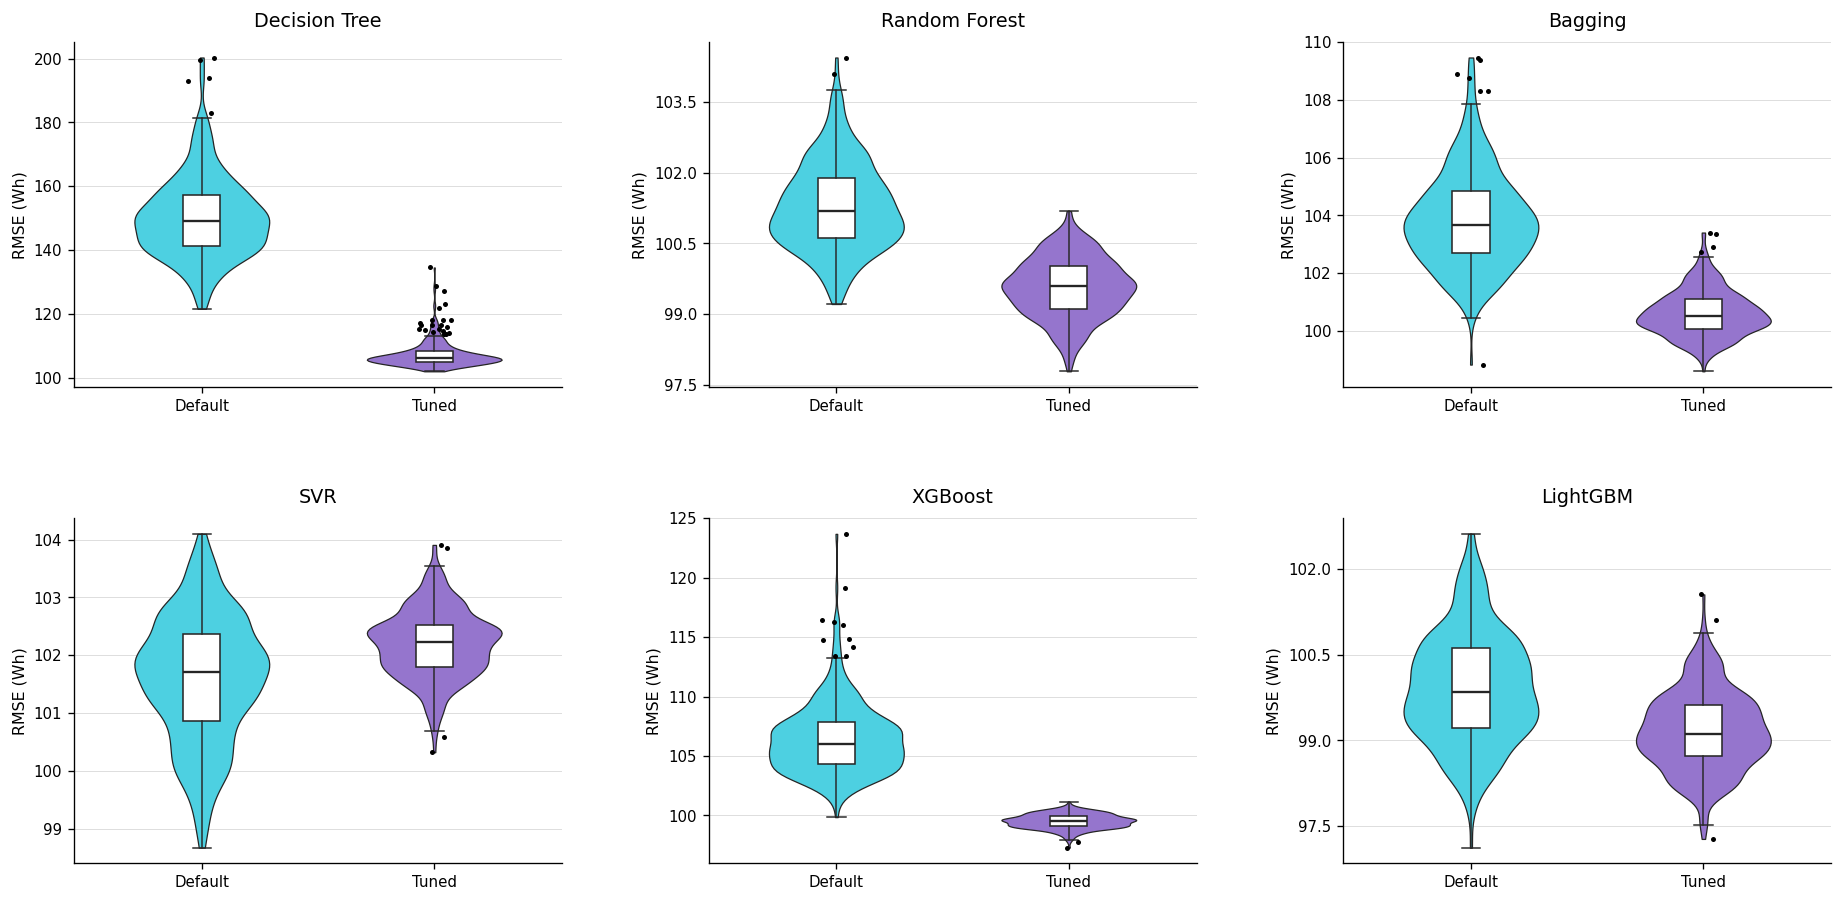

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig01_IID_RMSE_Default_vs_Tuned.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig01_IID_RMSE_Default_vs_Tuned.pdf

----------------------------------------------------------------------------
FIGURE 02 — Moving Block Bootstrap
----------------------------------------------------------------------------


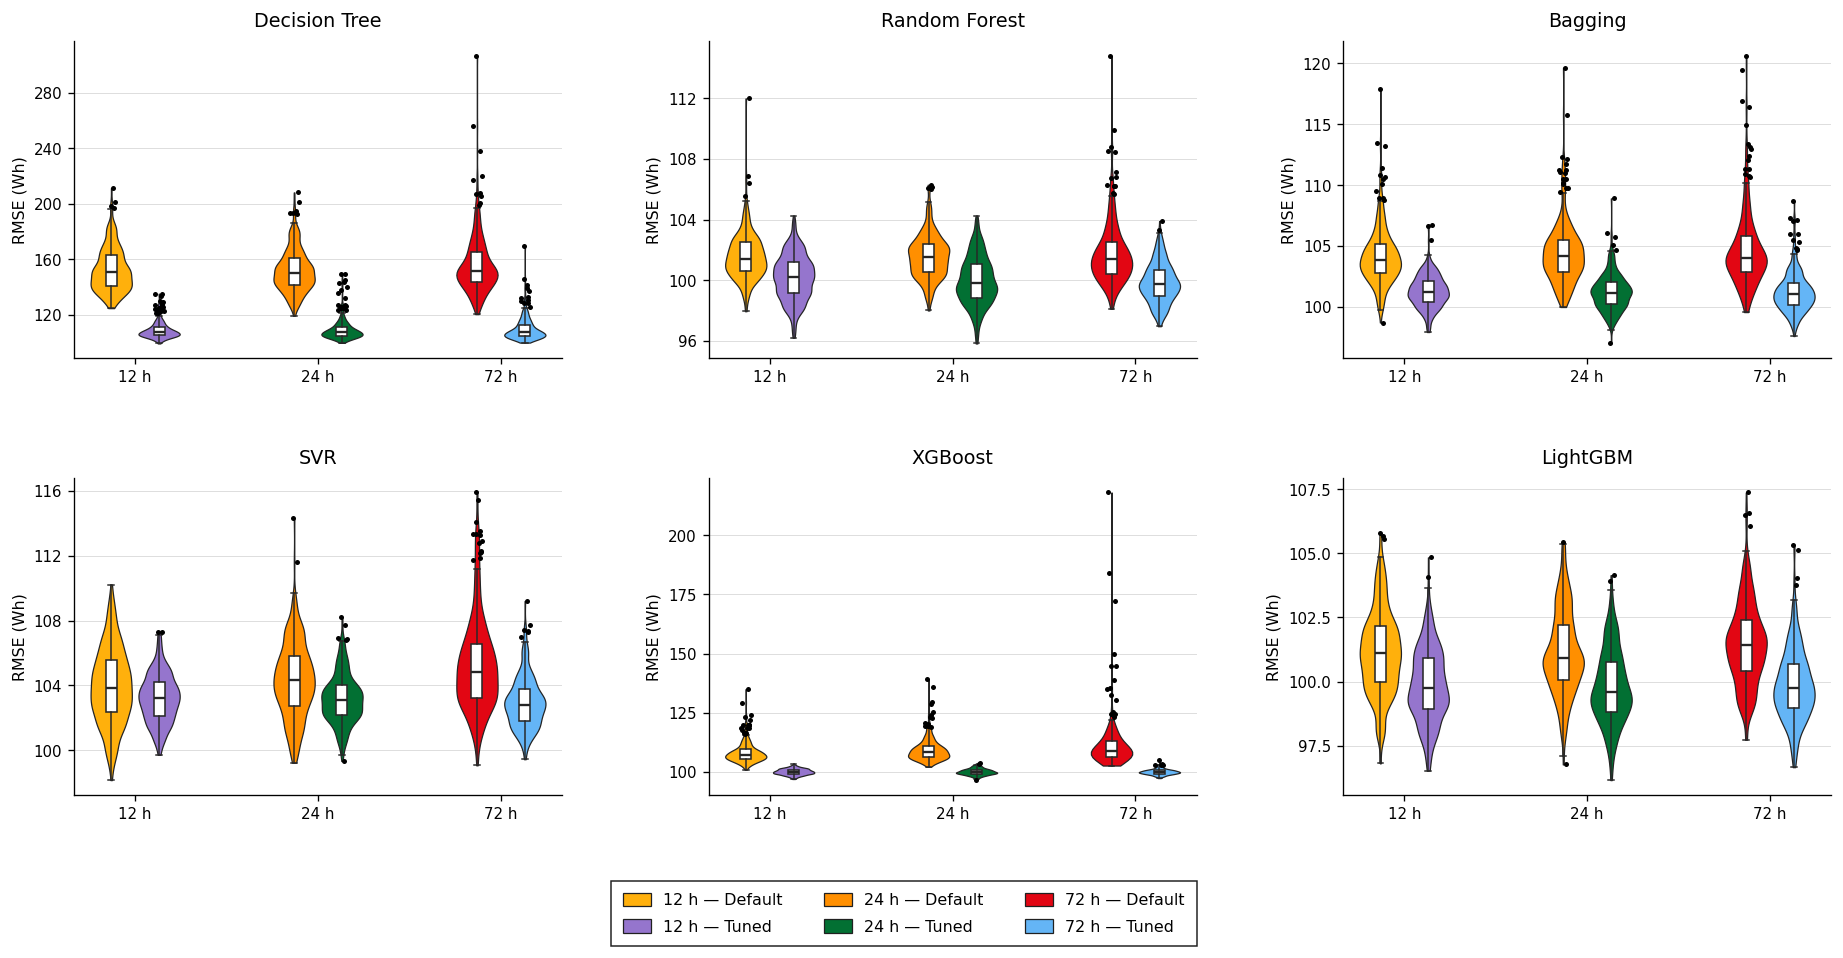

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig02_MBB_RMSE_Default_vs_Tuned.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig02_MBB_RMSE_Default_vs_Tuned.pdf

----------------------------------------------------------------------------
FIGURE 03 — Stationary Bootstrap
----------------------------------------------------------------------------


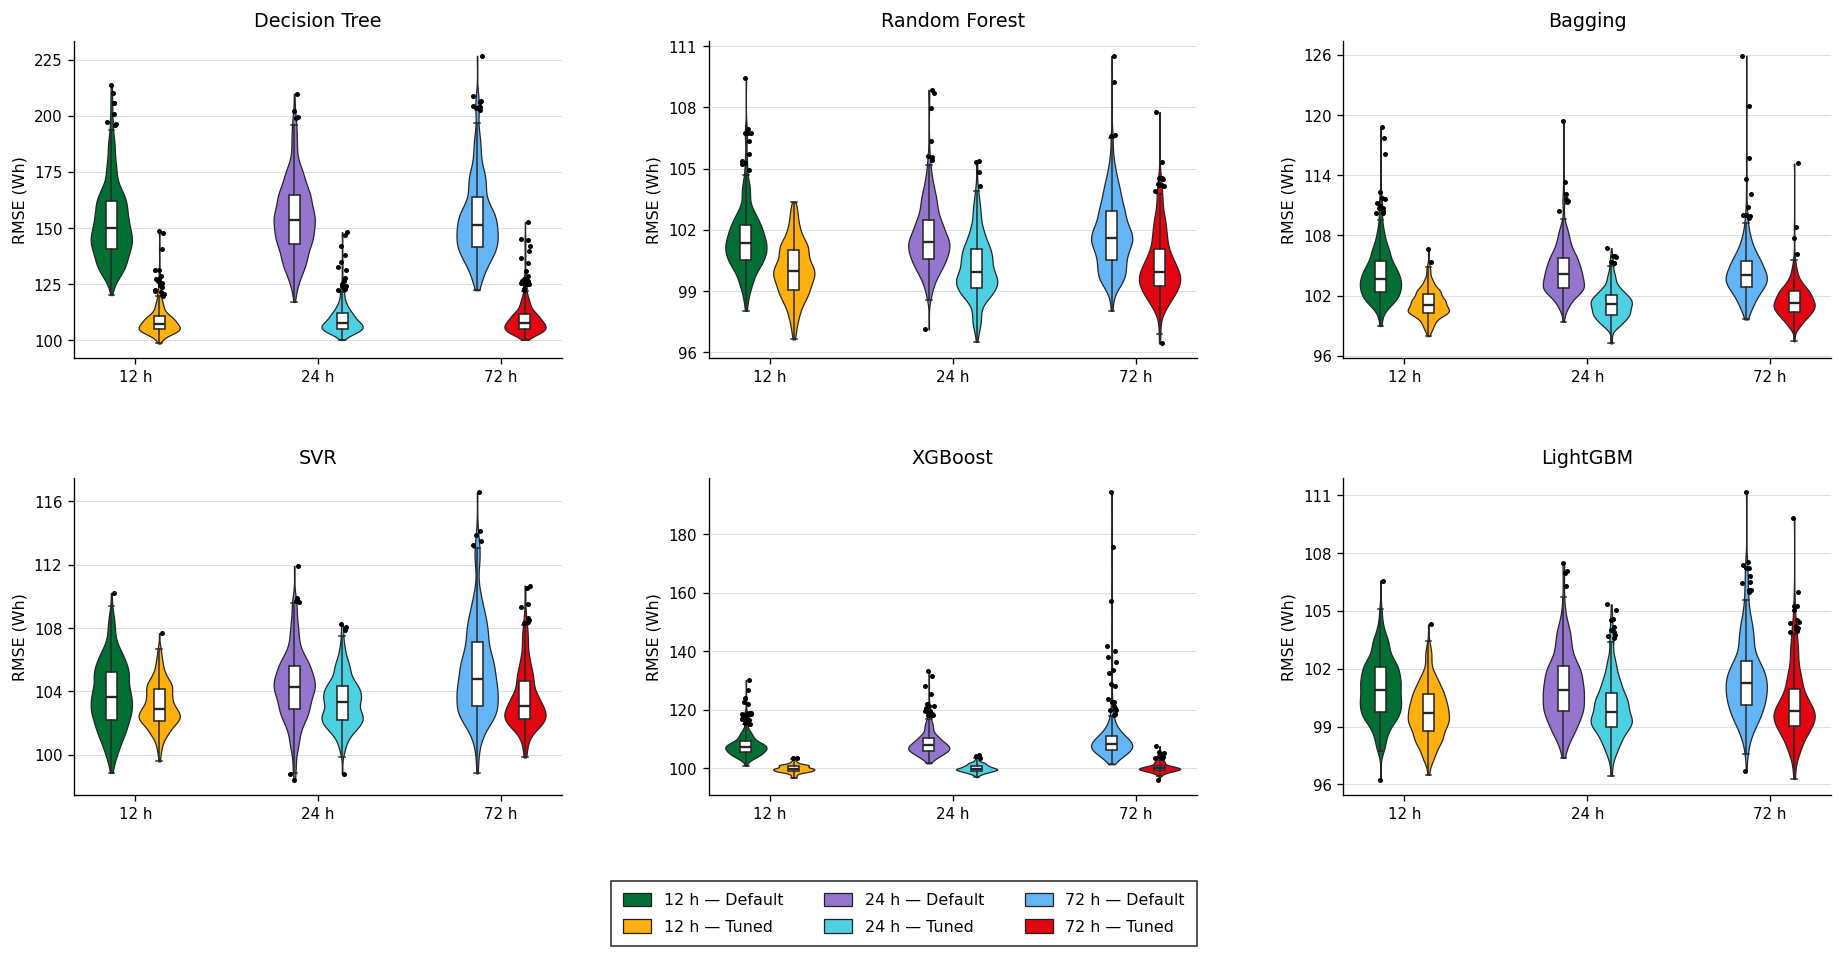

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig03_SB_RMSE_Default_vs_Tuned.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig03_SB_RMSE_Default_vs_Tuned.pdf

CELL 02 — VISUALIZATION COMPLETED
Source checksum verified       : PASS
Original RMSE distributions    : 84
Replications per distribution : 300
Figure count                  : 3
Approved palette              : PASS
Violin + boxplot              : PASS
Outlier scatter display       : PASS
Outliers removed              : NO
Model refitting               : NO
New bootstrap                 : NO
Test access                   : NO

OUTPUT DIRECTORY
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures

OUTLIER DISPLAY AUDIT
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/audit/NB04_Cell02_outlier_display_audit.csv

VISUALIZATION AUDIT
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/audit

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 02
# BOOTSTRAP RMSE DISTRIBUTION VISUALIZATION
# FINAL APPROVED DESIGN
#
# Figure 01 : IID Bootstrap
# Figure 02 : Moving Block Bootstrap
# Figure 03 : Stationary Bootstrap
#
# Violin + Boxplot + Outlier Points
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 01 Descriptive Performance
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required_objects02 = [
    "df_metrics",
    "df_stability_summary04",
    "bootstrap_manifest",
    "METRICS_PATH",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR",
    "CONDITIONS04",
    "ALGORITHMS04"
]

missing_objects02 = [
    name for name in required_objects02
    if name not in globals()
]

if missing_objects02:
    raise RuntimeError(
        "Run Notebook 04 Cells 00A, 00B and 01 first. "
        f"Missing objects: {missing_objects02}"
    )

FIGURE_DIR = Path(FIGURE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def ensure02(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha256_file02(path):
    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


# =============================================================================
# 2. VERIFY FROZEN NOTEBOOK 03 RESULTS
# =============================================================================

ensure02(
    bootstrap_manifest.get("status") == "PASS"
    and bootstrap_manifest.get("cumulative_B") == 300
    and bootstrap_manifest.get("total_fits") == 25200,
    "Notebook 03 completion manifest mismatch."
)

ensure02(
    sha256_file02(METRICS_PATH)
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "Notebook 03 source checksum mismatch."
)

ensure02(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84,
    "Unexpected analysis dimensions."
)

ensure02(
    df_metrics["status"].eq("PASS").all(),
    "Non-PASS experiment records detected."
)

ensure02(
    not df_metrics.duplicated(
        ["condition", "replication", "algorithm", "setting"]
    ).any(),
    "Duplicate experiment records."
)

ensure02(
    np.isfinite(
        df_metrics["rmse_wh"].to_numpy(dtype=float)
    ).all(),
    "Nonfinite RMSE values."
)

ensure02(
    df_metrics["rmse_wh"].ge(0).all(),
    "Negative RMSE values detected."
)


# =============================================================================
# 3. FROZEN EXPERIMENT ORDER
# =============================================================================

ALGORITHMS02 = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

SETTINGS02 = [
    "default",
    "tuned"
]

CONDITIONS02 = [
    "iid",
    "mbb_L0072",
    "mbb_L0144",
    "mbb_L0432",
    "stationary_L0072",
    "stationary_L0144",
    "stationary_L0432"
]

ensure02(
    list(CONDITIONS04) == CONDITIONS02
    and list(ALGORITHMS04) == ALGORITHMS02,
    "Frozen experiment order changed."
)


# =============================================================================
# 4. FINAL APPROVED COLOR PALETTE
#
# Tuple order:
# (Default, Tuned)
#
# Solid categorical colors only.
# =============================================================================

PALETTE02 = {

    # IID Bootstrap
    "iid": (
        "#4DD0E1",  # Turquoise
        "#9575CD"   # Purple
    ),

    # Moving Block Bootstrap
    "mbb_L0072": (
        "#FFB00C",  # Yellow
        "#9575CD"   # Purple
    ),

    "mbb_L0144": (
        "#FF8F00",  # Orange
        "#027033"   # Dark green
    ),

    "mbb_L0432": (
        "#E20613",  # Red
        "#64B5F6"   # Light blue
    ),

    # Stationary Bootstrap
    "stationary_L0072": (
        "#027033",  # Dark green
        "#FFB00C"   # Yellow
    ),

    "stationary_L0144": (
        "#9575CD",  # Purple
        "#4DD0E1"   # Turquoise
    ),

    "stationary_L0432": (
        "#64B5F6",  # Light blue
        "#E20613"   # Red
    )
}


# =============================================================================
# 5. FIGURE SPECIFICATIONS
# =============================================================================

FIGURE_SPECS02 = [
    {
        "number": 1,
        "method": "IID Bootstrap",
        "conditions": ["iid"],
        "filename": "NB04_Fig01_IID_RMSE_Default_vs_Tuned"
    },

    {
        "number": 2,
        "method": "Moving Block Bootstrap",
        "conditions": [
            "mbb_L0072",
            "mbb_L0144",
            "mbb_L0432"
        ],
        "filename": "NB04_Fig02_MBB_RMSE_Default_vs_Tuned"
    },

    {
        "number": 3,
        "method": "Stationary Bootstrap",
        "conditions": [
            "stationary_L0072",
            "stationary_L0144",
            "stationary_L0432"
        ],
        "filename": "NB04_Fig03_SB_RMSE_Default_vs_Tuned"
    }
]

BLOCK_LABELS02 = [
    "12 h",
    "24 h",
    "72 h"
]


# =============================================================================
# 6. PREPARE ORIGINAL RMSE DISTRIBUTIONS
# =============================================================================

RMSE_LOOKUP02 = {}

for (
    condition,
    algorithm,
    setting
), subset in df_metrics.groupby(
    ["condition", "algorithm", "setting"],
    sort=False
):

    subset = subset.sort_values("replication")

    ensure02(
        subset["replication"].tolist() == list(range(1, 301)),
        f"Incomplete replication sequence: "
        f"{condition}, {algorithm}, {setting}"
    )

    values = subset["rmse_wh"].to_numpy(dtype=np.float64)

    ensure02(
        values.shape == (300,)
        and np.isfinite(values).all(),
        f"Invalid distribution: "
        f"{condition}, {algorithm}, {setting}"
    )

    # Cross-check against Cell 01.
    reference = df_stability_summary04.loc[
        (df_stability_summary04["condition"] == condition)
        & (df_stability_summary04["algorithm"] == algorithm)
        & (df_stability_summary04["setting"] == setting)
    ]

    ensure02(
        len(reference) == 1,
        "Missing Cell 01 descriptive summary."
    )

    ensure02(
        np.isclose(
            values.mean(),
            reference.iloc[0]["rmse_wh_mean"],
            atol=1e-9,
            rtol=1e-10
        ),
        "Mean RMSE differs from Cell 01."
    )

    ensure02(
        np.isclose(
            values.std(ddof=1),
            reference.iloc[0]["rmse_wh_sd"],
            atol=1e-9,
            rtol=1e-10
        ),
        "RMSE SD differs from Cell 01."
    )

    RMSE_LOOKUP02[
        (condition, algorithm, setting)
    ] = values


expected_keys02 = {
    (condition, algorithm, setting)
    for condition in CONDITIONS02
    for algorithm in ALGORITHMS02
    for setting in SETTINGS02
}

ensure02(
    set(RMSE_LOOKUP02) == expected_keys02
    and len(RMSE_LOOKUP02) == 84,
    "Incomplete bootstrap distributions."
)


# =============================================================================
# 7. APPROVED PUBLICATION STYLE
# =============================================================================

STYLE02 = {

    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",

    "axes.titleweight": "normal",
    "axes.labelweight": "normal",

    "axes.labelcolor": "#000000",
    "text.color": "#000000",
    "xtick.color": "#000000",
    "ytick.color": "#000000",

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "figure.dpi": 120,
    "savefig.dpi": 300,

    "pdf.fonttype": 42,
    "ps.fonttype": 42
}


# =============================================================================
# 8. TUKEY OUTLIER DETECTION
#
# Lower fence = Q1 - 1.5 * IQR
# Upper fence = Q3 + 1.5 * IQR
#
# All observations remain in violin and boxplot calculations.
# =============================================================================

def detect_outliers02(values):

    values = np.asarray(values, dtype=np.float64)

    q1, q3 = np.quantile(
        values,
        [0.25, 0.75]
    )

    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    lower_mask = values < lower_fence
    upper_mask = values > upper_fence

    outlier_mask = lower_mask | upper_mask

    return {
        "outliers": values[outlier_mask],
        "lower_fence": float(lower_fence),
        "upper_fence": float(upper_fence),
        "n_lower": int(lower_mask.sum()),
        "n_upper": int(upper_mask.sum()),
        "n_outliers": int(outlier_mask.sum())
    }


# =============================================================================
# 9. VIOLIN + BOXPLOT + OUTLIER POINTS
# =============================================================================

def draw_distribution02(
    ax,
    values,
    position,
    color,
    is_iid
):

    # -------------------------------------------------------------------------
    # A. VIOLIN PLOT
    # -------------------------------------------------------------------------

    violin = ax.violinplot(
        [values],
        positions=[position],
        widths=0.58 if is_iid else 0.62,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        bw_method=0.25
    )

    for body in violin["bodies"]:

        body.set_facecolor(color)
        body.set_edgecolor("#242424")
        body.set_alpha(1.0)
        body.set_linewidth(0.75)

    # -------------------------------------------------------------------------
    # B. WHITE BOXPLOT OVERLAY
    # -------------------------------------------------------------------------

    ax.boxplot(
        [values],
        positions=[position],
        widths=0.16 if is_iid else 0.165,

        patch_artist=True,

        # Fliers are drawn separately below
        # to avoid duplicate markers.
        showfliers=False,

        manage_ticks=False,
        whis=1.5,

        boxprops={
            "facecolor": "white",
            "edgecolor": "#282828",
            "linewidth": 0.95
        },

        medianprops={
            "color": "#252525",
            "linewidth": 1.4
        },

        whiskerprops={
            "color": "#282828",
            "linewidth": 0.9
        },

        capprops={
            "color": "#282828",
            "linewidth": 0.9
        }
    )

    # -------------------------------------------------------------------------
    # C. ALL TUKEY OUTLIERS AS BLACK SCATTER POINTS
    # -------------------------------------------------------------------------

    info = detect_outliers02(values)

    outliers = info["outliers"]

    if outliers.size > 0:

        # Fixed seed for reproducible horizontal placement.
        # Jitter affects X position only, never RMSE values.

        rng = np.random.default_rng(42)

        jitter = rng.uniform(
            low=-0.075,
            high=0.075,
            size=len(outliers)
        )

        ax.scatter(
            position + jitter,
            outliers,

            s=9,
            color="#000000",
            linewidths=0,
            alpha=1.0,
            zorder=6
        )

    return info


# =============================================================================
# 10. PANEL AXIS STYLE
# =============================================================================

def style_axis02(
    ax,
    algorithm,
    is_iid,
    centers
):

    ax.set_title(
        algorithm,
        fontsize=11.5,
        pad=9,
        fontweight="normal",
        color="#000000"
    )

    ax.set_ylabel(
        "RMSE (Wh)",
        fontsize=9.5,
        fontweight="normal",
        color="#000000"
    )

    if is_iid:

        ax.set_xticks([1, 2])

        ax.set_xticklabels(
            ["Default", "Tuned"],
            fontsize=9.5
        )

        ax.set_xlim(0.45, 2.55)

    else:

        ax.set_xticks(centers)

        ax.set_xticklabels(
            BLOCK_LABELS02,
            fontsize=9.5
        )

        ax.set_xlim(
            centers[0] - 0.92,
            centers[-1] + 0.92
        )

    ax.grid(
        axis="y",
        color="#DEDEDE",
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=6)
    )


# =============================================================================
# 11. SINGLE BOXED LEGEND BELOW THE SECOND ROW
#
# IID: no legend because X-axis already identifies Default and Tuned.
#
# MBB and SB:
# 12 h Default | 24 h Default | 72 h Default
# 12 h Tuned   | 24 h Tuned   | 72 h Tuned
# =============================================================================

def add_legend02(fig, conditions):

    handles = []

    for condition, label in zip(
        conditions,
        BLOCK_LABELS02
    ):

        for j, setting in enumerate(
            ["Default", "Tuned"]
        ):

            handles.append(
                Patch(
                    facecolor=PALETTE02[condition][j],
                    edgecolor="#202020",
                    linewidth=0.75,
                    label=f"{label} — {setting}"
                )
            )

    legend = fig.legend(

        handles=handles,

        loc="lower center",
        bbox_to_anchor=(0.5, 0.022),

        ncol=3,

        frameon=True,
        fancybox=False,
        framealpha=1.0,

        facecolor="white",
        edgecolor="#202020",

        fontsize=9.5,
        borderpad=0.75,

        handlelength=1.75,
        handleheight=0.95,

        columnspacing=2.6,
        labelspacing=0.7
    )

    legend.get_frame().set_linewidth(0.9)


# =============================================================================
# 12. BUILD EACH BOOTSTRAP FIGURE
# =============================================================================

OUTLIER_RECORDS02 = []


def make_figure02(spec):

    conditions = spec["conditions"]

    is_iid = conditions == ["iid"]

    centers = (
        np.arange(len(conditions)) * 2.75 + 1.0
    )

    with plt.rc_context(STYLE02):

        fig, axes = plt.subplots(
            nrows=2,
            ncols=3,
            figsize=(15.9, 8.15),
            sharex=False,
            sharey=False
        )

        for ax, algorithm in zip(
            axes.flat,
            ALGORITHMS02
        ):

            for center, condition in zip(
                centers,
                conditions
            ):

                for j, setting in enumerate(
                    SETTINGS02
                ):

                    # IID:
                    # Default and Tuned are X-axis categories.
                    #
                    # MBB and SB:
                    # Two adjacent violins at every block length.

                    if is_iid:

                        position = float(j + 1)

                    else:

                        position = center + (
                            -0.36 if j == 0 else 0.36
                        )

                    values = RMSE_LOOKUP02[
                        (condition, algorithm, setting)
                    ]

                    color = PALETTE02[condition][j]

                    outlier_info = draw_distribution02(
                        ax=ax,
                        values=values,
                        position=position,
                        color=color,
                        is_iid=is_iid
                    )

                    # Record outlier counts for figure audit.
                    # This does not remove any observations.

                    OUTLIER_RECORDS02.append({
                        "figure": spec["number"],
                        "method": spec["method"],
                        "condition": condition,
                        "algorithm": algorithm,
                        "setting": setting,
                        "n_replications": len(values),

                        "lower_fence": outlier_info[
                            "lower_fence"
                        ],

                        "upper_fence": outlier_info[
                            "upper_fence"
                        ],

                        "n_lower_outliers": outlier_info[
                            "n_lower"
                        ],

                        "n_upper_outliers": outlier_info[
                            "n_upper"
                        ],

                        "n_outliers": outlier_info[
                            "n_outliers"
                        ]
                    })

            style_axis02(
                ax=ax,
                algorithm=algorithm,
                is_iid=is_iid,
                centers=centers
            )

        # ---------------------------------------------------------------------
        # LEGEND AND FIGURE SPACING
        # ---------------------------------------------------------------------

        if not is_iid:

            add_legend02(
                fig,
                conditions
            )

        fig.subplots_adjust(
            left=0.065,
            right=0.986,
            top=0.955,

            bottom=(
                0.115 if is_iid else 0.185
            ),

            wspace=0.30,
            hspace=0.38
        )

        # No suptitle.
        # No footer.
        # No internal figure annotations.

        # ---------------------------------------------------------------------
        # SAVE FIGURES
        # ---------------------------------------------------------------------

        output_stem = (
            FIGURE_DIR / spec["filename"]
        )

        png_path = output_stem.with_suffix(".png")
        pdf_path = output_stem.with_suffix(".pdf")

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.10,
            facecolor="white"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
            pad_inches=0.10,
            facecolor="white"
        )

        plt.show()
        plt.close(fig)

    return {

        "figure_number": spec["number"],
        "method": spec["method"],
        "conditions": conditions,

        "png": str(png_path),
        "pdf": str(pdf_path),

        "png_sha256": sha256_file02(png_path),
        "pdf_sha256": sha256_file02(pdf_path)
    }


# =============================================================================
# 13. GENERATE THE THREE FINAL FIGURES
# =============================================================================

print("=" * 76)
print("CELL 02 — BOOTSTRAP RMSE DISTRIBUTION VISUALIZATION")
print("=" * 76)

print("Source: Notebook 03 — B=300")
print("Total fitting records:", len(df_metrics))
print("Distribution groups:", len(RMSE_LOOKUP02))
print("Replications per group: 300")
print("Source fingerprint: VERIFIED")
print("Cell 01 mean and SD: VERIFIED")
print("Outlier rule: Tukey 1.5 x IQR")

FIGURE_OUTPUTS02 = []

for spec in FIGURE_SPECS02:

    print("\n" + "-" * 76)

    print(
        f"FIGURE {spec['number']:02d} — "
        f"{spec['method']}"
    )

    print("-" * 76)

    result = make_figure02(spec)

    FIGURE_OUTPUTS02.append(result)

    print("PNG:", result["png"])
    print("PDF:", result["pdf"])


# =============================================================================
# 14. VERIFY OUTLIER DISPLAY COVERAGE
# =============================================================================

df_outlier_audit02 = pd.DataFrame(
    OUTLIER_RECORDS02
)

ensure02(
    len(df_outlier_audit02) == 84,
    "Incomplete outlier visualization audit."
)

ensure02(
    not df_outlier_audit02.duplicated(
        ["condition", "algorithm", "setting"]
    ).any(),
    "Duplicate outlier audit records."
)

ensure02(
    df_outlier_audit02["n_replications"].eq(300).all(),
    "Incorrect distribution replication count."
)

ensure02(
    (
        df_outlier_audit02["n_lower_outliers"]
        + df_outlier_audit02["n_upper_outliers"]
    ).eq(
        df_outlier_audit02["n_outliers"]
    ).all(),
    "Outlier count mismatch."
)

ensure02(
    len(FIGURE_OUTPUTS02) == 3,
    "Expected exactly three figures."
)

OUTLIER_AUDIT_PATH02 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell02_outlier_display_audit.csv"
)

df_outlier_audit02.to_csv(
    OUTLIER_AUDIT_PATH02,
    index=False,
    float_format="%.12g"
)


# =============================================================================
# 15. SAVE FINAL VISUALIZATION AUDIT
# =============================================================================

VISUAL_AUDIT02 = {

    "notebook": "04",
    "cell": "02",

    "status": "PASS",

    "visualization_version": (
        "approved_violin_boxplot_outlier_final"
    ),

    "source": "Notebook 03 B300",

    "source_metrics_sha256": (
        sha256_file02(METRICS_PATH)
    ),

    "input_records": int(len(df_metrics)),

    "distribution_groups": int(
        len(RMSE_LOOKUP02)
    ),

    "replications_per_distribution": 300,

    "figure_count": len(FIGURE_OUTPUTS02),

    "design": {

        "layout": "2 rows x 3 columns",

        "plot_type": (
            "violin + boxplot + outlier scatter"
        ),

        "kde_bandwidth_factor": 0.25,

        "iid_x_axis": [
            "Default",
            "Tuned"
        ],

        "block_bootstrap_x_axis": BLOCK_LABELS02,

        "iid_legend": False,

        "block_bootstrap_legend": (
            "Single boxed legend below second row"
        ),

        "legend_layout": "3 columns x 2 rows",

        "colors": "Solid categorical colors",

        "gradient": False,

        "independent_y_axes": True,

        "figure_title": False,

        "figure_footer": False,

        "numeric_outlier_annotations": False
    },

    "outlier_definition": (
        "Outside Q1 - 1.5*IQR or Q3 + 1.5*IQR"
    ),

    "outlier_marker": "Black scatter points",

    "horizontal_jitter_seed": 42,

    "horizontal_jitter_range": [
        -0.075,
        0.075
    ],

    "total_outlier_observations_displayed": int(
        df_outlier_audit02["n_outliers"].sum()
    ),

    "outliers_removed": False,

    "outlier_audit_csv": str(
        OUTLIER_AUDIT_PATH02
    ),

    "outlier_audit_sha256": sha256_file02(
        OUTLIER_AUDIT_PATH02
    ),

    "palette": PALETTE02,

    "figures": FIGURE_OUTPUTS02,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "test_accessed": False
}

VISUAL_AUDIT_PATH02 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell02_approved_visualization_audit.json"
)

temporary02 = VISUAL_AUDIT_PATH02.with_name(
    VISUAL_AUDIT_PATH02.name + ".temporary"
)

with open(
    temporary02,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(
        VISUAL_AUDIT02,
        handle,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(
    temporary02,
    VISUAL_AUDIT_PATH02
)


# =============================================================================
# 16. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)
print("CELL 02 — VISUALIZATION COMPLETED")
print("=" * 76)

print("Source checksum verified       : PASS")
print("Original RMSE distributions    : 84")
print("Replications per distribution : 300")
print("Figure count                  : 3")
print("Approved palette              : PASS")
print("Violin + boxplot              : PASS")
print("Outlier scatter display       : PASS")
print("Outliers removed              : NO")
print("Model refitting               : NO")
print("New bootstrap                 : NO")
print("Test access                   : NO")

print("\nOUTPUT DIRECTORY")
print(FIGURE_DIR)

print("\nOUTLIER DISPLAY AUDIT")
print(OUTLIER_AUDIT_PATH02)

print("\nVISUALIZATION AUDIT")
print(VISUAL_AUDIT_PATH02)

print("\nFINAL STATUS: PASS")


# 03 — Bootstrap Sensitivity Analysis

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 03
# BOOTSTRAP METHOD AND BLOCK-LENGTH SENSITIVITY ANALYSIS
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 01 descriptive summaries
#
# Comparisons:
# 1. Block bootstrap vs IID
# 2. Stationary Bootstrap vs Moving Block Bootstrap
# 3. Block-length sensitivity within MBB and SB
#
# Primary metric   : RMSE (Wh)
# Supporting metric: MAE (Wh)
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required03 = [
    "df_metrics",
    "df_stability_summary04",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "AUDIT_OUTPUT_DIR",
    "CONDITIONS04",
    "ALGORITHMS04",
    "SETTINGS04"
]

missing03 = [
    name for name in required03
    if name not in globals()
]

if missing03:

    raise RuntimeError(
        "Run Notebook 04 Cells 00A, 00B and 01 first. "
        f"Missing objects: {missing03}"
    )


def ensure03(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file03(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


# =============================================================================
# 2. VERIFY EXISTING EXPERIMENT
# =============================================================================

ensure03(
    bootstrap_manifest.get("status") == "PASS"
    and bootstrap_manifest.get("cumulative_B") == 300
    and bootstrap_manifest.get("total_fits") == 25200
    and bootstrap_manifest.get("test_accessed") is False,
    "Notebook 03 manifest mismatch."
)

ensure03(
    sha256_file03(METRICS_PATH)
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "Notebook 03 metrics fingerprint mismatch."
)

ensure03(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84,
    "Unexpected experiment dimensions."
)

ensure03(
    not df_metrics.duplicated(
        ["condition", "replication", "algorithm", "setting"]
    ).any(),
    "Duplicate experiment keys."
)

ensure03(
    df_metrics["status"].eq("PASS").all(),
    "Non-PASS experiment records."
)

GROUP_KEYS03 = [
    "condition",
    "algorithm",
    "setting"
]

METRICS03 = [
    "rmse_wh",
    "mae_wh"
]

EXPECTED_GROUPS03 = {
    (condition, algorithm, setting)
    for condition in CONDITIONS04
    for algorithm in ALGORITHMS04
    for setting in SETTINGS04
}

observed_groups03 = set(
    df_metrics[GROUP_KEYS03]
    .itertuples(index=False, name=None)
)

ensure03(
    observed_groups03 == EXPECTED_GROUPS03,
    "Unexpected model-condition groups."
)

for group, subset in df_metrics.groupby(
    GROUP_KEYS03
):

    ensure03(
        sorted(subset["replication"].tolist())
        == list(range(1, 301)),
        f"Incomplete replication sequence: {group}"
    )

    ensure03(
        np.isfinite(
            subset[METRICS03].to_numpy(dtype=float)
        ).all()
        and subset[METRICS03].ge(0).all().all(),
        f"Invalid error metrics: {group}"
    )


# =============================================================================
# 3. VERIFY CELL 01 DESCRIPTIVE STATISTICS
# =============================================================================

ensure03(
    not df_stability_summary04.duplicated(
        GROUP_KEYS03
    ).any(),
    "Duplicate Cell 01 summary groups."
)

summary_lookup03 = (
    df_stability_summary04
    .set_index(GROUP_KEYS03)
)

ensure03(
    set(summary_lookup03.index.tolist())
    == EXPECTED_GROUPS03,
    "Cell 01 summary groups mismatch."
)

for group, subset in df_metrics.groupby(
    GROUP_KEYS03
):

    reference = summary_lookup03.loc[group]

    ensure03(
        int(reference["n_replications"]) == 300,
        "Incorrect Cell 01 replication count."
    )

    for metric in METRICS03:

        values = subset[metric].to_numpy(dtype=float)

        ensure03(
            np.isclose(
                values.mean(),
                reference[f"{metric}_mean"],
                atol=1e-9,
                rtol=1e-10
            ),
            f"Cell 01 mean mismatch: {group}, {metric}"
        )

        ensure03(
            np.isclose(
                values.std(ddof=1),
                reference[f"{metric}_sd"],
                atol=1e-9,
                rtol=1e-10
            ),
            f"Cell 01 SD mismatch: {group}, {metric}"
        )

# Ensure hyperparameters did not change across conditions.

candidate_audit03 = (
    df_metrics.groupby(
        ["algorithm", "setting"]
    )["candidate_id"]
    .nunique()
)

ensure03(
    len(candidate_audit03) == 12
    and candidate_audit03.eq(1).all(),
    "Model candidate changed across bootstrap conditions."
)


# =============================================================================
# 4. DEFINE FROZEN BOOTSTRAP CONDITIONS
# =============================================================================

CONDITION_LABELS03 = {
    "iid": "IID",

    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",

    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}

BLOCK_LENGTHS03 = [72, 144, 432]

BLOCK_LABELS03 = {
    72: "12 h",
    144: "24 h",
    432: "72 h"
}

COMPARISON_SPECS03 = []


# =============================================================================
# 5A. BLOCK BOOTSTRAP VS IID
#
# Six contrasts.
# IID is the resampling reference, not the unbootstrapped baseline.
# =============================================================================

for condition in CONDITIONS04:

    if condition == "iid":
        continue

    COMPARISON_SPECS03.append({

        "family": "block_vs_iid",

        "contrast": (
            f"{CONDITION_LABELS03[condition]} vs IID"
        ),

        "reference": "iid",
        "comparison": condition
    })


# =============================================================================
# 5B. STATIONARY BOOTSTRAP VS MBB
#
# Three matched nominal block lengths.
# =============================================================================

for length in BLOCK_LENGTHS03:

    COMPARISON_SPECS03.append({

        "family": "sb_vs_mbb",

        "contrast": (
            f"SB vs MBB — {BLOCK_LABELS03[length]}"
        ),

        "reference": (
            f"mbb_L{length:04d}"
        ),

        "comparison": (
            f"stationary_L{length:04d}"
        )
    })


# =============================================================================
# 5C. WITHIN-METHOD BLOCK-LENGTH SENSITIVITY
#
# 24 h vs 12 h
# 72 h vs 12 h
# 72 h vs 24 h
# =============================================================================

for method, label in [
    ("mbb", "MBB"),
    ("stationary", "SB")
]:

    for length_ref, length_cmp in [
        (72, 144),
        (72, 432),
        (144, 432)
    ]:

        COMPARISON_SPECS03.append({

            "family": "within_method_length",

            "contrast": (
                f"{label} "
                f"{BLOCK_LABELS03[length_cmp]} vs "
                f"{BLOCK_LABELS03[length_ref]}"
            ),

            "reference": (
                f"{method}_L{length_ref:04d}"
            ),

            "comparison": (
                f"{method}_L{length_cmp:04d}"
            )
        })

ensure03(
    len(COMPARISON_SPECS03) == 15,
    "Unexpected number of sensitivity contrasts."
)


# =============================================================================
# 6. CALCULATE SENSITIVITY MEASURES
#
# Positive mean difference:
# Higher error under the comparison condition.
#
# SD ratio > 1:
# Higher variability under the comparison condition.
#
# Comparisons across conditions are NOT paired by replication number.
# =============================================================================

sensitivity_records03 = []

for spec in COMPARISON_SPECS03:

    condition_ref = spec["reference"]
    condition_cmp = spec["comparison"]

    for algorithm in ALGORITHMS04:

        for setting in SETTINGS04:

            ref = summary_lookup03.loc[
                (condition_ref, algorithm, setting)
            ]

            cmp = summary_lookup03.loc[
                (condition_cmp, algorithm, setting)
            ]

            for metric in METRICS03:

                mean_ref = float(
                    ref[f"{metric}_mean"]
                )

                mean_cmp = float(
                    cmp[f"{metric}_mean"]
                )

                sd_ref = float(
                    ref[f"{metric}_sd"]
                )

                sd_cmp = float(
                    cmp[f"{metric}_sd"]
                )

                cv_ref = float(
                    ref[f"{metric}_cv_pct"]
                )

                cv_cmp = float(
                    cmp[f"{metric}_cv_pct"]
                )

                ensure03(
                    mean_ref > 0
                    and mean_cmp > 0
                    and sd_ref > 0,
                    "Invalid denominator in sensitivity ratio."
                )

                # Accuracy difference.
                delta_mean = mean_cmp - mean_ref

                delta_mean_pct = (
                    100 * delta_mean / mean_ref
                )

                # Dispersion difference.
                delta_sd = sd_cmp - sd_ref

                sd_ratio = sd_cmp / sd_ref

                delta_sd_pct = (
                    100 * (sd_ratio - 1)
                )

                # Relative dispersion difference.
                delta_cv_pp = cv_cmp - cv_ref

                sensitivity_records03.append({

                    "comparison_family": spec["family"],
                    "contrast": spec["contrast"],

                    "reference_condition": condition_ref,
                    "comparison_condition": condition_cmp,

                    "algorithm": algorithm,
                    "setting": setting,
                    "metric": metric,

                    "n_reference": 300,
                    "n_comparison": 300,

                    "mean_reference_wh": mean_ref,
                    "mean_comparison_wh": mean_cmp,

                    "delta_mean_wh": delta_mean,
                    "delta_mean_pct": delta_mean_pct,

                    "sd_reference_wh": sd_ref,
                    "sd_comparison_wh": sd_cmp,

                    "delta_sd_wh": delta_sd,
                    "sd_ratio": sd_ratio,
                    "delta_sd_pct": delta_sd_pct,

                    "cv_reference_pct": cv_ref,
                    "cv_comparison_pct": cv_cmp,
                    "delta_cv_percentage_points": (
                        delta_cv_pp
                    )
                })


df_sensitivity03 = pd.DataFrame(
    sensitivity_records03
)


# =============================================================================
# 7. AUDIT COMPLETE SENSITIVITY DESIGN
# =============================================================================

# 15 contrasts x 6 algorithms x 2 settings x 2 metrics

EXPECTED_ROWS03 = 360

ensure03(
    len(df_sensitivity03) == EXPECTED_ROWS03,
    "Incomplete sensitivity results."
)

ensure03(
    not df_sensitivity03.duplicated(
        [
            "comparison_family",
            "contrast",
            "algorithm",
            "setting",
            "metric"
        ]
    ).any(),
    "Duplicate sensitivity results."
)

numeric03 = df_sensitivity03.select_dtypes(
    include=[np.number]
)

ensure03(
    np.isfinite(
        numeric03.to_numpy(dtype=float)
    ).all(),
    "Nonfinite sensitivity results."
)

family_audit03 = (
    df_sensitivity03.groupby(
        ["comparison_family", "metric"]
    )
    .size()
    .unstack()
)

expected_family_counts03 = {
    "block_vs_iid": 72,
    "sb_vs_mbb": 36,
    "within_method_length": 72
}

for family, count in expected_family_counts03.items():

    ensure03(
        family_audit03.loc[family].eq(count).all(),
        f"Incomplete contrast family: {family}"
    )


# =============================================================================
# 8. BUILD READABLE COMPARISON MATRICES
# =============================================================================

ROW_ORDER03 = pd.MultiIndex.from_product(
    [
        ALGORITHMS04,
        SETTINGS04
    ],
    names=["algorithm", "setting"]
)


def contrast_matrix03(
    family,
    value_column,
    metric="rmse_wh",
    decimals=3
):

    subset = df_sensitivity03.loc[
        (df_sensitivity03["comparison_family"] == family)
        & (df_sensitivity03["metric"] == metric)
    ]

    contrast_order = [
        spec["contrast"]
        for spec in COMPARISON_SPECS03
        if spec["family"] == family
    ]

    result = subset.pivot(
        index=["algorithm", "setting"],
        columns="contrast",
        values=value_column
    )

    return result.reindex(
        index=ROW_ORDER03,
        columns=contrast_order
    ).round(decimals)


# =============================================================================
# 9. DISPLAY MAIN RMSE SENSITIVITY RESULTS
# =============================================================================

print("=" * 76)
print("CELL 03 — BOOTSTRAP SENSITIVITY ANALYSIS")
print("=" * 76)

print("\nA. SOURCE AND DESIGN AUDIT")

print("Source checksum: VERIFIED")
print("Cell 01 summaries: VERIFIED")
print("Fixed model candidates: VERIFIED")
print("Original fitting records:", len(df_metrics))
print("Sensitivity contrasts:", len(COMPARISON_SPECS03))
print("Total comparison records:", len(df_sensitivity03))
print("Replications per condition: 300")

display(family_audit03)


# -----------------------------------------------------------------------------
# 9A. BLOCK BOOTSTRAP VS IID
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("B. BLOCK BOOTSTRAP VS IID")
print("=" * 76)

print("\nB1. Mean RMSE difference (Wh)")
print("Positive = higher error than IID")

display(
    contrast_matrix03(
        family="block_vs_iid",
        value_column="delta_mean_wh"
    )
)

print("\nB2. RMSE SD ratio")
print("Ratio > 1 = higher variability than IID")

display(
    contrast_matrix03(
        family="block_vs_iid",
        value_column="sd_ratio"
    )
)


# -----------------------------------------------------------------------------
# 9B. STATIONARY BOOTSTRAP VS MBB
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("C. STATIONARY BOOTSTRAP VS MBB")
print("=" * 76)

print("\nC1. Mean RMSE difference (SB minus MBB)")

display(
    contrast_matrix03(
        family="sb_vs_mbb",
        value_column="delta_mean_wh"
    )
)

print("\nC2. RMSE SD ratio (SB / MBB)")

display(
    contrast_matrix03(
        family="sb_vs_mbb",
        value_column="sd_ratio"
    )
)


# -----------------------------------------------------------------------------
# 9C. BLOCK-LENGTH SENSITIVITY
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("D. WITHIN-METHOD BLOCK-LENGTH SENSITIVITY")
print("=" * 76)

print("\nD1. Mean RMSE difference (Wh)")

display(
    contrast_matrix03(
        family="within_method_length",
        value_column="delta_mean_wh"
    )
)

print("\nD2. RMSE SD ratio")

display(
    contrast_matrix03(
        family="within_method_length",
        value_column="sd_ratio"
    )
)


# =============================================================================
# 10. SUMMARIZE SENSITIVITY RANGE RELATIVE TO IID
# =============================================================================

block_vs_iid03 = df_sensitivity03.loc[
    df_sensitivity03["comparison_family"]
    == "block_vs_iid"
].copy()

df_sensitivity_range03 = (

    block_vs_iid03.groupby(
        [
            "algorithm",
            "setting",
            "metric"
        ],
        sort=False
    )

    .agg(

        min_mean_difference_wh=(
            "delta_mean_wh", "min"
        ),

        max_mean_difference_wh=(
            "delta_mean_wh", "max"
        ),

        min_sd_ratio=(
            "sd_ratio", "min"
        ),

        max_sd_ratio=(
            "sd_ratio", "max"
        ),

        min_sd_change_pct=(
            "delta_sd_pct", "min"
        ),

        max_sd_change_pct=(
            "delta_sd_pct", "max"
        ),

        conditions_higher_sd=(
            "sd_ratio",
            lambda x: int((x > 1).sum())
        ),

        conditions_higher_mean_error=(
            "delta_mean_wh",
            lambda x: int((x > 0).sum())
        ),

        n_conditions=(
            "sd_ratio", "size"
        )
    )

    .reset_index()
)

ensure03(
    len(df_sensitivity_range03) == 24
    and df_sensitivity_range03[
        "n_conditions"
    ].eq(6).all(),
    "Incomplete sensitivity range summary."
)

print("\n" + "=" * 76)
print("E. RMSE SENSITIVITY RANGE RELATIVE TO IID")
print("=" * 76)

display(
    df_sensitivity_range03.loc[
        df_sensitivity_range03["metric"] == "rmse_wh"
    ].drop(columns="metric").round(3)
)

print("\nF. MAE SENSITIVITY RANGE RELATIVE TO IID")

display(
    df_sensitivity_range03.loc[
        df_sensitivity_range03["metric"] == "mae_wh"
    ].drop(columns="metric").round(3)
)


# =============================================================================
# 11. SAVE SENSITIVITY TABLES
#
# Existing Notebook 04 output directories are retained.
# =============================================================================

TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

AUDIT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def save_csv03(data, path):

    temporary = path.with_name(
        path.name + ".temporary"
    )

    data.to_csv(
        temporary,
        index=False,
        float_format="%.12g"
    )

    os.replace(temporary, path)

    return {
        "path": str(path),
        "rows": int(len(data)),
        "sha256": sha256_file03(path)
    }


OUTPUT_FILES03 = {}

OUTPUT_FILES03["all_contrasts"] = save_csv03(
    df_sensitivity03,
    TABLE_DIR / "NB04_B300_bootstrap_sensitivity_all_contrasts.csv"
)

OUTPUT_FILES03["sensitivity_range"] = save_csv03(
    df_sensitivity_range03,
    TABLE_DIR / "NB04_B300_bootstrap_sensitivity_range.csv"
)

for family in expected_family_counts03:

    subset = df_sensitivity03.loc[
        df_sensitivity03["comparison_family"] == family
    ].copy()

    OUTPUT_FILES03[family] = save_csv03(
        subset,
        TABLE_DIR / f"NB04_B300_sensitivity_{family}.csv"
    )


# =============================================================================
# 12. SAVE REPRODUCIBILITY AUDIT
# =============================================================================

SENSITIVITY_AUDIT03 = {

    "notebook": "04",
    "cell": "03",

    "status": "PASS",

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 Cell 01"
    ),

    "source_metrics_sha256": (
        sha256_file03(METRICS_PATH)
    ),

    "input_records": int(len(df_metrics)),
    "replications_per_condition": 300,

    "algorithms": list(ALGORITHMS04),
    "settings": list(SETTINGS04),
    "conditions": list(CONDITIONS04),

    "metrics": METRICS03,

    "n_contrasts": len(COMPARISON_SPECS03),

    "contrast_definitions": COMPARISON_SPECS03,

    "comparison_records": int(
        len(df_sensitivity03)
    ),

    "sensitivity_range_records": int(
        len(df_sensitivity_range03)
    ),

    "definitions": {

        "delta_mean_wh": (
            "mean_comparison - mean_reference"
        ),

        "sd_ratio": (
            "sd_comparison / sd_reference"
        ),

        "delta_sd_pct": (
            "100 * (sd_ratio - 1)"
        ),

        "delta_cv_percentage_points": (
            "cv_comparison - cv_reference"
        )
    },

    "analysis_type": (
        "Descriptive sensitivity of empirical "
        "bootstrap performance distributions"
    ),

    "comparison_across_conditions_paired": False,

    "iid_reference_is_non_bootstrapped_baseline": False,

    "population_significance_test": False,

    "block_length_selected_from_results": False,

    "outliers_removed": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "test_accessed": False,

    "figures_generated": False,

    "outputs": OUTPUT_FILES03
}

AUDIT_PATH03 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell03_bootstrap_sensitivity_audit.json"
)

temporary03 = AUDIT_PATH03.with_name(
    AUDIT_PATH03.name + ".temporary"
)

with open(
    temporary03,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(
        SENSITIVITY_AUDIT03,
        handle,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(
    temporary03,
    AUDIT_PATH03
)


# =============================================================================
# 13. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)
print("CELL 03 — BOOTSTRAP SENSITIVITY COMPLETED")
print("=" * 76)

print("Notebook 03 source integrity : PASS")
print("Cell 01 summary consistency  : PASS")
print("Fixed model candidates       : PASS")

print("Sensitivity contrasts        : 15")
print("Comparison records           : 360")
print("Sensitivity range records    : 24")

print("RMSE sensitivity             : PASS")
print("MAE sensitivity              : PASS")

print("Outliers removed             : NO")
print("Model refitting              : NO")
print("New bootstrap                : NO")
print("Test accessed                : NO")
print("Figures generated            : NO")

print("\nSAVED TABLES")

for name, info in OUTPUT_FILES03.items():

    print(
        f"{name:<25}: {info['rows']} rows"
    )

    print(info["path"])

print("\nAUDIT")
print(AUDIT_PATH03)

print("\nFINAL STATUS: PASS")


CELL 03 — BOOTSTRAP SENSITIVITY ANALYSIS

A. SOURCE AND DESIGN AUDIT
Source checksum: VERIFIED
Cell 01 summaries: VERIFIED
Fixed model candidates: VERIFIED
Original fitting records: 25200
Sensitivity contrasts: 15
Total comparison records: 360
Replications per condition: 300


metric,mae_wh,rmse_wh
comparison_family,,
block_vs_iid,72,72
sb_vs_mbb,36,36
within_method_length,72,72



B. BLOCK BOOTSTRAP VS IID

B1. Mean RMSE difference (Wh)
Positive = higher error than IID


contrast               MBB 12 h vs IID  MBB 24 h vs IID  MBB 72 h vs IID  \
algorithm     setting                                                      
Decision Tree default            2.449            1.828            5.951   
              tuned              1.833            2.378            2.625   
Random Forest default            0.284            0.287            0.474   
              tuned              0.627            0.407            0.286   
Bagging       default            0.292            0.567            0.784   
              tuned              0.662            0.584            0.581   
SVR           default            2.354            2.740            3.671   
              tuned              1.024            0.977            0.746   
XGBoost       default            1.699            2.904            4.844   
              tuned              0.505            0.468            0.423   
LightGBM      default            1.231            1.239            1.553   
              tuned              0.701            0.639            0.701   

contrast               SB 12 h vs IID  SB 24 h vs IID  SB 72 h vs IID  
algorithm     setting                                                  
Decision Tree default           2.500           4.388           4.102  
              tuned             1.643           2.290           2.751  
Random Forest default           0.231           0.392           0.551  
              tuned             0.471           0.616           0.739  
Bagging       default           0.349           0.617           0.553  
              tuned             0.572           0.591           0.876  
SVR           default           2.150           2.726           3.726  
              tuned             0.918           1.160           1.376  
XGBoost       default           1.670           2.315           3.674  
              tuned             0.443           0.541           0.733  
LightGBM      default           1.058           1.155           1.562  
              tuned             0.581           0.812           0.969


B2. RMSE SD ratio
Ratio > 1 = higher variability than IID


contrast               MBB 12 h vs IID  MBB 24 h vs IID  MBB 72 h vs IID  \
algorithm     setting                                                      
Decision Tree default            1.217            1.180            1.635   
              tuned              1.470            1.900            2.003   
Random Forest default            1.642            1.550            2.167   
              tuned              2.371            2.516            2.088   
Bagging       default            1.412            1.510            1.821   
              tuned              1.675            1.855            2.028   
SVR           default            2.133            2.128            2.641   
              tuned              2.557            2.569            2.655   
XGBoost       default            1.429            1.616            3.477   
              tuned              2.061            2.132            1.883   
LightGBM      default            1.669            1.679            1.637   
              tuned              2.086            2.097            2.021   

contrast               SB 12 h vs IID  SB 24 h vs IID  SB 72 h vs IID  
algorithm     setting                                                  
Decision Tree default           1.317           1.275           1.386  
              tuned             1.665           1.686           1.877  
Random Forest default           1.694           1.722           1.900  
              tuned             2.158           2.426           2.548  
Bagging       default           1.637           1.426           1.641  
              tuned             1.760           1.947           2.191  
SVR           default           1.968           2.003           2.680  
              tuned             2.395           2.696           3.258  
XGBoost       default           1.356           1.504           2.876  
              tuned             2.078           2.170           2.472  
LightGBM      default           1.622           1.843           2.062  
              tuned             1.985           2.195           2.618

... (9 outputs left out)

,algorithm,setting,min_mean_difference_wh,max_mean_difference_wh,min_sd_ratio,max_sd_ratio,min_sd_change_pct,max_sd_change_pct,conditions_higher_sd,conditions_higher_mean_error,n_conditions
0,Decision Tree,default,1.828,5.951,1.180,1.635,17.991,63.486,6,6,6
2,Decision Tree,tuned,1.643,2.751,1.470,2.003,47.039,100.316,6,6,6
4,Random Forest,default,0.231,0.551,1.550,2.167,54.966,116.731,6,6,6
6,Random Forest,tuned,0.286,0.739,2.088,2.548,108.849,154.799,6,6,6
8,Bagging,default,0.292,0.784,1.412,1.821,41.246,82.084,6,6,6
10,Bagging,tuned,0.572,0.876,1.675,2.191,67.514,119.053,6,6,6
12,SVR,default,2.150,3.726,1.968,2.680,96.842,168.045,6,6,6
14,SVR,tuned,0.746,1.376,2.395,3.258,139.461,225.806,6,6,6
16,XGBoost,default,1.670,4.844,1.356,3.477,35.625,247.664,6,6,6
18,XGBoost,tuned,0.423,0.733,1.883,2.472,88.274,147.179,6,6,6



F. MAE SENSITIVITY RANGE RELATIVE TO IID


,algorithm,setting,min_mean_difference_wh,max_mean_difference_wh,min_sd_ratio,max_sd_ratio,min_sd_change_pct,max_sd_change_pct,conditions_higher_sd,conditions_higher_mean_error,n_conditions
1,Decision Tree,default,1.715,5.237,1.219,1.746,21.860,74.604,6,6,6
3,Decision Tree,tuned,1.375,2.701,1.861,2.384,86.072,138.441,6,6,6
5,Random Forest,default,0.135,1.296,2.051,3.014,105.107,201.367,6,6,6
7,Random Forest,tuned,0.186,0.670,2.407,2.945,140.712,194.522,6,6,6
9,Bagging,default,0.210,1.593,1.550,2.228,54.950,122.807,6,6,6
11,Bagging,tuned,0.255,1.033,2.164,2.887,116.416,188.703,6,6,6
13,SVR,default,0.174,1.350,1.586,1.882,58.622,88.224,6,6,6
15,SVR,tuned,0.417,0.923,1.897,3.421,89.668,242.095,6,6,6
17,XGBoost,default,1.166,4.676,1.305,2.625,30.455,162.497,6,6,6
19,XGBoost,tuned,0.421,1.368,2.026,3.556,102.619,255.597,6,6,6



CELL 03 — BOOTSTRAP SENSITIVITY COMPLETED
Notebook 03 source integrity : PASS
Cell 01 summary consistency  : PASS
Fixed model candidates       : PASS
Sensitivity contrasts        : 15
Comparison records           : 360
Sensitivity range records    : 24
RMSE sensitivity             : PASS
MAE sensitivity              : PASS
Outliers removed             : NO
Model refitting              : NO
New bootstrap                : NO
Test accessed                : NO
Figures generated            : NO

SAVED TABLES
all_contrasts            : 360 rows
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/tables/NB04_B300_bootstrap_sensitivity_all_contrasts.csv
sensitivity_range        : 24 rows
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/tables/NB04_B300_bootstrap_sensitivity_range.csv
block_vs_iid             : 144 rows
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/tables/NB04_B300_sensitivity_block_vs_iid.csv
sb_vs_mbb               

# 04 — Bootstrap Sensitivity Visualization

CELL 04 — BOOTSTRAP SENSITIVITY VISUALIZATION
Source: Notebook 04 — Cell 03
Original fitting records: 25200
Replications per condition: 300
Sensitivity records: 360
RMSE sensitivity records: 180
Source checksum: VERIFIED
Cell 03 artifact checksum: VERIFIED
Approved visualization design: VERIFIED

----------------------------------------------------------------------------
FIGURE 04 — RMSE SD RATIO RELATIVE TO IID
----------------------------------------------------------------------------


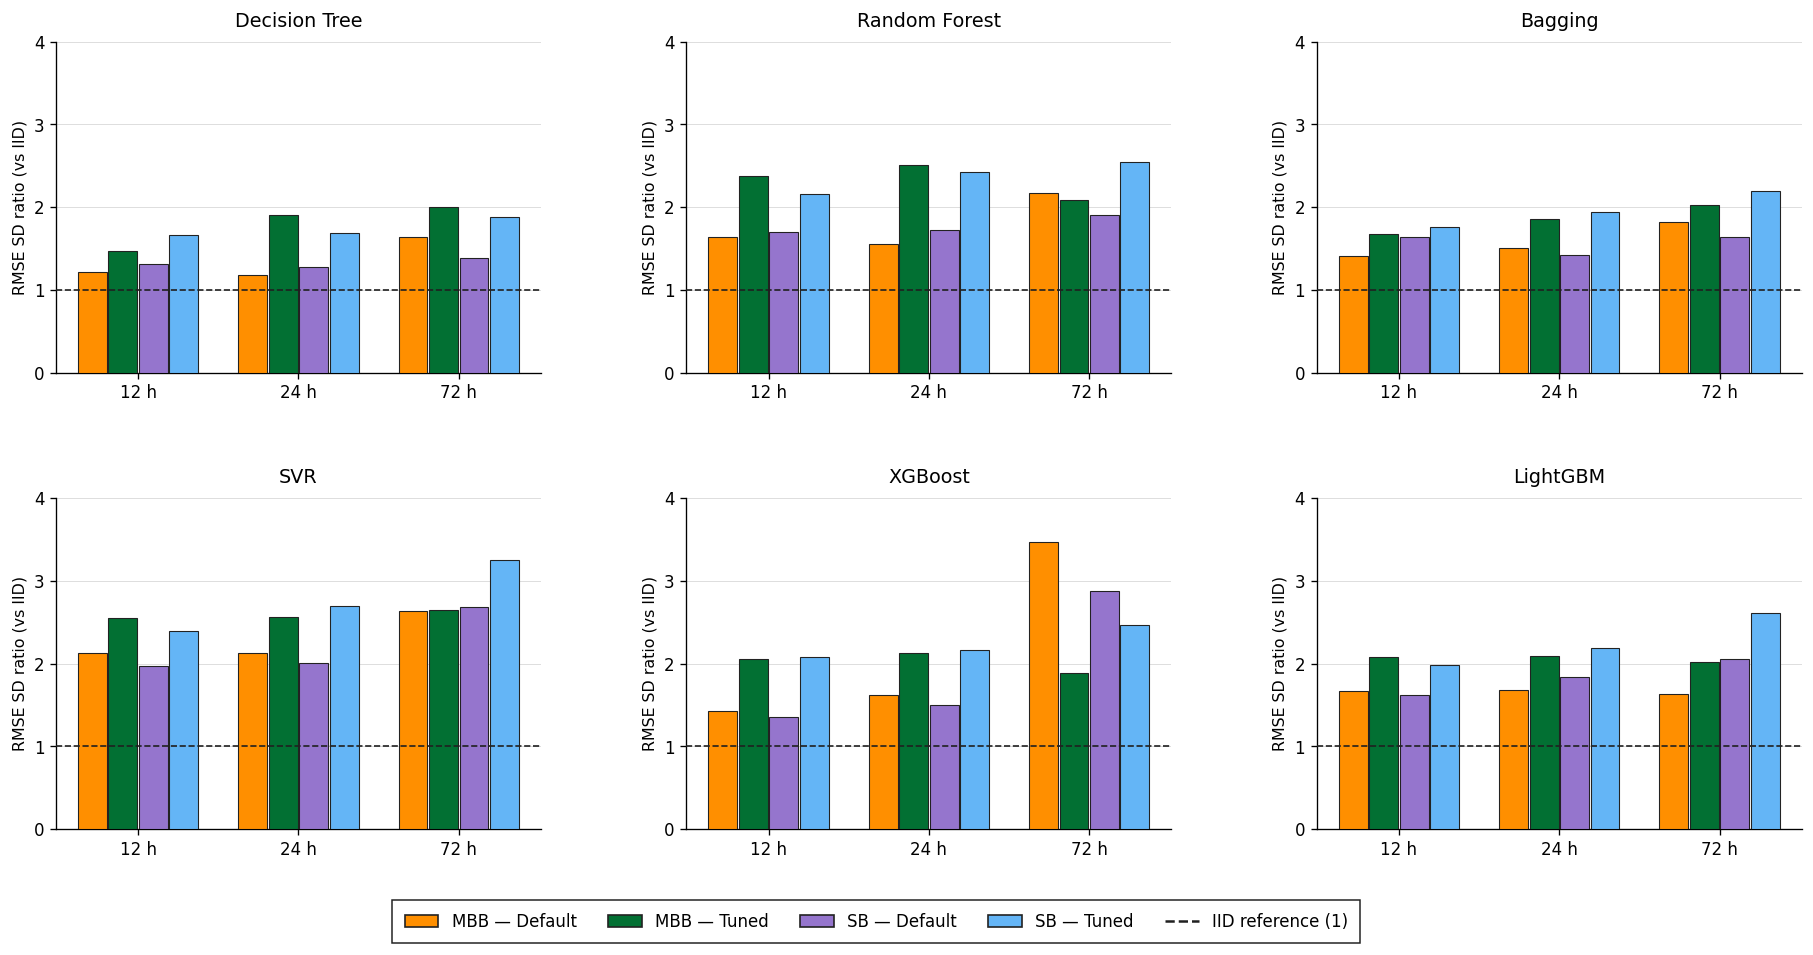

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig04_RMSE_SD_Ratio_Relative_to_IID.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig04_RMSE_SD_Ratio_Relative_to_IID.pdf

----------------------------------------------------------------------------
FIGURE 05 — MEAN RMSE DIFFERENCE — SB VS MBB
----------------------------------------------------------------------------


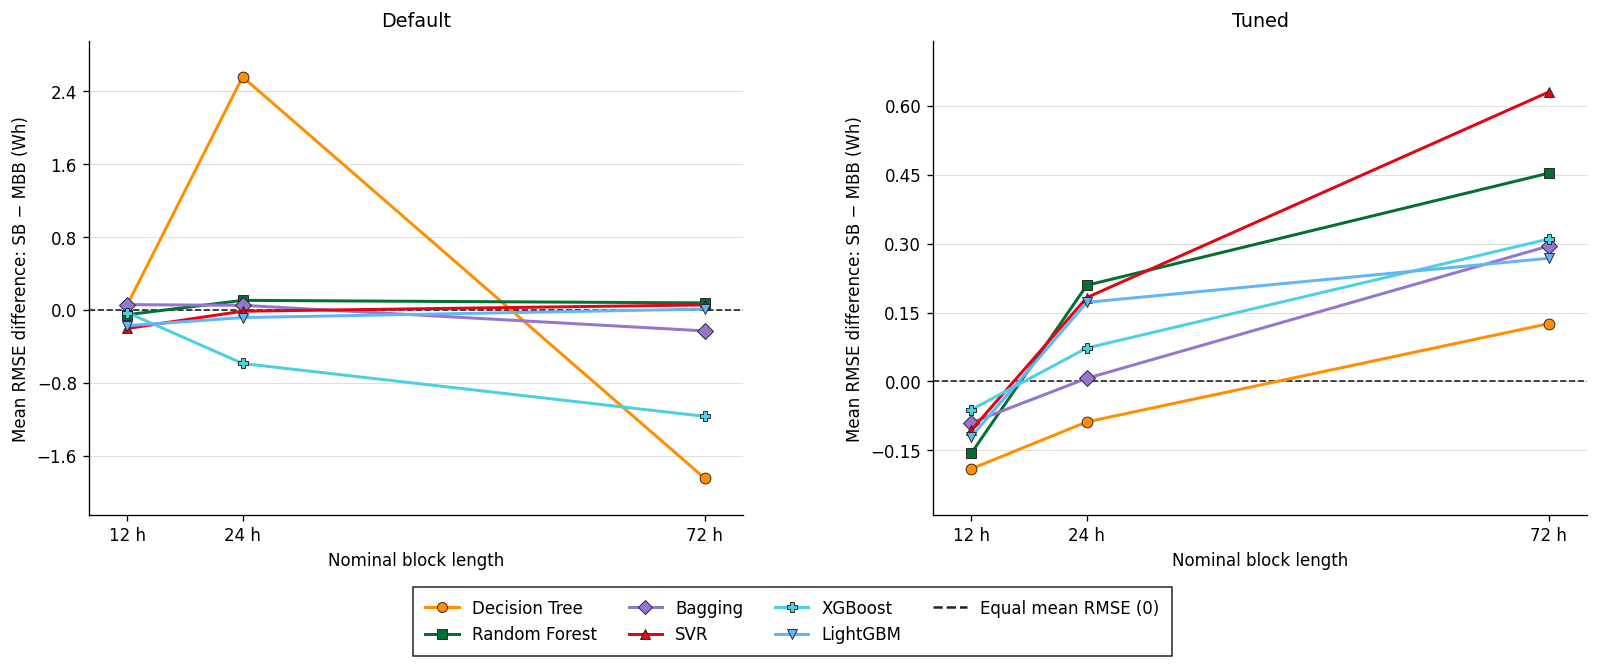

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig05_Mean_RMSE_Difference_SB_vs_MBB.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig05_Mean_RMSE_Difference_SB_vs_MBB.pdf

----------------------------------------------------------------------------
FIGURE 06 — RADAR — RMSE SD RATIO SB VS MBB
----------------------------------------------------------------------------


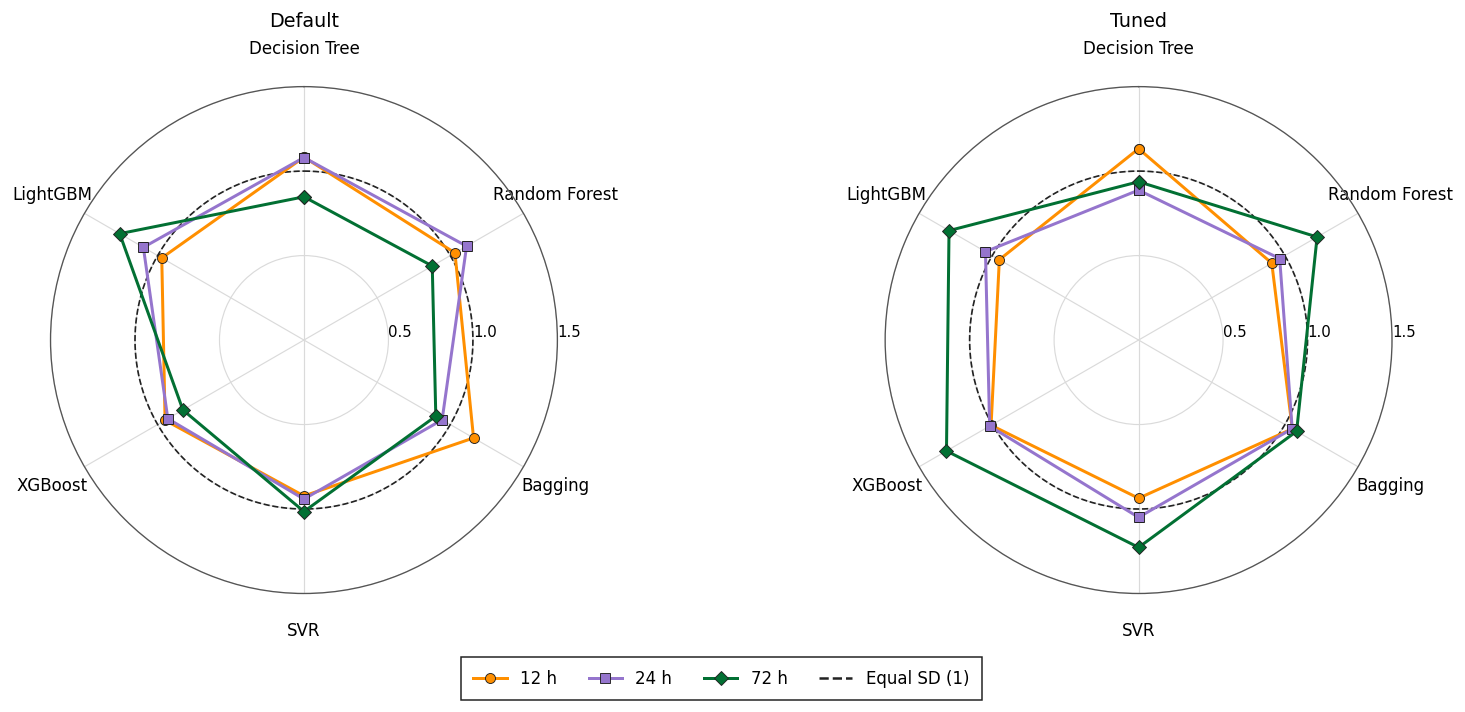

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig06_Radar_RMSE_SD_Ratio_SB_vs_MBB.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig06_Radar_RMSE_SD_Ratio_SB_vs_MBB.pdf

CELL 04 — SENSITIVITY VISUALIZATION COMPLETED
Notebook 03 source integrity    : PASS
Cell 03 artifact integrity      : PASS
In-memory results consistency   : PASS
Figure 04 — Grouped bar chart   : PASS
Figure 05 — Multi-series line   : PASS
Figure 06 — Radar plot          : PASS
Approved color palette          : PASS
Gradient colors                 : NO
Figure titles inside plot       : NO
Figure footnotes                : NO
Model refitting                 : NO
New bootstrap                   : NO
Hyperparameter retuning         : NO
Test accessed                   : NO

FIGURE OUTPUTS

Figure 04
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig04_RMSE_SD_Ratio_Relative_to_IID.png
PDF: /content

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 04
# BOOTSTRAP METHOD AND BLOCK-LENGTH SENSITIVITY VISUALIZATION
# FINAL APPROVED DESIGN
#
# Figure 04 : Grouped bar chart — SD ratio relative to IID
# Figure 05 : Line plot — Mean RMSE difference (SB - MBB)
# Figure 06 : Radar plot — SD ratio (SB / MBB)
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 03 Sensitivity Analysis
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required04 = [
    "df_sensitivity03",
    "df_stability_summary04",
    "df_metrics",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR",
    "ALGORITHMS04",
    "SETTINGS04",
    "CONDITIONS04"
]

missing04 = [
    name for name in required04
    if name not in globals()
]

if missing04:

    raise RuntimeError(
        "Run Notebook 04 Cells 00A–03 first. "
        f"Missing objects: {missing04}"
    )

FIGURE_DIR = Path(FIGURE_DIR)
TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def ensure04viz(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file04viz(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


# =============================================================================
# 2. VERIFY NOTEBOOK 03 AND CELL 03 ARTIFACTS
# =============================================================================

CELL03_AUDIT_PATH04 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell03_bootstrap_sensitivity_audit.json"
)

SENSITIVITY_PATH04 = (
    TABLE_DIR
    / "NB04_B300_bootstrap_sensitivity_all_contrasts.csv"
)

ensure04viz(
    CELL03_AUDIT_PATH04.is_file()
    and SENSITIVITY_PATH04.is_file(),
    "Cell 03 analysis artifacts are missing."
)

with open(
    CELL03_AUDIT_PATH04,
    "r",
    encoding="utf-8"
) as handle:

    cell03_audit04 = json.load(handle)


source_hash04 = sha256_file04viz(METRICS_PATH)

ensure04viz(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False,
    "Notebook 03 manifest mismatch."
)

ensure04viz(
    source_hash04
    == bootstrap_manifest["outputs"]["metrics_sha256"]
    == cell03_audit04["source_metrics_sha256"],
    "Source metrics checksum mismatch."
)

ensure04viz(
    cell03_audit04["status"] == "PASS"
    and cell03_audit04["comparison_records"] == 360
    and cell03_audit04["n_contrasts"] == 15,
    "Cell 03 sensitivity audit mismatch."
)

ensure04viz(
    sha256_file04viz(SENSITIVITY_PATH04)
    == cell03_audit04["outputs"]["all_contrasts"]["sha256"],
    "Cell 03 sensitivity CSV checksum mismatch."
)

ensure04viz(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84
    and len(df_sensitivity03) == 360,
    "Unexpected experiment dimensions."
)

# Confirm that the in-memory results remain consistent
# with the saved Cell 03 output.

saved_sensitivity04 = pd.read_csv(
    SENSITIVITY_PATH04
)

pd.testing.assert_frame_equal(
    df_sensitivity03.reset_index(drop=True),
    saved_sensitivity04.reset_index(drop=True),
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)


# =============================================================================
# 3. REUSE FROZEN EXPERIMENT DEFINITIONS
# =============================================================================

ALGO_ORDER04 = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

SETTING_ORDER04 = [
    "default",
    "tuned"
]

BLOCK_LENGTHS04 = [
    72,
    144,
    432
]

BLOCK_HOURS04 = [
    12,
    24,
    72
]

BLOCK_LABELS04 = [
    "12 h",
    "24 h",
    "72 h"
]

ensure04viz(
    list(ALGORITHMS04) == ALGO_ORDER04
    and list(SETTINGS04) == SETTING_ORDER04,
    "Frozen algorithm or setting order changed."
)


# =============================================================================
# 4. EXTRACT EXISTING RMSE SENSITIVITY RESULTS
#
# No recalculation from bootstrap replications.
# =============================================================================

df_rmse_sensitivity04 = (
    df_sensitivity03.loc[
        df_sensitivity03["metric"] == "rmse_wh"
    ]
    .copy()
)

df_block_vs_iid04 = (
    df_rmse_sensitivity04.loc[
        df_rmse_sensitivity04["comparison_family"]
        == "block_vs_iid"
    ]
    .copy()
)

df_sb_vs_mbb04 = (
    df_rmse_sensitivity04.loc[
        df_rmse_sensitivity04["comparison_family"]
        == "sb_vs_mbb"
    ]
    .copy()
)

ensure04viz(
    len(df_rmse_sensitivity04) == 180
    and len(df_block_vs_iid04) == 72
    and len(df_sb_vs_mbb04) == 36,
    "Incomplete RMSE sensitivity results."
)

LOOKUP_KEYS04 = [
    "algorithm",
    "setting",
    "reference_condition",
    "comparison_condition"
]

ensure04viz(
    not df_rmse_sensitivity04.duplicated(
        LOOKUP_KEYS04
    ).any(),
    "Duplicate RMSE contrast keys."
)

ensure04viz(
    np.isfinite(
        df_rmse_sensitivity04[
            ["delta_mean_wh", "sd_ratio"]
        ].to_numpy(dtype=float)
    ).all()
    and df_rmse_sensitivity04["sd_ratio"].gt(0).all(),
    "Invalid sensitivity statistics."
)

SENSITIVITY_LOOKUP04 = (
    df_rmse_sensitivity04
    .set_index(LOOKUP_KEYS04)
)


def get_contrast04(
    algorithm,
    setting,
    reference,
    comparison,
    statistic
):

    key = (
        algorithm,
        setting,
        reference,
        comparison
    )

    ensure04viz(
        key in SENSITIVITY_LOOKUP04.index,
        f"Missing sensitivity contrast: {key}"
    )

    return float(
        SENSITIVITY_LOOKUP04.loc[
            key,
            statistic
        ]
    )


# =============================================================================
# 5. FINAL APPROVED COLOR PALETTE
# =============================================================================

PALETTE04 = {
    "red": "#E20613",
    "yellow": "#FFB00C",
    "orange": "#FF8F00",
    "dark_green": "#027033",
    "turquoise": "#4DD0E1",
    "light_blue": "#64B5F6",
    "purple": "#9575CD"
}


# Figure 04 — Four model-resampling categories

BAR_STYLES04 = [
    (
        "mbb",
        "default",
        PALETTE04["orange"],
        "MBB — Default"
    ),
    (
        "mbb",
        "tuned",
        PALETTE04["dark_green"],
        "MBB — Tuned"
    ),
    (
        "stationary",
        "default",
        PALETTE04["purple"],
        "SB — Default"
    ),
    (
        "stationary",
        "tuned",
        PALETTE04["light_blue"],
        "SB — Tuned"
    )
]


# Figure 05 — Six algorithm colors and markers

LINE_STYLES04 = {

    "Decision Tree": (
        PALETTE04["orange"], "o"
    ),

    "Random Forest": (
        PALETTE04["dark_green"], "s"
    ),

    "Bagging": (
        PALETTE04["purple"], "D"
    ),

    "SVR": (
        PALETTE04["red"], "^"
    ),

    "XGBoost": (
        PALETTE04["turquoise"], "P"
    ),

    "LightGBM": (
        PALETTE04["light_blue"], "v"
    )
}


# Figure 06 — Three block-length colors and markers

RADAR_STYLES04 = {

    72: (
        PALETTE04["orange"], "o"
    ),

    144: (
        PALETTE04["purple"], "s"
    ),

    432: (
        PALETTE04["dark_green"], "D"
    )
}


# =============================================================================
# 6. PUBLICATION STYLE — APPROVED
# =============================================================================

STYLE04 = {

    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",

    "axes.titleweight": "normal",
    "axes.labelweight": "normal",

    "axes.labelcolor": "#000000",
    "text.color": "#000000",
    "xtick.color": "#000000",
    "ytick.color": "#000000",

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "figure.dpi": 120,
    "savefig.dpi": 300,

    "pdf.fonttype": 42,
    "ps.fonttype": 42
}


def clean_axis04(ax):

    ax.grid(
        axis="y",
        color="#DEDEDE",
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def boxed_legend04(
    fig,
    handles,
    ncol,
    y=0.025
):

    legend = fig.legend(

        handles=handles,
        ncol=ncol,

        loc="lower center",
        bbox_to_anchor=(0.5, y),

        frameon=True,
        fancybox=False,
        framealpha=1.0,

        facecolor="white",
        edgecolor="#202020",

        borderpad=0.75,
        columnspacing=1.9,

        fontsize=10
    )

    legend.get_frame().set_linewidth(0.9)

    return legend


# =============================================================================
# 7. FIGURE EXPORT HELPER
# =============================================================================

def export_figure04(
    fig,
    number,
    filename,
    statistic,
    contrast_family
):

    stem = FIGURE_DIR / filename

    png_path = stem.with_suffix(".png")
    pdf_path = stem.with_suffix(".pdf")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.10,
        facecolor="white"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.10,
        facecolor="white"
    )

    ensure04viz(
        png_path.is_file()
        and pdf_path.is_file()
        and png_path.stat().st_size > 0
        and pdf_path.stat().st_size > 0,
        f"Figure {number} export failed."
    )

    plt.show()
    plt.close(fig)

    return {

        "figure_number": number,

        "statistic": statistic,
        "contrast_family": contrast_family,

        "png": str(png_path),
        "pdf": str(pdf_path),

        "png_sha256": sha256_file04viz(png_path),
        "pdf_sha256": sha256_file04viz(pdf_path)
    }


# =============================================================================
# 8. FIGURE 04 — GROUPED BAR CHART
#
# SD ratio = SD(block bootstrap) / SD(IID)
#
# Reference line = 1
# Common Y-axis for all six algorithms.
# =============================================================================

def make_figure04():

    with plt.rc_context(STYLE04):

        fig, axes = plt.subplots(

            nrows=2,
            ncols=3,

            figsize=(15.9, 8.15),

            sharey=True
        )

        x = np.arange(3)

        plotted_values = []

        for ax, algorithm in zip(
            axes.flat,
            ALGO_ORDER04
        ):

            for j, (
                method,
                setting,
                color,
                label
            ) in enumerate(BAR_STYLES04):

                ratios = [

                    get_contrast04(
                        algorithm=algorithm,
                        setting=setting,

                        reference="iid",

                        comparison=(
                            f"{method}_L{length:04d}"
                        ),

                        statistic="sd_ratio"
                    )

                    for length in BLOCK_LENGTHS04
                ]

                plotted_values.extend(ratios)

                ax.bar(

                    x + (j - 1.5) * 0.19,

                    ratios,

                    width=0.18,

                    color=color,
                    edgecolor="#222222",
                    linewidth=0.65,

                    zorder=3
                )

            # IID reference.

            ax.axhline(
                y=1,
                color="#202020",
                linestyle="--",
                linewidth=1,
                zorder=4
            )

            ax.set_title(
                algorithm,
                fontsize=11.5,
                pad=9,
                fontweight="normal"
            )

            ax.set_xticks(x)
            ax.set_xticklabels(BLOCK_LABELS04)

            ax.set_ylabel(
                "RMSE SD ratio (vs IID)",
                fontsize=9.5
            )

            ax.set_ylim(0, 4)
            ax.set_yticks([0, 1, 2, 3, 4])

            ax.tick_params(labelleft=True)

            clean_axis04(ax)

        # Verify complete figure coverage and prevent clipping.

        ensure04viz(
            len(plotted_values) == 72
            and min(plotted_values) > 0
            and max(plotted_values) <= 4,
            "Figure 04 values exceed approved design limits."
        )

        handles = [

            Patch(
                facecolor=color,
                edgecolor="#222222",
                label=label
            )

            for method, setting, color, label
            in BAR_STYLES04
        ]

        handles.append(

            Line2D(
                [0], [0],

                color="#202020",
                linestyle="--",

                label="IID reference (1)"
            )
        )

        boxed_legend04(
            fig,
            handles,
            ncol=5
        )

        fig.subplots_adjust(

            left=0.07,
            right=0.985,

            top=0.955,
            bottom=0.15,

            wspace=0.30,
            hspace=0.38
        )

        return export_figure04(

            fig=fig,

            number=4,

            filename=(
                "NB04_Fig04_RMSE_SD_Ratio_Relative_to_IID"
            ),

            statistic="sd_ratio",

            contrast_family="block_vs_iid"
        )


# =============================================================================
# 9. FIGURE 05 — MULTI-SERIES LINE PLOT
#
# Delta mean RMSE = Mean RMSE(SB) - Mean RMSE(MBB)
#
# Negative value: SB has lower mean RMSE.
# Positive value: MBB has lower mean RMSE.
#
# Default and Tuned use independent Y-axis scales.
# X-axis uses actual nominal block hours.
# =============================================================================

def make_figure05():

    with plt.rc_context(STYLE04):

        fig, axes = plt.subplots(

            nrows=1,
            ncols=2,

            figsize=(13.8, 5.8),

            sharey=False
        )

        plotted_values = []

        for ax, setting in zip(
            axes,
            SETTING_ORDER04
        ):

            ax.axhline(

                y=0,

                color="#222222",
                linestyle="--",
                linewidth=1,

                zorder=1
            )

            panel_values = []

            for algorithm in ALGO_ORDER04:

                color, marker = (
                    LINE_STYLES04[algorithm]
                )

                differences = [

                    get_contrast04(

                        algorithm=algorithm,
                        setting=setting,

                        reference=(
                            f"mbb_L{length:04d}"
                        ),

                        comparison=(
                            f"stationary_L{length:04d}"
                        ),

                        statistic="delta_mean_wh"
                    )

                    for length in BLOCK_LENGTHS04
                ]

                panel_values.extend(differences)
                plotted_values.extend(differences)

                ax.plot(

                    BLOCK_HOURS04,
                    differences,

                    color=color,
                    marker=marker,
                    markersize=6.5,

                    markeredgecolor="#242424",
                    markeredgewidth=0.55,

                    linewidth=1.8,

                    zorder=3
                )

            ax.set_title(

                setting.capitalize(),

                fontsize=11.5,
                pad=9,

                fontweight="normal"
            )

            ax.set_xticks(
                BLOCK_HOURS04,
                BLOCK_LABELS04
            )

            ax.set_xlim(8, 76)

            ax.set_xlabel(
                "Nominal block length"
            )

            ax.set_ylabel(
                "Mean RMSE difference: SB − MBB (Wh)"
            )

            # Exact limits from approved preview.

            if setting == "default":

                limits = (-2.25, 2.95)

            else:

                limits = (-0.29, 0.74)

            ensure04viz(
                min(panel_values) >= limits[0]
                and max(panel_values) <= limits[1],
                f"Figure 05 {setting} values exceed axis limits."
            )

            ax.set_ylim(*limits)

            ax.yaxis.set_major_locator(
                MaxNLocator(nbins=7)
            )

            clean_axis04(ax)

        ensure04viz(
            len(plotted_values) == 36,
            "Incomplete Figure 05 contrasts."
        )

        handles = [

            Line2D(

                [0], [0],

                color=LINE_STYLES04[algorithm][0],
                marker=LINE_STYLES04[algorithm][1],

                markeredgecolor="#242424",
                markeredgewidth=0.55,

                linewidth=1.8,

                label=algorithm
            )

            for algorithm in ALGO_ORDER04
        ]

        handles.append(

            Line2D(
                [0], [0],

                color="#222222",
                linestyle="--",

                label="Equal mean RMSE (0)"
            )
        )

        boxed_legend04(

            fig,
            handles,

            ncol=4
        )

        fig.subplots_adjust(

            left=0.075,
            right=0.98,

            top=0.92,
            bottom=0.24,

            wspace=0.29
        )

        return export_figure04(

            fig=fig,

            number=5,

            filename=(
                "NB04_Fig05_Mean_RMSE_Difference_SB_vs_MBB"
            ),

            statistic="delta_mean_wh",

            contrast_family="sb_vs_mbb"
        )


# =============================================================================
# 10. FIGURE 06 — RADAR PLOT
#
# SD ratio = SD(SB) / SD(MBB)
#
# Radial reference = 1
# Inside reference: SB has lower RMSE dispersion.
# Outside reference: MBB has lower RMSE dispersion.
#
# Identical radial limits for Default and Tuned.
# No area filling and no gradient.
# =============================================================================

def make_figure06():

    with plt.rc_context(STYLE04):

        fig, axes = plt.subplots(

            nrows=1,
            ncols=2,

            figsize=(13.8, 6.6),

            subplot_kw={
                "projection": "polar"
            }
        )

        angles = np.linspace(

            0,
            2 * np.pi,

            len(ALGO_ORDER04),

            endpoint=False
        )

        angles_closed = np.r_[
            angles,
            angles[0]
        ]

        plotted_values = []

        for ax, setting in zip(
            axes,
            SETTING_ORDER04
        ):

            ax.set_theta_offset(np.pi / 2)
            ax.set_theta_direction(-1)

            ax.set_xticks(
                angles,
                ALGO_ORDER04,

                fontsize=10
            )

            ax.tick_params(
                axis="x",
                pad=12
            )

            ax.set_ylim(0, 1.5)

            ax.set_yticks(

                [0.5, 1.0, 1.5],

                ["0.5", "1.0", "1.5"],

                fontsize=9
            )

            ax.set_rlabel_position(90)

            ax.grid(
                color="#DADADA",
                linewidth=0.7
            )

            ax.spines["polar"].set_color(
                "#555555"
            )

            ax.spines["polar"].set_linewidth(
                0.8
            )

            # Reference circle at ratio = 1.

            ring_angles = np.linspace(
                0,
                2 * np.pi,
                361
            )

            ax.plot(

                ring_angles,
                np.ones_like(ring_angles),

                color="#222222",
                linestyle="--",
                linewidth=1.0,

                zorder=2
            )

            for length in BLOCK_LENGTHS04:

                color, marker = (
                    RADAR_STYLES04[length]
                )

                ratios = [

                    get_contrast04(

                        algorithm=algorithm,
                        setting=setting,

                        reference=(
                            f"mbb_L{length:04d}"
                        ),

                        comparison=(
                            f"stationary_L{length:04d}"
                        ),

                        statistic="sd_ratio"
                    )

                    for algorithm in ALGO_ORDER04
                ]

                plotted_values.extend(ratios)

                ratios_closed = np.r_[
                    ratios,
                    ratios[0]
                ]

                ax.plot(

                    angles_closed,
                    ratios_closed,

                    color=color,
                    marker=marker,

                    markeredgecolor="#222222",
                    markeredgewidth=0.55,

                    markersize=6,
                    linewidth=1.8,

                    zorder=4
                )

            ax.set_title(

                setting.capitalize(),

                fontsize=11.5,

                fontweight="normal",

                pad=36
            )

        ensure04viz(
            len(plotted_values) == 36
            and min(plotted_values) > 0
            and max(plotted_values) <= 1.5,
            "Figure 06 values exceed approved radial limits."
        )

        handles = [

            Line2D(

                [0], [0],

                color=RADAR_STYLES04[length][0],
                marker=RADAR_STYLES04[length][1],

                markeredgecolor="#222222",
                markeredgewidth=0.55,

                linewidth=1.8,

                label=label
            )

            for length, label in zip(
                BLOCK_LENGTHS04,
                BLOCK_LABELS04
            )
        ]

        handles.append(

            Line2D(

                [0], [0],

                color="#222222",
                linestyle="--",

                label="Equal SD (1)"
            )
        )

        boxed_legend04(

            fig,
            handles,

            ncol=4
        )

        fig.subplots_adjust(

            left=0.08,
            right=0.92,

            top=0.81,
            bottom=0.17,

            wspace=0.50
        )

        return export_figure04(

            fig=fig,

            number=6,

            filename=(
                "NB04_Fig06_Radar_RMSE_SD_Ratio_SB_vs_MBB"
            ),

            statistic="sd_ratio",

            contrast_family="sb_vs_mbb"
        )


# =============================================================================
# 11. GENERATE THREE APPROVED FIGURES
# =============================================================================

print("=" * 76)
print("CELL 04 — BOOTSTRAP SENSITIVITY VISUALIZATION")
print("=" * 76)

print("Source: Notebook 04 — Cell 03")
print("Original fitting records: 25200")
print("Replications per condition: 300")
print("Sensitivity records: 360")
print("RMSE sensitivity records: 180")
print("Source checksum: VERIFIED")
print("Cell 03 artifact checksum: VERIFIED")
print("Approved visualization design: VERIFIED")

FIGURE_OUTPUTS04 = []

figure_functions04 = [

    (
        4,
        "RMSE SD RATIO RELATIVE TO IID",
        make_figure04
    ),

    (
        5,
        "MEAN RMSE DIFFERENCE — SB VS MBB",
        make_figure05
    ),

    (
        6,
        "RADAR — RMSE SD RATIO SB VS MBB",
        make_figure06
    )
]

for number, description, function in figure_functions04:

    print("\n" + "-" * 76)

    print(
        f"FIGURE {number:02d} — {description}"
    )

    print("-" * 76)

    result = function()

    FIGURE_OUTPUTS04.append(result)

    print("PNG:", result["png"])
    print("PDF:", result["pdf"])


# =============================================================================
# 12. VERIFY FINAL FIGURE COVERAGE
# =============================================================================

ensure04viz(
    len(FIGURE_OUTPUTS04) == 3
    and {
        item["figure_number"]
        for item in FIGURE_OUTPUTS04
    } == {4, 5, 6},
    "Incomplete sensitivity visualization outputs."
)

for item in FIGURE_OUTPUTS04:

    ensure04viz(
        sha256_file04viz(Path(item["png"]))
        == item["png_sha256"],

        "PNG checksum verification failed."
    )

    ensure04viz(
        sha256_file04viz(Path(item["pdf"]))
        == item["pdf_sha256"],

        "PDF checksum verification failed."
    )


# =============================================================================
# 13. SAVE REPRODUCIBILITY AUDIT
# =============================================================================

VISUAL_AUDIT04 = {

    "notebook": "04",
    "cell": "04",

    "status": "PASS",

    "visualization_version": (
        "approved_bar_line_radar_v1"
    ),

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 Cell 03"
    ),

    "source_metrics_sha256": source_hash04,

    "source_sensitivity_sha256": (
        sha256_file04viz(SENSITIVITY_PATH04)
    ),

    "source_cell03_audit_sha256": (
        sha256_file04viz(CELL03_AUDIT_PATH04)
    ),

    "original_fitting_records": 25200,

    "replications_per_condition": 300,

    "sensitivity_records": 360,

    "rmse_sensitivity_records": 180,

    "figure_count": 3,

    "figure04": {

        "type": "grouped bar chart",

        "statistic": "sd_ratio",

        "reference": "IID",

        "plotted_contrasts": 72,

        "reference_line": 1,

        "common_y_axis": True,

        "y_limits": [0, 4]
    },

    "figure05": {

        "type": "multi-series line plot",

        "statistic": "delta_mean_wh",

        "contrast": "SB minus MBB",

        "plotted_contrasts": 36,

        "reference_line": 0,

        "independent_y_axes": True,

        "default_y_limits": [-2.25, 2.95],

        "tuned_y_limits": [-0.29, 0.74],

        "x_axis_hours": BLOCK_HOURS04,

        "interpolated_experiments": False
    },

    "figure06": {

        "type": "radar plot",

        "statistic": "sd_ratio",

        "contrast": "SB divided by MBB",

        "plotted_contrasts": 36,

        "reference_circle": 1,

        "common_radial_scale": True,

        "radial_limits": [0, 1.5],

        "polygon_area_used_as_metric": False,

        "polygon_fill": False
    },

    "palette": PALETTE04,

    "gradient": False,

    "figure_suptitles": False,

    "figure_footnotes": False,

    "legend_position": "below figure",

    "legend_boxed": True,

    "comparison_across_conditions_paired": False,

    "inferential_confidence_intervals": False,

    "analysis_type": "Descriptive sensitivity",

    "source_metrics_modified": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "test_accessed": False,

    "figures": FIGURE_OUTPUTS04
}

VISUAL_AUDIT_PATH04 = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell04_sensitivity_visualization_audit.json"
)

temporary04 = VISUAL_AUDIT_PATH04.with_name(
    VISUAL_AUDIT_PATH04.name + ".temporary"
)

with open(
    temporary04,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(

        VISUAL_AUDIT04,
        handle,

        indent=2,

        ensure_ascii=False,
        allow_nan=False
    )

os.replace(
    temporary04,
    VISUAL_AUDIT_PATH04
)


# =============================================================================
# 14. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)
print("CELL 04 — SENSITIVITY VISUALIZATION COMPLETED")
print("=" * 76)

print("Notebook 03 source integrity    : PASS")
print("Cell 03 artifact integrity      : PASS")
print("In-memory results consistency   : PASS")

print("Figure 04 — Grouped bar chart   : PASS")
print("Figure 05 — Multi-series line   : PASS")
print("Figure 06 — Radar plot          : PASS")

print("Approved color palette          : PASS")
print("Gradient colors                 : NO")
print("Figure titles inside plot       : NO")
print("Figure footnotes                : NO")

print("Model refitting                 : NO")
print("New bootstrap                   : NO")
print("Hyperparameter retuning         : NO")
print("Test accessed                   : NO")

print("\nFIGURE OUTPUTS")

for item in FIGURE_OUTPUTS04:

    print(
        f"\nFigure {item['figure_number']:02d}"
    )

    print("PNG:", item["png"])
    print("PDF:", item["pdf"])

print("\nAUDIT")
print(VISUAL_AUDIT_PATH04)

print("\nFINAL STATUS: PASS")


# 05: Paired Hyperparameter Tuning Analysis

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 05
# PAIRED HYPERPARAMETER TUNING ANALYSIS
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 01 Descriptive Performance
# Notebook 04 — Cell 03 Bootstrap Sensitivity Analysis
#
# Primary metric   : RMSE (Wh)
# Supporting metric: MAE (Wh)
#
# Default and Tuned compared using identical bootstrap indices.
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required05 = [
    "df_metrics",
    "df_stability_summary04",
    "df_sensitivity03",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "AUDIT_OUTPUT_DIR",
    "CONDITIONS04",
    "ALGORITHMS04",
    "SETTINGS04"
]

missing05 = [
    name for name in required05
    if name not in globals()
]

if missing05:
    raise RuntimeError(
        "Run Notebook 04 Cells 00A–03 first. "
        f"Missing objects: {missing05}"
    )


def ensure05(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file05(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. VERIFY FROZEN NOTEBOOK 03 RESULTS
# =============================================================================

source_hash05 = sha256_file05(METRICS_PATH)

ensure05(
    bootstrap_manifest.get("status") == "PASS"
    and bootstrap_manifest.get("cumulative_B") == 300
    and bootstrap_manifest.get("total_fits") == 25200
    and bootstrap_manifest.get("test_accessed") is False
    and bootstrap_manifest.get("hyperparameters_retuned") is False,
    "Notebook 03 manifest mismatch."
)

ensure05(
    source_hash05
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "Notebook 03 source checksum mismatch."
)

ensure05(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84
    and len(df_sensitivity03) == 360,
    "Previous analysis dimensions mismatch."
)

KEYS05 = [
    "condition",
    "algorithm",
    "replication"
]

METRICS05 = [
    "rmse_wh",
    "mae_wh"
]

REQUIRED_COLUMNS05 = [
    *KEYS05,
    "setting",
    "candidate_id",
    "index_sha256",
    "prediction_sha256",
    "status",
    *METRICS05
]

ensure05(
    set(REQUIRED_COLUMNS05).issubset(df_metrics.columns),
    "Required experiment columns missing."
)

ensure05(
    not df_metrics[REQUIRED_COLUMNS05].isna().any().any(),
    "Missing experiment values."
)

ensure05(
    not df_metrics.duplicated(
        KEYS05 + ["setting"]
    ).any(),
    "Duplicate experiment records."
)

ensure05(
    df_metrics["status"].eq("PASS").all(),
    "Non-PASS fitting records detected."
)

ensure05(
    np.isfinite(
        df_metrics[METRICS05].to_numpy(dtype=float)
    ).all()
    and df_metrics[METRICS05].ge(0).all().all(),
    "Invalid predictive error values."
)

# Confirm in-memory data match the frozen source CSV.

saved_metrics05 = pd.read_csv(
    METRICS_PATH,
    low_memory=False
)

pd.testing.assert_frame_equal(
    df_metrics[REQUIRED_COLUMNS05].reset_index(drop=True),
    saved_metrics05[REQUIRED_COLUMNS05].reset_index(drop=True),
    check_dtype=False,
    check_exact=True
)

del saved_metrics05


# =============================================================================
# 3. VERIFY FROZEN MODEL CANDIDATES
# =============================================================================

EXPECTED_CANDIDATES05 = {

    "Decision Tree":
        "decision_tree_s1_004_645f4153",

    "Random Forest":
        "random_forest_s1_003_8dec891b",

    "Bagging":
        "bagging_s1_003_1c7ab48f",

    "SVR":
        "svr_s1_008_57265079",

    "XGBoost":
        "xgboost_s2_003_022e7d5df1",

    "LightGBM":
        "lightgbm_s2_002_5e6f3e8cfc"
}

ensure05(
    set(df_metrics["algorithm"]) == set(ALGORITHMS04)
    and set(df_metrics["condition"]) == set(CONDITIONS04)
    and set(df_metrics["setting"]) == {"default", "tuned"},
    "Unexpected experiment factor levels."
)

ensure05(
    df_metrics.loc[
        df_metrics["setting"] == "default",
        "candidate_id"
    ].eq("default").all(),
    "Default model candidate mismatch."
)

tuned_candidate05 = df_metrics.loc[
    df_metrics["setting"] == "tuned"
].copy()

ensure05(
    tuned_candidate05["candidate_id"].eq(
        tuned_candidate05["algorithm"].map(
            EXPECTED_CANDIDATES05
        )
    ).all(),
    "Tuned model candidate differs from Notebook 02."
)


# =============================================================================
# 4. CONSTRUCT PAIRED DEFAULT–TUNED RESULTS
#
# Pairing key:
# condition + algorithm + replication
#
# Index fingerprint must be identical within every pair.
# =============================================================================

PAIR_COLUMNS05 = [
    *KEYS05,
    "candidate_id",
    "index_sha256",
    "prediction_sha256",
    *METRICS05
]

df_default05 = df_metrics.loc[
    df_metrics["setting"] == "default",
    PAIR_COLUMNS05
].copy()

df_tuned05 = df_metrics.loc[
    df_metrics["setting"] == "tuned",
    PAIR_COLUMNS05
].copy()

ensure05(
    len(df_default05) == 12600
    and len(df_tuned05) == 12600,
    "Unexpected Default or Tuned record count."
)

df_paired_tuning05 = df_default05.merge(

    df_tuned05,

    on=KEYS05,

    how="outer",

    suffixes=("_default", "_tuned"),

    validate="one_to_one",

    indicator=True
)

ensure05(
    len(df_paired_tuning05) == 12600
    and df_paired_tuning05["_merge"].eq("both").all(),
    "Incomplete Default–Tuned pairing."
)

ensure05(
    df_paired_tuning05["index_sha256_default"].eq(
        df_paired_tuning05["index_sha256_tuned"]
    ).all(),
    "Default and Tuned bootstrap indices differ."
)

df_paired_tuning05 = (
    df_paired_tuning05
    .drop(columns="_merge")
    .sort_values(KEYS05, kind="stable")
    .reset_index(drop=True)
)

# Verify the complete 42-group paired design.

expected_groups05 = {
    (condition, algorithm)
    for condition in CONDITIONS04
    for algorithm in ALGORITHMS04
}

observed_groups05 = set(
    df_paired_tuning05[
        ["condition", "algorithm"]
    ].itertuples(index=False, name=None)
)

ensure05(
    observed_groups05 == expected_groups05,
    "Paired experiment groups mismatch."
)

for group, subset in df_paired_tuning05.groupby(
    ["condition", "algorithm"]
):

    ensure05(
        sorted(subset["replication"].tolist())
        == list(range(1, 301)),
        f"Incomplete paired replication sequence: {group}"
    )


# =============================================================================
# 5. CALCULATE INDIVIDUAL PAIRED IMPROVEMENTS
#
# Positive improvement : Tuned has lower error.
# Negative improvement : Default has lower error.
#
# Tie tolerance is numerical only, not a practical equivalence margin.
# =============================================================================

TIE_ATOL05 = 1e-9

for metric in METRICS05:

    default_values = df_paired_tuning05[
        f"{metric}_default"
    ].to_numpy(dtype=float)

    tuned_values = df_paired_tuning05[
        f"{metric}_tuned"
    ].to_numpy(dtype=float)

    improvement = default_values - tuned_values

    df_paired_tuning05[
        f"{metric}_improvement"
    ] = improvement

    outcome = np.where(

        improvement > TIE_ATOL05,

        "Tuned wins",

        np.where(
            improvement < -TIE_ATOL05,
            "Default wins",
            "Tie"
        )
    )

    df_paired_tuning05[
        f"{metric}_outcome"
    ] = outcome


# =============================================================================
# 6. CROSS-CHECK WITH CELL 01
# =============================================================================

summary_lookup05 = (
    df_stability_summary04
    .set_index(
        ["condition", "algorithm", "setting"]
    )
)

ensure05(
    summary_lookup05.index.is_unique,
    "Duplicate Cell 01 summary keys."
)

for (
    condition,
    algorithm
), subset in df_paired_tuning05.groupby(
    ["condition", "algorithm"]
):

    for setting in ["default", "tuned"]:

        reference = summary_lookup05.loc[
            (condition, algorithm, setting)
        ]

        ensure05(
            int(reference["n_replications"]) == 300,
            "Cell 01 replication count mismatch."
        )

        for metric in METRICS05:

            values = subset[
                f"{metric}_{setting}"
            ].to_numpy(dtype=float)

            ensure05(
                np.isclose(
                    values.mean(),
                    reference[f"{metric}_mean"],
                    atol=1e-9,
                    rtol=1e-10
                ),
                "Paired mean differs from Cell 01."
            )

            ensure05(
                np.isclose(
                    values.std(ddof=1),
                    reference[f"{metric}_sd"],
                    atol=1e-9,
                    rtol=1e-10
                ),
                "Paired SD differs from Cell 01."
            )


# =============================================================================
# 7. SUMMARIZE PAIRED TUNING EFFECTS
#
# 7 conditions x 6 algorithms x 2 metrics = 84 summaries
# =============================================================================

tuning_records05 = []

for condition in CONDITIONS04:

    for algorithm in ALGORITHMS04:

        subset = df_paired_tuning05.loc[
            (df_paired_tuning05["condition"] == condition)
            & (df_paired_tuning05["algorithm"] == algorithm)
        ]

        ensure05(
            len(subset) == 300,
            "Incomplete paired tuning group."
        )

        for metric in METRICS05:

            default_values = subset[
                f"{metric}_default"
            ].to_numpy(dtype=float)

            tuned_values = subset[
                f"{metric}_tuned"
            ].to_numpy(dtype=float)

            delta = subset[
                f"{metric}_improvement"
            ].to_numpy(dtype=float)

            outcomes = subset[
                f"{metric}_outcome"
            ]

            n_pairs = len(delta)

            # -------------------------------------------------------------
            # A. PAIRED ACCURACY IMPROVEMENT
            # -------------------------------------------------------------

            mean_default = float(
                default_values.mean()
            )

            mean_tuned = float(
                tuned_values.mean()
            )

            mean_improvement = float(
                delta.mean()
            )

            median_improvement = float(
                np.median(delta)
            )

            ensure05(
                mean_default > 0,
                "Invalid mean improvement denominator."
            )

            mean_improvement_pct = (
                100 * mean_improvement / mean_default
            )

            # Empirical interval of paired improvements.
            # Not a confidence interval for population improvement.

            q025, q25, q75, q975 = np.quantile(
                delta,
                [0.025, 0.25, 0.75, 0.975]
            )

            # -------------------------------------------------------------
            # B. CONSISTENCY OF TUNING BENEFIT
            # -------------------------------------------------------------

            n_tuned_wins = int(
                outcomes.eq("Tuned wins").sum()
            )

            n_default_wins = int(
                outcomes.eq("Default wins").sum()
            )

            n_ties = int(
                outcomes.eq("Tie").sum()
            )

            ensure05(
                n_tuned_wins + n_default_wins + n_ties
                == n_pairs,
                "Pair outcome counts mismatch."
            )

            win_rate = (
                100 * n_tuned_wins / n_pairs
            )

            loss_rate = (
                100 * n_default_wins / n_pairs
            )

            tie_rate = (
                100 * n_ties / n_pairs
            )

            # -------------------------------------------------------------
            # C. STABILITY IMPROVEMENT
            # -------------------------------------------------------------

            sd_default = float(
                default_values.std(ddof=1)
            )

            sd_tuned = float(
                tuned_values.std(ddof=1)
            )

            ensure05(
                sd_default > 0,
                "Invalid SD ratio denominator."
            )

            sd_ratio = (
                sd_tuned / sd_default
            )

            stability_improvement_pct = (
                100 * (1 - sd_ratio)
            )

            # -------------------------------------------------------------
            # D. UPPER-TAIL IMPROVEMENT
            # -------------------------------------------------------------

            q95_default = float(
                np.quantile(default_values, 0.95)
            )

            q95_tuned = float(
                np.quantile(tuned_values, 0.95)
            )

            upper_tail_improvement = (
                q95_default - q95_tuned
            )

            # -------------------------------------------------------------
            # E. DESCRIPTIVE JOINT OUTCOME
            # -------------------------------------------------------------

            if mean_improvement > TIE_ATOL05:

                if sd_default - sd_tuned > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy and stability improved"
                    )

                elif sd_tuned - sd_default > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy improved, stability decreased"
                    )

                else:
                    joint_outcome = (
                        "Accuracy improved, stability unchanged"
                    )

            elif mean_improvement < -TIE_ATOL05:

                if sd_default - sd_tuned > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy decreased, stability improved"
                    )

                elif sd_tuned - sd_default > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy and stability decreased"
                    )

                else:
                    joint_outcome = (
                        "Accuracy decreased, stability unchanged"
                    )

            else:

                if sd_default - sd_tuned > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy unchanged, stability improved"
                    )

                elif sd_tuned - sd_default > TIE_ATOL05:
                    joint_outcome = (
                        "Accuracy unchanged, stability decreased"
                    )

                else:
                    joint_outcome = (
                        "Accuracy and stability unchanged"
                    )

            tuning_records05.append({

                "condition": condition,
                "algorithm": algorithm,
                "metric": metric,

                "n_pairs": n_pairs,

                "mean_default_wh": mean_default,
                "mean_tuned_wh": mean_tuned,

                "mean_improvement_wh": mean_improvement,
                "median_improvement_wh": median_improvement,

                "mean_improvement_pct": (
                    mean_improvement_pct
                ),

                "improvement_sd_wh": float(
                    delta.std(ddof=1)
                ),

                "improvement_q025_wh": float(q025),
                "improvement_q25_wh": float(q25),
                "improvement_q75_wh": float(q75),
                "improvement_q975_wh": float(q975),

                "n_tuned_wins": n_tuned_wins,
                "n_default_wins": n_default_wins,
                "n_ties": n_ties,

                "win_rate_pct": win_rate,
                "loss_rate_pct": loss_rate,
                "tie_rate_pct": tie_rate,

                "sd_default_wh": sd_default,
                "sd_tuned_wh": sd_tuned,

                "sd_ratio_tuned_default": sd_ratio,

                "stability_improvement_pct": (
                    stability_improvement_pct
                ),

                "q95_default_wh": q95_default,
                "q95_tuned_wh": q95_tuned,

                "upper_tail_improvement_wh": (
                    upper_tail_improvement
                ),

                "joint_outcome": joint_outcome
            })


df_tuning_summary05 = pd.DataFrame(
    tuning_records05
)


# =============================================================================
# 8. VERIFY PAIRED SUMMARY COMPLETENESS
# =============================================================================

ensure05(
    len(df_tuning_summary05) == 84
    and df_tuning_summary05["n_pairs"].eq(300).all(),
    "Incomplete paired tuning summaries."
)

ensure05(
    not df_tuning_summary05.duplicated(
        ["condition", "algorithm", "metric"]
    ).any(),
    "Duplicate tuning summary groups."
)

ensure05(
    np.isfinite(
        df_tuning_summary05
        .select_dtypes(include=[np.number])
        .to_numpy(dtype=float)
    ).all(),
    "Nonfinite tuning summary values."
)

ensure05(
    np.allclose(
        df_tuning_summary05[
            [
                "win_rate_pct",
                "loss_rate_pct",
                "tie_rate_pct"
            ]
        ].sum(axis=1),
        100,
        atol=1e-10
    ),
    "Outcome percentages do not sum to 100."
)

ensure05(
    np.allclose(
        df_tuning_summary05["mean_default_wh"]
        - df_tuning_summary05["mean_tuned_wh"],
        df_tuning_summary05["mean_improvement_wh"],
        atol=1e-9,
        rtol=1e-10
    ),
    "Paired mean improvement identity failed."
)


# =============================================================================
# 9. BUILD COMPARISON MATRICES
# =============================================================================

CONDITION_LABELS05 = {

    "iid": "IID",

    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",

    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}


def tuning_matrix05(
    statistic,
    metric="rmse_wh",
    decimals=3
):

    subset = df_tuning_summary05.loc[
        df_tuning_summary05["metric"] == metric
    ]

    matrix = subset.pivot(

        index="algorithm",
        columns="condition",
        values=statistic
    )

    matrix = matrix.reindex(

        index=ALGORITHMS04,
        columns=CONDITIONS04
    )

    matrix = matrix.rename(
        columns=CONDITION_LABELS05
    )

    if decimals is None:
        return matrix

    return matrix.round(decimals)


# =============================================================================
# 10. DISPLAY PRIMARY RMSE RESULTS
# =============================================================================

print("=" * 76)
print("CELL 05 — PAIRED HYPERPARAMETER TUNING ANALYSIS")
print("=" * 76)

print("\nA. EXPERIMENT AND PAIRING AUDIT")

print("Source checksum               : VERIFIED")
print("In-memory source consistency  : VERIFIED")
print("Frozen candidate identities   : VERIFIED")
print("Original fitting records      : 25200")
print("Default–Tuned pairs           : 12600")
print("Identical bootstrap indices   : 12600 / 12600")
print("Condition–algorithm groups    : 42")
print("Pairs per group               : 300")
print("Metrics analyzed              : RMSE, MAE")


print("\n" + "=" * 76)
print("B. PAIRED MEAN RMSE IMPROVEMENT (Wh)")
print("Positive = Tuned has lower RMSE")
print("=" * 76)

display(
    tuning_matrix05(
        "mean_improvement_wh"
    )
)


print("\n" + "=" * 76)
print("C. RELATIVE MEAN RMSE IMPROVEMENT (%)")
print("=" * 76)

display(
    tuning_matrix05(
        "mean_improvement_pct",
        decimals=2
    )
)


print("\n" + "=" * 76)
print("D. TUNING WIN RATE — RMSE (%)")
print("=" * 76)

display(
    tuning_matrix05(
        "win_rate_pct",
        decimals=2
    )
)


print("\n" + "=" * 76)
print("E. RMSE STABILITY IMPROVEMENT (%)")
print("Positive = Tuned has lower SD")
print("=" * 76)

display(
    tuning_matrix05(
        "stability_improvement_pct",
        decimals=2
    )
)


print("\n" + "=" * 76)
print("F. UPPER-TAIL RMSE IMPROVEMENT — Q95 (Wh)")
print("Positive = Tuned has lower upper-tail error")
print("=" * 76)

display(
    tuning_matrix05(
        "upper_tail_improvement_wh"
    )
)


# =============================================================================
# 11. SUMMARIZE TUNING ROBUSTNESS ACROSS CONDITIONS
#
# Report condition-specific ranges instead of pooling
# bootstrap mechanisms into one variance estimate.
# =============================================================================

robustness_records05 = []

for algorithm in ALGORITHMS04:

    for metric in METRICS05:

        subset = df_tuning_summary05.loc[
            (df_tuning_summary05["algorithm"] == algorithm)
            & (df_tuning_summary05["metric"] == metric)
        ]

        ensure05(
            len(subset) == 7,
            "Incomplete cross-condition tuning summary."
        )

        accuracy_improved = (
            subset["mean_improvement_wh"] > TIE_ATOL05
        )

        stability_improved = (
            subset["sd_default_wh"]
            - subset["sd_tuned_wh"]
            > TIE_ATOL05
        )

        upper_tail_improved = (
            subset["upper_tail_improvement_wh"]
            > TIE_ATOL05
        )

        robustness_records05.append({

            "algorithm": algorithm,
            "metric": metric,

            "n_conditions": 7,

            "total_pairs": int(
                subset["n_pairs"].sum()
            ),

            "min_mean_improvement_wh": float(
                subset["mean_improvement_wh"].min()
            ),

            "max_mean_improvement_wh": float(
                subset["mean_improvement_wh"].max()
            ),

            "min_win_rate_pct": float(
                subset["win_rate_pct"].min()
            ),

            "max_win_rate_pct": float(
                subset["win_rate_pct"].max()
            ),

            "min_stability_improvement_pct": float(
                subset["stability_improvement_pct"].min()
            ),

            "max_stability_improvement_pct": float(
                subset["stability_improvement_pct"].max()
            ),

            "conditions_accuracy_improved": int(
                accuracy_improved.sum()
            ),

            "conditions_stability_improved": int(
                stability_improved.sum()
            ),

            "conditions_joint_improvement": int(
                (
                    accuracy_improved
                    & stability_improved
                ).sum()
            ),

            "conditions_upper_tail_improved": int(
                upper_tail_improved.sum()
            ),

            "conditions_majority_tuned_wins": int(
                (
                    subset["win_rate_pct"] > 50
                ).sum()
            )
        })


df_tuning_robustness05 = pd.DataFrame(
    robustness_records05
)

ensure05(
    len(df_tuning_robustness05) == 12
    and df_tuning_robustness05[
        "total_pairs"
    ].eq(2100).all(),
    "Incomplete tuning robustness summaries."
)


print("\n" + "=" * 76)
print("G. RMSE TUNING ROBUSTNESS ACROSS CONDITIONS")
print("=" * 76)

display(
    df_tuning_robustness05.loc[
        df_tuning_robustness05["metric"] == "rmse_wh"
    ]
    .drop(columns="metric")
    .round(3)
)


print("\n" + "=" * 76)
print("H. MAE TUNING ROBUSTNESS ACROSS CONDITIONS")
print("=" * 76)

display(
    df_tuning_robustness05.loc[
        df_tuning_robustness05["metric"] == "mae_wh"
    ]
    .drop(columns="metric")
    .round(3)
)


# =============================================================================
# 12. JOINT ACCURACY–STABILITY OUTCOMES
# =============================================================================

df_joint_outcome05 = (

    df_tuning_summary05.groupby(
        ["metric", "joint_outcome"]
    )
    .size()
    .rename("n_condition_algorithm_groups")
    .reset_index()
)

ensure05(
    df_joint_outcome05.groupby("metric")[
        "n_condition_algorithm_groups"
    ].sum().eq(42).all(),
    "Joint outcome coverage mismatch."
)

print("\n" + "=" * 76)
print("I. JOINT ACCURACY AND STABILITY OUTCOMES")
print("=" * 76)

display(df_joint_outcome05)


# =============================================================================
# 13. SAVE EXISTING ANALYSIS OUTPUTS
# =============================================================================

def save_csv05(data, path):

    temporary = path.with_name(
        path.name + ".temporary"
    )

    data.to_csv(

        temporary,

        index=False,

        float_format="%.12g"
    )

    os.replace(temporary, path)

    return {

        "path": str(path),

        "rows": int(len(data)),

        "sha256": sha256_file05(path)
    }


OUTPUT_FILES05 = {}


OUTPUT_FILES05["paired_replications"] = save_csv05(

    df_paired_tuning05,

    TABLE_DIR
    / "NB04_B300_paired_tuning_replications.csv"
)


OUTPUT_FILES05["paired_tuning_summary"] = save_csv05(

    df_tuning_summary05,

    TABLE_DIR
    / "NB04_B300_paired_tuning_summary.csv"
)


OUTPUT_FILES05["tuning_robustness"] = save_csv05(

    df_tuning_robustness05,

    TABLE_DIR
    / "NB04_B300_tuning_robustness_across_conditions.csv"
)


OUTPUT_FILES05["joint_outcomes"] = save_csv05(

    df_joint_outcome05,

    TABLE_DIR
    / "NB04_B300_tuning_joint_outcomes.csv"
)


# =============================================================================
# 14. SAVE REPRODUCIBILITY AUDIT
# =============================================================================

TUNING_AUDIT05 = {

    "notebook": "04",
    "cell": "05",

    "status": "PASS",

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 existing analysis"
    ),

    "source_metrics_sha256": source_hash05,

    "original_fitting_records": 25200,

    "paired_records": int(
        len(df_paired_tuning05)
    ),

    "verified_shared_index_pairs": int(
        len(df_paired_tuning05)
    ),

    "paired_groups": 42,

    "pairs_per_group": 300,

    "summary_records": int(
        len(df_tuning_summary05)
    ),

    "robustness_records": int(
        len(df_tuning_robustness05)
    ),

    "algorithms": list(ALGORITHMS04),

    "conditions": list(CONDITIONS04),

    "metrics": METRICS05,

    "frozen_tuned_candidates": EXPECTED_CANDIDATES05,

    "pairing_keys": KEYS05,

    "pairing_scope": (
        "Within condition and algorithm, "
        "using identical bootstrap indices"
    ),

    "paired_across_bootstrap_conditions": False,

    "tie_absolute_tolerance_wh": TIE_ATOL05,

    "tie_tolerance_is_practical_equivalence": False,

    "definitions": {

        "paired_improvement": (
            "error_default - error_tuned"
        ),

        "mean_improvement_pct": (
            "100 * mean paired improvement "
            "/ mean default error"
        ),

        "win_rate_pct": (
            "100 * number of tuned wins / n_pairs"
        ),

        "sd_ratio": (
            "sd_tuned / sd_default"
        ),

        "stability_improvement_pct": (
            "100 * (1 - sd_tuned / sd_default)"
        ),

        "upper_tail_improvement": (
            "Q95_default - Q95_tuned"
        )
    },

    "sd_ddof": 1,

    "empirical_improvement_quantiles": [
        0.025,
        0.25,
        0.75,
        0.975
    ],

    "quantiles_are_population_confidence_intervals": False,

    "population_significance_test": False,

    "analysis_type": (
        "Descriptive paired evaluation of frozen "
        "hyperparameter configurations"
    ),

    "source_metrics_modified": False,

    "outliers_removed": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "test_accessed": False,

    "figures_generated": False,

    "outputs": OUTPUT_FILES05
}


TUNING_AUDIT_PATH05 = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell05_paired_tuning_analysis_audit.json"
)


temporary05 = TUNING_AUDIT_PATH05.with_name(

    TUNING_AUDIT_PATH05.name + ".temporary"
)


with open(
    temporary05,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(

        TUNING_AUDIT05,

        handle,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    )


os.replace(
    temporary05,
    TUNING_AUDIT_PATH05
)


# =============================================================================
# 15. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)
print("CELL 05 — PAIRED TUNING ANALYSIS COMPLETED")
print("=" * 76)

print("Notebook 03 source integrity  : PASS")
print("Frozen model candidates       : PASS")
print("Default–Tuned pairing         : PASS")
print("Shared bootstrap indices      : PASS")
print("Cell 01 summary consistency   : PASS")

print("\nOriginal fitting records      : 25200")
print("Verified Default–Tuned pairs  : 12600")
print("Paired groups                 : 42")
print("Pairs per group               : 300")
print("Metric-specific summaries     : 84")
print("Cross-condition summaries     : 12")

print("\nRMSE tuning analysis          : PASS")
print("MAE tuning analysis           : PASS")
print("Joint accuracy–stability      : PASS")

print("\nOutliers removed              : NO")
print("Model refitting               : NO")
print("New bootstrap                 : NO")
print("Hyperparameter retuning       : NO")
print("Test accessed                 : NO")
print("Figures generated             : NO")

print("\nSAVED TABLES")

for name, item in OUTPUT_FILES05.items():

    print(
        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])

print("\nAUDIT")

print(TUNING_AUDIT_PATH05)

print("\nFINAL STATUS: PASS")


CELL 05 — PAIRED HYPERPARAMETER TUNING ANALYSIS

A. EXPERIMENT AND PAIRING AUDIT
Source checksum               : VERIFIED
In-memory source consistency  : VERIFIED
Frozen candidate identities   : VERIFIED
Original fitting records      : 25200
Default–Tuned pairs           : 12600
Identical bootstrap indices   : 12600 / 12600
Condition–algorithm groups    : 42
Pairs per group               : 300
Metrics analyzed              : RMSE, MAE

B. PAIRED MEAN RMSE IMPROVEMENT (Wh)
Positive = Tuned has lower RMSE


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,42.984,43.600,42.434,46.309,43.841,45.082,44.335
Random Forest,1.725,1.382,1.605,1.913,1.485,1.501,1.537
Bagging,3.243,2.873,3.226,3.446,3.021,3.270,2.921
SVR,-0.601,0.729,1.162,2.323,0.631,0.965,1.749
XGBoost,6.995,8.190,9.432,11.416,8.222,8.770,9.936
LightGBM,0.746,1.277,1.346,1.598,1.223,1.090,1.339



C. RELATIVE MEAN RMSE IMPROVEMENT (%)


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,28.61,28.55,27.90,29.65,28.70,29.15,28.72
Random Forest,1.70,1.36,1.58,1.88,1.46,1.48,1.51
Bagging,3.12,2.76,3.09,3.29,2.90,3.13,2.80
SVR,-0.59,0.70,1.11,2.21,0.61,0.93,1.66
XGBoost,6.57,7.57,8.62,10.25,7.60,8.06,9.02
LightGBM,0.75,1.26,1.33,1.58,1.21,1.08,1.32



D. TUNING WIN RATE — RMSE (%)


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,100.00,100.00,100.00,100.00,100.00,100.00,100.00
Random Forest,96.67,75.33,82.00,81.00,78.33,77.33,77.33
Bagging,99.33,93.33,94.33,95.33,92.00,96.67,92.00
SVR,26.33,65.67,73.33,90.33,65.33,71.67,82.67
XGBoost,100.00,100.00,100.00,100.00,100.00,99.67,99.67
LightGBM,79.67,85.33,91.33,95.00,86.33,83.33,87.00


... (7 outputs left out)

,algorithm,n_conditions,total_pairs,min_mean_improvement_wh,max_mean_improvement_wh,min_win_rate_pct,max_win_rate_pct,min_stability_improvement_pct,max_stability_improvement_pct,conditions_accuracy_improved,conditions_stability_improved,conditions_joint_improvement,conditions_upper_tail_improved,conditions_majority_tuned_wins
1,Decision Tree,7,2100,28.987,31.859,100.000,100.000,44.222,67.473,7,7,7,7,7
3,Random Forest,7,2100,6.091,6.770,100.000,100.000,45.736,56.381,7,7,7,7,7
5,Bagging,7,2100,6.210,6.814,99.667,100.000,28.433,50.772,7,7,7,7,7
7,SVR,7,2100,5.182,5.886,100.000,100.000,52.256,73.753,7,7,7,7,7
9,XGBoost,7,2100,9.964,13.272,100.000,100.000,67.092,79.643,7,7,7,7,7
11,LightGBM,7,2100,1.766,2.376,94.333,98.333,18.760,32.889,7,7,7,7,7



I. JOINT ACCURACY AND STABILITY OUTCOMES


,metric,joint_outcome,n_condition_algorithm_groups
0,mae_wh,Accuracy and stability improved,42
1,rmse_wh,Accuracy and stability improved,40
2,rmse_wh,"Accuracy decreased, stability improved",1
3,rmse_wh,"Accuracy improved, stability decreased",1



CELL 05 — PAIRED TUNING ANALYSIS COMPLETED
Notebook 03 source integrity  : PASS
Frozen model candidates       : PASS
Default–Tuned pairing         : PASS
Shared bootstrap indices      : PASS
Cell 01 summary consistency   : PASS

Original fitting records      : 25200
Verified Default–Tuned pairs  : 12600
Paired groups                 : 42
Pairs per group               : 300
Metric-specific summaries     : 84
Cross-condition summaries     : 12

RMSE tuning analysis          : PASS
MAE tuning analysis           : PASS
Joint accuracy–stability      : PASS

Outliers removed              : NO
Model refitting               : NO
New bootstrap                 : NO
Hyperparameter retuning       : NO
Test accessed                 : NO
Figures generated             : NO

SAVED TABLES

paired_replications: 12600 rows
/content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/tables/NB04_B300_paired_tuning_replications.csv

paired_tuning_summary: 84 rows
/content/drive/MyDrive/Stability_D

## 05B: Paired Hyperparameter Tuning Visualization

CELL 05B — PAIRED TUNING VISUALIZATION
Source: Notebook 04 — Cell 05
Original fitting records: 25200
Verified paired observations: 12600
Condition–algorithm groups: 42
Replications per group: 300
Source checksum: VERIFIED
Cell 05 artifact checksums: VERIFIED

----------------------------------------------------------------------------
FIGURE 07 — PAIRED RMSE IMPROVEMENT RIDGELINE
----------------------------------------------------------------------------


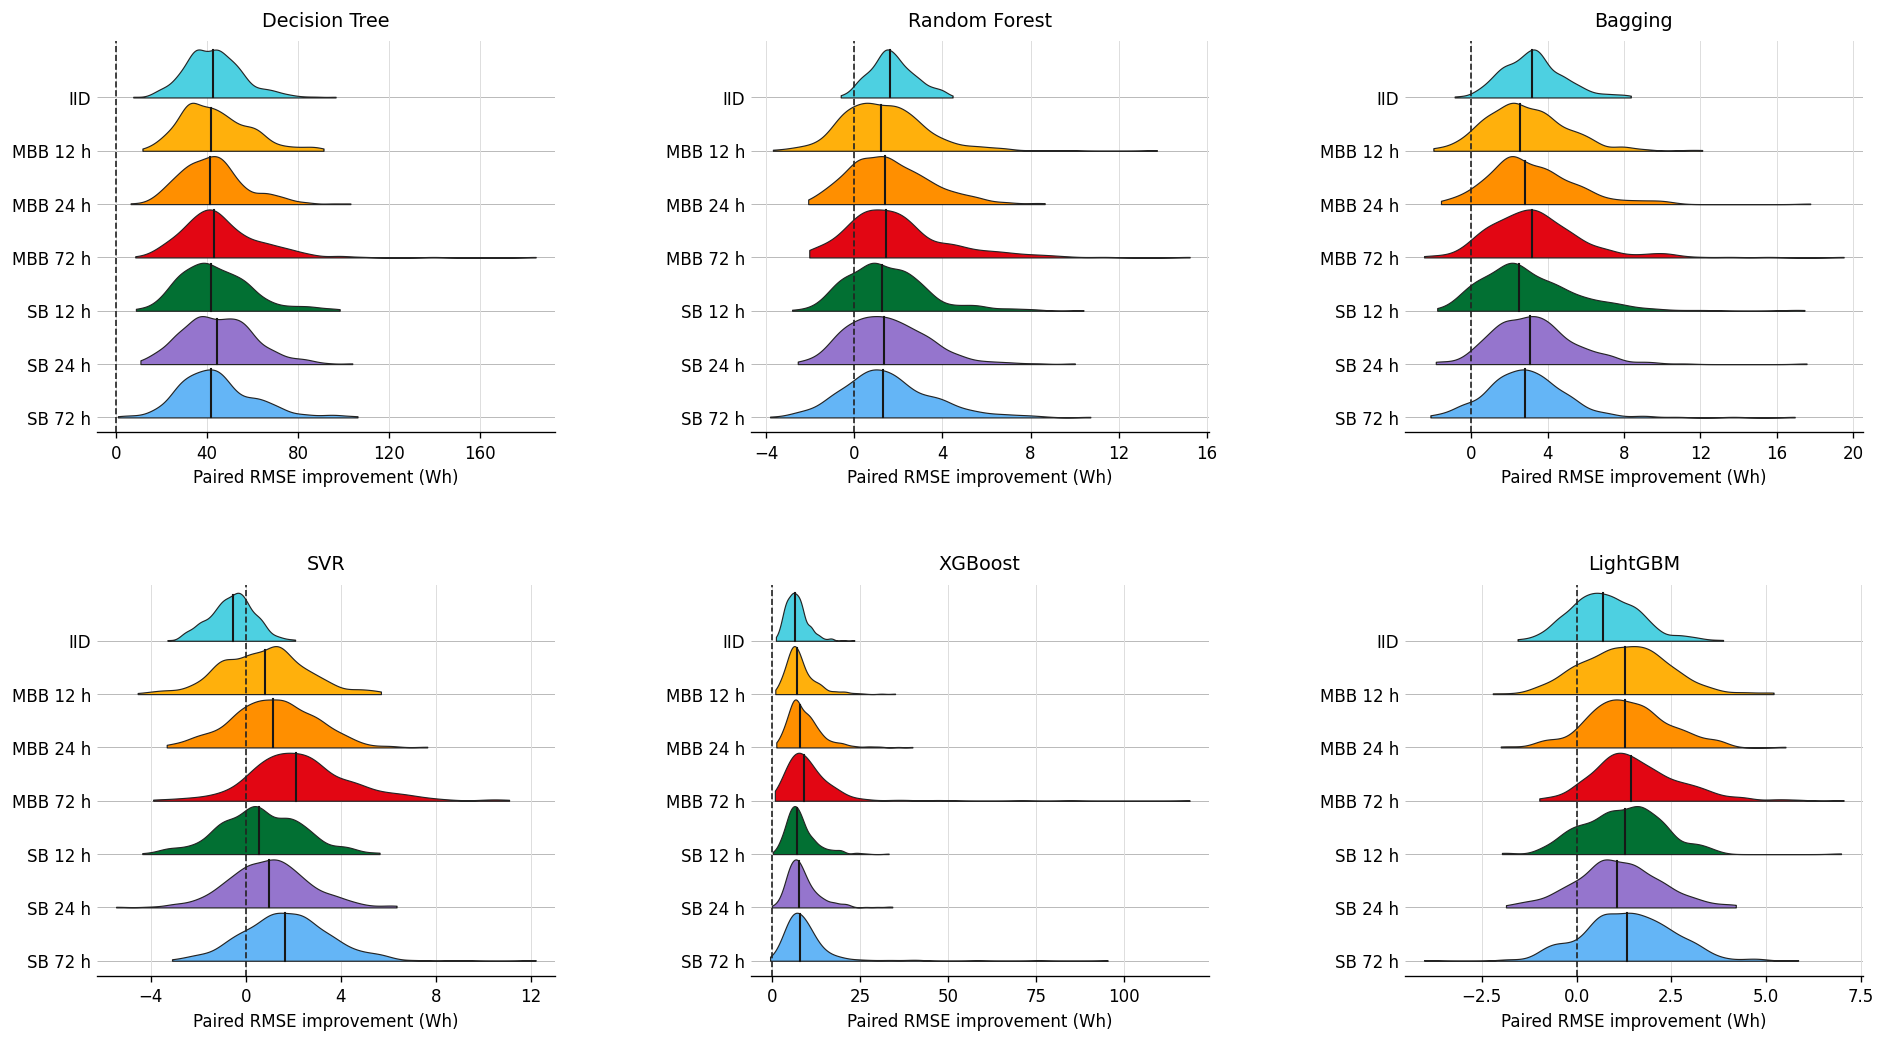

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig07_Paired_RMSE_Improvement_Ridgeline.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig07_Paired_RMSE_Improvement_Ridgeline.pdf

----------------------------------------------------------------------------
FIGURE 08 — TUNING WIN RATE
----------------------------------------------------------------------------


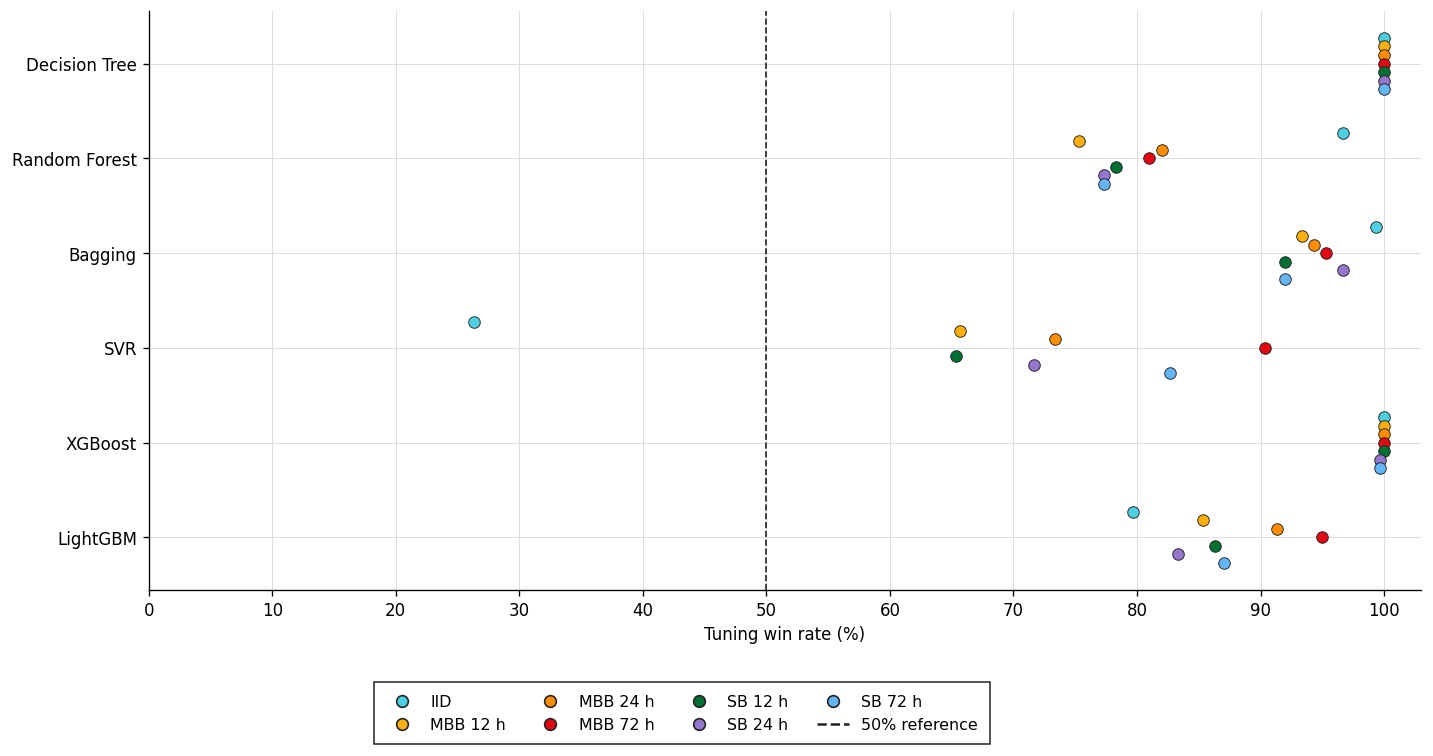

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig08_Tuning_Win_Rate.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig08_Tuning_Win_Rate.pdf

----------------------------------------------------------------------------
FIGURE 09 — PCA BIPLOT OF TUNING BENEFITS
----------------------------------------------------------------------------


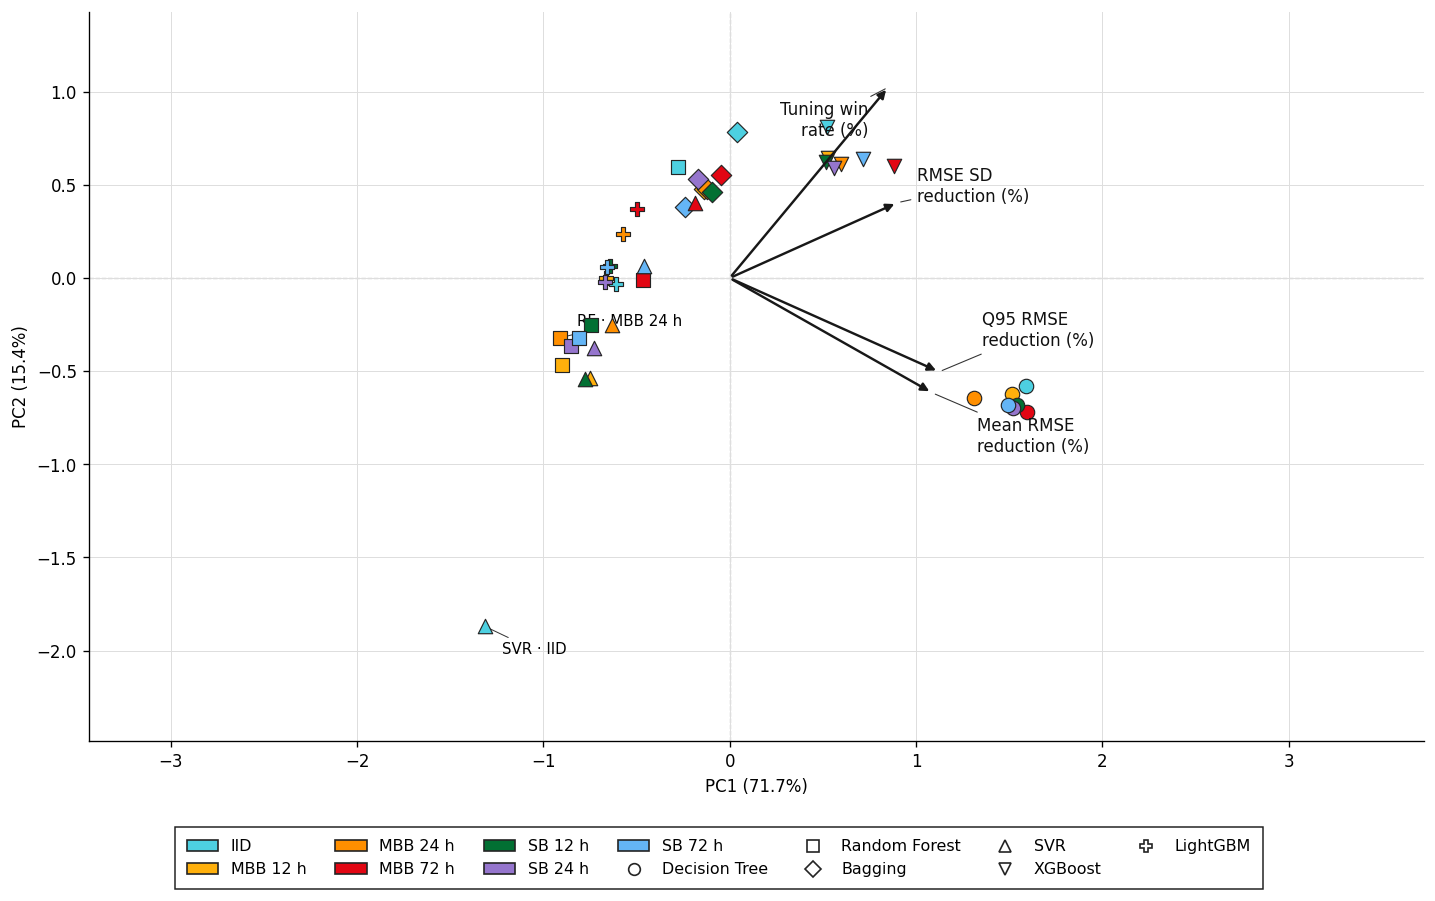

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig09_PCA_Biplot_Tuning_Benefits.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig09_PCA_Biplot_Tuning_Benefits.pdf

----------------------------------------------------------------------------
FIGURE 10 — JOINT ACCURACY–STABILITY OUTCOMES
----------------------------------------------------------------------------


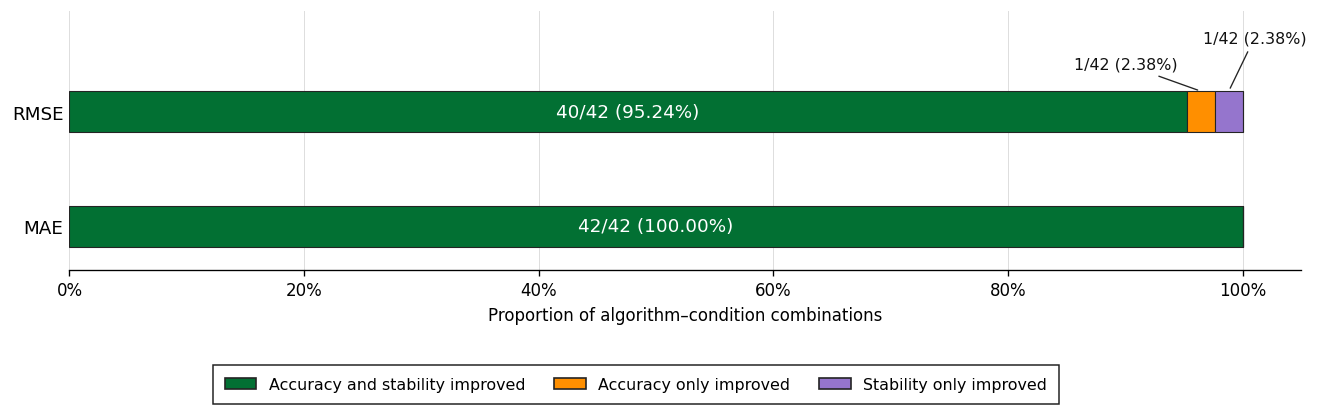

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig10_Joint_Accuracy_Stability_Outcomes.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig10_Joint_Accuracy_Stability_Outcomes.pdf

PCA BIPLOT — EXPLAINED VARIANCE


,component,eigenvalue,explained_variance_pct,cumulative_variance_pct
0,PC1,2.8665,71.6621,71.6621
1,PC2,0.6152,15.3798,87.0419
2,PC3,0.5166,12.9139,99.9558
3,PC4,0.0018,0.0442,100.0000


PC1 + PC2 cumulative explained variance: 87.04%

VARIABLE CORRELATIONS WITH PRINCIPAL COMPONENTS


,variable,PC1_correlation,PC2_correlation
0,mean_rmse_reduction_pct,0.9226,-0.3558
1,rmse_sd_reduction_pct,0.7642,0.2336
2,tuning_win_rate_pct,0.7221,0.5912
3,q95_rmse_reduction_pct,0.9539,-0.2906



JOINT ACCURACY–STABILITY OUTCOMES


outcome_category,Accuracy and stability improved,Accuracy only improved,Stability only improved,Neither improved
metric,,,,
rmse_wh,40,1,1,0
mae_wh,42,0,0,0



CELL 05B — PAIRED TUNING VISUALIZATION COMPLETED
Notebook 03 source integrity       : PASS
Cell 05 artifact integrity         : PASS
Identical bootstrap indices        : PASS
Paired distribution coverage       : PASS

Figure 07 — Ridgeline plot         : PASS
Figure 08 — Win rate dot plot      : PASS
Figure 09 — PCA biplot             : PASS
Figure 10 — Stacked bar chart      : PASS

PC1 + PC2 explained variance       : 87.04%
RMSE joint improvement             : 40/42
MAE joint improvement              : 42/42

Approved categorical colors        : PASS
Gradient colors                    : NO
Figure titles inside plot          : NO
Figure footnotes                   : NO
Outliers removed                   : NO
Predictive model refitting         : NO
Hyperparameter retuning            : NO
New bootstrap                      : NO
Test accessed                      : NO

SAVED FIGURES

Figure 07
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig07_

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 05B
# PAIRED HYPERPARAMETER TUNING VISUALIZATION
# FINAL APPROVED DESIGN
#
# Figure 07 : Ridgeline plot
# Figure 08 : Tuning win rate dot plot
# Figure 09 : PCA biplot
# Figure 10 : 100% stacked bar chart
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 05 Paired Hyperparameter Tuning Analysis
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter

from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required05b = [
    "df_paired_tuning05",
    "df_tuning_summary05",
    "df_tuning_robustness05",
    "df_joint_outcome05",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR",
    "ALGORITHMS04",
    "CONDITIONS04"
]

missing05b = [
    name for name in required05b
    if name not in globals()
]

if missing05b:

    raise RuntimeError(
        "Run Notebook 04 through Cell 05 first. "
        f"Missing objects: {missing05b}"
    )


def ensure05b(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file05b(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

for directory in [
    TABLE_DIR,
    FIGURE_DIR,
    AUDIT_OUTPUT_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# =============================================================================
# 2. VERIFY CELL 05 ARTIFACTS AND SOURCE INTEGRITY
# =============================================================================

CELL05_AUDIT_PATH05B = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell05_paired_tuning_analysis_audit.json"
)

ensure05b(
    CELL05_AUDIT_PATH05B.is_file(),
    "Cell 05 audit artifact missing."
)

with open(
    CELL05_AUDIT_PATH05B,
    "r",
    encoding="utf-8"
) as handle:

    cell05_audit05b = json.load(handle)


SOURCE_HASH05B = sha256_file05b(METRICS_PATH)

ensure05b(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False,
    "Notebook 03 completion manifest mismatch."
)

ensure05b(
    SOURCE_HASH05B
    == bootstrap_manifest["outputs"]["metrics_sha256"]
    == cell05_audit05b["source_metrics_sha256"],
    "Source metrics checksum mismatch."
)

ensure05b(
    cell05_audit05b["status"] == "PASS"
    and cell05_audit05b["paired_records"] == 12600
    and cell05_audit05b["verified_shared_index_pairs"] == 12600
    and cell05_audit05b["paired_groups"] == 42
    and cell05_audit05b["pairs_per_group"] == 300
    and cell05_audit05b["summary_records"] == 84,
    "Cell 05 audit dimensions mismatch."
)

ARTIFACT_BINDINGS05B = {

    "paired_replications":
        df_paired_tuning05,

    "paired_tuning_summary":
        df_tuning_summary05,

    "tuning_robustness":
        df_tuning_robustness05,

    "joint_outcomes":
        df_joint_outcome05
}


for artifact, dataframe in ARTIFACT_BINDINGS05B.items():

    metadata = cell05_audit05b["outputs"][artifact]

    artifact_path = Path(metadata["path"])

    ensure05b(
        artifact_path.is_file(),
        f"Missing artifact: {artifact}"
    )

    ensure05b(
        sha256_file05b(artifact_path)
        == metadata["sha256"],
        f"Artifact checksum mismatch: {artifact}"
    )

    saved = pd.read_csv(artifact_path)

    ensure05b(
        len(saved) == metadata["rows"]
        == len(dataframe),
        f"Artifact row count mismatch: {artifact}"
    )

    pd.testing.assert_frame_equal(

        dataframe.reset_index(drop=True),

        saved.reset_index(drop=True),

        check_dtype=False,
        check_exact=False,

        rtol=1e-10,
        atol=1e-10
    )


# =============================================================================
# 3. FREEZE EXPERIMENT ORDER
# =============================================================================

ALGORITHMS05B = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

CONDITIONS05B = [
    "iid",
    "mbb_L0072",
    "mbb_L0144",
    "mbb_L0432",
    "stationary_L0072",
    "stationary_L0144",
    "stationary_L0432"
]

METRICS05B = [
    "rmse_wh",
    "mae_wh"
]

ensure05b(
    set(ALGORITHMS04) == set(ALGORITHMS05B)
    and set(CONDITIONS04) == set(CONDITIONS05B),
    "Frozen experiment levels changed."
)

CONDITION_LABELS05B = {

    "iid": "IID",

    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",

    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}


# =============================================================================
# 4. APPROVED COLOR PALETTE
# =============================================================================

PALETTE05B = {

    "iid": "#4DD0E1",

    "mbb_L0072": "#FFB00C",
    "mbb_L0144": "#FF8F00",
    "mbb_L0432": "#E20613",

    "stationary_L0072": "#027033",
    "stationary_L0144": "#9575CD",
    "stationary_L0432": "#64B5F6"
}

ALGORITHM_MARKERS05B = {

    "Decision Tree": "o",
    "Random Forest": "s",
    "Bagging": "D",
    "SVR": "^",
    "XGBoost": "v",
    "LightGBM": "P"
}

OUTCOME_COLORS05B = {

    "Accuracy and stability improved": "#027033",

    "Accuracy only improved": "#FF8F00",

    "Stability only improved": "#9575CD",

    "Neither improved": "#E20613"
}


# =============================================================================
# 5. VERIFY AND EXTRACT PAIRED RESULTS
# =============================================================================

ensure05b(
    len(df_paired_tuning05) == 12600
    and len(df_tuning_summary05) == 84,
    "Unexpected paired analysis dimensions."
)

ensure05b(
    not df_paired_tuning05.duplicated(
        ["condition", "algorithm", "replication"]
    ).any(),
    "Duplicate paired experiment records."
)

ensure05b(
    df_paired_tuning05["index_sha256_default"].eq(
        df_paired_tuning05["index_sha256_tuned"]
    ).all(),
    "Default and Tuned bootstrap indices differ."
)

ensure05b(
    not df_tuning_summary05.duplicated(
        ["condition", "algorithm", "metric"]
    ).any(),
    "Duplicate tuning summary records."
)

SUMMARY_LOOKUP05B = (
    df_tuning_summary05
    .set_index(
        ["algorithm", "condition", "metric"]
    )
)

EXPECTED_KEYS05B = {
    (algorithm, condition, metric)

    for algorithm in ALGORITHMS05B
    for condition in CONDITIONS05B
    for metric in METRICS05B
}

ensure05b(
    set(SUMMARY_LOOKUP05B.index.tolist())
    == EXPECTED_KEYS05B,
    "Incomplete summary design."
)


def get_summary05b(
    algorithm,
    condition,
    metric,
    statistic
):

    return float(

        SUMMARY_LOOKUP05B.loc[
            (
                algorithm,
                condition,
                metric
            ),
            statistic
        ]
    )


# =============================================================================
# 6. EXTRACT ORIGINAL PAIRED RMSE IMPROVEMENTS
#
# Positive = Tuned has lower RMSE
# Negative = Default has lower RMSE
# =============================================================================

DELTA_LOOKUP05B = {}

for (
    algorithm,
    condition
), subset in df_paired_tuning05.groupby(
    ["algorithm", "condition"]
):

    subset = subset.sort_values("replication")

    ensure05b(
        subset["replication"].tolist()
        == list(range(1, 301)),
        "Incomplete paired replication sequence."
    )

    delta = subset[
        "rmse_wh_improvement"
    ].to_numpy(dtype=np.float64)

    ensure05b(
        delta.shape == (300,)
        and np.isfinite(delta).all(),
        "Invalid paired RMSE distribution."
    )

    ensure05b(
        np.allclose(
            delta,
            subset["rmse_wh_default"]
            - subset["rmse_wh_tuned"],
            rtol=1e-10,
            atol=1e-9
        ),
        "Paired RMSE improvement identity failed."
    )

    ensure05b(
        np.isclose(
            delta.mean(),
            get_summary05b(
                algorithm,
                condition,
                "rmse_wh",
                "mean_improvement_wh"
            ),
            rtol=1e-10,
            atol=1e-9
        ),
        "Paired improvement summary mismatch."
    )

    DELTA_LOOKUP05B[
        (algorithm, condition)
    ] = delta


ensure05b(
    len(DELTA_LOOKUP05B) == 42,
    "Expected 42 paired RMSE distributions."
)


# =============================================================================
# 7. APPROVED PUBLICATION STYLE
# =============================================================================

STYLE05B = {

    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",

    "axes.titleweight": "normal",
    "axes.labelweight": "normal",

    "axes.labelcolor": "#000000",
    "text.color": "#000000",
    "xtick.color": "#000000",
    "ytick.color": "#000000",

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "figure.dpi": 120,
    "savefig.dpi": 300,

    "pdf.fonttype": 42,
    "ps.fonttype": 42
}


def clean_axis05b(ax, grid_axis="x"):

    ax.grid(

        axis=grid_axis,

        color="#DEDEDE",
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def boxed_legend05b(
    fig,
    handles,
    ncol,
    y=0.025
):

    legend = fig.legend(

        handles=handles,

        ncol=ncol,

        loc="lower center",
        bbox_to_anchor=(0.5, y),

        frameon=True,
        fancybox=False,
        framealpha=1.0,

        facecolor="white",
        edgecolor="#202020",

        borderpad=0.75,
        columnspacing=1.8,

        fontsize=9.5
    )

    legend.get_frame().set_linewidth(0.9)

    return legend


def export_figure05b(
    fig,
    number,
    filename,
    description
):

    stem = FIGURE_DIR / filename

    png_path = stem.with_suffix(".png")
    pdf_path = stem.with_suffix(".pdf")

    fig.savefig(

        png_path,

        dpi=300,
        bbox_inches="tight",
        pad_inches=0.10,

        facecolor="white"
    )

    fig.savefig(

        pdf_path,

        bbox_inches="tight",
        pad_inches=0.10,

        facecolor="white"
    )

    ensure05b(
        png_path.is_file()
        and pdf_path.is_file()
        and png_path.stat().st_size > 0
        and pdf_path.stat().st_size > 0,
        f"Figure {number} export failed."
    )

    plt.show()
    plt.close(fig)

    return {

        "figure_number": number,

        "description": description,

        "png": str(png_path),
        "pdf": str(pdf_path),

        "png_sha256": sha256_file05b(png_path),
        "pdf_sha256": sha256_file05b(pdf_path)
    }


# =============================================================================
# 8. FIGURE 07 — RIDGELINE PLOT
#
# Distribution:
# RMSE(Default) - RMSE(Tuned)
#
# Each ridge uses 300 paired observations.
#
# KDE:
# Gaussian kernel, bandwidth factor = 0.25
#
# Ridge heights are individually peak-normalized.
# They represent distribution shape, not relative density magnitude.
#
# Solid line inside ridge = Median
# Dashed vertical line   = Zero improvement
#
# Independent X-axis per algorithm.
# =============================================================================

def make_figure07():

    with plt.rc_context(STYLE05B):

        fig, axes = plt.subplots(

            nrows=2,
            ncols=3,

            figsize=(16.4, 9),

            sharex=False,
            sharey=False
        )

        plotted_groups = 0

        for ax, algorithm in zip(
            axes.flat,
            ALGORITHMS05B
        ):

            all_values = np.concatenate([

                DELTA_LOOKUP05B[
                    (algorithm, condition)
                ]

                for condition in CONDITIONS05B
            ])

            # Include all observed values and zero.

            lower = min(
                float(all_values.min()),
                0.0
            )

            upper = max(
                float(all_values.max()),
                0.0
            )

            padding = (
                (upper - lower) * 0.045
            )

            for i, condition in enumerate(
                CONDITIONS05B
            ):

                values = DELTA_LOOKUP05B[
                    (algorithm, condition)
                ]

                ensure05b(
                    values.std(ddof=1) > 0,
                    "Degenerate distribution for KDE."
                )

                kde = gaussian_kde(

                    values,

                    bw_method=0.25
                )

                # Preserve full observed support.

                x_grid = np.linspace(

                    values.min(),
                    values.max(),

                    1000
                )

                density = kde(x_grid)

                ensure05b(
                    np.isfinite(density).all()
                    and density.max() > 0,
                    "Invalid KDE density."
                )

                baseline = 6 - i

                ridge_height = (
                    baseline
                    + 0.90 * density / density.max()
                )

                ax.fill_between(

                    x_grid,

                    baseline,
                    ridge_height,

                    color=PALETTE05B[condition],

                    alpha=1.0,

                    edgecolor="#242424",
                    linewidth=0.7,

                    zorder=2 + i
                )

                ax.hlines(

                    baseline,

                    lower - padding,
                    upper + padding,

                    color="#9A9A9A",
                    linewidth=0.4,

                    zorder=0
                )

                # Median line.

                median = float(
                    np.median(values)
                )

                median_height = (

                    baseline

                    + 0.90
                    * float(kde([median])[0])
                    / density.max()
                )

                ax.plot(

                    [median, median],

                    [baseline, median_height],

                    color="#171717",
                    linewidth=1.25,

                    zorder=10
                )

                plotted_groups += 1

            # Zero improvement reference.

            ax.axvline(

                0,

                color="#222222",
                linestyle="--",
                linewidth=1,

                zorder=11
            )

            ax.set_xlim(

                lower - padding,
                upper + padding
            )

            ax.set_ylim(
                -0.28,
                7.05
            )

            ax.set_yticks(
                np.arange(6, -1, -1)
            )

            ax.set_yticklabels([

                CONDITION_LABELS05B[condition]

                for condition in CONDITIONS05B
            ])

            ax.set_title(

                algorithm,

                fontsize=11.5,
                pad=9,

                fontweight="normal"
            )

            ax.set_xlabel(
                "Paired RMSE improvement (Wh)"
            )

            ax.xaxis.set_major_locator(
                MaxNLocator(nbins=6)
            )

            ax.spines["left"].set_visible(False)

            ax.tick_params(
                axis="y",
                length=0
            )

            clean_axis05b(
                ax,
                grid_axis="x"
            )

        ensure05b(
            plotted_groups == 42,
            "Incomplete Figure 07 distribution coverage."
        )

        fig.subplots_adjust(

            left=0.088,
            right=0.985,

            top=0.95,
            bottom=0.085,

            wspace=0.43,
            hspace=0.39
        )

        # No legend: bootstrap conditions are directly
        # identified by the Y-axis labels.

        return export_figure05b(

            fig=fig,

            number=7,

            filename=(
                "NB04_Fig07_Paired_RMSE_Improvement_Ridgeline"
            ),

            description=(
                "Empirical paired RMSE improvement distributions"
            )
        )


# =============================================================================
# 9. FIGURE 08 — TUNING WIN RATE DOT PLOT
#
# 42 points:
# Six algorithms x seven bootstrap conditions.
#
# Reference line = 50%
#
# Vertical offsets distinguish overlapping conditions.
# Horizontal values remain unchanged.
# =============================================================================

def make_figure08():

    with plt.rc_context(STYLE05B):

        fig, ax = plt.subplots(
            figsize=(12.7, 6.6)
        )

        plotted_values = []

        for i, algorithm in enumerate(
            ALGORITHMS05B
        ):

            for j, condition in enumerate(
                CONDITIONS05B
            ):

                win_rate = get_summary05b(

                    algorithm,

                    condition,

                    "rmse_wh",

                    "win_rate_pct"
                )

                ensure05b(
                    0 <= win_rate <= 100,
                    "Invalid tuning win rate."
                )

                plotted_values.append(win_rate)

                ax.scatter(

                    win_rate,

                    i + (j - 3) * 0.09,

                    color=PALETTE05B[condition],

                    marker="o",
                    s=48,

                    edgecolor="#242424",
                    linewidth=0.55,

                    zorder=4
                )

        ax.axvline(

            50,

            color="#222222",
            linestyle="--",
            linewidth=1
        )

        ax.set_yticks(

            range(len(ALGORITHMS05B)),

            ALGORITHMS05B
        )

        ax.set_ylim(5.55, -0.55)

        ax.set_xlim(0, 103)

        ax.set_xticks(
            np.arange(0, 101, 10)
        )

        ax.set_xlabel(
            "Tuning win rate (%)"
        )

        clean_axis05b(
            ax,
            grid_axis="both"
        )

        ensure05b(
            len(plotted_values) == 42,
            "Incomplete Figure 08 point coverage."
        )

        handles = [

            Line2D(

                [0], [0],

                marker="o",
                linestyle="None",

                markerfacecolor=PALETTE05B[condition],
                markeredgecolor="#242424",

                markersize=7,

                label=CONDITION_LABELS05B[condition]
            )

            for condition in CONDITIONS05B
        ]

        handles.append(

            Line2D(

                [0], [0],

                color="#222222",
                linestyle="--",

                label="50% reference"
            )
        )

        boxed_legend05b(

            fig,

            handles,

            ncol=4
        )

        fig.subplots_adjust(

            left=0.15,
            right=0.985,

            top=0.96,
            bottom=0.23
        )

        return export_figure05b(

            fig=fig,

            number=8,

            filename=(
                "NB04_Fig08_Tuning_Win_Rate"
            ),

            description=(
                "RMSE tuning win rate across bootstrap conditions"
            )
        )


# =============================================================================
# 10. PREPARE PCA BIPLOT
#
# Exploratory multivariate analysis.
#
# Observations:
# 42 algorithm-condition combinations.
#
# Variables:
# 1. Mean RMSE reduction (%)
# 2. RMSE SD reduction (%)
# 3. Tuning win rate (%)
# 4. Q95 RMSE reduction (%)
#
# All four variables are standardized before PCA.
# No model fitting or bootstrap generation.
# =============================================================================

df_pca_input05b = (

    df_tuning_summary05.loc[

        df_tuning_summary05["metric"]
        == "rmse_wh"
    ]

    .sort_values(
        ["algorithm", "condition"]
    )

    .reset_index(drop=True)

    .copy()
)

ensure05b(
    len(df_pca_input05b) == 42,
    "Invalid PCA observation count."
)

ensure05b(
    df_pca_input05b["q95_default_wh"].gt(0).all(),
    "Invalid Q95 reduction denominator."
)


df_pca_input05b["mean_rmse_reduction_pct"] = (

    df_pca_input05b["mean_improvement_pct"]
)

df_pca_input05b["rmse_sd_reduction_pct"] = (

    df_pca_input05b["stability_improvement_pct"]
)

df_pca_input05b["tuning_win_rate_pct"] = (

    df_pca_input05b["win_rate_pct"]
)

df_pca_input05b["q95_rmse_reduction_pct"] = (

    100 * (

        1

        - df_pca_input05b["q95_tuned_wh"]

        / df_pca_input05b["q95_default_wh"]
    )
)


PCA_VARIABLES05B = [

    "mean_rmse_reduction_pct",

    "rmse_sd_reduction_pct",

    "tuning_win_rate_pct",

    "q95_rmse_reduction_pct"
]

PCA_LABELS05B = [

    "Mean RMSE\nreduction (%)",

    "RMSE SD\nreduction (%)",

    "Tuning win\nrate (%)",

    "Q95 RMSE\nreduction (%)"
]

X_PCA05B = (

    df_pca_input05b[PCA_VARIABLES05B]

    .to_numpy(dtype=np.float64)
)

ensure05b(
    X_PCA05B.shape == (42, 4)
    and np.isfinite(X_PCA05B).all(),
    "Invalid PCA input matrix."
)

PCA_MEANS05B = X_PCA05B.mean(axis=0)

PCA_SDS05B = X_PCA05B.std(

    axis=0,

    ddof=1
)

ensure05b(
    np.all(PCA_SDS05B > 0),
    "Constant PCA input variable detected."
)

Z_PCA05B = (

    X_PCA05B - PCA_MEANS05B

) / PCA_SDS05B


# -----------------------------------------------------------------------------
# 10A. SINGULAR VALUE DECOMPOSITION
# -----------------------------------------------------------------------------

U05B, S05B, VT05B = np.linalg.svd(

    Z_PCA05B,

    full_matrices=False
)

# Deterministic sign orientation for reproducibility.

# PC1: mean RMSE reduction points right.
if VT05B[0, 0] < 0:

    U05B[:, 0] *= -1
    VT05B[0, :] *= -1

# PC2: tuning win rate points upward.
if VT05B[1, 2] < 0:

    U05B[:, 1] *= -1
    VT05B[1, :] *= -1


PCA_EIGENVALUES05B = (

    S05B ** 2

    / (len(X_PCA05B) - 1)
)

PCA_EXPLAINED05B = (

    PCA_EIGENVALUES05B

    / PCA_EIGENVALUES05B.sum()
)

PCA_SCORES05B = (

    U05B * S05B
)


# -----------------------------------------------------------------------------
# 10B. SYMMETRIC BIPLOT COORDINATES
#
# Gabriel-style symmetric SVD scaling.
#
# Reciprocal graphical scaling preserves inner products.
# -----------------------------------------------------------------------------

BIPLOT_SCALE05B = 1.65

BIPLOT_ROWS05B = (

    U05B[:, :2]

    * np.sqrt(S05B[:2])

    * BIPLOT_SCALE05B
)

BIPLOT_VECTORS05B = (

    VT05B[:2, :].T

    * np.sqrt(S05B[:2])

    / BIPLOT_SCALE05B
)

# Confirm that graphical scaling preserves rank-2 reconstruction.

RECONSTRUCTION05B = (

    PCA_SCORES05B[:, :2]

    @ VT05B[:2, :]
)

ensure05b(
    np.allclose(

        BIPLOT_ROWS05B
        @ BIPLOT_VECTORS05B.T,

        RECONSTRUCTION05B,

        atol=1e-10,
        rtol=1e-10
    ),

    "Biplot reconstruction identity failed."
)

PCA_CORRELATIONS05B = np.corrcoef(

    Z_PCA05B.T,

    PCA_SCORES05B[:, :2].T

)[:4, 4:]


# -----------------------------------------------------------------------------
# 10C. SAVE REPRODUCIBLE PCA TABLES
# -----------------------------------------------------------------------------

df_pca_scores05b = (

    df_pca_input05b[
        ["algorithm", "condition"]
        + PCA_VARIABLES05B
    ]

    .copy()
)

for j in range(4):

    df_pca_scores05b[
        f"PC{j + 1}_score"
    ] = PCA_SCORES05B[:, j]


df_pca_scores05b["biplot_x"] = (

    BIPLOT_ROWS05B[:, 0]
)

df_pca_scores05b["biplot_y"] = (

    BIPLOT_ROWS05B[:, 1]
)


df_pca_variables05b = pd.DataFrame({

    "variable": PCA_VARIABLES05B,

    "standardization_mean": PCA_MEANS05B,

    "standardization_sd": PCA_SDS05B,

    "PC1_eigenvector": VT05B[0, :],

    "PC2_eigenvector": VT05B[1, :],

    "PC1_correlation": PCA_CORRELATIONS05B[:, 0],

    "PC2_correlation": PCA_CORRELATIONS05B[:, 1],

    "biplot_x": BIPLOT_VECTORS05B[:, 0],

    "biplot_y": BIPLOT_VECTORS05B[:, 1]
})


df_pca_variance05b = pd.DataFrame({

    "component": [
        "PC1",
        "PC2",
        "PC3",
        "PC4"
    ],

    "eigenvalue": PCA_EIGENVALUES05B,

    "explained_variance_pct": (
        100 * PCA_EXPLAINED05B
    ),

    "cumulative_variance_pct": (
        100 * np.cumsum(PCA_EXPLAINED05B)
    )
})


# =============================================================================
# 11. FIGURE 09 — PCA BIPLOT
#
# Color  = bootstrap condition
# Marker = algorithm
# Arrow  = variable biplot coordinates
#
# Equal geometric scaling on both axes.
# =============================================================================

def make_figure09():

    with plt.rc_context(STYLE05B):

        fig, ax = plt.subplots(
            figsize=(12.5, 8.0)
        )

        for i, row in df_pca_input05b.iterrows():

            algorithm = row["algorithm"]

            condition = row["condition"]

            ax.scatter(

                BIPLOT_ROWS05B[i, 0],

                BIPLOT_ROWS05B[i, 1],

                s=75,

                marker=ALGORITHM_MARKERS05B[
                    algorithm
                ],

                color=PALETTE05B[
                    condition
                ],

                edgecolor="#242424",

                linewidth=0.7,

                zorder=4
            )

        ax.axhline(

            0,

            color="#7A7A7A",

            linewidth=0.7,
            linestyle="--",

            zorder=0
        )

        ax.axvline(

            0,

            color="#7A7A7A",

            linewidth=0.7,
            linestyle="--",

            zorder=0
        )

        # Exact arrow coordinates from PCA.
        # Label positions follow the approved preview.

        label_offsets = [

            (27, -26),

            (12, 10),

            (-12, -20),

            (26, 25)
        ]

        for j, (
            vx,
            vy
        ) in enumerate(BIPLOT_VECTORS05B):

            ax.annotate(

                "",

                xy=(vx, vy),

                xytext=(0, 0),

                arrowprops={

                    "arrowstyle": "-|>",

                    "color": "#181818",

                    "linewidth": 1.45
                },

                zorder=5
            )

            dx, dy = label_offsets[j]

            ax.annotate(

                PCA_LABELS05B[j],

                xy=(vx, vy),

                xytext=(dx, dy),

                textcoords="offset points",

                ha=(
                    "left" if dx > 0
                    else "right"
                ),

                va="center",

                fontsize=10,

                color="#111111",

                arrowprops={

                    "arrowstyle": "-",

                    "color": "#333333",

                    "linewidth": 0.65
                },

                zorder=6
            )

        # Identify the two observed RMSE trade-offs.

        annotations = [

            (
                "SVR",
                "iid",
                "SVR · IID",
                (10, -14)
            ),

            (
                "Random Forest",
                "mbb_L0144",
                "RF · MBB 24 h",
                (10, 10)
            )
        ]

        for (
            algorithm,
            condition,
            label,
            offset
        ) in annotations:

            matching = np.flatnonzero(

                (

                    df_pca_input05b["algorithm"]
                    .eq(algorithm)

                    &

                    df_pca_input05b["condition"]
                    .eq(condition)

                ).to_numpy()
            )

            ensure05b(
                len(matching) == 1,
                "Biplot annotation object missing."
            )

            i = matching[0]

            ax.annotate(

                label,

                xy=BIPLOT_ROWS05B[i],

                xytext=offset,

                textcoords="offset points",

                fontsize=9,

                ha="left",
                va="center",

                arrowprops={

                    "arrowstyle": "-",

                    "linewidth": 0.6,

                    "color": "#333333"
                }
            )

        ax.set_xlabel(

            f"PC1 ({100 * PCA_EXPLAINED05B[0]:.1f}%)"
        )

        ax.set_ylabel(

            f"PC2 ({100 * PCA_EXPLAINED05B[1]:.1f}%)"
        )

        ax.set_aspect(

            "equal",

            adjustable="datalim"
        )

        ax.margins(0.23)

        clean_axis05b(

            ax,

            grid_axis="both"
        )

        # Bootstrap condition colors.

        handles = [

            Patch(

                facecolor=PALETTE05B[condition],

                edgecolor="#242424",

                label=CONDITION_LABELS05B[
                    condition
                ]
            )

            for condition in CONDITIONS05B
        ]

        # Algorithm marker shapes.

        handles += [

            Line2D(

                [0], [0],

                marker=ALGORITHM_MARKERS05B[
                    algorithm
                ],

                linestyle="None",

                markerfacecolor="white",

                markeredgecolor="#242424",

                markersize=7,

                label=algorithm
            )

            for algorithm in ALGORITHMS05B
        ]

        boxed_legend05b(

            fig,

            handles,

            ncol=7,

            y=0.028
        )

        fig.subplots_adjust(

            left=0.08,
            right=0.97,

            top=0.95,
            bottom=0.19
        )

        return export_figure05b(

            fig=fig,

            number=9,

            filename=(
                "NB04_Fig09_PCA_Biplot_Tuning_Benefits"
            ),

            description=(
                "Exploratory PCA biplot of four tuning benefit measures"
            )
        )


# =============================================================================
# 12. EXTRACT JOINT ACCURACY–STABILITY OUTCOMES
#
# Uses the classification already computed in Cell 05.
# No new model evaluation.
# =============================================================================

OUTCOME_ORDER05B = [

    "Accuracy and stability improved",

    "Accuracy only improved",

    "Stability only improved",

    "Neither improved"
]

outcome_mapping05b = {

    "Accuracy and stability improved":
        "Accuracy and stability improved",

    "Accuracy improved, stability decreased":
        "Accuracy only improved",

    "Accuracy improved, stability unchanged":
        "Accuracy only improved",

    "Accuracy decreased, stability improved":
        "Stability only improved",

    "Accuracy unchanged, stability improved":
        "Stability only improved",

    "Accuracy and stability decreased":
        "Neither improved",

    "Accuracy decreased, stability unchanged":
        "Neither improved",

    "Accuracy unchanged, stability decreased":
        "Neither improved",

    "Accuracy and stability unchanged":
        "Neither improved"
}

df_joint_plot05b = df_joint_outcome05.copy()

df_joint_plot05b["outcome_category"] = (

    df_joint_plot05b["joint_outcome"]

    .map(outcome_mapping05b)
)

ensure05b(
    df_joint_plot05b[
        "outcome_category"
    ].notna().all(),
    "Unrecognized joint outcome category."
)

df_joint_counts05b = (

    df_joint_plot05b

    .pivot_table(

        index="metric",

        columns="outcome_category",

        values="n_condition_algorithm_groups",

        aggfunc="sum",

        fill_value=0
    )

    .reindex(

        index=METRICS05B,

        columns=OUTCOME_ORDER05B,

        fill_value=0
    )

    .astype(int)
)

JOINT_COUNTS05B = (

    df_joint_counts05b.to_numpy()
)

ensure05b(
    np.all(JOINT_COUNTS05B.sum(axis=1) == 42),
    "Joint outcome counts must sum to 42."
)

# Consistency with the audited Cell 05 result
# and approved visualization preview.

ensure05b(
    JOINT_COUNTS05B.tolist()
    == [

        [40, 1, 1, 0],

        [42, 0, 0, 0]
    ],

    "Joint outcome results differ from the approved preview."
)

JOINT_PERCENTAGES05B = (

    100 * JOINT_COUNTS05B / 42
)


# =============================================================================
# 13. FIGURE 10 — 100% STACKED BAR CHART
#
# RMSE: 40 joint improvements + 2 trade-offs
# MAE : 42 joint improvements
#
# Denominator:
# 42 algorithm-condition combinations per metric.
#
# These percentages are NOT percentages of bootstrap replications.
# =============================================================================

def make_figure10():

    with plt.rc_context(STYLE05B):

        fig, ax = plt.subplots(
            figsize=(11.8, 3.65)
        )

        y = np.array([
            1.0,
            0.0
        ])

        left = np.zeros(2)

        for j, category in enumerate(
            OUTCOME_ORDER05B
        ):

            percentages = JOINT_PERCENTAGES05B[:, j]

            ax.barh(

                y,

                percentages,

                left=left,

                height=0.36,

                color=OUTCOME_COLORS05B[
                    category
                ],

                edgecolor="#242424",

                linewidth=0.65
            )

            for i in range(2):

                count = int(
                    JOINT_COUNTS05B[i, j]
                )

                pct = float(
                    percentages[i]
                )

                if count == 0:

                    continue

                # Large category: label inside the bar.

                if pct > 20:

                    ax.text(

                        left[i] + pct / 2,

                        y[i],

                        f"{count}/42 ({pct:.2f}%)",

                        ha="center",
                        va="center",

                        color="white",

                        fontsize=11,

                        fontweight="normal"
                    )

                # Small category:
                # external label with leader line.

                else:

                    center = (
                        left[i] + pct / 2
                    )

                    text_x = (
                        90 if j == 1
                        else 101
                    )

                    text_y = (

                        y[i]

                        + (
                            0.35 if j == 1
                            else 0.58
                        )
                    )

                    ax.annotate(

                        f"{count}/42 ({pct:.2f}%)",

                        xy=(
                            center,
                            y[i] + 0.18
                        ),

                        xytext=(
                            text_x,
                            text_y
                        ),

                        ha="center",

                        va="bottom",

                        fontsize=9.5,

                        color="#111111",

                        arrowprops={

                            "arrowstyle": "-",

                            "linewidth": 0.8,

                            "color": "#242424"
                        }
                    )

            left += percentages

        ensure05b(
            np.allclose(left, 100),
            "Stacked bar proportions do not sum to 100%."
        )

        ax.set_yticks(

            y,

            ["RMSE", "MAE"],

            fontsize=11
        )

        ax.set_xlim(0, 105)

        ax.set_ylim(-0.38, 1.88)

        ax.set_xticks([
            0, 20, 40, 60, 80, 100
        ])

        ax.xaxis.set_major_formatter(

            PercentFormatter(

                100,

                decimals=0
            )
        )

        ax.set_xlabel(

            "Proportion of algorithm–condition combinations"
        )

        ax.spines["left"].set_visible(False)

        ax.tick_params(

            axis="y",

            length=0
        )

        clean_axis05b(

            ax,

            grid_axis="x"
        )

        # Display only observed outcome categories.

        handles = [

            Patch(

                facecolor=OUTCOME_COLORS05B[
                    category
                ],

                edgecolor="#242424",

                label=category
            )

            for j, category in enumerate(
                OUTCOME_ORDER05B
            )

            if JOINT_COUNTS05B[:, j].sum() > 0
        ]

        boxed_legend05b(

            fig,

            handles,

            ncol=3
        )

        fig.subplots_adjust(

            left=0.10,
            right=0.97,

            top=0.94,
            bottom=0.35
        )

        return export_figure05b(

            fig=fig,

            number=10,

            filename=(
                "NB04_Fig10_Joint_Accuracy_Stability_Outcomes"
            ),

            description=(
                "Proportion of joint accuracy and stability improvements"
            )
        )


# =============================================================================
# 14. GENERATE ALL FOUR APPROVED FIGURES
# =============================================================================

print("=" * 76)

print("CELL 05B — PAIRED TUNING VISUALIZATION")

print("=" * 76)

print("Source: Notebook 04 — Cell 05")

print("Original fitting records: 25200")

print("Verified paired observations: 12600")

print("Condition–algorithm groups: 42")

print("Replications per group: 300")

print("Source checksum: VERIFIED")

print("Cell 05 artifact checksums: VERIFIED")


FIGURE_OUTPUTS05B = []

FIGURE_FUNCTIONS05B = [

    (
        7,
        "PAIRED RMSE IMPROVEMENT RIDGELINE",
        make_figure07
    ),

    (
        8,
        "TUNING WIN RATE",
        make_figure08
    ),

    (
        9,
        "PCA BIPLOT OF TUNING BENEFITS",
        make_figure09
    ),

    (
        10,
        "JOINT ACCURACY–STABILITY OUTCOMES",
        make_figure10
    )
]


for number, description, function in FIGURE_FUNCTIONS05B:

    print("\n" + "-" * 76)

    print(
        f"FIGURE {number:02d} — {description}"
    )

    print("-" * 76)

    result = function()

    FIGURE_OUTPUTS05B.append(result)

    print("PNG:", result["png"])

    print("PDF:", result["pdf"])


ensure05b(
    len(FIGURE_OUTPUTS05B) == 4
    and {

        item["figure_number"]

        for item in FIGURE_OUTPUTS05B

    } == {7, 8, 9, 10},

    "Incomplete approved figure outputs."
)


# =============================================================================
# 15. DISPLAY PCA NUMERICAL RESULTS
# =============================================================================

print("\n" + "=" * 76)

print("PCA BIPLOT — EXPLAINED VARIANCE")

print("=" * 76)

display(

    df_pca_variance05b.round(4)
)

print(

    "PC1 + PC2 cumulative explained variance:",

    f"{100 * PCA_EXPLAINED05B[:2].sum():.2f}%"
)


print("\nVARIABLE CORRELATIONS WITH PRINCIPAL COMPONENTS")

display(

    df_pca_variables05b[

        [

            "variable",

            "PC1_correlation",

            "PC2_correlation"
        ]

    ].round(4)
)


print("\nJOINT ACCURACY–STABILITY OUTCOMES")

display(df_joint_counts05b)


# =============================================================================
# 16. SAVE SUPPLEMENTARY NUMERICAL ARTIFACTS
# =============================================================================

def save_csv05b(dataframe, path):

    temporary = path.with_name(

        path.name + ".temporary"
    )

    dataframe.to_csv(

        temporary,

        index=False,

        float_format="%.12g"
    )

    os.replace(
        temporary,
        path
    )

    return {

        "path": str(path),

        "rows": int(len(dataframe)),

        "sha256": sha256_file05b(path)
    }


OUTPUT_TABLES05B = {}


OUTPUT_TABLES05B["pca_scores"] = save_csv05b(

    df_pca_scores05b,

    TABLE_DIR

    / "NB04_B300_tuning_PCA_scores.csv"
)


OUTPUT_TABLES05B["pca_variable_coordinates"] = save_csv05b(

    df_pca_variables05b,

    TABLE_DIR

    / "NB04_B300_tuning_PCA_variable_coordinates.csv"
)


OUTPUT_TABLES05B["pca_explained_variance"] = save_csv05b(

    df_pca_variance05b,

    TABLE_DIR

    / "NB04_B300_tuning_PCA_explained_variance.csv"
)


# Joint outcome figure data in long format.

joint_records05b = []

for i, metric in enumerate(METRICS05B):

    for j, category in enumerate(OUTCOME_ORDER05B):

        joint_records05b.append({

            "metric": metric,

            "outcome_category": category,

            "n_groups": int(

                JOINT_COUNTS05B[i, j]
            ),

            "total_groups": 42,

            "percentage": float(

                JOINT_PERCENTAGES05B[i, j]
            )
        })


df_joint_figure_data05b = pd.DataFrame(

    joint_records05b
)


OUTPUT_TABLES05B["joint_figure_data"] = save_csv05b(

    df_joint_figure_data05b,

    TABLE_DIR

    / "NB04_B300_joint_outcome_figure_data.csv"
)


# =============================================================================
# 17. REPRODUCIBILITY AUDIT
# =============================================================================

VISUAL_AUDIT05B = {

    "notebook": "04",

    "cell": "05B",

    "status": "PASS",

    "visualization_version": (
        "approved_ridgeline_dotplot_biplot_stacked_v1"
    ),

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 Cell 05"
    ),

    "source_metrics_sha256": SOURCE_HASH05B,

    "source_cell05_audit_sha256": sha256_file05b(

        CELL05_AUDIT_PATH05B
    ),

    "original_fitting_records": 25200,

    "paired_observations": 12600,

    "condition_algorithm_groups": 42,

    "replications_per_group": 300,

    "figure_count": 4,

    "figure07": {

        "type": "ridgeline plot",

        "statistic": (
            "RMSE_default - RMSE_tuned"
        ),

        "distribution_groups": 42,

        "replications_per_distribution": 300,

        "density_method": "Gaussian KDE",

        "bandwidth_factor": 0.25,

        "density_grid_points": 1000,

        "ridge_height_scaling": (
            "Individually peak-normalized"
        ),

        "support": "Full observed range",

        "median_line": True,

        "zero_reference": True,

        "independent_x_axes": True,

        "legend": False,

        "outliers_removed": False
    },

    "figure08": {

        "type": "horizontal dot plot",

        "statistic": "win_rate_pct",

        "plotted_groups": 42,

        "reference_line_pct": 50,

        "reference_is_significance_threshold": False,

        "vertical_offsets": True,

        "win_rate_values_modified": False
    },

    "figure09": {

        "type": "PCA biplot",

        "analysis_role": "Exploratory supporting analysis",

        "observations": 42,

        "variables": PCA_VARIABLES05B,

        "standardization": {

            "center": True,

            "scale": True,

            "sd_ddof": 1
        },

        "decomposition": "Singular value decomposition",

        "biplot_scaling": "Symmetric SVD scaling",

        "reciprocal_graphical_scale": BIPLOT_SCALE05B,

        "explained_variance_pct": (

            100 * PCA_EXPLAINED05B

        ).tolist(),

        "cumulative_PC1_PC2_pct": float(

            100 * PCA_EXPLAINED05B[:2].sum()
        ),

        "rank2_reconstruction_verified": True,

        "model_selection_based_on_PCA": False
    },

    "figure10": {

        "type": "100% stacked bar chart",

        "denominator": (

            "42 algorithm-condition combinations "
            "per evaluation metric"
        ),

        "outcome_order": OUTCOME_ORDER05B,

        "rmse_counts": JOINT_COUNTS05B[0].tolist(),

        "mae_counts": JOINT_COUNTS05B[1].tolist(),

        "rmse_joint_improvement_pct": float(

            JOINT_PERCENTAGES05B[0, 0]
        ),

        "mae_joint_improvement_pct": float(

            JOINT_PERCENTAGES05B[1, 0]
        )
    },

    "condition_palette": PALETTE05B,

    "algorithm_markers": ALGORITHM_MARKERS05B,

    "outcome_palette": OUTCOME_COLORS05B,

    "gradient": False,

    "figure_suptitles": False,

    "figure_footnotes": False,

    "legend_position": "Below figure when required",

    "legend_boxed": True,

    "source_data_modified": False,

    "outliers_removed": False,

    "predictive_model_refitting": False,

    "hyperparameter_retuning": False,

    "new_bootstrap": False,

    "test_accessed": False,

    "figures": FIGURE_OUTPUTS05B,

    "supplementary_tables": OUTPUT_TABLES05B
}


VISUAL_AUDIT_PATH05B = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell05B_paired_tuning_visualization_audit.json"
)


temporary05b = VISUAL_AUDIT_PATH05B.with_name(

    VISUAL_AUDIT_PATH05B.name + ".temporary"
)


with open(

    temporary05b,

    "w",

    encoding="utf-8"

) as handle:

    json.dump(

        VISUAL_AUDIT05B,

        handle,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    )


os.replace(

    temporary05b,

    VISUAL_AUDIT_PATH05B
)


# =============================================================================
# 18. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 05B — PAIRED TUNING VISUALIZATION COMPLETED")

print("=" * 76)

print("Notebook 03 source integrity       : PASS")

print("Cell 05 artifact integrity         : PASS")

print("Identical bootstrap indices        : PASS")

print("Paired distribution coverage       : PASS")

print("\nFigure 07 — Ridgeline plot         : PASS")

print("Figure 08 — Win rate dot plot      : PASS")

print("Figure 09 — PCA biplot             : PASS")

print("Figure 10 — Stacked bar chart      : PASS")

print(

    "\nPC1 + PC2 explained variance       :",

    f"{100 * PCA_EXPLAINED05B[:2].sum():.2f}%"
)

print("RMSE joint improvement             : 40/42")

print("MAE joint improvement              : 42/42")

print("\nApproved categorical colors        : PASS")

print("Gradient colors                    : NO")

print("Figure titles inside plot          : NO")

print("Figure footnotes                   : NO")

print("Outliers removed                   : NO")

print("Predictive model refitting         : NO")

print("Hyperparameter retuning            : NO")

print("New bootstrap                      : NO")

print("Test accessed                      : NO")

print("\nSAVED FIGURES")

for item in FIGURE_OUTPUTS05B:

    print(

        f"\nFigure {item['figure_number']:02d}"
    )

    print("PNG:", item["png"])

    print("PDF:", item["pdf"])


print("\nSUPPLEMENTARY TABLES")

for name, item in OUTPUT_TABLES05B.items():

    print(

        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])


print("\nAUDIT")

print(VISUAL_AUDIT_PATH05B)

print("\nFINAL STATUS: PASS")


# Cell 06: Model Ranking Stability Analysis

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 06
# MODEL RANKING STABILITY ANALYSIS
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cells 01–05B
#
# Analysis:
# 1. Replication-level model ranking
# 2. Rank acceptability
# 3. Expected rank and rank dispersion
# 4. Kendall's coefficient of concordance (W)
# 5. Pairwise model superiority
# 6. Cross-condition consensus ranking agreement
#
# Primary metric   : RMSE (Wh)
# Supporting metric: MAE (Wh)
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

from scipy.stats import rankdata, kendalltau
from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required06 = [
    "df_metrics",
    "df_stability_summary04",
    "df_tuning_summary05",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "AUDIT_OUTPUT_DIR",
    "ALGORITHMS04",
    "CONDITIONS04",
    "SETTINGS04"
]

missing06 = [
    name for name in required06
    if name not in globals()
]

if missing06:
    raise RuntimeError(
        "Run Notebook 04 through Cell 05B first. "
        f"Missing objects: {missing06}"
    )


def ensure06(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file06(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. VERIFY FROZEN SOURCE AND PREVIOUS ANALYSIS
# =============================================================================

SOURCE_HASH06 = sha256_file06(METRICS_PATH)

ensure06(
    bootstrap_manifest.get("status") == "PASS"
    and bootstrap_manifest.get("cumulative_B") == 300
    and bootstrap_manifest.get("total_fits") == 25200
    and bootstrap_manifest.get("test_accessed") is False
    and bootstrap_manifest.get("hyperparameters_retuned") is False,
    "Notebook 03 completion manifest mismatch."
)

ensure06(
    SOURCE_HASH06
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "Frozen source checksum mismatch."
)

CELL05B_AUDIT_PATH06 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell05B_paired_tuning_visualization_audit.json"
)

ensure06(
    CELL05B_AUDIT_PATH06.is_file(),
    "Cell 05B audit artifact missing."
)

with open(
    CELL05B_AUDIT_PATH06,
    "r",
    encoding="utf-8"
) as handle:

    cell05b_audit06 = json.load(handle)

ensure06(
    cell05b_audit06.get("status") == "PASS"
    and cell05b_audit06.get("figure_count") == 4
    and cell05b_audit06.get("source_metrics_sha256")
    == SOURCE_HASH06,
    "Cell 05B audit mismatch."
)

ensure06(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84
    and len(df_tuning_summary05) == 84,
    "Previous analysis dimensions mismatch."
)


# =============================================================================
# 3. FROZEN EXPERIMENT DEFINITIONS
# =============================================================================

ALGORITHMS06 = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

CONDITIONS06 = [
    "iid",
    "mbb_L0072",
    "mbb_L0144",
    "mbb_L0432",
    "stationary_L0072",
    "stationary_L0144",
    "stationary_L0432"
]

SETTINGS06 = [
    "default",
    "tuned"
]

METRICS06 = [
    "rmse_wh",
    "mae_wh"
]

CONDITION_LABELS06 = {
    "iid": "IID",
    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",
    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}

B06 = 300
N_MODELS06 = 6

ensure06(
    list(ALGORITHMS04) == ALGORITHMS06
    and list(CONDITIONS04) == CONDITIONS06
    and list(SETTINGS04) == SETTINGS06,
    "Frozen experiment definitions changed."
)

KEYS06 = [
    "condition",
    "replication",
    "algorithm",
    "setting"
]

REQUIRED_COLUMNS06 = [
    *KEYS06,
    "candidate_id",
    "index_sha256",
    "status",
    *METRICS06
]

ensure06(
    set(REQUIRED_COLUMNS06).issubset(df_metrics.columns),
    "Required source columns missing."
)

ensure06(
    not df_metrics[REQUIRED_COLUMNS06].isna().any().any(),
    "Missing source values."
)

ensure06(
    not df_metrics.duplicated(KEYS06).any(),
    "Duplicate experiment records."
)

ensure06(
    df_metrics["status"].eq("PASS").all(),
    "Non-PASS fitting records detected."
)

ensure06(
    np.isfinite(
        df_metrics[METRICS06].to_numpy(dtype=float)
    ).all()
    and df_metrics[METRICS06].ge(0).all().all(),
    "Invalid predictive error values."
)

# Check consistency of the in-memory data
# against the original frozen CSV.

saved_metrics06 = pd.read_csv(
    METRICS_PATH,
    usecols=REQUIRED_COLUMNS06,
    low_memory=False
)

pd.testing.assert_frame_equal(
    df_metrics[REQUIRED_COLUMNS06].reset_index(drop=True),
    saved_metrics06[REQUIRED_COLUMNS06].reset_index(drop=True),
    check_dtype=False,
    check_exact=True
)

del saved_metrics06


# =============================================================================
# 4. VERIFY COMPLETE PAIRED MODEL DESIGN
#
# All six algorithms and both settings must use
# identical bootstrap indices within a condition-replication.
# =============================================================================

expected_keys06 = {
    (condition, algorithm, setting)
    for condition in CONDITIONS06
    for algorithm in ALGORITHMS06
    for setting in SETTINGS06
}

observed_keys06 = set(
    df_metrics[
        ["condition", "algorithm", "setting"]
    ].itertuples(index=False, name=None)
)

ensure06(
    observed_keys06 == expected_keys06,
    "Unexpected experiment factor levels."
)

for group, subset in df_metrics.groupby(
    ["condition", "algorithm", "setting"]
):

    ensure06(
        sorted(subset["replication"].tolist())
        == list(range(1, B06 + 1)),
        f"Incomplete replication sequence: {group}"
    )


df_pair_audit06 = (
    df_metrics.groupby(
        ["condition", "replication"]
    )
    .agg(
        n_records=("algorithm", "size"),
        n_algorithms=("algorithm", "nunique"),
        n_settings=("setting", "nunique"),
        n_index_hashes=("index_sha256", "nunique")
    )
    .reset_index()
)

ensure06(
    len(df_pair_audit06) == 2100
    and df_pair_audit06["n_records"].eq(12).all()
    and df_pair_audit06["n_algorithms"].eq(6).all()
    and df_pair_audit06["n_settings"].eq(2).all()
    and df_pair_audit06["n_index_hashes"].eq(1).all(),
    "Shared bootstrap index verification failed."
)

candidate_check06 = (
    df_metrics.groupby(
        ["algorithm", "setting"]
    )["candidate_id"]
    .nunique()
)

ensure06(
    len(candidate_check06) == 12
    and candidate_check06.eq(1).all(),
    "Model candidates changed across conditions."
)


# =============================================================================
# 5. TIE-AWARE RANKING FUNCTION
#
# Lower error receives a better rank.
#
# Exact ties:
# - Average rank for expected rank and Kendall's W.
# - Fractional credit for rank acceptability.
#
# Example:
# Two models tied for positions 1 and 2 each receive
# rank 1.5 and a credit of 0.5 at positions 1 and 2.
# =============================================================================

def calculate_ranks06(error_matrix):

    errors = np.asarray(
        error_matrix,
        dtype=np.float64
    )

    ensure06(
        errors.shape == (B06, N_MODELS06),
        "Unexpected error matrix dimensions."
    )

    ranks = rankdata(
        errors,
        method="average",
        axis=1
    )

    # Dimensions:
    # replication x algorithm x rank position

    credits = np.zeros(
        (B06, N_MODELS06, N_MODELS06),
        dtype=np.float64
    )

    tie_correction = 0
    n_replications_with_ties = 0

    for b, row in enumerate(errors):

        unique_values, inverse, counts = np.unique(
            row,
            return_inverse=True,
            return_counts=True
        )

        if np.any(counts > 1):
            n_replications_with_ties += 1

        start = 0

        for group_id, count in enumerate(counts):

            count = int(count)

            members = np.flatnonzero(
                inverse == group_id
            )

            end = start + count

            credits[
                b,
                members,
                start:end
            ] = 1.0 / count

            if count > 1:

                tie_correction += (
                    count ** 3 - count
                )

            start = end

    # Each model receives a total rank credit of 1.

    ensure06(
        np.allclose(
            credits.sum(axis=2),
            1.0,
            atol=1e-12
        ),
        "Invalid model rank credit."
    )

    # Each rank position has exactly one total credit.

    ensure06(
        np.allclose(
            credits.sum(axis=1),
            1.0,
            atol=1e-12
        ),
        "Invalid position rank credit."
    )

    rank_positions = np.arange(
        1,
        N_MODELS06 + 1
    )

    reconstructed_ranks = (
        credits * rank_positions
    ).sum(axis=2)

    ensure06(
        np.allclose(
            reconstructed_ranks,
            ranks
        ),
        "Average rank and fractional credits disagree."
    )

    return (
        ranks,
        credits,
        int(tie_correction),
        int(n_replications_with_ties)
    )


# =============================================================================
# 6. KENDALL'S W WITH TIE CORRECTION
#
# m = number of bootstrap replications
# n = number of algorithms
#
# W = 12*S / [m^2*(n^3-n) - m*sum(T)]
#
# No significance test is performed.
# =============================================================================

def kendall_w06(ranks, tie_correction):

    m, n = ranks.shape

    rank_sums = ranks.sum(axis=0)

    expected_sum = (
        m * (n + 1) / 2
    )

    S = np.sum(
        (rank_sums - expected_sum) ** 2
    )

    denominator = (

        m ** 2 * (n ** 3 - n)

        - m * tie_correction
    )

    ensure06(
        denominator > 0,
        "Kendall's W undefined for fully tied rankings."
    )

    W = float(
        12 * S / denominator
    )

    ensure06(
        -1e-10 <= W <= 1 + 1e-10,
        "Kendall's W outside valid range."
    )

    return float(
        np.clip(W, 0, 1)
    )


# =============================================================================
# 7. RANK MODELS ON EACH BOOTSTRAP REPLICATION
#
# Separate rankings for:
# - Each bootstrap condition
# - Default and Tuned
# - RMSE and MAE
#
# Expected:
# 7 x 2 x 2 = 28 ranking groups
# =============================================================================

ranking_frames06 = []
rank_summary_records06 = []
concordance_records06 = []
pairwise_records06 = []

CONSENSUS_LOOKUP06 = {}

summary_lookup06 = (
    df_stability_summary04.set_index(
        ["condition", "algorithm", "setting"]
    )
)

ensure06(
    summary_lookup06.index.is_unique,
    "Duplicate Cell 01 summaries."
)


for condition in CONDITIONS06:

    for setting in SETTINGS06:

        subset = df_metrics.loc[
            (df_metrics["condition"] == condition)
            & (df_metrics["setting"] == setting)
        ].copy()

        ensure06(
            len(subset) == B06 * N_MODELS06,
            "Incomplete condition-setting design."
        )

        for metric in METRICS06:

            # Rows    : bootstrap replications
            # Columns : six competing algorithms

            matrix = (
                subset.pivot(
                    index="replication",
                    columns="algorithm",
                    values=metric
                )
                .reindex(
                    index=range(1, B06 + 1),
                    columns=ALGORITHMS06
                )
            )

            errors = matrix.to_numpy(
                dtype=np.float64
            )

            ensure06(
                errors.shape == (B06, N_MODELS06)
                and np.isfinite(errors).all(),
                "Invalid model comparison matrix."
            )

            # Cross-check mean and SD against Cell 01.

            for j, algorithm in enumerate(
                ALGORITHMS06
            ):

                reference = summary_lookup06.loc[
                    (condition, algorithm, setting)
                ]

                ensure06(
                    np.isclose(
                        errors[:, j].mean(),
                        reference[f"{metric}_mean"],
                        atol=1e-9,
                        rtol=1e-10
                    )
                    and np.isclose(
                        errors[:, j].std(ddof=1),
                        reference[f"{metric}_sd"],
                        atol=1e-9,
                        rtol=1e-10
                    ),
                    "Cell 01 metric summary mismatch."
                )

            (
                ranks,
                credits,
                tie_correction,
                n_tied_reps
            ) = calculate_ranks06(errors)

            expected_rank = ranks.mean(axis=0)

            rank_sd = ranks.std(
                axis=0,
                ddof=1
            )

            mean_errors = errors.mean(axis=0)

            # Two distinct rankings:
            #
            # A. Rank based on average predictive error
            # B. Consensus based on average replication rank

            rank_of_mean_error = rankdata(
                mean_errors,
                method="average"
            )

            consensus_rank = rankdata(
                expected_rank,
                method="average"
            )

            CONSENSUS_LOOKUP06[
                (condition, setting, metric)
            ] = consensus_rank.copy()

            rank_probabilities = credits.mean(
                axis=0
            )

            ensure06(
                np.allclose(
                    rank_probabilities.sum(axis=1),
                    1.0
                )
                and np.allclose(
                    rank_probabilities.sum(axis=0),
                    1.0
                ),
                "Rank acceptability probabilities invalid."
            )

            top1_frequency = (
                100 * rank_probabilities[:, 0]
            )

            top3_frequency = (
                100
                * rank_probabilities[:, :3].sum(axis=1)
            )

            W = kendall_w06(
                ranks,
                tie_correction
            )

            # -------------------------------------------------------------
            # A. SAVE INDIVIDUAL REPLICATION RANKS
            # -------------------------------------------------------------

            frame = pd.DataFrame({

                "condition": condition,
                "setting": setting,
                "metric": metric,

                "replication": np.repeat(
                    np.arange(1, B06 + 1),
                    N_MODELS06
                ),

                "algorithm": np.tile(
                    ALGORITHMS06,
                    B06
                ),

                "error_wh": errors.ravel(),

                "rank": ranks.ravel(),

                "rank1_credit": credits[
                    :, :, 0
                ].ravel(),

                "top3_credit": credits[
                    :, :, :3
                ].sum(axis=2).ravel()
            })

            ranking_frames06.append(frame)

            # -------------------------------------------------------------
            # B. MODEL-SPECIFIC RANK STABILITY SUMMARY
            # -------------------------------------------------------------

            for j, algorithm in enumerate(
                ALGORITHMS06
            ):

                record = {

                    "condition": condition,
                    "condition_label":
                        CONDITION_LABELS06[condition],

                    "setting": setting,
                    "metric": metric,
                    "algorithm": algorithm,

                    "n_replications": B06,

                    "mean_error_wh": float(
                        mean_errors[j]
                    ),

                    "rank_of_mean_error": float(
                        rank_of_mean_error[j]
                    ),

                    "expected_rank": float(
                        expected_rank[j]
                    ),

                    "consensus_rank": float(
                        consensus_rank[j]
                    ),

                    "rank_sd": float(
                        rank_sd[j]
                    ),

                    "median_rank": float(
                        np.median(ranks[:, j])
                    ),

                    "rank_q025": float(
                        np.quantile(ranks[:, j], 0.025)
                    ),

                    "rank_q975": float(
                        np.quantile(ranks[:, j], 0.975)
                    ),

                    "best_observed_rank": float(
                        ranks[:, j].min()
                    ),

                    "worst_observed_rank": float(
                        ranks[:, j].max()
                    ),

                    "rank1_frequency_pct": float(
                        top1_frequency[j]
                    ),

                    "top3_frequency_pct": float(
                        top3_frequency[j]
                    )
                }

                # Full rank acceptability distribution.

                for k in range(N_MODELS06):

                    record[
                        f"rank{k + 1}_probability_pct"
                    ] = float(
                        100 * rank_probabilities[j, k]
                    )

                rank_summary_records06.append(record)

            # -------------------------------------------------------------
            # C. OVERALL RANKING CONCORDANCE
            # -------------------------------------------------------------

            # Retain all co-leaders if exact ties occur.

            def leader_names06(values, maximize=False):

                target = (
                    np.max(values)
                    if maximize
                    else np.min(values)
                )

                return " | ".join([
                    algorithm

                    for algorithm, value in zip(
                        ALGORITHMS06,
                        values
                    )

                    if value == target
                ])

            best_mean_model = leader_names06(
                mean_errors
            )

            best_expected_rank_model = leader_names06(
                expected_rank
            )

            most_frequent_winner = leader_names06(
                top1_frequency,
                maximize=True
            )

            concordance_records06.append({

                "condition": condition,
                "condition_label":
                    CONDITION_LABELS06[condition],

                "setting": setting,
                "metric": metric,

                "n_replications": B06,
                "n_algorithms": N_MODELS06,

                "kendall_w": W,

                "n_replications_with_ties": n_tied_reps,

                "tie_correction": tie_correction,

                "best_mean_error_model":
                    best_mean_model,

                "best_expected_rank_model":
                    best_expected_rank_model,

                "most_frequent_rank1_model":
                    most_frequent_winner,

                "highest_rank1_frequency_pct": float(
                    top1_frequency.max()
                ),

                "mean_error_and_rank1_leader_match": (
                    best_mean_model
                    == most_frequent_winner
                )
            })

            # -------------------------------------------------------------
            # D. PAIRED MODEL SUPERIORITY
            #
            # Each pair uses identical bootstrap indices.
            # 6 choose 2 = 15 unordered model pairs.
            # -------------------------------------------------------------

            for j, k in combinations(
                range(N_MODELS06),
                2
            ):

                error_a = errors[:, j]
                error_b = errors[:, k]

                delta = error_b - error_a

                n_a_wins = int(
                    (error_a < error_b).sum()
                )

                n_b_wins = int(
                    (error_b < error_a).sum()
                )

                n_ties = int(
                    (error_a == error_b).sum()
                )

                ensure06(
                    n_a_wins + n_b_wins + n_ties
                    == B06,
                    "Pairwise outcome count mismatch."
                )

                pairwise_records06.append({

                    "condition": condition,
                    "setting": setting,
                    "metric": metric,

                    "algorithm_a": ALGORITHMS06[j],
                    "algorithm_b": ALGORITHMS06[k],

                    "n_pairs": B06,

                    "n_a_wins": n_a_wins,
                    "n_b_wins": n_b_wins,
                    "n_ties": n_ties,

                    "a_win_rate_pct":
                        100 * n_a_wins / B06,

                    "b_win_rate_pct":
                        100 * n_b_wins / B06,

                    "tie_rate_pct":
                        100 * n_ties / B06,

                    "a_superiority_pct": (
                        100
                        * (n_a_wins + 0.5 * n_ties)
                        / B06
                    ),

                    "mean_error_b_minus_a_wh": float(
                        delta.mean()
                    ),

                    "median_error_b_minus_a_wh": float(
                        np.median(delta)
                    )
                })


# =============================================================================
# 8. COMBINE ANALYSIS OUTPUTS
# =============================================================================

df_replication_ranks06 = pd.concat(
    ranking_frames06,
    ignore_index=True
)

df_rank_summary06 = pd.DataFrame(
    rank_summary_records06
)

df_rank_concordance06 = pd.DataFrame(
    concordance_records06
)

df_pairwise_superiority06 = pd.DataFrame(
    pairwise_records06
)

ensure06(
    len(df_replication_ranks06) == 50400,
    "Incorrect replication-level ranking count."
)

ensure06(
    len(df_rank_summary06) == 168,
    "Incomplete rank stability summaries."
)

ensure06(
    len(df_rank_concordance06) == 28,
    "Incomplete ranking concordance summaries."
)

ensure06(
    len(df_pairwise_superiority06) == 420,
    "Incomplete pairwise model superiority results."
)

ensure06(
    len(CONSENSUS_LOOKUP06) == 28,
    "Incomplete consensus rankings."
)

ensure06(
    not df_replication_ranks06.duplicated([
        "condition",
        "setting",
        "metric",
        "replication",
        "algorithm"
    ]).any(),
    "Duplicate replication-level ranks."
)

ensure06(
    not df_rank_summary06.duplicated([
        "condition",
        "setting",
        "metric",
        "algorithm"
    ]).any(),
    "Duplicate rank summary groups."
)


# =============================================================================
# 9. VERIFY RANK ACCEPTABILITY AND SUPERIORITY IDENTITIES
# =============================================================================

rank_probability_cols06 = [

    f"rank{k}_probability_pct"

    for k in range(1, N_MODELS06 + 1)
]

ensure06(
    np.allclose(
        df_rank_summary06[
            rank_probability_cols06
        ].sum(axis=1),
        100,
        atol=1e-10
    ),
    "Rank probabilities do not sum to 100%."
)

rank_group_cols06 = [
    "condition",
    "setting",
    "metric"
]

rank_probability_audit06 = (
    df_rank_summary06.groupby(
        rank_group_cols06
    )[rank_probability_cols06].sum()
)

ensure06(
    np.allclose(
        rank_probability_audit06.to_numpy(),
        100,
        atol=1e-10
    ),
    "Rank-position totals are inconsistent."
)

top3_audit06 = (
    df_rank_summary06.groupby(
        rank_group_cols06
    )["top3_frequency_pct"].sum()
)

ensure06(
    np.allclose(
        top3_audit06.to_numpy(),
        300,
        atol=1e-10
    ),
    "Top-three probability totals are inconsistent."
)

ensure06(
    np.allclose(
        df_pairwise_superiority06[
            [
                "a_win_rate_pct",
                "b_win_rate_pct",
                "tie_rate_pct"
            ]
        ].sum(axis=1),
        100,
        atol=1e-10
    ),
    "Pairwise superiority percentages are inconsistent."
)

# For six competing algorithms, the sum of ranks is 21.

rank_sum_audit06 = (
    df_replication_ranks06.groupby([
        "condition",
        "setting",
        "metric",
        "replication"
    ])["rank"].sum()
)

ensure06(
    len(rank_sum_audit06) == 8400
    and np.allclose(rank_sum_audit06, 21),
    "Replication-level rank sum mismatch."
)


# =============================================================================
# 10. CROSS-CONDITION CONSENSUS RANKING AGREEMENT
#
# Kendall's tau-b compares consensus rankings of algorithms.
#
# Important:
# Bootstrap replication numbers are NOT paired across conditions.
#
# Consensus rank is defined from expected rank,
# not from mean predictive error.
# =============================================================================

cross_condition_records06 = []

for setting in SETTINGS06:

    for metric in METRICS06:

        for condition_a, condition_b in combinations(
            CONDITIONS06,
            2
        ):

            ranking_a = CONSENSUS_LOOKUP06[
                (condition_a, setting, metric)
            ]

            ranking_b = CONSENSUS_LOOKUP06[
                (condition_b, setting, metric)
            ]

            # Extract coefficient only.
            # No inferential p-value is reported.

            tau = float(
                kendalltau(
                    ranking_a,
                    ranking_b,
                    variant="b"
                ).statistic
            )

            ensure06(
                np.isfinite(tau)
                and -1 - 1e-10 <= tau <= 1 + 1e-10,
                "Invalid cross-condition Kendall tau-b."
            )

            cross_condition_records06.append({

                "setting": setting,
                "metric": metric,

                "condition_a": condition_a,
                "condition_b": condition_b,

                "kendall_tau_b": tau,

                "n_algorithms": N_MODELS06
            })


df_cross_condition_rank06 = pd.DataFrame(
    cross_condition_records06
)

# 21 condition pairs x 2 settings x 2 metrics

ensure06(
    len(df_cross_condition_rank06) == 84,
    "Incomplete cross-condition ranking comparisons."
)


# =============================================================================
# 11. DEFAULT VS TUNED CONCORDANCE COMPARISON
#
# Positive change: higher ranking agreement after tuning.
# Negative change: lower ranking agreement after tuning.
#
# This is descriptive, not a significance test.
# =============================================================================

df_w_comparison06 = (
    df_rank_concordance06.pivot(
        index=["condition", "metric"],
        columns="setting",
        values="kendall_w"
    )
    .reset_index()
    .rename(columns={
        "default": "kendall_w_default",
        "tuned": "kendall_w_tuned"
    })
)

df_w_comparison06["delta_kendall_w"] = (

    df_w_comparison06["kendall_w_tuned"]

    - df_w_comparison06["kendall_w_default"]
)

df_w_comparison06["condition_label"] = (
    df_w_comparison06["condition"].map(
        CONDITION_LABELS06
    )
)

ensure06(
    len(df_w_comparison06) == 14,
    "Incomplete Default–Tuned concordance comparison."
)


# =============================================================================
# 12. BUILD READABLE RANKING MATRICES
# =============================================================================

def rank_matrix06(
    statistic,
    setting,
    metric="rmse_wh",
    decimals=3
):

    subset = df_rank_summary06.loc[

        (df_rank_summary06["setting"] == setting)

        & (df_rank_summary06["metric"] == metric)
    ]

    result = (
        subset.pivot(
            index="algorithm",
            columns="condition",
            values=statistic
        )
        .reindex(
            index=ALGORITHMS06,
            columns=CONDITIONS06
        )
        .rename(
            columns=CONDITION_LABELS06
        )
    )

    return result.round(decimals)


def pairwise_matrix06(
    condition,
    setting,
    metric="rmse_wh"
):

    subset = df_pairwise_superiority06.loc[

        (df_pairwise_superiority06["condition"] == condition)

        & (df_pairwise_superiority06["setting"] == setting)

        & (df_pairwise_superiority06["metric"] == metric)
    ]

    matrix = pd.DataFrame(
        np.nan,
        index=ALGORITHMS06,
        columns=ALGORITHMS06
    )

    for _, row in subset.iterrows():

        a = row["algorithm_a"]
        b = row["algorithm_b"]

        probability = row["a_superiority_pct"]

        matrix.loc[a, b] = probability
        matrix.loc[b, a] = 100 - probability

    # Diagonal is undefined because a model
    # is not compared against itself.

    return matrix.round(2)


def consensus_matrix06(
    setting,
    metric="rmse_wh"
):

    result = pd.DataFrame(
        np.eye(len(CONDITIONS06)),
        index=CONDITIONS06,
        columns=CONDITIONS06
    )

    subset = df_cross_condition_rank06.loc[

        (df_cross_condition_rank06["setting"] == setting)

        & (df_cross_condition_rank06["metric"] == metric)
    ]

    for _, row in subset.iterrows():

        a = row["condition_a"]
        b = row["condition_b"]

        result.loc[a, b] = row["kendall_tau_b"]
        result.loc[b, a] = row["kendall_tau_b"]

    return result.rename(
        index=CONDITION_LABELS06,
        columns=CONDITION_LABELS06
    ).round(3)


# =============================================================================
# 13. DISPLAY PRIMARY RANKING RESULTS
# =============================================================================

print("=" * 76)
print("CELL 06 — MODEL RANKING STABILITY ANALYSIS")
print("=" * 76)

print("\nA. EXPERIMENT INTEGRITY")

print("Source checksum             : VERIFIED")
print("Cell 05B completion audit   : VERIFIED")
print("Shared bootstrap indices    : VERIFIED")
print("Original fitting records    : 25200")
print("Ranking groups              : 28")
print("Replication-level ranks     : 50400")
print("Algorithms per ranking      : 6")
print("Replications per group      : 300")
print("Exact tie handling          : Fractional")


# -----------------------------------------------------------------------------
# B. EXPECTED RANK
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("B. EXPECTED RMSE RANK")
print("Lower = better average rank")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()}")

    display(
        rank_matrix06(
            "expected_rank",
            setting
        )
    )


# -----------------------------------------------------------------------------
# C. RANK STANDARD DEVIATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("C. RMSE RANK STANDARD DEVIATION")
print("Lower = more consistent rank")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()}")

    display(
        rank_matrix06(
            "rank_sd",
            setting
        )
    )


# -----------------------------------------------------------------------------
# D. RANK 1 FREQUENCY
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("D. RMSE RANK 1 FREQUENCY (%)")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()}")

    display(
        rank_matrix06(
            "rank1_frequency_pct",
            setting,
            decimals=2
        )
    )


# -----------------------------------------------------------------------------
# E. TOP 3 FREQUENCY
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("E. RMSE TOP 3 FREQUENCY (%)")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()}")

    display(
        rank_matrix06(
            "top3_frequency_pct",
            setting,
            decimals=2
        )
    )


# -----------------------------------------------------------------------------
# F. KENDALL'S W
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("F. KENDALL'S W — RMSE")
print("=" * 76)

df_w_rmse06 = (
    df_w_comparison06.loc[
        df_w_comparison06["metric"] == "rmse_wh"
    ]
    .set_index("condition")
    .reindex(CONDITIONS06)
    .reset_index()
)

display(
    df_w_rmse06[
        [
            "condition_label",
            "kendall_w_default",
            "kendall_w_tuned",
            "delta_kendall_w"
        ]
    ].round(4)
)


# -----------------------------------------------------------------------------
# G. MEAN ERROR LEADER VS RANKING LEADER
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("G. MEAN ERROR LEADER VS RANKING LEADER")
print("=" * 76)

leader_columns06 = [
    "condition_label",
    "best_mean_error_model",
    "best_expected_rank_model",
    "most_frequent_rank1_model",
    "highest_rank1_frequency_pct",
    "mean_error_and_rank1_leader_match"
]

for setting in SETTINGS06:

    print(f"\n{setting.upper()}")

    subset = (
        df_rank_concordance06.loc[
            (df_rank_concordance06["metric"] == "rmse_wh")
            & (df_rank_concordance06["setting"] == setting)
        ]
        .set_index("condition")
        .reindex(CONDITIONS06)
        .reset_index()
    )

    display(
        subset[leader_columns06].round(3)
    )


# -----------------------------------------------------------------------------
# H. PAIRWISE SUPERIORITY MATRICES
#
# Row algorithm vs column algorithm.
# Value > 50% favors the row algorithm.
#
# Display selected conditions for inspection.
# All seven conditions remain saved.
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("H. PAIRWISE SUPERIORITY — TUNED RMSE (%)")
print("=" * 76)

for condition in [
    "iid",
    "mbb_L0432",
    "stationary_L0432"
]:

    print(
        f"\n{CONDITION_LABELS06[condition]}"
    )

    display(
        pairwise_matrix06(
            condition,
            "tuned",
            "rmse_wh"
        )
    )


# -----------------------------------------------------------------------------
# I. CROSS-CONDITION CONSENSUS AGREEMENT
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("I. CROSS-CONDITION CONSENSUS AGREEMENT")
print("Kendall tau-b")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()} — RMSE")

    display(
        consensus_matrix06(
            setting,
            "rmse_wh"
        )
    )


# -----------------------------------------------------------------------------
# J. MAE SUPPORTING ANALYSIS
# -----------------------------------------------------------------------------

print("\n" + "=" * 76)
print("J. SUPPORTING ANALYSIS — MAE")
print("=" * 76)

for setting in SETTINGS06:

    print(f"\n{setting.upper()} — Expected rank")

    display(
        rank_matrix06(
            "expected_rank",
            setting,
            metric="mae_wh"
        )
    )

    print(f"\n{setting.upper()} — Rank 1 frequency (%)")

    display(
        rank_matrix06(
            "rank1_frequency_pct",
            setting,
            metric="mae_wh",
            decimals=2
        )
    )

print("\nKendall's W — MAE")

display(
    df_w_comparison06.loc[
        df_w_comparison06["metric"] == "mae_wh",
        [
            "condition_label",
            "kendall_w_default",
            "kendall_w_tuned",
            "delta_kendall_w"
        ]
    ].round(4)
)


# =============================================================================
# 14. SAVE ANALYSIS ARTIFACTS
# =============================================================================

def save_csv06(dataframe, path):

    temporary = path.with_name(
        path.name + ".temporary"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        float_format="%.12g"
    )

    os.replace(
        temporary,
        path
    )

    return {

        "path": str(path),

        "rows": int(len(dataframe)),

        "sha256": sha256_file06(path)
    }


OUTPUT_FILES06 = {}

OUTPUT_FILES06["replication_ranks"] = save_csv06(

    df_replication_ranks06,

    TABLE_DIR
    / "NB04_B300_replication_model_ranks.csv"
)

OUTPUT_FILES06["rank_summary"] = save_csv06(

    df_rank_summary06,

    TABLE_DIR
    / "NB04_B300_model_rank_stability_summary.csv"
)

OUTPUT_FILES06["rank_concordance"] = save_csv06(

    df_rank_concordance06,

    TABLE_DIR
    / "NB04_B300_ranking_concordance.csv"
)

OUTPUT_FILES06["pairwise_superiority"] = save_csv06(

    df_pairwise_superiority06,

    TABLE_DIR
    / "NB04_B300_pairwise_model_superiority.csv"
)

OUTPUT_FILES06["cross_condition_agreement"] = save_csv06(

    df_cross_condition_rank06,

    TABLE_DIR
    / "NB04_B300_cross_condition_rank_agreement.csv"
)

OUTPUT_FILES06["default_tuned_concordance"] = save_csv06(

    df_w_comparison06,

    TABLE_DIR
    / "NB04_B300_default_tuned_rank_concordance.csv"
)


# =============================================================================
# 15. SAVE REPRODUCIBILITY AUDIT
# =============================================================================

RANKING_AUDIT06 = {

    "notebook": "04",
    "cell": "06",

    "status": "PASS",

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 previous analysis"
    ),

    "source_metrics_sha256": SOURCE_HASH06,

    "source_cell05b_audit_sha256": sha256_file06(
        CELL05B_AUDIT_PATH06
    ),

    "original_fitting_records": 25200,

    "verified_shared_index_groups": 2100,

    "replications_per_condition": B06,

    "algorithms": ALGORITHMS06,

    "conditions": CONDITIONS06,

    "settings": SETTINGS06,

    "metrics": METRICS06,

    "ranking_groups": 28,

    "replication_rank_records": int(
        len(df_replication_ranks06)
    ),

    "rank_summary_records": int(
        len(df_rank_summary06)
    ),

    "concordance_records": int(
        len(df_rank_concordance06)
    ),

    "pairwise_superiority_records": int(
        len(df_pairwise_superiority06)
    ),

    "cross_condition_agreement_records": int(
        len(df_cross_condition_rank06)
    ),

    "default_tuned_concordance_records": int(
        len(df_w_comparison06)
    ),

    "ranking_direction": "Lower predictive error is better",

    "ranking_scope": (
        "Within condition, setting, metric, and replication"
    ),

    "default_tuned_ranked_separately": True,

    "tie_definition": "Exact equality of predictive error",

    "tie_rank_method": "Average ranks",

    "rank_acceptability_ties": (
        "Fractional allocation across tied rank positions"
    ),

    "rank_sd_ddof": 1,

    "rank1_frequency_definition": (
        "Mean fractional credit assigned to rank position 1"
    ),

    "top3_frequency_definition": (
        "Mean fractional credit assigned to rank positions 1–3"
    ),

    "consensus_definition": (
        "Ascending rank of expected replication-level rank"
    ),

    "kendall_w_tie_corrected": True,

    "pairwise_comparison": (
        "Paired within bootstrap condition and replication"
    ),

    "pairwise_superiority_definition": (
        "100 * (wins + 0.5 * ties) / B"
    ),

    "cross_condition_agreement": (
        "Kendall tau-b between consensus rankings"
    ),

    "cross_condition_replications_paired": False,

    "population_significance_test": False,

    "rank_quantiles_are_confidence_intervals": False,

    "final_model_selected": False,

    "source_data_modified": False,

    "outliers_removed": False,

    "model_refitting": False,

    "hyperparameter_retuning": False,

    "new_bootstrap": False,

    "test_accessed": False,

    "figures_generated": False,

    "outputs": OUTPUT_FILES06
}

RANKING_AUDIT_PATH06 = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell06_model_ranking_stability_audit.json"
)

temporary06 = RANKING_AUDIT_PATH06.with_name(
    RANKING_AUDIT_PATH06.name + ".temporary"
)

with open(
    temporary06,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(
        RANKING_AUDIT06,
        handle,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(
    temporary06,
    RANKING_AUDIT_PATH06
)


# =============================================================================
# 16. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)
print("CELL 06 — MODEL RANKING STABILITY COMPLETED")
print("=" * 76)

print("Source integrity              : PASS")
print("Previous analysis audit       : PASS")
print("Shared bootstrap indices      : PASS")
print("Cell 01 summary consistency   : PASS")

print("\nOriginal fitting records      : 25200")
print("Ranking groups                : 28")
print("Replication-level ranks       : 50400")
print("Model rank summaries          : 168")
print("Concordance summaries         : 28")
print("Pairwise superiority results  : 420")
print("Cross-condition comparisons   : 84")
print("Default–Tuned W comparisons   : 14")

print("\nRank acceptability            : PASS")
print("Expected rank and rank SD     : PASS")
print("Kendall's W                   : PASS")
print("Pairwise model superiority    : PASS")
print("Cross-condition Kendall tau-b : PASS")

print("\nOutliers removed              : NO")
print("Model refitting               : NO")
print("Hyperparameter retuning       : NO")
print("New bootstrap                 : NO")
print("Final model selected          : NO")
print("Test accessed                 : NO")
print("Figures generated             : NO")

print("\nSAVED TABLES")

for name, item in OUTPUT_FILES06.items():

    print(
        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])

print("\nAUDIT")
print(RANKING_AUDIT_PATH06)

print("\nFINAL STATUS: PASS")


CELL 06 — MODEL RANKING STABILITY ANALYSIS

A. EXPERIMENT INTEGRITY
Source checksum             : VERIFIED
Cell 05B completion audit   : VERIFIED
Shared bootstrap indices    : VERIFIED
Original fitting records    : 25200
Ranking groups              : 28
Replication-level ranks     : 50400
Algorithms per ranking      : 6
Replications per group      : 300
Exact tie handling          : Fractional

B. EXPECTED RMSE RANK
Lower = better average rank

DEFAULT


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,6.000,6.000,6.000,5.997,6.000,6.000,5.997
Random Forest,2.297,1.777,1.720,1.620,1.797,1.790,1.693
Bagging,4.073,3.483,3.517,3.360,3.493,3.537,3.280
SVR,2.680,3.380,3.443,3.660,3.393,3.487,3.680
XGBoost,4.747,4.723,4.713,4.700,4.717,4.707,4.697
LightGBM,1.203,1.637,1.607,1.663,1.600,1.480,1.653



TUNED


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,5.990,5.867,5.890,5.847,5.833,5.870,5.870
Random Forest,2.293,2.360,2.230,2.130,2.373,2.330,2.283
Bagging,3.857,3.727,3.733,3.697,3.660,3.597,3.507
SVR,4.977,5.007,4.980,4.937,5.017,5.020,5.030
XGBoost,2.270,2.163,2.247,2.210,2.207,2.127,2.240
LightGBM,1.613,1.877,1.920,2.180,1.910,2.057,2.070



C. RMSE RANK STANDARD DEVIATION
Lower = more consistent rank

DEFAULT


condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,0.000,0.000,0.000,0.058,0.000,0.000,0.058
Random Forest,0.656,0.780,0.681,0.691,0.746,0.708,0.693
Bagging,0.619,0.824,0.820,0.799,0.867,0.760,0.827
SVR,0.791,1.074,0.998,0.928,1.037,0.976,0.953
XGBoost,0.532,0.567,0.571,0.620,0.533,0.561,0.627
LightGBM,0.506,0.739,0.758,0.720,0.767,0.672,0.789


... (33 outputs left out)

condition,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,0.0,0.00,0.00,0.00,0.00,0.00,0.00
Random Forest,0.0,5.67,4.33,3.33,2.00,3.67,4.67
Bagging,0.0,0.00,0.00,0.00,0.00,0.00,0.00
SVR,100.0,89.33,90.67,90.00,93.67,87.00,86.67
XGBoost,0.0,0.33,0.33,1.00,1.00,0.67,1.67
LightGBM,0.0,4.67,4.67,5.67,3.33,8.67,7.00



Kendall's W — MAE


setting,condition_label,kendall_w_default,kendall_w_tuned,delta_kendall_w
0,IID,0.9356,0.9034,-0.0322
2,MBB 12 h,0.8936,0.8314,-0.0622
4,MBB 24 h,0.8959,0.8294,-0.0665
6,MBB 72 h,0.8822,0.8112,-0.0710
8,SB 12 h,0.8995,0.8560,-0.0435
10,SB 24 h,0.8909,0.8188,-0.0721
12,SB 72 h,0.8982,0.8095,-0.0888



CELL 06 — MODEL RANKING STABILITY COMPLETED
Source integrity              : PASS
Previous analysis audit       : PASS
Shared bootstrap indices      : PASS
Cell 01 summary consistency   : PASS

Original fitting records      : 25200
Ranking groups                : 28
Replication-level ranks       : 50400
Model rank summaries          : 168
Concordance summaries         : 28
Pairwise superiority results  : 420
Cross-condition comparisons   : 84
Default–Tuned W comparisons   : 14

Rank acceptability            : PASS
Expected rank and rank SD     : PASS
Kendall's W                   : PASS
Pairwise model superiority    : PASS
Cross-condition Kendall tau-b : PASS

Outliers removed              : NO
Model refitting               : NO
Hyperparameter retuning       : NO
New bootstrap                 : NO
Final model selected          : NO
Test accessed                 : NO
Figures generated             : NO

SAVED TABLES

replication_ranks: 50400 rows
/content/drive/MyDrive/Stability_Driven_E

## 06B — Model Ranking Stability Visualization

CELL 06B — MODEL RANKING STABILITY VISUALIZATION

A. SOURCE AND ARTIFACT VERIFICATION
replication_ranks              | rows= 50400 | PASS
rank_summary                   | rows=   168 | PASS
rank_concordance               | rows=    28 | PASS
pairwise_superiority           | rows=   420 | PASS
cross_condition_agreement      | rows=    84 | PASS
default_tuned_concordance      | rows=    14 | PASS

Source checksum: VERIFIED
Cell 06 artifact checksums: VERIFIED
CSV content consistency: VERIFIED
DataFrame axis metadata: NORMALIZED

Rank acceptability consistency: PASS
Kendall W consistency: PASS

B. GENERATE APPROVED RANKING FIGURES
Source: Notebook 04 — Cell 06
Original fitting records: 25200
Replication-level ranking records: 50400
Ranking groups: 28
Replications per group: 300

----------------------------------------------------------------------------
FIGURE 11 — RMSE RANK ACCEPTABILITY
----------------------------------------------------------------------------


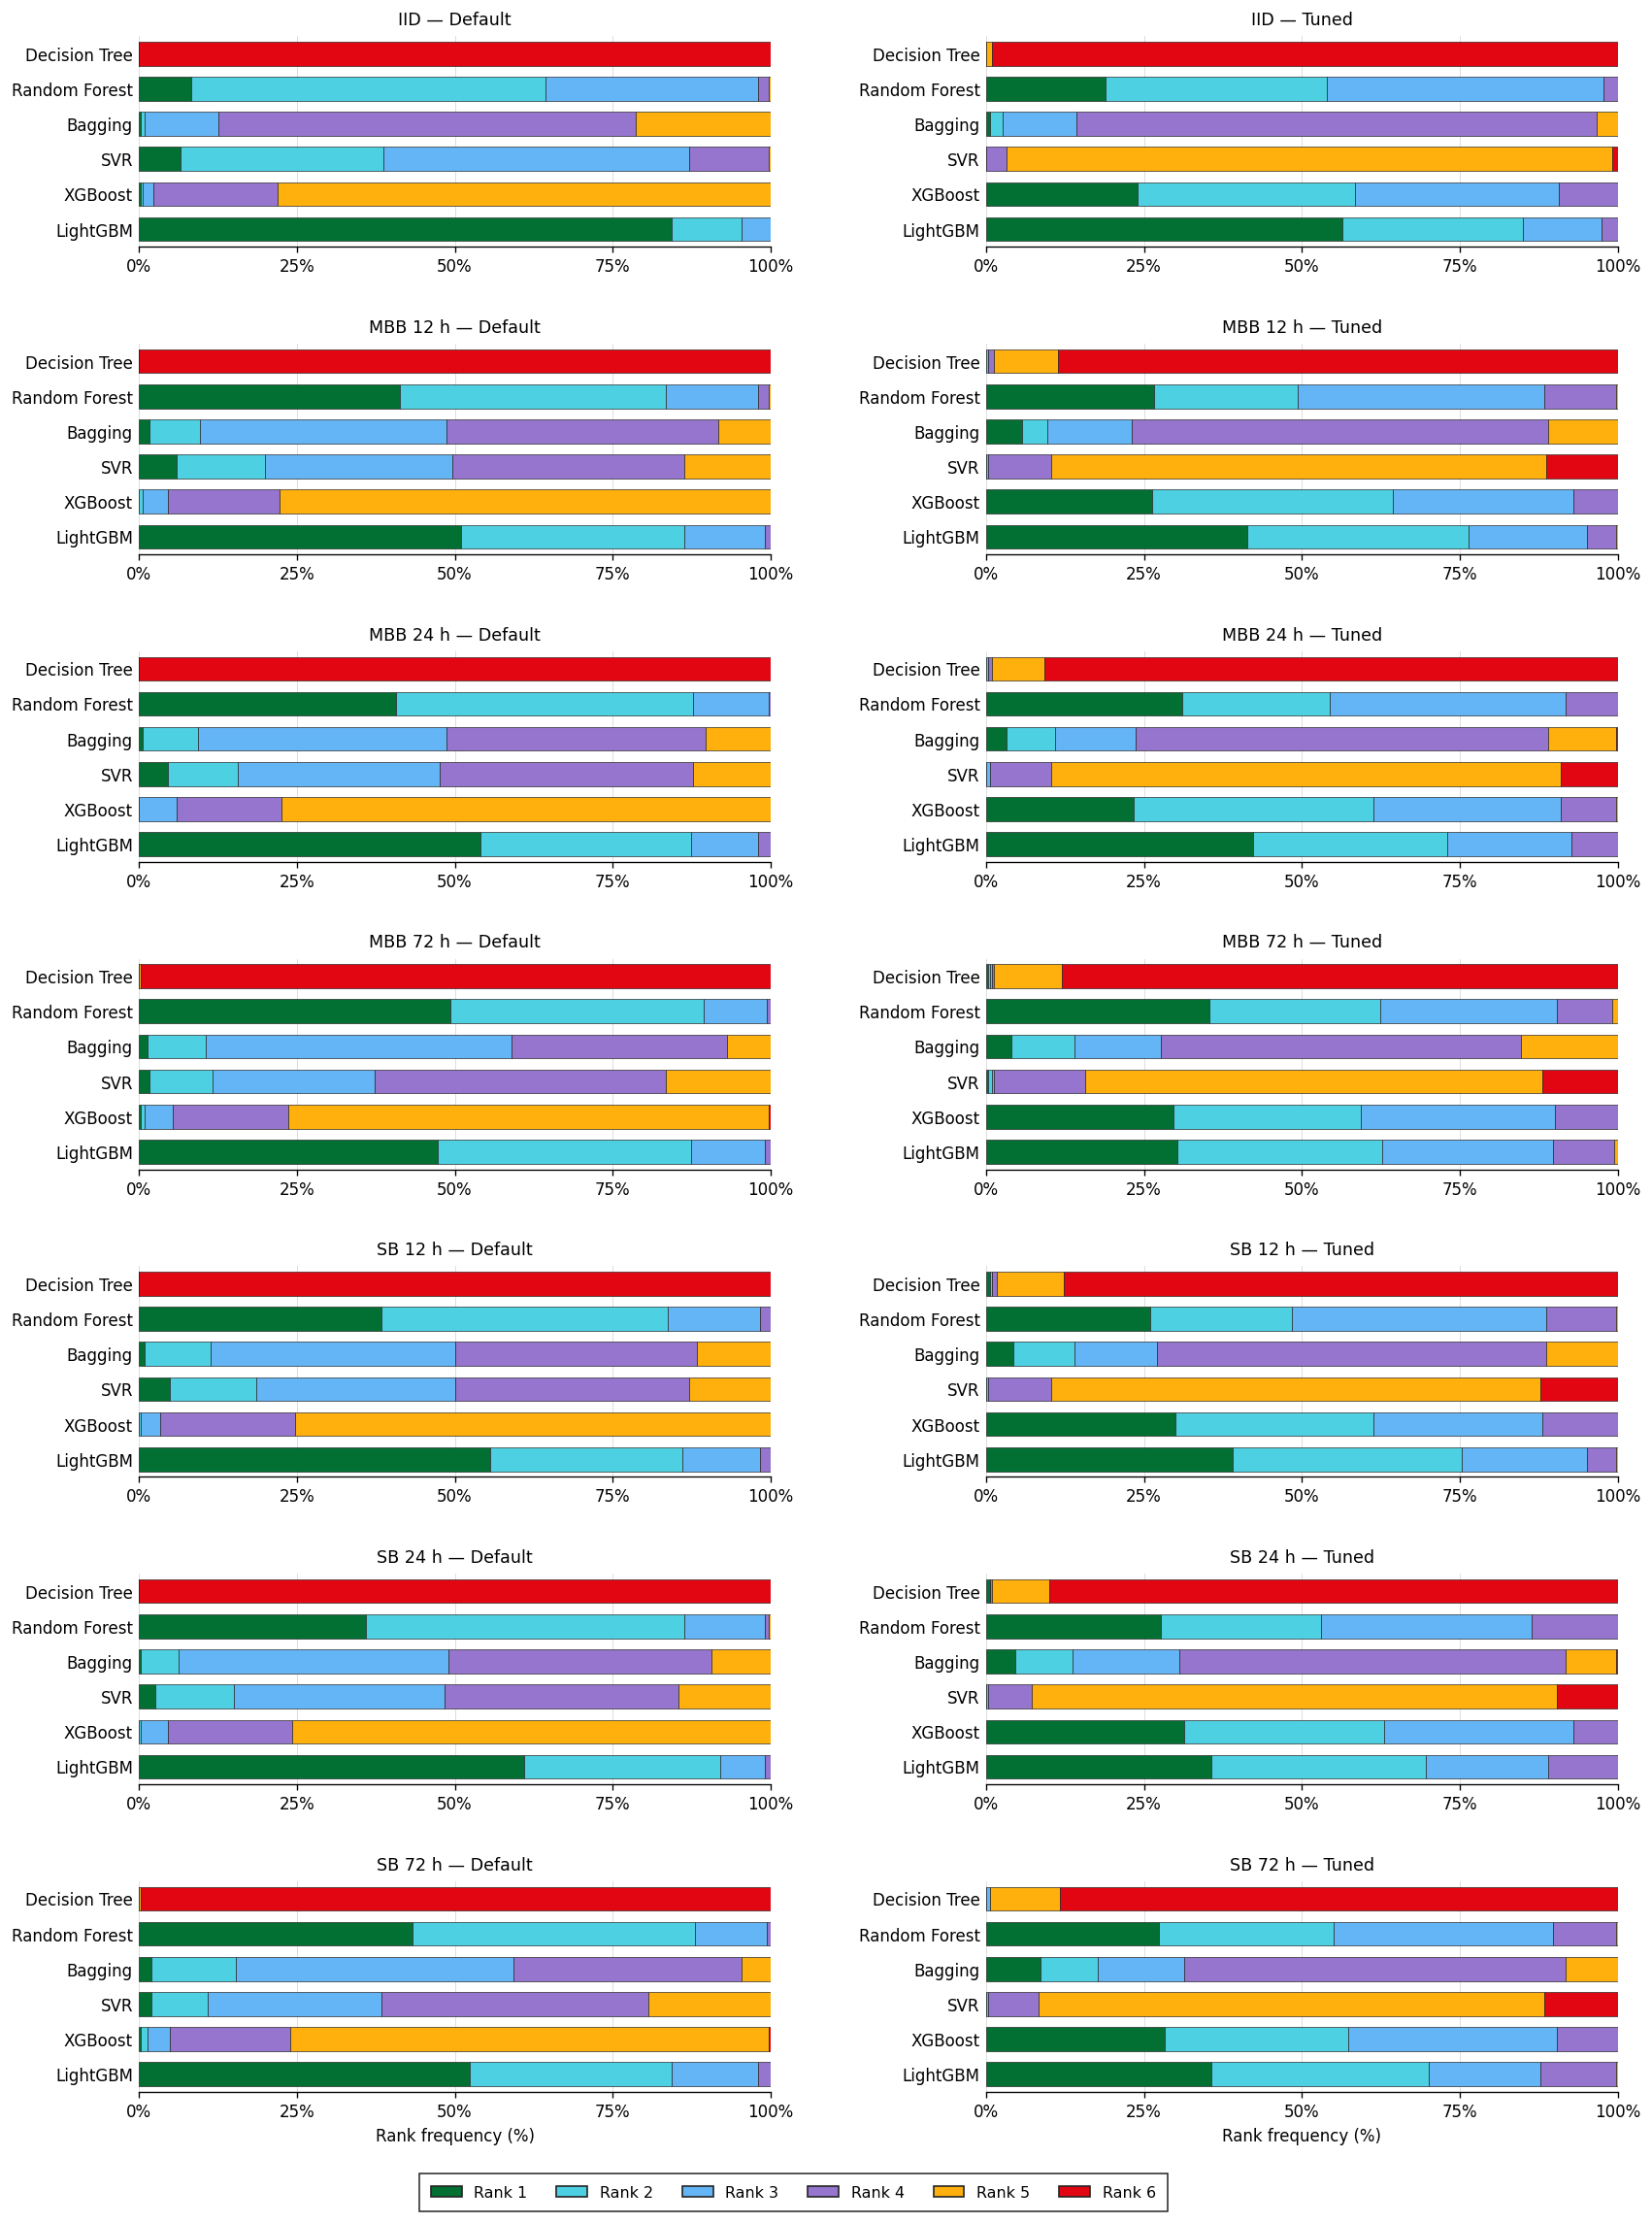

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig11_RMSE_Rank_Acceptability.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig11_RMSE_Rank_Acceptability.pdf

----------------------------------------------------------------------------
FIGURE 12 — CONSENSUS RMSE RANKING
----------------------------------------------------------------------------


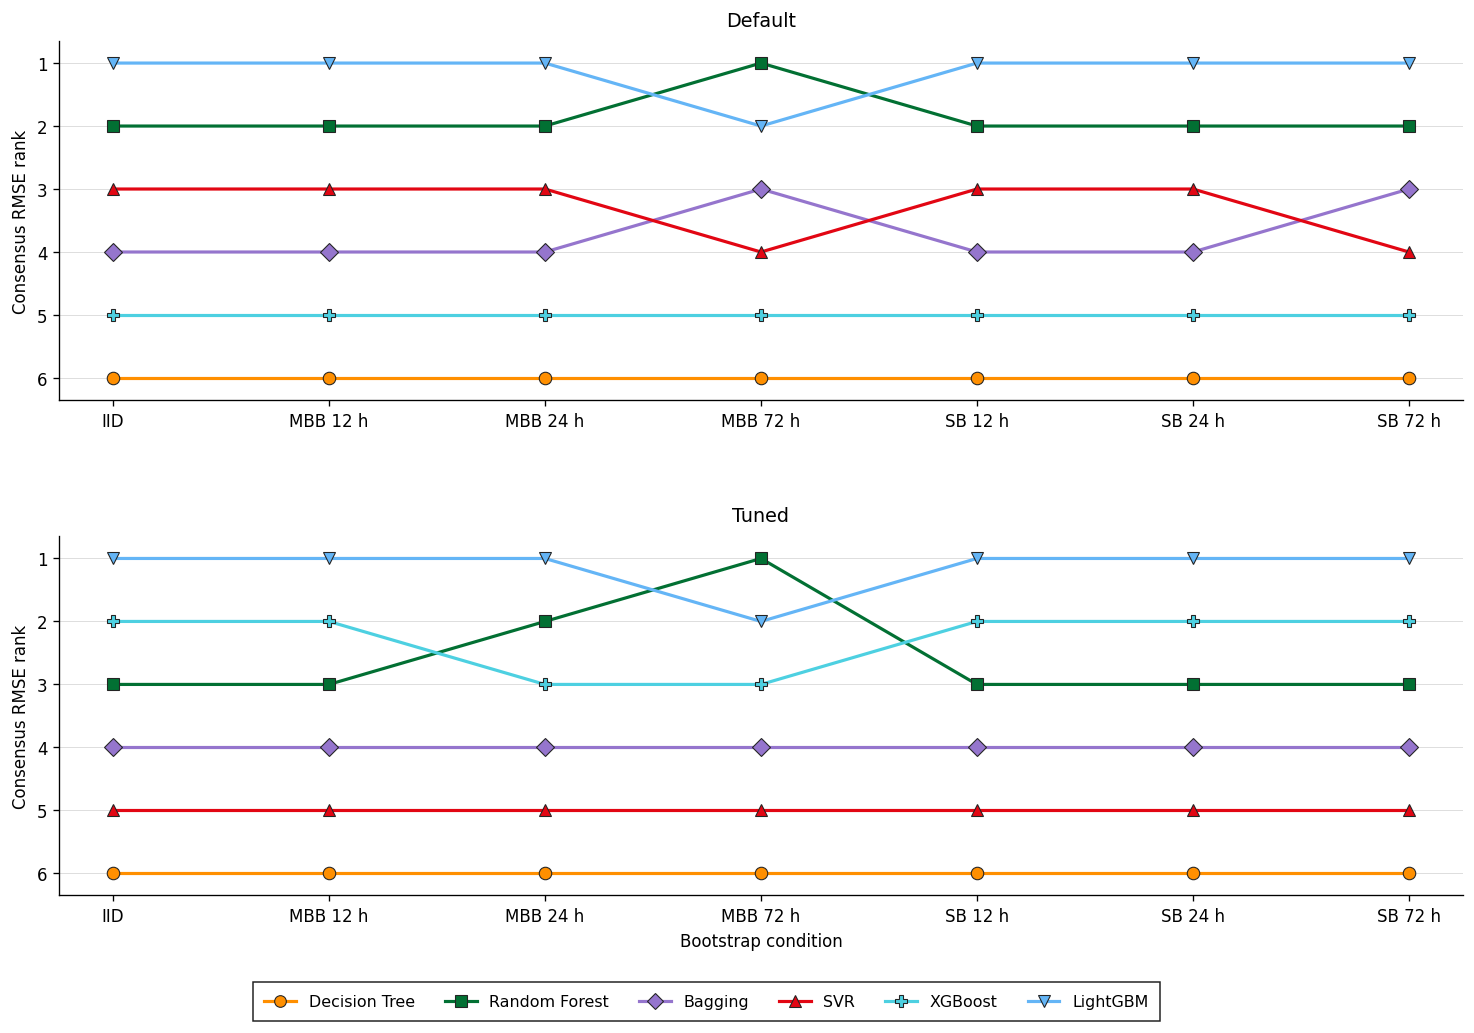

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig12_Consensus_RMSE_Ranking_Bump.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig12_Consensus_RMSE_Ranking_Bump.pdf

----------------------------------------------------------------------------
FIGURE 13 — KENDALL W — DEFAULT VS TUNED
----------------------------------------------------------------------------


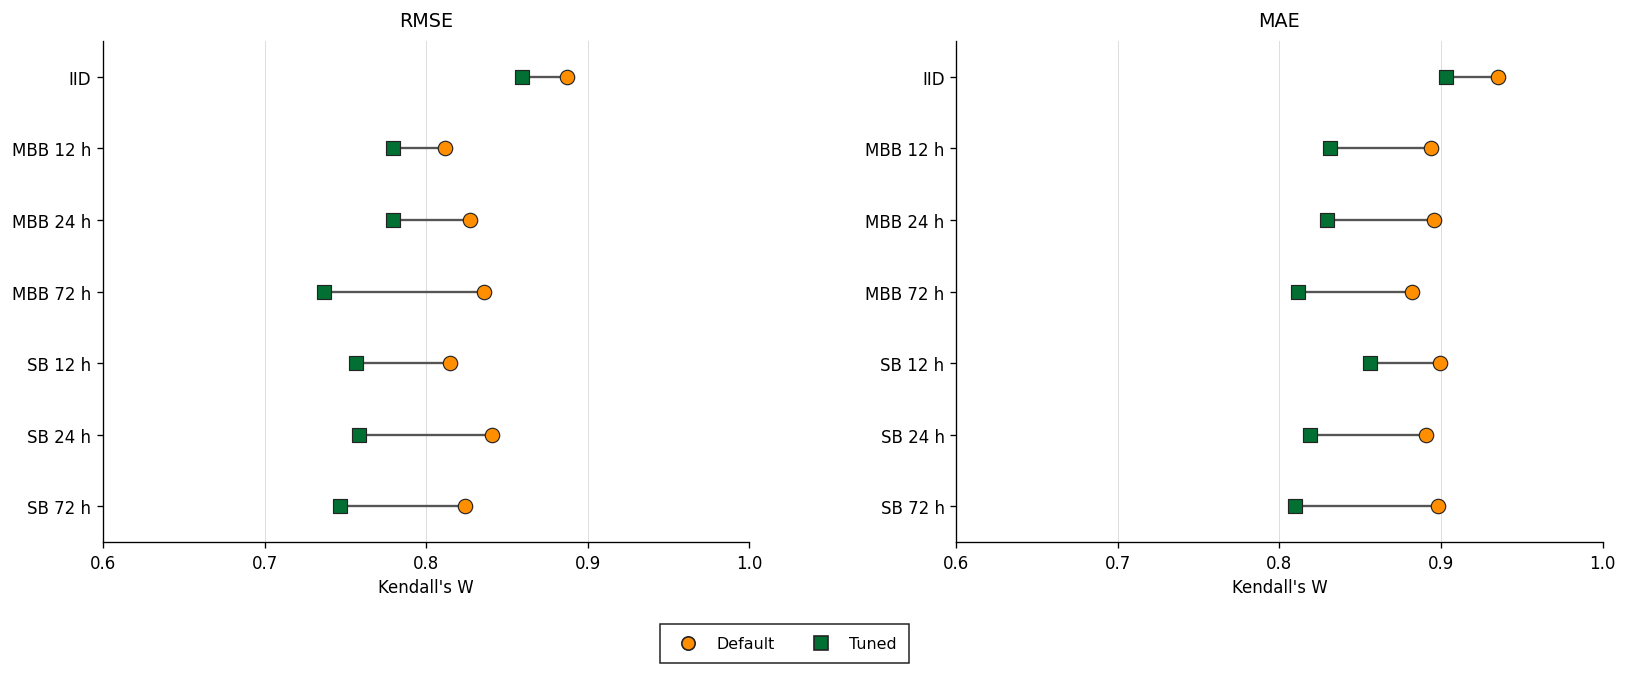

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig13_Kendall_W_Default_vs_Tuned.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig13_Kendall_W_Default_vs_Tuned.pdf

CELL 06B — RANKING VISUALIZATION COMPLETED
Notebook 03 source integrity      : PASS
Cell 06 artifact integrity        : PASS
Verified artifacts                : 6/6
CSV axis metadata normalization   : PASS
CSV numerical consistency         : PASS
CSV categorical consistency       : PASS
Rank acceptability consistency    : PASS
Kendall W consistency             : PASS

Figure 11 — Rank acceptability    : PASS
Figure 12 — Consensus bump chart  : PASS
Figure 13 — Kendall W dumbbell    : PASS

Approved categorical colors       : PASS
Gradient colors                   : NO
Figure suptitles                  : NO
Figure footnotes                  : NO
Source DataFrames modified        : NO
Model ranking recomputed          : NO
Model refitting     

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 06B
# MODEL RANKING STABILITY VISUALIZATION
# FINAL APPROVED DESIGN — FIXED VERSION
#
# Figure 11 : Rank acceptability plot
# Figure 12 : Consensus ranking bump chart
# Figure 13 : Kendall's W dumbbell plot
#
# Source:
# Notebook 03 — Cumulative B=300
# Notebook 04 — Cell 06 Model Ranking Stability Analysis
#
# FIX:
# Normalize DataFrame axis metadata during CSV verification.
# All numerical and categorical integrity checks are preserved.
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required06b = [
    "df_replication_ranks06",
    "df_rank_summary06",
    "df_rank_concordance06",
    "df_pairwise_superiority06",
    "df_cross_condition_rank06",
    "df_w_comparison06",
    "bootstrap_manifest",
    "METRICS_PATH",
    "TABLE_DIR",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR",
    "ALGORITHMS06",
    "CONDITIONS06",
    "SETTINGS06",
    "METRICS06"
]

missing06b = [
    name for name in required06b
    if name not in globals()
]

if missing06b:
    raise RuntimeError(
        "Run Notebook 04 through Cell 06 first. "
        f"Missing objects: {missing06b}"
    )


def ensure06b(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file06b(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

for directory in [
    TABLE_DIR,
    FIGURE_DIR,
    AUDIT_OUTPUT_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# =============================================================================
# 2. VERIFY NOTEBOOK 03 AND CELL 06 ARTIFACTS
# =============================================================================

print("=" * 76)
print("CELL 06B — MODEL RANKING STABILITY VISUALIZATION")
print("=" * 76)

print("\nA. SOURCE AND ARTIFACT VERIFICATION")

CELL06_AUDIT_PATH06B = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell06_model_ranking_stability_audit.json"
)

ensure06b(
    CELL06_AUDIT_PATH06B.is_file(),
    "Cell 06 audit artifact missing."
)

with open(
    CELL06_AUDIT_PATH06B,
    "r",
    encoding="utf-8"
) as handle:

    cell06_audit06b = json.load(handle)


SOURCE_HASH06B = sha256_file06b(
    METRICS_PATH
)

ensure06b(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False
    and bootstrap_manifest["hyperparameters_retuned"] is False,
    "Notebook 03 completion manifest mismatch."
)

ensure06b(
    SOURCE_HASH06B
    == bootstrap_manifest["outputs"]["metrics_sha256"]
    == cell06_audit06b["source_metrics_sha256"],
    "Frozen source checksum mismatch."
)

ensure06b(
    cell06_audit06b["status"] == "PASS"
    and cell06_audit06b["ranking_groups"] == 28
    and cell06_audit06b["replication_rank_records"] == 50400
    and cell06_audit06b["rank_summary_records"] == 168
    and cell06_audit06b["concordance_records"] == 28
    and cell06_audit06b["pairwise_superiority_records"] == 420
    and cell06_audit06b["cross_condition_agreement_records"] == 84
    and cell06_audit06b["default_tuned_concordance_records"] == 14
    and cell06_audit06b["test_accessed"] is False,
    "Cell 06 audit dimensions mismatch."
)


ARTIFACT_BINDINGS06B = {

    "replication_ranks":
        df_replication_ranks06,

    "rank_summary":
        df_rank_summary06,

    "rank_concordance":
        df_rank_concordance06,

    "pairwise_superiority":
        df_pairwise_superiority06,

    "cross_condition_agreement":
        df_cross_condition_rank06,

    "default_tuned_concordance":
        df_w_comparison06
}


VERIFIED_ARTIFACTS06B = []


# -----------------------------------------------------------------------------
# FIXED ARTIFACT VERIFICATION
#
# Pandas pivot() may preserve the column-axis name "setting".
# CSV serialization does not retain this axis metadata.
#
# Normalize axis names on temporary comparison objects only.
#
# Original DataFrames remain unchanged.
# Column labels, column order, values, checksums, and numerical
# tolerances are still strictly verified.
# -----------------------------------------------------------------------------

def normalize_for_csv_comparison06b(dataframe):

    return (
        dataframe
        .reset_index(drop=True)
        .rename_axis(
            index=None,
            columns=None
        )
    )


for artifact, dataframe in ARTIFACT_BINDINGS06B.items():

    metadata = cell06_audit06b["outputs"][artifact]

    artifact_path = Path(
        metadata["path"]
    )

    ensure06b(
        artifact_path.is_file(),
        f"Missing artifact: {artifact}"
    )

    actual_hash = sha256_file06b(
        artifact_path
    )

    ensure06b(
        actual_hash == metadata["sha256"],
        f"Artifact checksum mismatch: {artifact}"
    )

    saved = pd.read_csv(
        artifact_path,
        low_memory=False
    )

    ensure06b(
        len(saved) == metadata["rows"] == len(dataframe),
        f"Artifact row count mismatch: {artifact}"
    )

    # FIX:
    # Ignore CSV-incompatible axis-name metadata,
    # while preserving all content comparisons.

    memory_comparison = (
        normalize_for_csv_comparison06b(
            dataframe
        )
    )

    saved_comparison = (
        normalize_for_csv_comparison06b(
            saved
        )
    )

    try:

        pd.testing.assert_frame_equal(

            memory_comparison,
            saved_comparison,

            check_dtype=False,
            check_exact=False,

            rtol=1e-10,
            atol=1e-10
        )

    except AssertionError as exc:

        raise AssertionError(
            f"Artifact content verification failed: "
            f"{artifact}\n{exc}"
        ) from exc

    VERIFIED_ARTIFACTS06B.append({

        "artifact": artifact,

        "path": str(artifact_path),

        "rows": int(len(saved)),

        "sha256": actual_hash,

        "content_verified": True,

        "axis_metadata_normalized": True
    })

    print(
        f"{artifact:<30} | "
        f"rows={len(saved):>6} | PASS"
    )


ensure06b(
    len(VERIFIED_ARTIFACTS06B) == 6,
    "Incomplete Cell 06 artifact verification."
)

print("\nSource checksum: VERIFIED")
print("Cell 06 artifact checksums: VERIFIED")
print("CSV content consistency: VERIFIED")
print("DataFrame axis metadata: NORMALIZED")


# =============================================================================
# 3. EXPERIMENT DEFINITIONS
# =============================================================================

ALGORITHMS06B = list(ALGORITHMS06)
CONDITIONS06B = list(CONDITIONS06)
SETTINGS06B = list(SETTINGS06)
METRICS06B = list(METRICS06)

ensure06b(
    ALGORITHMS06B == [
        "Decision Tree",
        "Random Forest",
        "Bagging",
        "SVR",
        "XGBoost",
        "LightGBM"
    ]
    and CONDITIONS06B == [
        "iid",
        "mbb_L0072",
        "mbb_L0144",
        "mbb_L0432",
        "stationary_L0072",
        "stationary_L0144",
        "stationary_L0432"
    ]
    and SETTINGS06B == ["default", "tuned"]
    and METRICS06B == ["rmse_wh", "mae_wh"],
    "Frozen experiment design mismatch."
)


CONDITION_LABELS06B = {

    "iid": "IID",

    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",

    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}


METRIC_LABELS06B = {

    "rmse_wh": "RMSE",

    "mae_wh": "MAE"
}


SETTING_LABELS06B = {

    "default": "Default",

    "tuned": "Tuned"
}


# =============================================================================
# 4. APPROVED CATEGORICAL COLOR PALETTE
# =============================================================================

PALETTE06B = {

    "red": "#E20613",

    "yellow": "#FFB00C",

    "orange": "#FF8F00",

    "dark_green": "#027033",

    "turquoise": "#4DD0E1",

    "light_blue": "#64B5F6",

    "purple": "#9575CD"
}


# -----------------------------------------------------------------------------
# Figure 11 — Rank position colors
# Solid categorical colors, no gradient.
# -----------------------------------------------------------------------------

RANK_COLORS06B = {

    1: PALETTE06B["dark_green"],

    2: PALETTE06B["turquoise"],

    3: PALETTE06B["light_blue"],

    4: PALETTE06B["purple"],

    5: PALETTE06B["yellow"],

    6: PALETTE06B["red"]
}


# -----------------------------------------------------------------------------
# Figure 12 — Algorithm colors and markers
# -----------------------------------------------------------------------------

ALGORITHM_STYLES06B = {

    "Decision Tree": (
        PALETTE06B["orange"], "o"
    ),

    "Random Forest": (
        PALETTE06B["dark_green"], "s"
    ),

    "Bagging": (
        PALETTE06B["purple"], "D"
    ),

    "SVR": (
        PALETTE06B["red"], "^"
    ),

    "XGBoost": (
        PALETTE06B["turquoise"], "P"
    ),

    "LightGBM": (
        PALETTE06B["light_blue"], "v"
    )
}


# -----------------------------------------------------------------------------
# Figure 13 — Model configuration colors and markers
# -----------------------------------------------------------------------------

SETTING_STYLES06B = {

    "default": (
        PALETTE06B["orange"], "o"
    ),

    "tuned": (
        PALETTE06B["dark_green"], "s"
    )
}


# =============================================================================
# 5. VERIFY RANKING SUMMARY
# =============================================================================

RANK_KEYS06B = [
    "condition",
    "setting",
    "metric",
    "algorithm"
]

ensure06b(
    len(df_rank_summary06) == 168
    and not df_rank_summary06.duplicated(
        RANK_KEYS06B
    ).any(),
    "Invalid ranking summary dimensions."
)

EXPECTED_KEYS06B = {

    (condition, setting, metric, algorithm)

    for condition in CONDITIONS06B
    for setting in SETTINGS06B
    for metric in METRICS06B
    for algorithm in ALGORITHMS06B
}

OBSERVED_KEYS06B = set(

    df_rank_summary06[RANK_KEYS06B]

    .itertuples(
        index=False,
        name=None
    )
)

ensure06b(
    EXPECTED_KEYS06B == OBSERVED_KEYS06B,
    "Incomplete ranking summary design."
)

ensure06b(
    df_rank_summary06["n_replications"].eq(300).all(),
    "Unexpected number of bootstrap replications."
)


RANK_PROBABILITY_COLS06B = [

    f"rank{k}_probability_pct"

    for k in range(1, 7)
]


rank_probabilities06b = (

    df_rank_summary06[RANK_PROBABILITY_COLS06B]

    .to_numpy(dtype=float)
)

ensure06b(
    np.isfinite(rank_probabilities06b).all()
    and np.all(rank_probabilities06b >= 0)
    and np.all(rank_probabilities06b <= 100),
    "Invalid rank acceptability percentages."
)

ensure06b(
    np.allclose(
        rank_probabilities06b.sum(axis=1),
        100,
        atol=1e-10
    ),
    "Rank acceptability percentages do not sum to 100."
)

ensure06b(
    np.allclose(

        df_rank_summary06.groupby(
            ["condition", "setting", "metric"]
        )[RANK_PROBABILITY_COLS06B]

        .sum()
        .to_numpy(),

        100,

        atol=1e-10
    ),
    "Rank position totals are inconsistent."
)


# Verify that weighted rank probabilities
# reproduce the expected ranks from Cell 06.

ensure06b(
    np.allclose(

        (
            rank_probabilities06b
            @ np.arange(1, 7)
        ) / 100,

        df_rank_summary06["expected_rank"],

        rtol=1e-10,
        atol=1e-10
    ),
    "Rank acceptability and expected rank disagree."
)


RANK_LOOKUP06B = (

    df_rank_summary06

    .set_index(RANK_KEYS06B)
)


def get_rank06b(
    condition,
    setting,
    metric,
    algorithm,
    statistic
):

    return float(

        RANK_LOOKUP06B.loc[

            (
                condition,
                setting,
                metric,
                algorithm
            ),

            statistic
        ]
    )


# =============================================================================
# 6. VERIFY KENDALL'S W RESULTS
# =============================================================================

ensure06b(
    len(df_w_comparison06) == 14
    and not df_w_comparison06.duplicated(
        ["condition", "metric"]
    ).any(),
    "Incomplete Kendall W comparisons."
)


EXPECTED_W_KEYS06B = {

    (condition, metric)

    for condition in CONDITIONS06B
    for metric in METRICS06B
}


ensure06b(
    set(

        df_w_comparison06[
            ["condition", "metric"]
        ].itertuples(
            index=False,
            name=None
        )

    ) == EXPECTED_W_KEYS06B,
    "Unexpected Kendall W comparison groups."
)


w_values06b = (

    df_w_comparison06[
        ["kendall_w_default", "kendall_w_tuned"]
    ]

    .to_numpy(dtype=float)
)


ensure06b(
    np.isfinite(w_values06b).all()
    and np.all(w_values06b >= 0)
    and np.all(w_values06b <= 1),
    "Kendall W outside its theoretical range."
)


ensure06b(
    np.allclose(

        df_w_comparison06["kendall_w_tuned"]
        - df_w_comparison06["kendall_w_default"],

        df_w_comparison06["delta_kendall_w"],

        rtol=1e-10,
        atol=1e-10
    ),
    "Kendall W difference identity failed."
)

print("\nRank acceptability consistency: PASS")
print("Kendall W consistency: PASS")


# =============================================================================
# 7. APPROVED PUBLICATION STYLE
# =============================================================================

STYLE06B = {

    "font.family": "DejaVu Sans",

    "font.size": 10,

    "font.weight": "normal",

    "axes.titleweight": "normal",

    "axes.labelweight": "normal",

    "axes.labelcolor": "#000000",

    "text.color": "#000000",

    "xtick.color": "#000000",

    "ytick.color": "#000000",

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "pdf.fonttype": 42,

    "ps.fonttype": 42
}


def clean_axis06b(
    ax,
    grid_axis="x"
):

    ax.grid(

        axis=grid_axis,

        color="#DEDEDE",

        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)

    ax.spines["right"].set_visible(False)


def boxed_legend06b(
    fig,
    handles,
    ncol,
    y=0.025
):

    legend = fig.legend(

        handles=handles,

        ncol=ncol,

        loc="lower center",

        bbox_to_anchor=(0.5, y),

        frameon=True,

        fancybox=False,

        framealpha=1.0,

        facecolor="white",

        edgecolor="#202020",

        borderpad=0.75,

        columnspacing=1.9,

        fontsize=9.5
    )

    legend.get_frame().set_linewidth(0.9)

    return legend


def export_figure06b(
    fig,
    number,
    filename,
    description
):

    stem = FIGURE_DIR / filename

    png_path = stem.with_suffix(".png")

    pdf_path = stem.with_suffix(".pdf")

    fig.savefig(

        png_path,

        dpi=300,

        bbox_inches="tight",

        pad_inches=0.10,

        facecolor="white"
    )

    fig.savefig(

        pdf_path,

        bbox_inches="tight",

        pad_inches=0.10,

        facecolor="white"
    )

    ensure06b(
        png_path.is_file()
        and pdf_path.is_file()
        and png_path.stat().st_size > 0
        and pdf_path.stat().st_size > 0,
        f"Figure {number} export failed."
    )

    plt.show()

    plt.close(fig)

    return {

        "figure_number": number,

        "description": description,

        "png": str(png_path),

        "pdf": str(pdf_path),

        "png_sha256": sha256_file06b(png_path),

        "pdf_sha256": sha256_file06b(pdf_path)
    }


# =============================================================================
# 8. FIGURE 11 — RANK ACCEPTABILITY PLOT
#
# Seven bootstrap conditions x two model settings.
#
# Each horizontal bar represents the empirical probability
# distribution across rank positions 1–6.
#
# Each bar sums to 100%.
#
# Primary metric: RMSE.
# =============================================================================

def make_figure11():

    with plt.rc_context(STYLE06B):

        fig, axes = plt.subplots(

            nrows=7,

            ncols=2,

            figsize=(14.6, 19.5),

            sharex=True,

            sharey=True
        )

        y = np.arange(
            len(ALGORITHMS06B)
        )

        plotted_groups = 0

        for i, condition in enumerate(
            CONDITIONS06B
        ):

            for j, setting in enumerate(
                SETTINGS06B
            ):

                ax = axes[i, j]

                left = np.zeros(
                    len(ALGORITHMS06B)
                )

                for rank_position in range(1, 7):

                    percentages = np.array([

                        get_rank06b(

                            condition,

                            setting,

                            "rmse_wh",

                            algorithm,

                            f"rank{rank_position}_probability_pct"
                        )

                        for algorithm in ALGORITHMS06B
                    ])

                    ax.barh(

                        y,

                        percentages,

                        left=left,

                        height=0.68,

                        color=RANK_COLORS06B[
                            rank_position
                        ],

                        edgecolor="#242424",

                        linewidth=0.40,

                        zorder=3
                    )

                    left += percentages

                ensure06b(
                    np.allclose(
                        left,
                        100,
                        atol=1e-10
                    ),
                    "Figure 11 bar proportions mismatch."
                )

                ax.set_yticks(

                    y,

                    ALGORITHMS06B
                )

                ax.tick_params(

                    axis="y",

                    labelleft=True,

                    length=0
                )

                # Keep rank acceptability panel
                # orientation consistent.

                ax.set_ylim(

                    len(ALGORITHMS06B) - 0.5,

                    -0.5
                )

                ax.set_xlim(0, 100)

                ax.set_xticks([

                    0,

                    25,

                    50,

                    75,

                    100
                ])

                ax.xaxis.set_major_formatter(

                    PercentFormatter(

                        100,

                        decimals=0
                    )
                )

                ax.tick_params(

                    axis="x",

                    labelbottom=True
                )

                ax.set_title(

                    f"{CONDITION_LABELS06B[condition]}"
                    f" — {SETTING_LABELS06B[setting]}",

                    fontsize=10.5,

                    fontweight="normal",

                    pad=7
                )

                if i == len(CONDITIONS06B) - 1:

                    ax.set_xlabel(
                        "Rank frequency (%)"
                    )

                ax.spines["left"].set_visible(False)

                clean_axis06b(

                    ax,

                    grid_axis="x"
                )

                plotted_groups += 1

        ensure06b(
            plotted_groups == 14,
            "Incomplete Figure 11 panel coverage."
        )

        handles = [

            Patch(

                facecolor=RANK_COLORS06B[k],

                edgecolor="#242424",

                label=f"Rank {k}"
            )

            for k in range(1, 7)
        ]

        boxed_legend06b(

            fig,

            handles,

            ncol=6,

            y=0.014
        )

        fig.subplots_adjust(

            left=0.115,

            right=0.985,

            top=0.975,

            bottom=0.070,

            wspace=0.34,

            hspace=0.46
        )

        return export_figure06b(

            fig=fig,

            number=11,

            filename=(
                "NB04_Fig11_RMSE_Rank_Acceptability"
            ),

            description=(
                "Empirical RMSE rank acceptability distributions"
            )
        )


# =============================================================================
# 9. FIGURE 12 — CONSENSUS RANKING BUMP CHART
#
# Consensus rank is the rank of expected replication rank.
#
# This differs from:
# - Individual replication rank
# - Expected rank itself
# - Rank based on mean RMSE
#
# Two panels: Default and Tuned.
# Rank 1 is positioned at the top.
# =============================================================================

def make_figure12():

    with plt.rc_context(STYLE06B):

        fig, axes = plt.subplots(

            nrows=2,

            ncols=1,

            figsize=(13.0, 8.9),

            sharex=True,

            sharey=True
        )

        x = np.arange(
            len(CONDITIONS06B)
        )

        plotted_values = []

        for ax, setting in zip(
            axes,
            SETTINGS06B
        ):

            for algorithm in ALGORITHMS06B:

                color, marker = (

                    ALGORITHM_STYLES06B[
                        algorithm
                    ]
                )

                consensus_ranks = [

                    get_rank06b(

                        condition,

                        setting,

                        "rmse_wh",

                        algorithm,

                        "consensus_rank"
                    )

                    for condition in CONDITIONS06B
                ]

                ensure06b(
                    min(consensus_ranks) >= 1
                    and max(consensus_ranks) <= 6,
                    "Invalid consensus ranking."
                )

                plotted_values.extend(
                    consensus_ranks
                )

                ax.plot(

                    x,

                    consensus_ranks,

                    color=color,

                    marker=marker,

                    markersize=7.5,

                    markeredgecolor="#242424",

                    markeredgewidth=0.65,

                    linewidth=1.9,

                    zorder=3
                )

            ax.set_yticks(
                np.arange(1, 7)
            )

            ax.set_ylim(

                6.35,

                0.65
            )

            ax.set_xlim(

                -0.25,

                len(CONDITIONS06B) - 0.75
            )

            ax.set_xticks(

                x,

                [

                    CONDITION_LABELS06B[condition]

                    for condition in CONDITIONS06B
                ]
            )

            ax.tick_params(

                axis="x",

                labelbottom=True
            )

            ax.set_ylabel(
                "Consensus RMSE rank"
            )

            ax.set_title(

                SETTING_LABELS06B[setting],

                fontsize=11.5,

                fontweight="normal",

                pad=9
            )

            clean_axis06b(

                ax,

                grid_axis="y"
            )

        axes[-1].set_xlabel(
            "Bootstrap condition"
        )

        ensure06b(
            len(plotted_values) == 84,
            "Incomplete Figure 12 rank coverage."
        )

        handles = [

            Line2D(

                [0], [0],

                color=ALGORITHM_STYLES06B[
                    algorithm
                ][0],

                marker=ALGORITHM_STYLES06B[
                    algorithm
                ][1],

                markeredgecolor="#242424",

                markeredgewidth=0.65,

                markersize=7,

                linewidth=1.9,

                label=algorithm
            )

            for algorithm in ALGORITHMS06B
        ]

        boxed_legend06b(

            fig,

            handles,

            ncol=6
        )

        fig.subplots_adjust(

            left=0.085,

            right=0.985,

            top=0.95,

            bottom=0.15,

            hspace=0.38
        )

        return export_figure06b(

            fig=fig,

            number=12,

            filename=(
                "NB04_Fig12_Consensus_RMSE_Ranking_Bump"
            ),

            description=(
                "Consensus ranking across bootstrap conditions"
            )
        )


# =============================================================================
# 10. FIGURE 13 — KENDALL'S W DUMBBELL PLOT
#
# Panel A: RMSE
# Panel B: MAE
#
# Orange circle = Default
# Green square  = Tuned
#
# Connecting line represents the difference in W.
# It is NOT a confidence interval.
#
# Identical X-axis limits across both panels.
# =============================================================================

def make_figure13():

    with plt.rc_context(STYLE06B):

        fig, axes = plt.subplots(

            nrows=1,

            ncols=2,

            figsize=(14.2, 5.8),

            sharex=True,

            sharey=True
        )

        y = np.arange(
            len(CONDITIONS06B)
        )

        plotted_values = []

        for ax, metric in zip(
            axes,
            METRICS06B
        ):

            subset = (

                df_w_comparison06.loc[

                    df_w_comparison06["metric"]
                    == metric
                ]

                .set_index("condition")

                .reindex(CONDITIONS06B)
            )

            default_w = (

                subset["kendall_w_default"]

                .to_numpy(dtype=float)
            )

            tuned_w = (

                subset["kendall_w_tuned"]

                .to_numpy(dtype=float)
            )

            ensure06b(
                np.isfinite(default_w).all()
                and np.isfinite(tuned_w).all(),
                "Invalid Kendall W plot values."
            )

            plotted_values.extend(
                default_w.tolist()
            )

            plotted_values.extend(
                tuned_w.tolist()
            )

            # Connect Default and Tuned values.

            for i in range(
                len(CONDITIONS06B)
            ):

                ax.plot(

                    [
                        default_w[i],
                        tuned_w[i]
                    ],

                    [
                        y[i],
                        y[i]
                    ],

                    color="#555555",

                    linewidth=1.4,

                    zorder=2
                )

            for setting, values in [

                ("default", default_w),

                ("tuned", tuned_w)
            ]:

                color, marker = (

                    SETTING_STYLES06B[setting]
                )

                ax.scatter(

                    values,

                    y,

                    color=color,

                    marker=marker,

                    s=75,

                    edgecolor="#242424",

                    linewidth=0.7,

                    zorder=4
                )

            ax.set_yticks(

                y,

                [

                    CONDITION_LABELS06B[condition]

                    for condition in CONDITIONS06B
                ]
            )

            ax.tick_params(

                axis="y",

                labelleft=True
            )

            ax.set_ylim(

                len(CONDITIONS06B) - 0.5,

                -0.5
            )

            ax.set_xlabel(
                "Kendall's W"
            )

            ax.set_title(

                METRIC_LABELS06B[metric],

                fontsize=11.5,

                fontweight="normal",

                pad=9
            )

            clean_axis06b(

                ax,

                grid_axis="x"
            )

        ensure06b(
            len(plotted_values) == 28,
            "Incomplete Figure 13 value coverage."
        )

        # Preserve approved focused scale.
        # Prevent accidental clipping.

        ensure06b(
            min(plotted_values) >= 0.60
            and max(plotted_values) <= 1.00,
            "Kendall W values exceed approved plotting limits."
        )

        for ax in axes:

            ax.set_xlim(

                0.60,

                1.00
            )

            ax.set_xticks(

                np.arange(

                    0.60,

                    1.01,

                    0.10
                )
            )

        handles = [

            Line2D(

                [0], [0],

                marker=SETTING_STYLES06B[
                    setting
                ][1],

                markerfacecolor=SETTING_STYLES06B[
                    setting
                ][0],

                markeredgecolor="#242424",

                linestyle="None",

                markersize=8,

                label=SETTING_LABELS06B[
                    setting
                ]
            )

            for setting in SETTINGS06B
        ]

        boxed_legend06b(

            fig,

            handles,

            ncol=2
        )

        fig.subplots_adjust(

            left=0.10,

            right=0.98,

            top=0.93,

            bottom=0.21,

            wspace=0.32
        )

        return export_figure06b(

            fig=fig,

            number=13,

            filename=(
                "NB04_Fig13_Kendall_W_Default_vs_Tuned"
            ),

            description=(
                "Default–Tuned ranking concordance comparison"
            )
        )


# =============================================================================
# 11. GENERATE APPROVED FIGURES
# =============================================================================

print("\n" + "=" * 76)

print("B. GENERATE APPROVED RANKING FIGURES")

print("=" * 76)

print("Source: Notebook 04 — Cell 06")

print("Original fitting records: 25200")

print("Replication-level ranking records: 50400")

print("Ranking groups: 28")

print("Replications per group: 300")


FIGURE_OUTPUTS06B = []


FIGURE_FUNCTIONS06B = [

    (
        11,

        "RMSE RANK ACCEPTABILITY",

        make_figure11
    ),

    (
        12,

        "CONSENSUS RMSE RANKING",

        make_figure12
    ),

    (
        13,

        "KENDALL W — DEFAULT VS TUNED",

        make_figure13
    )
]


for number, description, function in FIGURE_FUNCTIONS06B:

    print("\n" + "-" * 76)

    print(
        f"FIGURE {number:02d} — {description}"
    )

    print("-" * 76)

    result = function()

    FIGURE_OUTPUTS06B.append(result)

    print("PNG:", result["png"])

    print("PDF:", result["pdf"])


# =============================================================================
# 12. VERIFY FIGURE EXPORTS
# =============================================================================

ensure06b(
    len(FIGURE_OUTPUTS06B) == 3
    and {

        item["figure_number"]

        for item in FIGURE_OUTPUTS06B

    } == {11, 12, 13},

    "Incomplete approved figure outputs."
)


for item in FIGURE_OUTPUTS06B:

    ensure06b(

        sha256_file06b(item["png"])
        == item["png_sha256"],

        "PNG checksum verification failed."
    )

    ensure06b(

        sha256_file06b(item["pdf"])
        == item["pdf_sha256"],

        "PDF checksum verification failed."
    )


# =============================================================================
# 13. REPRODUCIBILITY AUDIT
# =============================================================================

VISUAL_AUDIT06B = {

    "notebook": "04",

    "cell": "06B",

    "status": "PASS",

    "visualization_version": (
        "approved_rank_acceptability_bump_dumbbell_v1_fixed"
    ),

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 Cell 06"
    ),

    "source_metrics_sha256": SOURCE_HASH06B,

    "source_cell06_audit_sha256": sha256_file06b(

        CELL06_AUDIT_PATH06B
    ),

    "artifact_verification": {

        "verified_artifacts": len(
            VERIFIED_ARTIFACTS06B
        ),

        "axis_metadata_normalized": True,

        "normalization_scope": (
            "Temporary CSV comparison DataFrames only"
        ),

        "column_labels_verified": True,

        "column_order_verified": True,

        "numerical_values_verified": True,

        "categorical_values_verified": True,

        "check_dtype": False,

        "check_exact": False,

        "rtol": 1e-10,

        "atol": 1e-10,

        "source_dataframes_modified": False,

        "artifacts": VERIFIED_ARTIFACTS06B
    },

    "original_fitting_records": 25200,

    "replication_rank_records": 50400,

    "ranking_groups": 28,

    "replications_per_group": 300,

    "figure_count": 3,

    "figure11": {

        "type": "100% stacked horizontal bar chart",

        "metric": "rmse_wh",

        "statistic": "Rank acceptability",

        "panels": 14,

        "algorithms_per_panel": 6,

        "rank_positions": 6,

        "bars": 84,

        "fractional_tie_credits_preserved": True,

        "x_axis_limits_pct": [0, 100],

        "default_tuned_in_same_figure": True
    },

    "figure12": {

        "type": "Bump chart",

        "metric": "rmse_wh",

        "statistic": "consensus_rank",

        "consensus_definition": (
            "Rank of expected replication-level rank"
        ),

        "panels": 2,

        "algorithms_per_panel": 6,

        "plotted_rank_values": 84,

        "rank1_at_top": True,

        "interpolated_experiments": False
    },

    "figure13": {

        "type": "Dumbbell plot",

        "metrics": METRICS06B,

        "statistic": "kendall_w",

        "panels": 2,

        "conditions_per_panel": 7,

        "plotted_w_values": 28,

        "common_x_axis": True,

        "x_axis_limits": [0.60, 1.00],

        "connecting_lines_are_confidence_intervals": False
    },

    "rank_colors": {

        str(k): color

        for k, color in RANK_COLORS06B.items()
    },

    "algorithm_styles": ALGORITHM_STYLES06B,

    "setting_styles": SETTING_STYLES06B,

    "gradient": False,

    "figure_suptitles": False,

    "figure_footnotes": False,

    "legend_position": "Below complete figure",

    "legend_boxed": True,

    "source_data_modified": False,

    "outliers_removed": False,

    "model_ranking_recomputed": False,

    "model_refitting": False,

    "hyperparameter_retuning": False,

    "new_bootstrap": False,

    "final_model_selected": False,

    "test_accessed": False,

    "figures": FIGURE_OUTPUTS06B
}


VISUAL_AUDIT_PATH06B = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell06B_ranking_visualization_audit.json"
)


temporary06b = VISUAL_AUDIT_PATH06B.with_name(

    VISUAL_AUDIT_PATH06B.name + ".temporary"
)


with open(

    temporary06b,

    "w",

    encoding="utf-8"

) as handle:

    json.dump(

        VISUAL_AUDIT06B,

        handle,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    )


os.replace(

    temporary06b,

    VISUAL_AUDIT_PATH06B
)


# =============================================================================
# 14. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 06B — RANKING VISUALIZATION COMPLETED")

print("=" * 76)

print("Notebook 03 source integrity      : PASS")

print("Cell 06 artifact integrity        : PASS")

print("Verified artifacts                : 6/6")

print("CSV axis metadata normalization   : PASS")

print("CSV numerical consistency         : PASS")

print("CSV categorical consistency       : PASS")

print("Rank acceptability consistency    : PASS")

print("Kendall W consistency             : PASS")

print("\nFigure 11 — Rank acceptability    : PASS")

print("Figure 12 — Consensus bump chart  : PASS")

print("Figure 13 — Kendall W dumbbell    : PASS")

print("\nApproved categorical colors       : PASS")

print("Gradient colors                   : NO")

print("Figure suptitles                  : NO")

print("Figure footnotes                  : NO")

print("Source DataFrames modified        : NO")

print("Model ranking recomputed          : NO")

print("Model refitting                   : NO")

print("Hyperparameter retuning           : NO")

print("New bootstrap                     : NO")

print("Final model selected              : NO")

print("Test accessed                     : NO")


print("\nSAVED FIGURES")

for item in FIGURE_OUTPUTS06B:

    print(
        f"\nFigure {item['figure_number']:02d}"
    )

    print("PNG:", item["png"])

    print("PDF:", item["pdf"])


print("\nAUDIT")

print(VISUAL_AUDIT_PATH06B)

print("\nFINAL STATUS: PASS")


# 07 — Bootstrap Replication Convergence Analysis

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 07
# BOOTSTRAP REPLICATION CONVERGENCE ANALYSIS
#
# Cumulative bootstrap sizes:
# B = 30, 100, 300
#
# Analysis:
# 1. Nested bootstrap experiment integrity
# 2. Mean predictive error convergence
# 3. Predictive error dispersion convergence
# 4. Upper-tail error convergence
# 5. Ranking stability convergence
# 6. Model leader consistency
#
# Primary metric   : RMSE (Wh)
# Supporting metric: MAE (Wh)
#
# B300 is the largest available empirical reference,
# NOT the true population value.
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import rankdata, kendalltau
from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK OBJECTS
# =============================================================================

required07 = [
    "PROJECT_ROOT",
    "METRICS_PATH",
    "AUDIT_PATH",
    "TABLE_DIR",
    "AUDIT_OUTPUT_DIR",
    "bootstrap_manifest",
    "df_metrics",
    "df_replication_audit",
    "df_stability_summary04",
    "df_replication_ranks06",
    "df_rank_summary06",
    "df_rank_concordance06",
    "ALGORITHMS06",
    "CONDITIONS06",
    "SETTINGS06",
    "METRICS06"
]

missing07 = [
    name for name in required07
    if name not in globals()
]

if missing07:
    raise RuntimeError(
        "Run Notebook 04 through Cell 06B first. "
        f"Missing objects: {missing07}"
    )


def ensure07(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file07(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


def normalize_frame07(dataframe, sort_keys=None):

    result = dataframe.copy()

    if sort_keys is not None:

        result = result.sort_values(
            sort_keys,
            kind="stable"
        )

    return (
        result
        .reset_index(drop=True)
        .rename_axis(index=None, columns=None)
    )


def assert_frames07(
    left,
    right,
    sort_keys=None,
    exact=True
):

    pd.testing.assert_frame_equal(

        normalize_frame07(left, sort_keys),

        normalize_frame07(right, sort_keys),

        check_dtype=False,

        check_exact=exact,

        rtol=1e-10,

        atol=1e-10
    )


PROJECT_ROOT = Path(PROJECT_ROOT)
TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. FREEZE EXPERIMENT DEFINITIONS
# =============================================================================

BOOTSTRAP_SIZES07 = [30, 100, 300]

COMPARISONS07 = [
    (30, 100),
    (100, 300),
    (30, 300)
]

ALGORITHMS07 = list(ALGORITHMS06)
CONDITIONS07 = list(CONDITIONS06)
SETTINGS07 = list(SETTINGS06)
METRICS07 = list(METRICS06)

ensure07(
    ALGORITHMS07 == [
        "Decision Tree",
        "Random Forest",
        "Bagging",
        "SVR",
        "XGBoost",
        "LightGBM"
    ]
    and CONDITIONS07 == [
        "iid",
        "mbb_L0072",
        "mbb_L0144",
        "mbb_L0432",
        "stationary_L0072",
        "stationary_L0144",
        "stationary_L0432"
    ]
    and SETTINGS07 == ["default", "tuned"]
    and METRICS07 == ["rmse_wh", "mae_wh"],
    "Frozen experiment definitions changed."
)

CONDITION_LABELS07 = {
    "iid": "IID",
    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",
    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}

METRIC_LABELS07 = {
    "rmse_wh": "RMSE",
    "mae_wh": "MAE"
}

N_ALGORITHMS07 = 6

METRIC_KEYS07 = [
    "condition",
    "replication",
    "algorithm",
    "setting"
]

AUDIT_KEYS07 = [
    "condition",
    "replication"
]


# =============================================================================
# 3. VERIFY COMPLETION OF PREVIOUS ANALYSES
# =============================================================================

CELL06_AUDIT_PATH07 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell06_model_ranking_stability_audit.json"
)

CELL06B_AUDIT_PATH07 = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell06B_ranking_visualization_audit.json"
)

ensure07(
    CELL06_AUDIT_PATH07.is_file()
    and CELL06B_AUDIT_PATH07.is_file(),
    "Cell 06 or Cell 06B audit missing."
)

with open(
    CELL06_AUDIT_PATH07,
    "r",
    encoding="utf-8"
) as handle:

    cell06_audit07 = json.load(handle)

with open(
    CELL06B_AUDIT_PATH07,
    "r",
    encoding="utf-8"
) as handle:

    cell06b_audit07 = json.load(handle)


SOURCE_HASH07 = sha256_file07(METRICS_PATH)

ensure07(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False
    and bootstrap_manifest["hyperparameters_retuned"] is False,
    "Notebook 03 completion manifest mismatch."
)

ensure07(
    SOURCE_HASH07
    == bootstrap_manifest["outputs"]["metrics_sha256"]
    == cell06_audit07["source_metrics_sha256"]
    == cell06b_audit07["source_metrics_sha256"],
    "Frozen source checksum mismatch."
)

ensure07(
    cell06_audit07["status"] == "PASS"
    and cell06b_audit07["status"] == "PASS"
    and cell06b_audit07["figure_count"] == 3
    and cell06_audit07["test_accessed"] is False
    and cell06b_audit07["test_accessed"] is False,
    "Previous notebook analysis is incomplete."
)


# Verify all six saved Cell 06 artifacts.

ARTIFACT_BINDINGS07 = {
    "replication_ranks": df_replication_ranks06,
    "rank_summary": df_rank_summary06,
    "rank_concordance": df_rank_concordance06,
    "pairwise_superiority": df_pairwise_superiority06
    if "df_pairwise_superiority06" in globals()
    else None,
    "cross_condition_agreement": df_cross_condition_rank06
    if "df_cross_condition_rank06" in globals()
    else None,
    "default_tuned_concordance": df_w_comparison06
    if "df_w_comparison06" in globals()
    else None
}

for name, dataframe in ARTIFACT_BINDINGS07.items():

    metadata = cell06_audit07["outputs"][name]

    path = Path(metadata["path"])

    ensure07(
        path.is_file()
        and sha256_file07(path) == metadata["sha256"],
        f"Cell 06 artifact integrity failed: {name}"
    )

    saved = pd.read_csv(
        path,
        low_memory=False
    )

    ensure07(
        len(saved) == metadata["rows"],
        f"Cell 06 artifact row count mismatch: {name}"
    )

    if dataframe is not None:

        assert_frames07(
            dataframe,
            saved,
            exact=False
        )


# =============================================================================
# 4. BIND ORIGINAL B30, B100, AND B300 FILES
#
# Preserve original Notebook 03 directory structure.
# =============================================================================

BOOTSTRAP_ROOT07 = (
    PROJECT_ROOT
    / "04_bootstrap"
)

BOOTSTRAP_FILES07 = {}

for B in BOOTSTRAP_SIZES07:

    report_dir = (
        BOOTSTRAP_ROOT07
        / f"model_refitting_B{B}"
        / "reports"
    )

    BOOTSTRAP_FILES07[B] = {

        "metrics": (
            report_dir
            / f"bootstrap_B{B}_all_replication_metrics.csv"
        ),

        "audit": (
            report_dir
            / f"bootstrap_B{B}_replication_audit.csv"
        )
    }


ensure07(
    BOOTSTRAP_FILES07[300]["metrics"].resolve()
    == Path(METRICS_PATH).resolve(),
    "B300 metrics path differs from Cell 00."
)

ensure07(
    BOOTSTRAP_FILES07[300]["audit"].resolve()
    == Path(AUDIT_PATH).resolve(),
    "B300 replication audit path differs from Cell 00."
)


# Exact SHA256 fingerprints independently verified
# against the original uploaded files.

EXPECTED_HASHES07 = {

    30: {
        "metrics":
            "76cdc71c806fe40719a5aa2d3bc1e3485833a8a0b324b4fa8e52c028a081bb02",

        "audit":
            "76e71f670a0b4d080a4988d86262719faefc68cf8345684b5c98d2a412b50500"
    },

    100: {
        "metrics":
            "9e53710bb6d97ff0da2def6290ebb5762dd73858f54d104bab2949b2274a4699",

        "audit":
            "8803c67fca7a68ad1283d1c1f8b14cadc61c842d35859afae4f8d765a54247cd"
    },

    300: {
        "metrics":
            "0ba16ca7f3815f9c9b92134371b09fa4348412483bf16a0df51bf170768c6934",

        "audit":
            "7829986b9748780383a00de85dc73daa87cfcb19b4d77418b0742428276617ee"
    }
}


# =============================================================================
# 5. LOAD AND VERIFY ALL CUMULATIVE BOOTSTRAP STAGES
# =============================================================================

METRICS_BY_B07 = {}
AUDITS_BY_B07 = {}
SOURCE_RECORDS07 = []

print("=" * 76)
print("CELL 07 — BOOTSTRAP REPLICATION CONVERGENCE")
print("=" * 76)

print("\nA. ORIGINAL BOOTSTRAP ARTIFACT VERIFICATION")

for B in BOOTSTRAP_SIZES07:

    paths = BOOTSTRAP_FILES07[B]

    for artifact in ["metrics", "audit"]:

        ensure07(
            paths[artifact].is_file(),
            f"Missing B{B} {artifact} artifact."
        )

        ensure07(
            sha256_file07(paths[artifact])
            == EXPECTED_HASHES07[B][artifact],
            f"B{B} {artifact} checksum mismatch."
        )

    metrics = pd.read_csv(
        paths["metrics"],
        low_memory=False
    )

    audit = pd.read_csv(
        paths["audit"],
        low_memory=False
    )

    expected_fits = (
        len(CONDITIONS07)
        * len(ALGORITHMS07)
        * len(SETTINGS07)
        * B
    )

    expected_audits = (
        len(CONDITIONS07) * B
    )

    ensure07(
        len(metrics) == expected_fits
        and len(audit) == expected_audits,
        f"B{B} source dimensions mismatch."
    )

    ensure07(
        list(metrics.columns) == list(df_metrics.columns)
        and list(audit.columns)
        == list(df_replication_audit.columns),
        f"B{B} source columns mismatch."
    )

    ensure07(
        metrics["status"].eq("PASS").all(),
        f"B{B} contains unsuccessful model fits."
    )

    ensure07(
        not metrics.duplicated(METRIC_KEYS07).any()
        and not audit.duplicated(AUDIT_KEYS07).any(),
        f"B{B} duplicate source records."
    )

    ensure07(
        set(metrics["condition"]) == set(CONDITIONS07)
        and set(metrics["algorithm"]) == set(ALGORITHMS07)
        and set(metrics["setting"]) == set(SETTINGS07),
        f"B{B} experiment levels mismatch."
    )

    ensure07(
        np.isfinite(
            metrics[METRICS07].to_numpy(dtype=float)
        ).all()
        and metrics[METRICS07].ge(0).all().all(),
        f"B{B} invalid predictive errors."
    )

    for group, subset in metrics.groupby(
        ["condition", "algorithm", "setting"]
    ):

        ensure07(
            sorted(subset["replication"].tolist())
            == list(range(1, B + 1)),
            f"B{B} incomplete replication sequence: {group}"
        )

    shared_indices = (
        metrics.groupby(
            ["condition", "replication"]
        )
        .agg(
            model_fits=("algorithm", "size"),
            algorithms=("algorithm", "nunique"),
            settings=("setting", "nunique"),
            index_fingerprints=("index_sha256", "nunique")
        )
        .reset_index()
    )

    ensure07(
        len(shared_indices) == expected_audits
        and shared_indices["model_fits"].eq(12).all()
        and shared_indices["algorithms"].eq(6).all()
        and shared_indices["settings"].eq(2).all()
        and shared_indices["index_fingerprints"].eq(1).all(),
        f"B{B} shared bootstrap index mismatch."
    )

    assert_frames07(
        shared_indices[audit.columns],
        audit,
        sort_keys=AUDIT_KEYS07,
        exact=True
    )

    METRICS_BY_B07[B] = metrics
    AUDITS_BY_B07[B] = audit

    SOURCE_RECORDS07.append({

        "B": B,

        "model_fits": len(metrics),

        "replication_audit_rows": len(audit),

        "metrics_path": str(paths["metrics"]),

        "audit_path": str(paths["audit"]),

        "metrics_sha256": sha256_file07(
            paths["metrics"]
        ),

        "audit_sha256": sha256_file07(
            paths["audit"]
        ),

        "shared_indices_verified": True
    })

    print(
        f"B={B:>3} | "
        f"fits={len(metrics):>5} | "
        f"audit rows={len(audit):>4} | PASS"
    )


# Confirm B300 is identical to the existing notebook source.

assert_frames07(
    METRICS_BY_B07[300],
    df_metrics,
    sort_keys=METRIC_KEYS07,
    exact=True
)

assert_frames07(
    AUDITS_BY_B07[300],
    df_replication_audit,
    sort_keys=AUDIT_KEYS07,
    exact=True
)


# =============================================================================
# 6. VERIFY THE NESTED BOOTSTRAP EXPERIMENT
#
# B30  must equal replications 1–30 of B100.
# B100 must equal replications 1–100 of B300.
# B30  must equal replications 1–30 of B300.
#
# ALL columns are compared.
# =============================================================================

NESTED_AUDIT07 = []

print("\nB. NESTED BOOTSTRAP INTEGRITY")

for B_small, B_large in COMPARISONS07:

    larger_metrics_subset = (

        METRICS_BY_B07[B_large].loc[

            METRICS_BY_B07[B_large]["replication"]
            <= B_small
        ]
    )

    larger_audit_subset = (

        AUDITS_BY_B07[B_large].loc[

            AUDITS_BY_B07[B_large]["replication"]
            <= B_small
        ]
    )

    assert_frames07(

        METRICS_BY_B07[B_small],

        larger_metrics_subset,

        sort_keys=METRIC_KEYS07,

        exact=True
    )

    assert_frames07(

        AUDITS_BY_B07[B_small],

        larger_audit_subset,

        sort_keys=AUDIT_KEYS07,

        exact=True
    )

    NESTED_AUDIT07.append({

        "B_small": B_small,

        "B_large": B_large,

        "matching_fit_records": int(
            len(larger_metrics_subset)
        ),

        "matching_audit_records": int(
            len(larger_audit_subset)
        ),

        "all_columns_identical": True,

        "status": "PASS"
    })

    print(
        f"B{B_small} subset of B{B_large} | "
        f"{len(larger_metrics_subset)} identical records | PASS"
    )


# =============================================================================
# 7. PERFORMANCE AND STABILITY AT EACH BOOTSTRAP SIZE
#
# 3 bootstrap sizes
# x 7 conditions
# x 6 algorithms
# x 2 settings
# x 2 metrics
# = 504 records
# =============================================================================

performance_records07 = []

GROUP_COLS07 = [
    "condition",
    "algorithm",
    "setting"
]

for B in BOOTSTRAP_SIZES07:

    data = METRICS_BY_B07[B]

    for (
        condition,
        algorithm,
        setting
    ), subset in data.groupby(GROUP_COLS07):

        ensure07(
            len(subset) == B,
            "Unexpected convergence group size."
        )

        for metric in METRICS07:

            values = subset[
                metric
            ].to_numpy(dtype=float)

            mean_error = float(
                values.mean()
            )

            sd_error = float(
                values.std(ddof=1)
            )

            ensure07(
                mean_error > 0
                and sd_error >= 0,
                "Invalid error summary."
            )

            performance_records07.append({

                "B": B,

                "condition": condition,

                "condition_label":
                    CONDITION_LABELS07[condition],

                "algorithm": algorithm,

                "setting": setting,

                "metric": metric,

                "n_replications": B,

                "mean_error_wh": mean_error,

                "median_error_wh": float(
                    np.median(values)
                ),

                "sd_error_wh": sd_error,

                "cv_error_pct": (
                    100 * sd_error / mean_error
                ),

                "q025_error_wh": float(
                    np.quantile(values, 0.025)
                ),

                "q25_error_wh": float(
                    np.quantile(values, 0.25)
                ),

                "q75_error_wh": float(
                    np.quantile(values, 0.75)
                ),

                "q95_error_wh": float(
                    np.quantile(values, 0.95)
                ),

                "q975_error_wh": float(
                    np.quantile(values, 0.975)
                ),

                "iqr_error_wh": float(

                    np.quantile(values, 0.75)

                    - np.quantile(values, 0.25)
                )
            })


df_convergence_summary07 = pd.DataFrame(
    performance_records07
)

ensure07(
    len(df_convergence_summary07) == 504,
    "Incorrect convergence summary count."
)

CONVERGENCE_KEYS07 = [
    "condition",
    "algorithm",
    "setting",
    "metric"
]

ensure07(
    not df_convergence_summary07.duplicated(
        ["B"] + CONVERGENCE_KEYS07
    ).any(),
    "Duplicate convergence summaries."
)


# =============================================================================
# 8. CROSS-CHECK B300 AGAINST CELL 01
# =============================================================================

reference_summary07 = (

    df_stability_summary04

    .set_index(
        ["condition", "algorithm", "setting"]
    )
)

for _, row in df_convergence_summary07.loc[
    df_convergence_summary07["B"] == 300
].iterrows():

    ref = reference_summary07.loc[
        (
            row["condition"],
            row["algorithm"],
            row["setting"]
        )
    ]

    metric = row["metric"]

    for new_column, old_suffix in [

        ("mean_error_wh", "mean"),

        ("median_error_wh", "median"),

        ("sd_error_wh", "sd"),

        ("q025_error_wh", "q025"),

        ("q25_error_wh", "q25"),

        ("q75_error_wh", "q75"),

        ("q975_error_wh", "q975"),

        ("cv_error_pct", "cv_pct")
    ]:

        ensure07(
            np.isclose(

                row[new_column],

                ref[f"{metric}_{old_suffix}"],

                rtol=1e-10,

                atol=1e-9
            ),
            f"B300 differs from Cell 01: {new_column}"
        )


print("\nB300 performance summary vs Cell 01: PASS")


# =============================================================================
# 9. CONVERGENCE COMPARISONS
#
# Relative difference denominator = larger-B estimate.
#
# Positive signed change: statistic increased.
# Negative signed change: statistic decreased.
#
# Absolute difference measures convergence magnitude
# regardless of direction.
# =============================================================================

STATISTICS07 = [

    "mean_error_wh",

    "sd_error_wh",

    "q95_error_wh",

    "iqr_error_wh",

    "cv_error_pct"
]


def safe_relative_difference07(
    absolute_difference,
    denominator
):

    absolute_difference = np.asarray(
        absolute_difference,
        dtype=float
    )

    denominator = np.abs(
        np.asarray(denominator, dtype=float)
    )

    result = np.full(
        denominator.shape,
        np.nan,
        dtype=float
    )

    np.divide(

        100 * absolute_difference,

        denominator,

        out=result,

        where=denominator > 0
    )

    return result


performance_comparisons07 = []

for B_small, B_large in COMPARISONS07:

    smaller = df_convergence_summary07.loc[
        df_convergence_summary07["B"] == B_small,
        CONVERGENCE_KEYS07 + STATISTICS07
    ]

    larger = df_convergence_summary07.loc[
        df_convergence_summary07["B"] == B_large,
        CONVERGENCE_KEYS07 + STATISTICS07
    ]

    merged = smaller.merge(

        larger,

        on=CONVERGENCE_KEYS07,

        how="outer",

        suffixes=("_small", "_large"),

        validate="one_to_one",

        indicator=True
    )

    ensure07(
        len(merged) == 168
        and merged["_merge"].eq("both").all(),
        "Incomplete convergence comparison."
    )

    merged = merged.drop(
        columns="_merge"
    )

    merged.insert(0, "B_small", B_small)
    merged.insert(1, "B_large", B_large)

    merged.insert(
        2,
        "comparison",
        f"B{B_small}_vs_B{B_large}"
    )

    for statistic in STATISTICS07:

        small = merged[
            f"{statistic}_small"
        ]

        large = merged[
            f"{statistic}_large"
        ]

        delta = large - small

        merged[
            f"{statistic}_signed_change"
        ] = delta

        merged[
            f"{statistic}_absolute_difference"
        ] = delta.abs()

        merged[
            f"{statistic}_relative_difference_pct"
        ] = safe_relative_difference07(
            delta.abs(),
            large
        )

    performance_comparisons07.append(merged)


df_convergence_comparison07 = pd.concat(

    performance_comparisons07,

    ignore_index=True
)

ensure07(
    len(df_convergence_comparison07) == 504,
    "Incorrect convergence contrast count."
)


# =============================================================================
# 10. AGGREGATE CONVERGENCE DIFFERENCES
#
# No pooling of original predictive errors across conditions.
#
# Report descriptive median and maximum differences
# across the existing algorithm-setting-condition groups.
# =============================================================================

convergence_aggregate_records07 = []

for (
    B_small,
    B_large,
    metric
), subset in df_convergence_comparison07.groupby(
    ["B_small", "B_large", "metric"]
):

    ensure07(
        len(subset) == 84,
        "Incomplete aggregate convergence design."
    )

    for statistic in STATISTICS07:

        absolute_values = subset[
            f"{statistic}_absolute_difference"
        ]

        relative_values = subset[
            f"{statistic}_relative_difference_pct"
        ]

        convergence_aggregate_records07.append({

            "B_small": B_small,

            "B_large": B_large,

            "comparison": f"B{B_small}_vs_B{B_large}",

            "metric": metric,

            "statistic": statistic,

            "n_groups": len(subset),

            "n_valid_relative_differences": int(
                relative_values.notna().sum()
            ),

            "median_absolute_difference": float(
                absolute_values.median()
            ),

            "mean_absolute_difference": float(
                absolute_values.mean()
            ),

            "max_absolute_difference": float(
                absolute_values.max()
            ),

            "median_relative_difference_pct": float(
                relative_values.median()
            ),

            "mean_relative_difference_pct": float(
                relative_values.mean()
            ),

            "q90_relative_difference_pct": float(
                relative_values.quantile(0.90)
            ),

            "max_relative_difference_pct": float(
                relative_values.max()
            )
        })


df_convergence_aggregate07 = pd.DataFrame(
    convergence_aggregate_records07
)

ensure07(
    len(df_convergence_aggregate07) == 30,
    "Incorrect convergence aggregate count."
)


# =============================================================================
# 11. REUSE EXISTING REPLICATION-LEVEL MODEL RANKS
#
# Cell 06 already calculated exact-tie-aware rankings.
# Reuse these ranks instead of ranking individual
# bootstrap replications again.
# =============================================================================

RANK_KEYS07 = [
    "condition",
    "setting",
    "metric",
    "replication",
    "algorithm"
]

ensure07(
    len(df_replication_ranks06) == 50400
    and not df_replication_ranks06.duplicated(
        RANK_KEYS07
    ).any(),
    "Invalid Cell 06 replication ranks."
)


# Verify replication ranking errors against original B300.

source_long07 = (

    METRICS_BY_B07[300].melt(

        id_vars=METRIC_KEYS07,

        value_vars=METRICS07,

        var_name="metric",

        value_name="error_wh"
    )
)

assert_frames07(

    source_long07[
        RANK_KEYS07 + ["error_wh"]
    ],

    df_replication_ranks06[
        RANK_KEYS07 + ["error_wh"]
    ],

    sort_keys=RANK_KEYS07,

    exact=True
)


def kendall_w_dynamic07(rank_matrix):

    rank_matrix = np.asarray(
        rank_matrix,
        dtype=float
    )

    m, n = rank_matrix.shape

    ensure07(
        n == N_ALGORITHMS07,
        "Unexpected ranking matrix dimensions."
    )

    tie_correction = 0

    for row in rank_matrix:

        _, counts = np.unique(
            row,
            return_counts=True
        )

        tie_correction += int(
            np.sum(counts ** 3 - counts)
        )

    rank_sums = rank_matrix.sum(
        axis=0
    )

    S = np.sum(

        (
            rank_sums

            - m * (n + 1) / 2
        ) ** 2
    )

    denominator = (

        m ** 2 * (n ** 3 - n)

        - m * tie_correction
    )

    ensure07(
        denominator > 0,
        "Kendall W is undefined."
    )

    W = float(
        12 * S / denominator
    )

    ensure07(
        -1e-10 <= W <= 1 + 1e-10,
        "Kendall W outside valid range."
    )

    return float(
        np.clip(W, 0, 1)
    )


def leader_names07(
    values,
    maximize=False
):

    values = np.asarray(values)

    target = (
        values.max()
        if maximize
        else values.min()
    )

    return " | ".join([

        algorithm

        for algorithm, value in zip(
            ALGORITHMS07,
            values
        )

        if value == target
    ])


# =============================================================================
# 12. RANKING STABILITY AT B30, B100, AND B300
#
# Existing replication-level ranks are retained.
# Expected rank and consensus rank are summarized
# separately at each cumulative bootstrap size.
# =============================================================================

rank_convergence_records07 = []
concordance_records07 = []

RANK_CONSENSUS_LOOKUP07 = {}

for B in BOOTSTRAP_SIZES07:

    rank_subset = df_replication_ranks06.loc[
        df_replication_ranks06["replication"] <= B
    ]

    for condition in CONDITIONS07:

        for setting in SETTINGS07:

            for metric in METRICS07:

                subset = rank_subset.loc[

                    (rank_subset["condition"] == condition)

                    & (rank_subset["setting"] == setting)

                    & (rank_subset["metric"] == metric)
                ]

                ensure07(
                    len(subset) == B * N_ALGORITHMS07,
                    "Incomplete ranking convergence group."
                )

                matrices = {}

                for column in [

                    "rank",

                    "error_wh",

                    "rank1_credit",

                    "top3_credit"
                ]:

                    matrix = (

                        subset.pivot(

                            index="replication",

                            columns="algorithm",

                            values=column
                        )

                        .reindex(

                            index=range(1, B + 1),

                            columns=ALGORITHMS07
                        )

                        .to_numpy(dtype=float)
                    )

                    ensure07(
                        matrix.shape == (B, 6)
                        and np.isfinite(matrix).all(),
                        f"Invalid rank matrix: {column}"
                    )

                    matrices[column] = matrix

                ranks = matrices["rank"]

                ensure07(
                    np.allclose(
                        ranks.sum(axis=1),
                        21
                    ),
                    "Replication rank sum mismatch."
                )

                ensure07(
                    np.allclose(
                        matrices["rank1_credit"].sum(axis=1),
                        1
                    )
                    and np.allclose(
                        matrices["top3_credit"].sum(axis=1),
                        3
                    ),
                    "Rank credit mismatch."
                )

                expected_ranks = ranks.mean(axis=0)

                consensus_ranks = rankdata(
                    expected_ranks,
                    method="average"
                )

                mean_errors = (
                    matrices["error_wh"].mean(axis=0)
                )

                mean_error_ranks = rankdata(
                    mean_errors,
                    method="average"
                )

                rank_sds = ranks.std(
                    axis=0,
                    ddof=1
                )

                rank1_frequency = (

                    100
                    * matrices["rank1_credit"].mean(axis=0)
                )

                top3_frequency = (

                    100
                    * matrices["top3_credit"].mean(axis=0)
                )

                W = kendall_w_dynamic07(
                    ranks
                )

                RANK_CONSENSUS_LOOKUP07[
                    (B, condition, setting, metric)
                ] = {

                    "expected_rank": expected_ranks,

                    "consensus_rank": consensus_ranks,

                    "mean_error_rank": mean_error_ranks,

                    "rank1_frequency": rank1_frequency,

                    "top3_frequency": top3_frequency,

                    "kendall_w": W
                }

                for j, algorithm in enumerate(
                    ALGORITHMS07
                ):

                    rank_convergence_records07.append({

                        "B": B,

                        "condition": condition,

                        "condition_label":
                            CONDITION_LABELS07[condition],

                        "setting": setting,

                        "metric": metric,

                        "algorithm": algorithm,

                        "n_replications": B,

                        "mean_error_wh": float(
                            mean_errors[j]
                        ),

                        "rank_of_mean_error": float(
                            mean_error_ranks[j]
                        ),

                        "expected_rank": float(
                            expected_ranks[j]
                        ),

                        "consensus_rank": float(
                            consensus_ranks[j]
                        ),

                        "rank_sd": float(
                            rank_sds[j]
                        ),

                        "rank1_frequency_pct": float(
                            rank1_frequency[j]
                        ),

                        "top3_frequency_pct": float(
                            top3_frequency[j]
                        )
                    })

                concordance_records07.append({

                    "B": B,

                    "condition": condition,

                    "condition_label":
                        CONDITION_LABELS07[condition],

                    "setting": setting,

                    "metric": metric,

                    "kendall_w": W,

                    "best_mean_error_model":
                        leader_names07(mean_errors),

                    "best_expected_rank_model":
                        leader_names07(expected_ranks),

                    "most_frequent_rank1_model":
                        leader_names07(
                            rank1_frequency,
                            maximize=True
                        ),

                    "highest_rank1_frequency_pct": float(
                        rank1_frequency.max()
                    )
                })


df_rank_convergence07 = pd.DataFrame(
    rank_convergence_records07
)

df_concordance_convergence07 = pd.DataFrame(
    concordance_records07
)

ensure07(
    len(df_rank_convergence07) == 504
    and len(df_concordance_convergence07) == 84
    and len(RANK_CONSENSUS_LOOKUP07) == 84,
    "Incorrect ranking convergence dimensions."
)


# =============================================================================
# 13. CROSS-CHECK B300 RANKING AGAINST CELL 06
# =============================================================================

rank_comparison_columns07 = [

    "condition",

    "setting",

    "metric",

    "algorithm",

    "n_replications",

    "mean_error_wh",

    "rank_of_mean_error",

    "expected_rank",

    "consensus_rank",

    "rank_sd",

    "rank1_frequency_pct",

    "top3_frequency_pct"
]

assert_frames07(

    df_rank_convergence07.loc[

        df_rank_convergence07["B"] == 300,

        rank_comparison_columns07
    ],

    df_rank_summary06[
        rank_comparison_columns07
    ],

    sort_keys=[
        "condition",
        "setting",
        "metric",
        "algorithm"
    ],

    exact=False
)


concordance_columns07 = [

    "condition",

    "setting",

    "metric",

    "kendall_w",

    "best_mean_error_model",

    "best_expected_rank_model",

    "most_frequent_rank1_model",

    "highest_rank1_frequency_pct"
]

assert_frames07(

    df_concordance_convergence07.loc[

        df_concordance_convergence07["B"] == 300,

        concordance_columns07
    ],

    df_rank_concordance06[
        concordance_columns07
    ],

    sort_keys=[
        "condition",
        "setting",
        "metric"
    ],

    exact=False
)

print("B300 ranking summary vs Cell 06: PASS")


# =============================================================================
# 14. COMPARE RANKING CONVERGENCE
#
# Kendall tau-b between six-algorithm consensus rankings.
#
# Changes in rank frequencies use percentage points.
# Changes in W use absolute differences, not percentages.
#
# No statistical significance test.
# =============================================================================

rank_comparison_records07 = []

for B_small, B_large in COMPARISONS07:

    for condition in CONDITIONS07:

        for setting in SETTINGS07:

            for metric in METRICS07:

                small = RANK_CONSENSUS_LOOKUP07[
                    (B_small, condition, setting, metric)
                ]

                large = RANK_CONSENSUS_LOOKUP07[
                    (B_large, condition, setting, metric)
                ]

                tau_consensus = float(

                    kendalltau(

                        small["consensus_rank"],

                        large["consensus_rank"],

                        variant="b"
                    ).statistic
                )

                tau_mean_error = float(

                    kendalltau(

                        small["mean_error_rank"],

                        large["mean_error_rank"],

                        variant="b"
                    ).statistic
                )

                ensure07(
                    np.isfinite(tau_consensus)
                    and np.isfinite(tau_mean_error),
                    "Undefined ranking convergence coefficient."
                )

                expected_rank_diff = np.abs(

                    small["expected_rank"]

                    - large["expected_rank"]
                )

                rank1_diff = np.abs(

                    small["rank1_frequency"]

                    - large["rank1_frequency"]
                )

                top3_diff = np.abs(

                    small["top3_frequency"]

                    - large["top3_frequency"]
                )

                mean_leader_small = leader_names07(
                    small["mean_error_rank"]
                )

                mean_leader_large = leader_names07(
                    large["mean_error_rank"]
                )

                consensus_leader_small = leader_names07(
                    small["expected_rank"]
                )

                consensus_leader_large = leader_names07(
                    large["expected_rank"]
                )

                rank1_leader_small = leader_names07(
                    small["rank1_frequency"],
                    maximize=True
                )

                rank1_leader_large = leader_names07(
                    large["rank1_frequency"],
                    maximize=True
                )

                W_small = small["kendall_w"]
                W_large = large["kendall_w"]

                rank_comparison_records07.append({

                    "B_small": B_small,

                    "B_large": B_large,

                    "comparison":
                        f"B{B_small}_vs_B{B_large}",

                    "condition": condition,

                    "condition_label":
                        CONDITION_LABELS07[condition],

                    "setting": setting,

                    "metric": metric,

                    "kendall_tau_consensus":
                        tau_consensus,

                    "kendall_tau_mean_error":
                        tau_mean_error,

                    "mean_expected_rank_abs_difference":
                        float(expected_rank_diff.mean()),

                    "max_expected_rank_abs_difference":
                        float(expected_rank_diff.max()),

                    "mean_rank1_abs_difference_pp":
                        float(rank1_diff.mean()),

                    "max_rank1_abs_difference_pp":
                        float(rank1_diff.max()),

                    "mean_top3_abs_difference_pp":
                        float(top3_diff.mean()),

                    "max_top3_abs_difference_pp":
                        float(top3_diff.max()),

                    "kendall_w_small": W_small,

                    "kendall_w_large": W_large,

                    "kendall_w_signed_change":
                        W_large - W_small,

                    "kendall_w_absolute_difference":
                        abs(W_large - W_small),

                    "mean_error_leader_small":
                        mean_leader_small,

                    "mean_error_leader_large":
                        mean_leader_large,

                    "mean_error_leader_match": (
                        mean_leader_small
                        == mean_leader_large
                    ),

                    "consensus_leader_small":
                        consensus_leader_small,

                    "consensus_leader_large":
                        consensus_leader_large,

                    "consensus_leader_match": (
                        consensus_leader_small
                        == consensus_leader_large
                    ),

                    "rank1_leader_small":
                        rank1_leader_small,

                    "rank1_leader_large":
                        rank1_leader_large,

                    "rank1_leader_match": (
                        rank1_leader_small
                        == rank1_leader_large
                    )
                })


df_rank_convergence_comparison07 = pd.DataFrame(
    rank_comparison_records07
)

ensure07(
    len(df_rank_convergence_comparison07) == 84,
    "Incorrect ranking convergence comparison count."
)


# =============================================================================
# 15. RANKING CONVERGENCE AGGREGATE
# =============================================================================

rank_aggregate_records07 = []

for (
    B_small,
    B_large,
    metric
), subset in df_rank_convergence_comparison07.groupby(
    ["B_small", "B_large", "metric"]
):

    ensure07(
        len(subset) == 14,
        "Incomplete ranking convergence aggregate."
    )

    rank_aggregate_records07.append({

        "B_small": B_small,

        "B_large": B_large,

        "metric": metric,

        "n_groups": 14,

        "median_tau_consensus": float(
            subset["kendall_tau_consensus"].median()
        ),

        "min_tau_consensus": float(
            subset["kendall_tau_consensus"].min()
        ),

        "median_tau_mean_error": float(
            subset["kendall_tau_mean_error"].median()
        ),

        "min_tau_mean_error": float(
            subset["kendall_tau_mean_error"].min()
        ),

        "median_absolute_w_difference": float(
            subset["kendall_w_absolute_difference"].median()
        ),

        "max_absolute_w_difference": float(
            subset["kendall_w_absolute_difference"].max()
        ),

        "mean_error_leader_matches": int(
            subset["mean_error_leader_match"].sum()
        ),

        "consensus_leader_matches": int(
            subset["consensus_leader_match"].sum()
        ),

        "rank1_leader_matches": int(
            subset["rank1_leader_match"].sum()
        )
    })


df_rank_convergence_aggregate07 = pd.DataFrame(
    rank_aggregate_records07
)

ensure07(
    len(df_rank_convergence_aggregate07) == 6,
    "Incorrect rank convergence aggregate dimensions."
)


# =============================================================================
# 16. IDENTIFY LARGEST REMAINING DISCREPANCIES
#
# Retain all groups.
# Largest discrepancies are diagnostics, not outliers
# to be removed.
# =============================================================================

df_largest_discrepancies07 = (

    df_convergence_comparison07.loc[

        (df_convergence_comparison07["B_small"] == 100)

        & (df_convergence_comparison07["B_large"] == 300)

        & (df_convergence_comparison07["metric"] == "rmse_wh")
    ]

    .sort_values(

        "sd_error_wh_relative_difference_pct",

        ascending=False
    )

    .reset_index(drop=True)
)

ensure07(
    len(df_largest_discrepancies07) == 84,
    "Incomplete B100–B300 discrepancy coverage."
)


# =============================================================================
# 17. DISPLAY CONVERGENCE RESULTS
# =============================================================================

print("\n" + "=" * 76)
print("C. PERFORMANCE AND STABILITY CONVERGENCE")
print("=" * 76)

DISPLAY_STATS07 = [
    "mean_error_wh",
    "sd_error_wh",
    "q95_error_wh"
]

display_aggregate07 = df_convergence_aggregate07.loc[
    df_convergence_aggregate07["statistic"].isin(
        DISPLAY_STATS07
    )
]

display(

    display_aggregate07[

        [

            "comparison",

            "metric",

            "statistic",

            "n_groups",

            "median_absolute_difference",

            "median_relative_difference_pct",

            "q90_relative_difference_pct",

            "max_relative_difference_pct"
        ]
    ]

    .round(4)
)


print("\n" + "=" * 76)
print("D. RMSE CONVERGENCE RELATIVE TO B300")
print("=" * 76)

df_reference_convergence07 = (

    df_convergence_aggregate07.loc[

        (df_convergence_aggregate07["B_large"] == 300)

        & (
            df_convergence_aggregate07["metric"]
            == "rmse_wh"
        )
    ]

    .pivot(

        index="statistic",

        columns="B_small",

        values="median_relative_difference_pct"
    )

    .reindex(STATISTICS07)

    .rename(columns={

        30: "B30 vs B300 (%)",

        100: "B100 vs B300 (%)"
    })

    .rename_axis(columns=None)
)

display(
    df_reference_convergence07.round(4)
)


print("\n" + "=" * 76)
print("E. LARGEST B100–B300 SD RMSE DISCREPANCIES")
print("=" * 76)

display(

    df_largest_discrepancies07[

        [

            "condition",

            "algorithm",

            "setting",

            "sd_error_wh_small",

            "sd_error_wh_large",

            "sd_error_wh_absolute_difference",

            "sd_error_wh_relative_difference_pct"
        ]
    ]

    .head(10)

    .round(4)
)


print("\n" + "=" * 76)
print("F. KENDALL W CONVERGENCE")
print("=" * 76)

for metric in METRICS07:

    for setting in SETTINGS07:

        print(
            f"\n{METRIC_LABELS07[metric]} — "
            f"{setting.upper()}"
        )

        matrix = (

            df_concordance_convergence07.loc[

                (
                    df_concordance_convergence07["metric"]
                    == metric
                )

                & (
                    df_concordance_convergence07["setting"]
                    == setting
                )
            ]

            .pivot(

                index="condition",

                columns="B",

                values="kendall_w"
            )

            .reindex(CONDITIONS07)

            .rename(

                index=CONDITION_LABELS07,

                columns={
                    30: "B30",
                    100: "B100",
                    300: "B300"
                }
            )

            .rename_axis(columns=None)
        )

        display(matrix.round(4))


print("\n" + "=" * 76)
print("G. RANKING CONVERGENCE AGGREGATE")
print("=" * 76)

display(
    df_rank_convergence_aggregate07.round(4)
)


print("\n" + "=" * 76)
print("H. RMSE LEADER CHANGES RELATIVE TO B300")
print("=" * 76)

leader_changes07 = (

    df_rank_convergence_comparison07.loc[

        (df_rank_convergence_comparison07["B_large"] == 300)

        & (
            df_rank_convergence_comparison07["metric"]
            == "rmse_wh"
        )

        & (
            ~df_rank_convergence_comparison07[
                "mean_error_leader_match"
            ]
        )
    ]
)

display(

    leader_changes07[

        [

            "comparison",

            "condition_label",

            "setting",

            "mean_error_leader_small",

            "mean_error_leader_large",

            "kendall_tau_consensus"
        ]
    ]

    .round(4)
)


print("\n" + "=" * 76)
print("I. TUNED RMSE EXPECTED RANK CONVERGENCE")
print("=" * 76)

for B in BOOTSTRAP_SIZES07:

    print(f"\nB={B}")

    matrix = (

        df_rank_convergence07.loc[

            (df_rank_convergence07["B"] == B)

            & (df_rank_convergence07["setting"] == "tuned")

            & (df_rank_convergence07["metric"] == "rmse_wh")
        ]

        .pivot(

            index="algorithm",

            columns="condition",

            values="expected_rank"
        )

        .reindex(

            index=ALGORITHMS07,

            columns=CONDITIONS07
        )

        .rename(columns=CONDITION_LABELS07)

        .rename_axis(columns=None)
    )

    display(matrix.round(3))


# =============================================================================
# 18. SAVE CONVERGENCE ARTIFACTS
# =============================================================================

def save_csv07(dataframe, filename):

    path = TABLE_DIR / filename

    temporary = path.with_name(
        path.name + ".temporary"
    )

    dataframe.to_csv(

        temporary,

        index=False,

        float_format="%.12g"
    )

    os.replace(
        temporary,
        path
    )

    saved = pd.read_csv(
        path,
        low_memory=False
    )

    assert_frames07(
        dataframe,
        saved,
        exact=False
    )

    return {

        "path": str(path),

        "rows": int(len(dataframe)),

        "sha256": sha256_file07(path)
    }


df_nested_bootstrap_audit07 = pd.DataFrame(
    NESTED_AUDIT07
)

OUTPUT_FILES07 = {}

OUTPUT_BINDINGS07 = {

    "nested_bootstrap_audit": (

        df_nested_bootstrap_audit07,

        "NB04_B30_B100_B300_nested_bootstrap_audit.csv"
    ),

    "convergence_summary": (

        df_convergence_summary07,

        "NB04_bootstrap_convergence_performance_summary.csv"
    ),

    "convergence_comparison": (

        df_convergence_comparison07,

        "NB04_bootstrap_convergence_performance_comparison.csv"
    ),

    "convergence_aggregate": (

        df_convergence_aggregate07,

        "NB04_bootstrap_convergence_performance_aggregate.csv"
    ),

    "rank_convergence": (

        df_rank_convergence07,

        "NB04_bootstrap_convergence_rank_summary.csv"
    ),

    "concordance_convergence": (

        df_concordance_convergence07,

        "NB04_bootstrap_convergence_kendall_w.csv"
    ),

    "rank_convergence_comparison": (

        df_rank_convergence_comparison07,

        "NB04_bootstrap_convergence_rank_comparison.csv"
    ),

    "rank_convergence_aggregate": (

        df_rank_convergence_aggregate07,

        "NB04_bootstrap_convergence_rank_aggregate.csv"
    ),

    "remaining_discrepancies": (

        df_largest_discrepancies07,

        "NB04_B100_B300_rmse_sd_discrepancies.csv"
    )
}


for name, (
    dataframe,
    filename
) in OUTPUT_BINDINGS07.items():

    OUTPUT_FILES07[name] = save_csv07(

        dataframe,

        filename
    )


ensure07(
    len(OUTPUT_FILES07) == 9,
    "Incomplete convergence output artifacts."
)


# =============================================================================
# 19. REPRODUCIBILITY AUDIT
# =============================================================================

CONVERGENCE_AUDIT07 = {

    "notebook": "04",

    "cell": "07",

    "status": "PASS",

    "source": (
        "Notebook 03 cumulative bootstrap stages "
        "and Notebook 04 Cells 01 and 06"
    ),

    "source_metrics_sha256": SOURCE_HASH07,

    "source_cell06_audit_sha256":
        sha256_file07(CELL06_AUDIT_PATH07),

    "source_cell06b_audit_sha256":
        sha256_file07(CELL06B_AUDIT_PATH07),

    "bootstrap_sizes": BOOTSTRAP_SIZES07,

    "cumulative_design": True,

    "bootstrap_sources": SOURCE_RECORDS07,

    "nested_bootstrap_checks": NESTED_AUDIT07,

    "unique_original_fitting_records": 25200,

    "conditions": CONDITIONS07,

    "algorithms": ALGORITHMS07,

    "settings": SETTINGS07,

    "metrics": METRICS07,

    "comparisons": [
        list(pair)
        for pair in COMPARISONS07
    ],

    "performance_summary_records": int(
        len(df_convergence_summary07)
    ),

    "performance_comparison_records": int(
        len(df_convergence_comparison07)
    ),

    "performance_aggregate_records": int(
        len(df_convergence_aggregate07)
    ),

    "rank_summary_records": int(
        len(df_rank_convergence07)
    ),

    "concordance_records": int(
        len(df_concordance_convergence07)
    ),

    "rank_comparison_records": int(
        len(df_rank_convergence_comparison07)
    ),

    "rank_aggregate_records": int(
        len(df_rank_convergence_aggregate07)
    ),

    "performance_statistics": STATISTICS07,

    "relative_difference_definition": (
        "100 * abs(estimate_small - estimate_large) "
        "/ abs(estimate_large)"
    ),

    "zero_denominator_policy": (
        "Relative difference recorded as missing; "
        "absolute difference retained"
    ),

    "reference_bootstrap_size": 300,

    "reference_is_population_truth": False,

    "sd_ddof": 1,

    "ranking_source": (
        "Existing Cell 06 replication-level "
        "exact-tie-aware rankings"
    ),

    "individual_ranks_recomputed": False,

    "expected_rank_resummarized": True,

    "consensus_rank_resummarized": True,

    "kendall_w_tie_corrected": True,

    "rank_agreement_metric": "Kendall tau-b",

    "rank_frequency_difference_unit":
        "Percentage points",

    "cross_condition_replications_paired": False,

    "B300_cell01_consistency": True,

    "B300_cell06_consistency": True,

    "axis_metadata_normalized": True,

    "bootstrap_stages_independent": False,

    "population_significance_test": False,

    "formal_convergence_threshold_imposed": False,

    "convergence_proven": False,

    "source_data_modified": False,

    "outliers_removed": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "final_model_selected": False,

    "test_accessed": False,

    "figures_generated": False,

    "outputs": OUTPUT_FILES07
}


CONVERGENCE_AUDIT_PATH07 = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell07_bootstrap_convergence_audit.json"
)


temporary07 = CONVERGENCE_AUDIT_PATH07.with_name(

    CONVERGENCE_AUDIT_PATH07.name
    + ".temporary"
)


with open(
    temporary07,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(

        CONVERGENCE_AUDIT07,

        handle,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    )


os.replace(

    temporary07,

    CONVERGENCE_AUDIT_PATH07
)


# =============================================================================
# 20. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 07 — BOOTSTRAP CONVERGENCE COMPLETED")

print("=" * 76)

print("B30 source integrity             : PASS")
print("B100 source integrity            : PASS")
print("B300 source integrity            : PASS")

print("Nested bootstrap design          : PASS")
print("Shared bootstrap indices         : PASS")
print("B300 vs Cell 01 consistency      : PASS")
print("B300 vs Cell 06 consistency      : PASS")
print("CSV content consistency          : PASS")

print("\nBootstrap sizes                  : 30, 100, 300")

print("Unique original fitting records  : 25200")

print("Performance summary records      : 504")
print("Performance comparison records   : 504")
print("Performance aggregate records    : 30")

print("Ranking summary records          : 504")
print("Ranking concordance records      : 84")
print("Ranking comparison records       : 84")
print("Ranking aggregate records        : 6")

print("\nMean error convergence           : PASS")
print("Error dispersion convergence     : PASS")
print("Upper-tail error convergence     : PASS")
print("Ranking convergence analysis     : PASS")
print("Model leader consistency         : PASS")

print("\nFormal convergence proven        : NO")
print("Model refitting                  : NO")
print("New bootstrap                    : NO")
print("Hyperparameter retuning          : NO")
print("Final model selected             : NO")
print("Test accessed                    : NO")
print("Figures generated                : NO")

print("\nSAVED TABLES")

for name, item in OUTPUT_FILES07.items():

    print(
        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])

print("\nAUDIT")

print(CONVERGENCE_AUDIT_PATH07)

print("\nFINAL STATUS: PASS")


CELL 07 — BOOTSTRAP REPLICATION CONVERGENCE

A. ORIGINAL BOOTSTRAP ARTIFACT VERIFICATION
B= 30 | fits= 2520 | audit rows= 210 | PASS
B=100 | fits= 8400 | audit rows= 700 | PASS
B=300 | fits=25200 | audit rows=2100 | PASS

B. NESTED BOOTSTRAP INTEGRITY
B30 subset of B100 | 2520 identical records | PASS
B100 subset of B300 | 8400 identical records | PASS
B30 subset of B300 | 2520 identical records | PASS

B300 performance summary vs Cell 01: PASS
B300 ranking summary vs Cell 06: PASS

C. PERFORMANCE AND STABILITY CONVERGENCE


,comparison,metric,statistic,n_groups,median_absolute_difference,median_relative_difference_pct,q90_relative_difference_pct,max_relative_difference_pct
0,B30_vs_B100,mae_wh,mean_error_wh,84,0.1896,0.3728,1.4593,3.0578
1,B30_vs_B100,mae_wh,sd_error_wh,84,0.2077,10.5287,22.4748,29.1142
2,B30_vs_B100,mae_wh,q95_error_wh,84,0.5999,1.0317,3.7237,8.7186
5,B30_vs_B100,rmse_wh,mean_error_wh,84,0.1736,0.1715,0.6681,2.1342
6,B30_vs_B100,rmse_wh,sd_error_wh,84,0.1612,8.2044,25.4890,56.5046
7,B30_vs_B100,rmse_wh,q95_error_wh,84,0.5168,0.4797,2.2440,9.0690
10,B30_vs_B300,mae_wh,mean_error_wh,84,0.3114,0.5739,1.9321,3.8254
11,B30_vs_B300,mae_wh,sd_error_wh,84,0.3124,15.8115,30.3565,42.4914
12,B30_vs_B300,mae_wh,q95_error_wh,84,0.8792,1.4694,4.3050,11.7799
15,B30_vs_B300,rmse_wh,mean_error_wh,84,0.2320,0.2222,1.2788,2.1800



D. RMSE CONVERGENCE RELATIVE TO B300


,B30 vs B300 (%),B100 vs B300 (%)
statistic,,
mean_error_wh,0.2222,0.1096
sd_error_wh,11.4811,4.6181
q95_error_wh,0.6292,0.2766
iqr_error_wh,15.3459,10.1296
cv_error_pct,11.8048,4.5703



E. LARGEST B100–B300 SD RMSE DISCREPANCIES


,condition,algorithm,setting,sd_error_wh_small,sd_error_wh_large,sd_error_wh_absolute_difference,sd_error_wh_relative_difference_pct
0,mbb_L0432,Decision Tree,default,15.9990,21.1985,5.1995,24.5275
1,stationary_L0432,Decision Tree,tuned,9.4453,7.6819,1.7634,22.9559
2,stationary_L0432,XGBoost,default,6.7895,8.8087,2.0192,22.9232
3,mbb_L0072,XGBoost,default,5.3245,4.3761,0.9484,21.6721
4,mbb_L0432,XGBoost,default,8.3770,10.6474,2.2704,21.3238
5,stationary_L0432,Bagging,default,2.2038,2.7784,0.5745,20.6787
6,stationary_L0144,Bagging,default,2.8744,2.4145,0.4600,19.0502
7,iid,XGBoost,default,3.5854,3.0626,0.5229,17.0736
8,stationary_L0144,XGBoost,default,3.8843,4.6050,0.7207,15.6503
9,stationary_L0072,XGBoost,default,4.7606,4.1536,0.6070,14.6140


... (15 outputs left out)

,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,5.99,5.85,5.90,5.79,5.79,5.85,5.83
Random Forest,2.34,2.38,2.18,2.15,2.44,2.23,2.37
Bagging,3.94,3.84,3.73,3.62,3.63,3.73,3.31
SVR,4.95,5.00,4.99,5.06,5.03,5.00,5.07
XGBoost,2.20,2.14,2.34,2.16,2.19,2.15,2.28
LightGBM,1.58,1.79,1.86,2.22,1.92,2.04,2.14



B=300


,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,5.990,5.867,5.890,5.847,5.833,5.870,5.870
Random Forest,2.293,2.360,2.230,2.130,2.373,2.330,2.283
Bagging,3.857,3.727,3.733,3.697,3.660,3.597,3.507
SVR,4.977,5.007,4.980,4.937,5.017,5.020,5.030
XGBoost,2.270,2.163,2.247,2.210,2.207,2.127,2.240
LightGBM,1.613,1.877,1.920,2.180,1.910,2.057,2.070



CELL 07 — BOOTSTRAP CONVERGENCE COMPLETED
B30 source integrity             : PASS
B100 source integrity            : PASS
B300 source integrity            : PASS
Nested bootstrap design          : PASS
Shared bootstrap indices         : PASS
B300 vs Cell 01 consistency      : PASS
B300 vs Cell 06 consistency      : PASS
CSV content consistency          : PASS

Bootstrap sizes                  : 30, 100, 300
Unique original fitting records  : 25200
Performance summary records      : 504
Performance comparison records   : 504
Performance aggregate records    : 30
Ranking summary records          : 504
Ranking concordance records      : 84
Ranking comparison records       : 84
Ranking aggregate records        : 6

Mean error convergence           : PASS
Error dispersion convergence     : PASS
Upper-tail error convergence     : PASS
Ranking convergence analysis     : PASS
Model leader consistency         : PASS

Formal convergence proven        : NO
Model refitting                  : NO
N

## Cell 07B: Bootstrap Convergence Visualization

CELL 07B — BOOTSTRAP CONVERGENCE VISUALIZATION

A. SOURCE AND ARTIFACT VERIFICATION
B30 original source integrity: PASS
B100 original source integrity: PASS
B300 original source integrity: PASS
nested_bootstrap_audit           | rows=   3 | PASS
convergence_summary              | rows= 504 | PASS
convergence_comparison           | rows= 504 | PASS
convergence_aggregate            | rows=  30 | PASS
rank_convergence                 | rows= 504 | PASS
concordance_convergence          | rows=  84 | PASS
rank_convergence_comparison      | rows=  84 | PASS
rank_convergence_aggregate       | rows=   6 | PASS
remaining_discrepancies          | rows=  84 | PASS

B. GENERATE APPROVED CONVERGENCE FIGURES
Original fitting records: 25200
Bootstrap sizes: 30, 100, 300
Bootstrap conditions: 7
Algorithms: 6
Model settings: 2
Verified Cell 07 artifacts: 9/9

----------------------------------------------------------------------------
FIGURE 14 — BOOTSTRAP CONVERGENCE TRAJECTORY
-----------------------

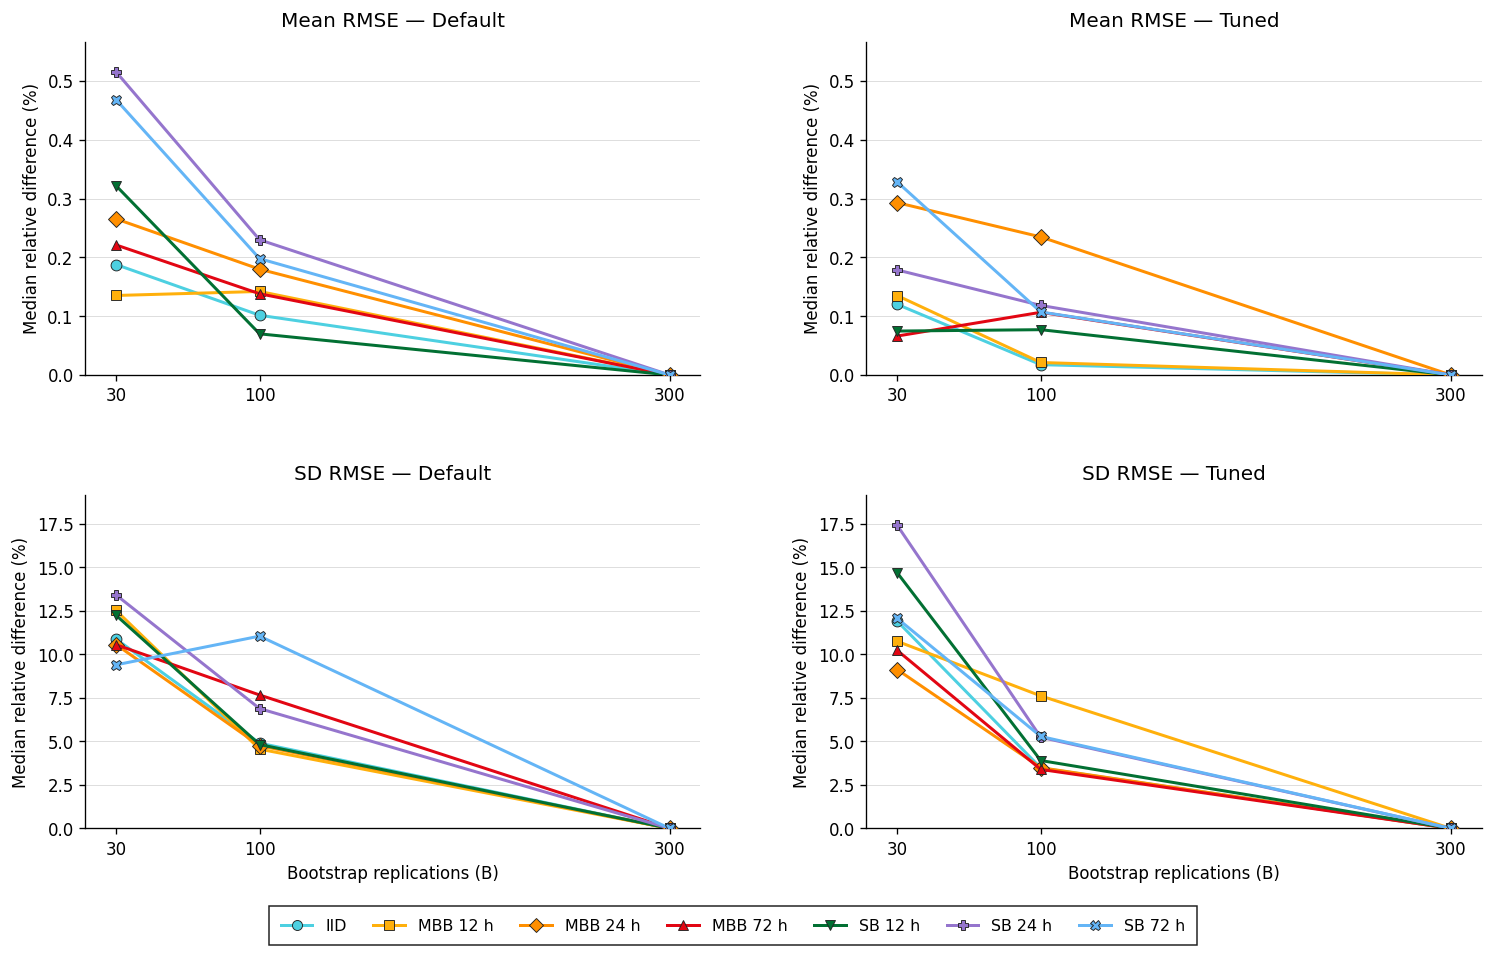

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig14_Bootstrap_Convergence_Trajectory.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig14_Bootstrap_Convergence_Trajectory.pdf

----------------------------------------------------------------------------
FIGURE 15 — CONVERGENCE DISCREPANCIES BOXPLOT
----------------------------------------------------------------------------


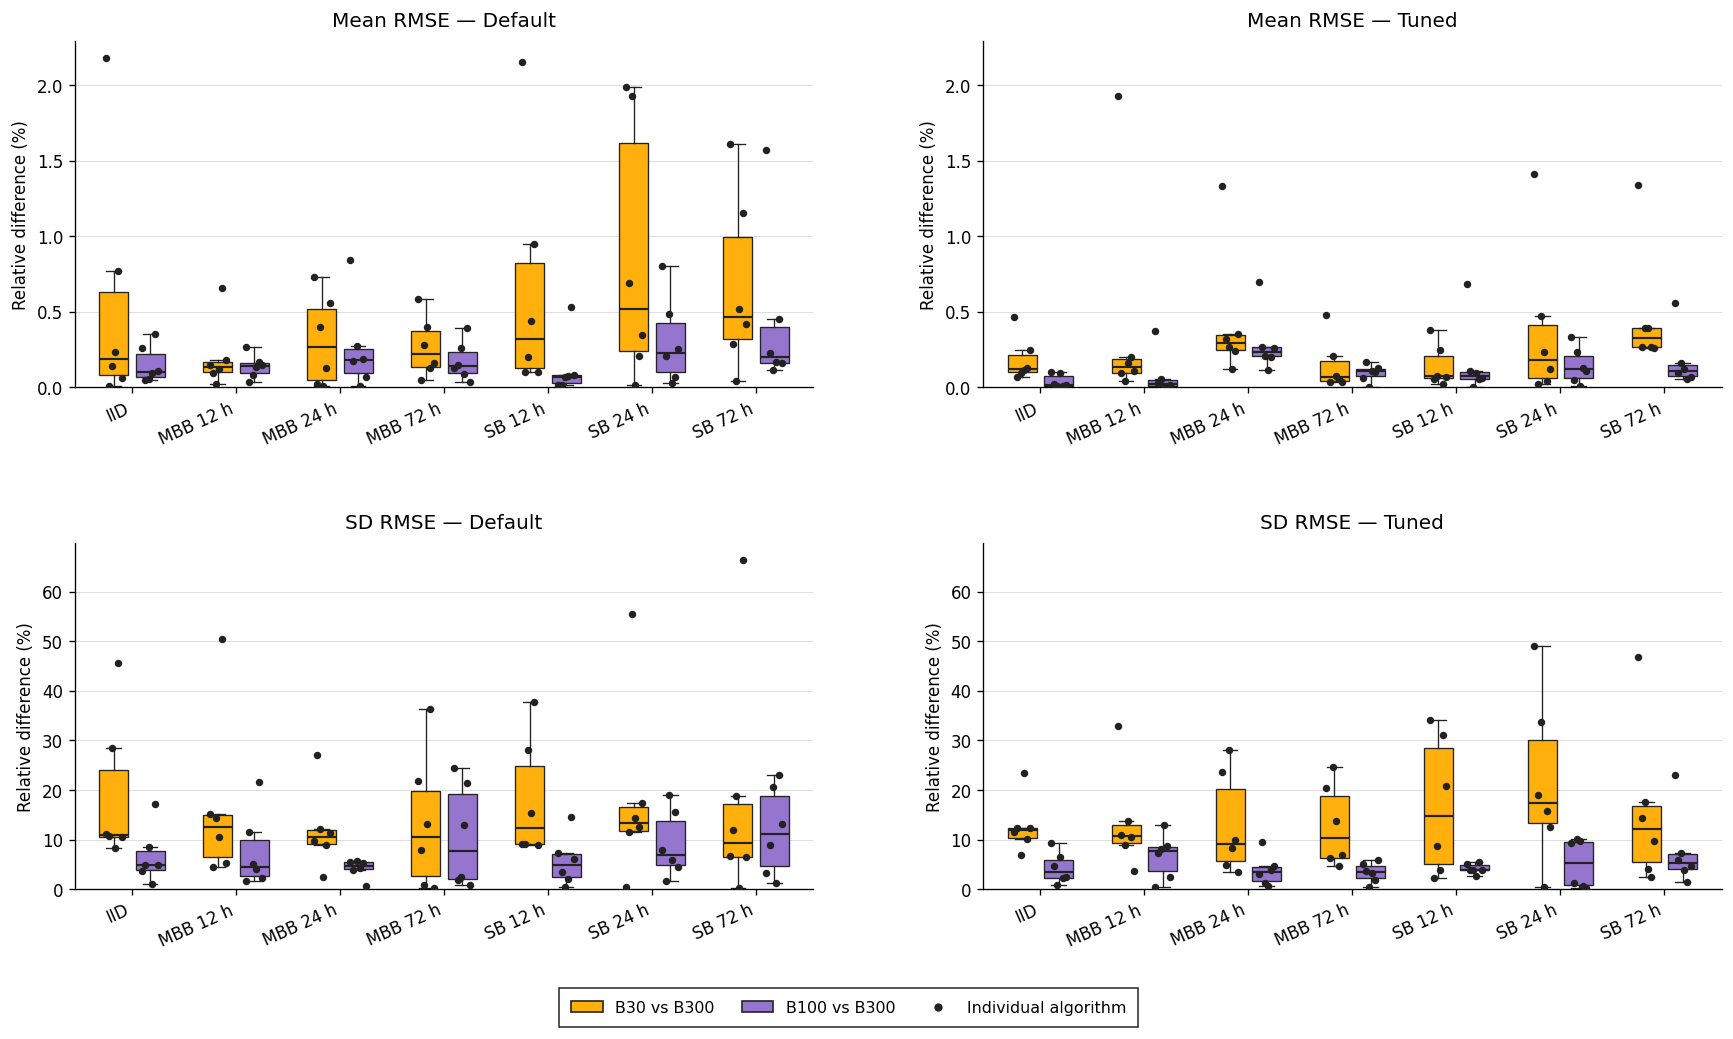

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig15_Convergence_Discrepancies_Boxplot.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig15_Convergence_Discrepancies_Boxplot.pdf

----------------------------------------------------------------------------
FIGURE 16 — KENDALL W CONVERGENCE PROFILE
----------------------------------------------------------------------------


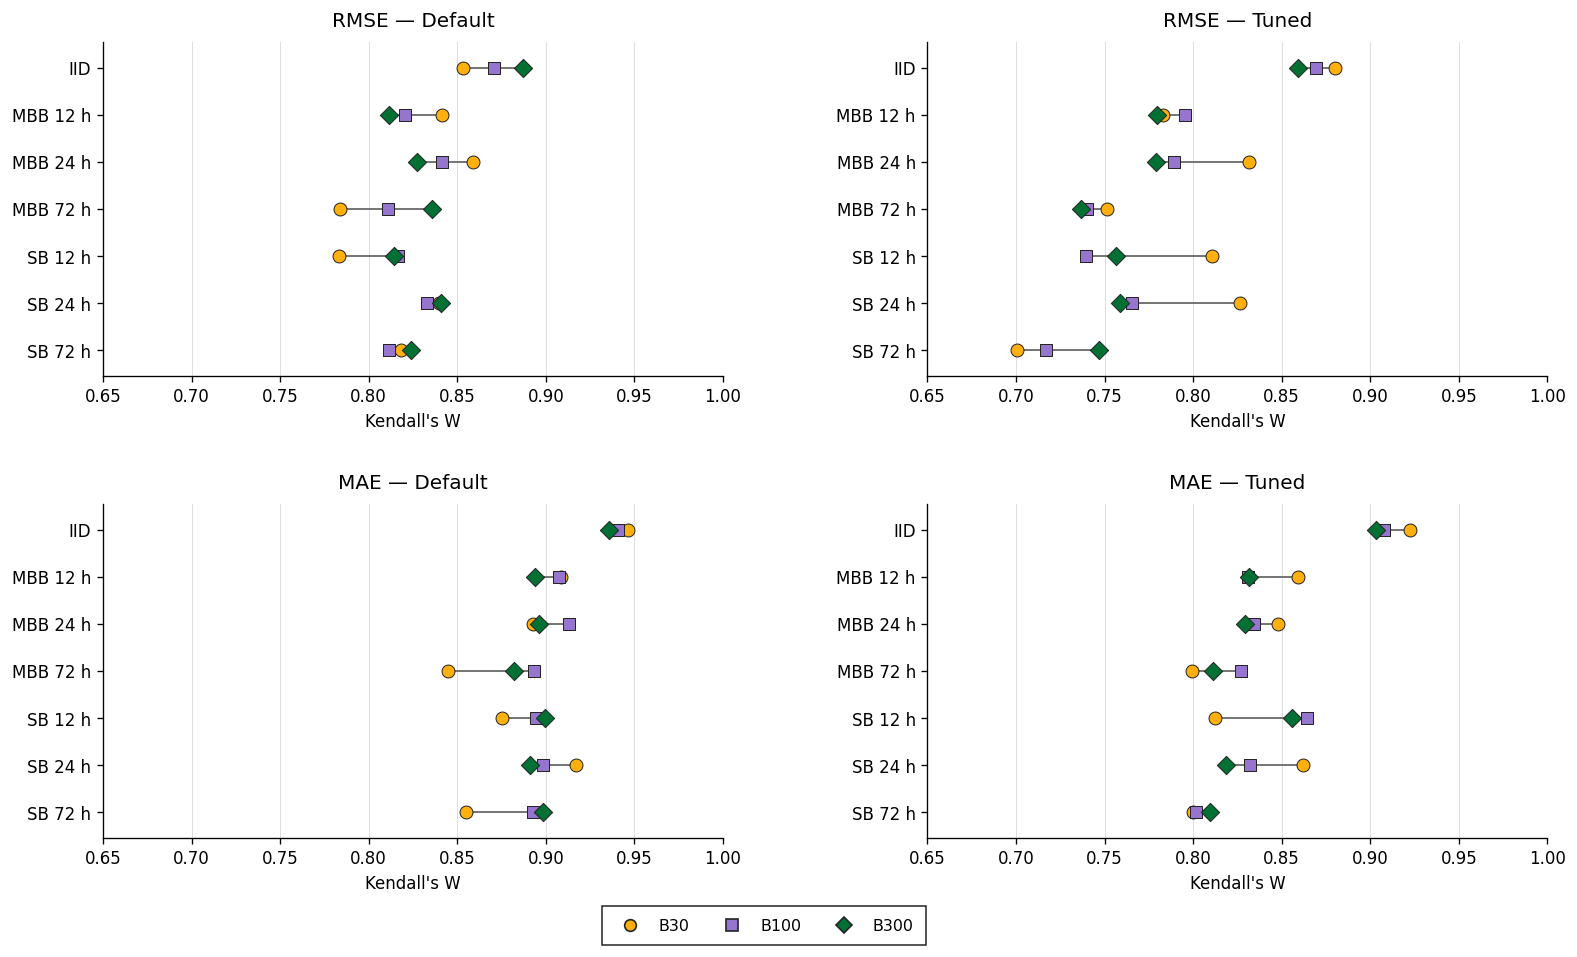

PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig16_Kendall_W_Convergence_Profile.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig16_Kendall_W_Convergence_Profile.pdf

C. CONVERGENCE BY BOOTSTRAP CONDITION

Mean RMSE — Median relative difference (%)


,B30 vs B300 (%),B100 vs B300 (%)
condition,,
IID,0.1341,0.0745
MBB 12 h,0.1352,0.0675
MBB 24 h,0.2931,0.2055
MBB 72 h,0.1448,0.1171
SB 12 h,0.1541,0.0700
SB 24 h,0.2900,0.1699
SB 72 h,0.3934,0.1591



SD RMSE — Median relative difference (%)


,B30 vs B300 (%),B100 vs B300 (%)
condition,,
IID,11.2350,4.7271
MBB 12 h,10.7804,6.1554
MBB 24 h,9.7973,4.0471
MBB 72 h,10.5521,3.3883
SB 12 h,12.2417,3.8997
SB 24 h,15.0907,6.8817
SB 72 h,10.9065,6.6578



CELL 07B — CONVERGENCE VISUALIZATION COMPLETED
B30 source integrity              : PASS
B100 source integrity             : PASS
B300 source integrity             : PASS
Cell 07 artifact integrity        : PASS
Verified Cell 07 artifacts        : 9/9
CSV axis metadata normalization   : PASS

Figure 14 — Convergence trajectory : PASS
Figure 15 — Discrepancy boxplot    : PASS
Figure 16 — Kendall W profile     : PASS

Bootstrap conditions preserved    : 7/7
Bootstrap sizes preserved         : 3/3
Algorithms represented            : 6/6
Model settings represented        : 2/2

Figure 14 trajectory points       : 84
Figure 15 boxes                   : 56
Figure 15 individual points       : 336
Figure 16 Kendall W points        : 84

Approved solid colors             : PASS
Gradient colors                   : NO
Figure suptitles                  : NO
Figure footnotes                  : NO
Outliers removed                  : NO

Formal convergence proven         : NO
Model refitting         

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 07B
# BOOTSTRAP REPLICATION CONVERGENCE VISUALIZATION
# FINAL APPROVED DESIGN
#
# Figure 14 : Convergence trajectory
# Figure 15 : Boxplot of convergence discrepancies
# Figure 16 : Kendall's W convergence profile
#
# Bootstrap conditions:
# IID | MBB 12h, 24h, 72h | SB 12h, 24h, 72h
#
# Bootstrap sizes: B = 30, 100, 300
#
# Source: Notebook 04 — Cell 07
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required07b = [
    "METRICS_PATH",
    "TABLE_DIR",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR",
    "bootstrap_manifest",
    "df_nested_bootstrap_audit07",
    "df_convergence_summary07",
    "df_convergence_comparison07",
    "df_convergence_aggregate07",
    "df_rank_convergence07",
    "df_concordance_convergence07",
    "df_rank_convergence_comparison07",
    "df_rank_convergence_aggregate07",
    "df_largest_discrepancies07",
    "ALGORITHMS07",
    "CONDITIONS07",
    "SETTINGS07",
    "METRICS07",
    "BOOTSTRAP_SIZES07"
]

missing07b = [
    name for name in required07b
    if name not in globals()
]

if missing07b:
    raise RuntimeError(
        "Run Notebook 04 through Cell 07 first. "
        f"Missing objects: {missing07b}"
    )


def ensure07b(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file07b(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def normalize_frame07b(dataframe):

    return (
        dataframe
        .reset_index(drop=True)
        .rename_axis(index=None, columns=None)
    )


TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

for directory in [
    TABLE_DIR,
    FIGURE_DIR,
    AUDIT_OUTPUT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# =============================================================================
# 2. VERIFY CELL 07 COMPLETION AUDIT
# =============================================================================

print("=" * 76)
print("CELL 07B — BOOTSTRAP CONVERGENCE VISUALIZATION")
print("=" * 76)

print("\nA. SOURCE AND ARTIFACT VERIFICATION")


CELL07_AUDIT_PATH07B = (
    AUDIT_OUTPUT_DIR
    / "NB04_Cell07_bootstrap_convergence_audit.json"
)

ensure07b(
    CELL07_AUDIT_PATH07B.is_file(),
    "Cell 07 completion audit missing."
)

with open(
    CELL07_AUDIT_PATH07B,
    "r",
    encoding="utf-8"
) as handle:

    cell07_audit07b = json.load(handle)


SOURCE_HASH07B = sha256_file07b(METRICS_PATH)

ensure07b(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False
    and bootstrap_manifest["hyperparameters_retuned"] is False,
    "Notebook 03 manifest mismatch."
)

ensure07b(
    SOURCE_HASH07B
    == bootstrap_manifest["outputs"]["metrics_sha256"]
    == cell07_audit07b["source_metrics_sha256"],
    "Source metrics checksum mismatch."
)

ensure07b(
    cell07_audit07b["status"] == "PASS"
    and cell07_audit07b["bootstrap_sizes"] == [30, 100, 300]
    and cell07_audit07b["cumulative_design"] is True
    and cell07_audit07b["unique_original_fitting_records"] == 25200
    and cell07_audit07b["performance_summary_records"] == 504
    and cell07_audit07b["performance_comparison_records"] == 504
    and cell07_audit07b["rank_summary_records"] == 504
    and cell07_audit07b["concordance_records"] == 84
    and cell07_audit07b["test_accessed"] is False,
    "Cell 07 completion audit mismatch."
)


# =============================================================================
# 3. VERIFY ALL ORIGINAL BOOTSTRAP SOURCE FILES
# =============================================================================

verified_sources07b = []

for source in cell07_audit07b["bootstrap_sources"]:

    B = int(source["B"])

    metrics_path = Path(
        source["metrics_path"]
    )

    audit_path = Path(
        source["audit_path"]
    )

    ensure07b(
        metrics_path.is_file()
        and audit_path.is_file(),
        f"B{B} source artifact missing."
    )

    ensure07b(
        sha256_file07b(metrics_path)
        == source["metrics_sha256"],
        f"B{B} metrics checksum mismatch."
    )

    ensure07b(
        sha256_file07b(audit_path)
        == source["audit_sha256"],
        f"B{B} audit checksum mismatch."
    )

    verified_sources07b.append(B)

    print(
        f"B{B} original source integrity: PASS"
    )


ensure07b(
    sorted(verified_sources07b) == [30, 100, 300],
    "Incomplete bootstrap source verification."
)


# =============================================================================
# 4. VERIFY ALL NINE CELL 07 ARTIFACTS
#
# Axis metadata is normalized to prevent the CSV
# comparison issue encountered previously in Cell 06B.
#
# Original DataFrames are not modified.
# =============================================================================

ARTIFACT_BINDINGS07B = {

    "nested_bootstrap_audit":
        df_nested_bootstrap_audit07,

    "convergence_summary":
        df_convergence_summary07,

    "convergence_comparison":
        df_convergence_comparison07,

    "convergence_aggregate":
        df_convergence_aggregate07,

    "rank_convergence":
        df_rank_convergence07,

    "concordance_convergence":
        df_concordance_convergence07,

    "rank_convergence_comparison":
        df_rank_convergence_comparison07,

    "rank_convergence_aggregate":
        df_rank_convergence_aggregate07,

    "remaining_discrepancies":
        df_largest_discrepancies07
}

VERIFIED_ARTIFACTS07B = []

for name, dataframe in ARTIFACT_BINDINGS07B.items():

    metadata = cell07_audit07b["outputs"][name]

    artifact_path = Path(
        metadata["path"]
    )

    ensure07b(
        artifact_path.is_file(),
        f"Missing Cell 07 artifact: {name}"
    )

    actual_hash = sha256_file07b(
        artifact_path
    )

    ensure07b(
        actual_hash == metadata["sha256"],
        f"Artifact checksum mismatch: {name}"
    )

    saved = pd.read_csv(
        artifact_path,
        low_memory=False
    )

    ensure07b(
        len(saved) == metadata["rows"] == len(dataframe),
        f"Artifact row count mismatch: {name}"
    )

    try:

        pd.testing.assert_frame_equal(
            normalize_frame07b(dataframe),
            normalize_frame07b(saved),
            check_dtype=False,
            check_exact=False,
            rtol=1e-10,
            atol=1e-10
        )

    except AssertionError as exc:

        raise AssertionError(
            f"Artifact content verification failed: "
            f"{name}\n{exc}"
        ) from exc

    VERIFIED_ARTIFACTS07B.append({

        "artifact": name,

        "path": str(artifact_path),

        "rows": int(len(saved)),

        "sha256": actual_hash,

        "content_verified": True,

        "axis_metadata_normalized": True
    })

    print(
        f"{name:<32} | "
        f"rows={len(saved):>4} | PASS"
    )


ensure07b(
    len(VERIFIED_ARTIFACTS07B) == 9,
    "Incomplete Cell 07 artifact verification."
)

ensure07b(
    len(df_nested_bootstrap_audit07) == 3
    and df_nested_bootstrap_audit07[
        "all_columns_identical"
    ].eq(True).all(),
    "Nested bootstrap verification failed."
)


# =============================================================================
# 5. FREEZE EXPERIMENT DEFINITIONS
# =============================================================================

ALGORITHMS07B = list(ALGORITHMS07)
CONDITIONS07B = list(CONDITIONS07)
SETTINGS07B = list(SETTINGS07)
METRICS07B = list(METRICS07)
BOOTSTRAP_SIZES07B = list(BOOTSTRAP_SIZES07)

ensure07b(
    ALGORITHMS07B == [
        "Decision Tree",
        "Random Forest",
        "Bagging",
        "SVR",
        "XGBoost",
        "LightGBM"
    ]
    and CONDITIONS07B == [
        "iid",
        "mbb_L0072",
        "mbb_L0144",
        "mbb_L0432",
        "stationary_L0072",
        "stationary_L0144",
        "stationary_L0432"
    ]
    and SETTINGS07B == ["default", "tuned"]
    and METRICS07B == ["rmse_wh", "mae_wh"]
    and BOOTSTRAP_SIZES07B == [30, 100, 300],
    "Frozen experiment definitions changed."
)

CONDITION_LABELS07B = {
    "iid": "IID",
    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",
    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}

METRIC_LABELS07B = {
    "rmse_wh": "RMSE",
    "mae_wh": "MAE"
}

SETTING_LABELS07B = {
    "default": "Default",
    "tuned": "Tuned"
}

STATISTIC_SPECS07B = [
    (
        "mean_error_wh_relative_difference_pct",
        "Mean RMSE"
    ),
    (
        "sd_error_wh_relative_difference_pct",
        "SD RMSE"
    )
]


# =============================================================================
# 6. APPROVED CATEGORICAL COLOR PALETTE
# =============================================================================

CONDITION_STYLES07B = {

    "iid": (
        "#4DD0E1", "o"
    ),

    "mbb_L0072": (
        "#FFB00C", "s"
    ),

    "mbb_L0144": (
        "#FF8F00", "D"
    ),

    "mbb_L0432": (
        "#E20613", "^"
    ),

    "stationary_L0072": (
        "#027033", "v"
    ),

    "stationary_L0144": (
        "#9575CD", "P"
    ),

    "stationary_L0432": (
        "#64B5F6", "X"
    )
}


BOOTSTRAP_STYLES07B = {

    30: (
        "#FFB00C", "o"
    ),

    100: (
        "#9575CD", "s"
    ),

    300: (
        "#027033", "D"
    )
}


# =============================================================================
# 7. EXTRACT CONVERGENCE DATA FROM CELL 07
#
# Figure 14 and 15:
# B30 vs B300
# B100 vs B300
#
# B300 relative difference is zero by definition.
# =============================================================================

df_relative_convergence07b = (

    df_convergence_comparison07.loc[

        (df_convergence_comparison07["B_large"] == 300)

        & (
            df_convergence_comparison07["B_small"]
            .isin([30, 100])
        )

        & (
            df_convergence_comparison07["metric"]
            == "rmse_wh"
        )
    ]

    .copy()
)

RELATIVE_KEYS07B = [
    "B_small",
    "condition",
    "algorithm",
    "setting"
]

ensure07b(
    len(df_relative_convergence07b) == 168
    and not df_relative_convergence07b.duplicated(
        RELATIVE_KEYS07B
    ).any(),
    "Invalid convergence comparison dimensions."
)

expected_relative_keys07b = {

    (B, condition, algorithm, setting)

    for B in [30, 100]
    for condition in CONDITIONS07B
    for algorithm in ALGORITHMS07B
    for setting in SETTINGS07B
}

ensure07b(
    set(
        df_relative_convergence07b[
            RELATIVE_KEYS07B
        ].itertuples(index=False, name=None)
    ) == expected_relative_keys07b,
    "Incomplete convergence comparison design."
)

for statistic, label in STATISTIC_SPECS07B:

    values = df_relative_convergence07b[
        statistic
    ].to_numpy(dtype=float)

    ensure07b(
        np.isfinite(values).all()
        and np.all(values >= 0),
        f"Invalid relative discrepancy: {statistic}"
    )


def get_discrepancies07b(
    B,
    condition,
    setting,
    statistic
):

    if B == 300:

        # Reference value compared with itself.
        return np.zeros(
            len(ALGORITHMS07B),
            dtype=float
        )

    subset = (

        df_relative_convergence07b.loc[

            (
                df_relative_convergence07b["B_small"]
                == B
            )

            & (
                df_relative_convergence07b["condition"]
                == condition
            )

            & (
                df_relative_convergence07b["setting"]
                == setting
            )
        ]

        .set_index("algorithm")

        .reindex(ALGORITHMS07B)
    )

    values = subset[
        statistic
    ].to_numpy(dtype=float)

    ensure07b(
        values.shape == (6,)
        and np.isfinite(values).all(),
        "Incomplete algorithm-specific discrepancies."
    )

    return values


# =============================================================================
# 8. PREPARE FIGURE 14 TRAJECTORY DATA
#
# Each point is the median across six algorithms
# within the same bootstrap condition and setting.
#
# No pooling across bootstrap conditions.
# =============================================================================

trajectory_records07b = []

for statistic, label in STATISTIC_SPECS07B:

    for setting in SETTINGS07B:

        for condition in CONDITIONS07B:

            for B in BOOTSTRAP_SIZES07B:

                values = get_discrepancies07b(
                    B,
                    condition,
                    setting,
                    statistic
                )

                trajectory_records07b.append({

                    "B": B,

                    "condition": condition,

                    "condition_label":
                        CONDITION_LABELS07B[condition],

                    "setting": setting,

                    "statistic": statistic,

                    "statistic_label": label,

                    "n_algorithms": len(values),

                    "median_relative_difference_pct":
                        float(np.median(values)),

                    "min_relative_difference_pct":
                        float(values.min()),

                    "max_relative_difference_pct":
                        float(values.max()),

                    "is_reference": B == 300
                })


df_trajectory_figure07b = pd.DataFrame(
    trajectory_records07b
)

ensure07b(
    len(df_trajectory_figure07b) == 84
    and df_trajectory_figure07b[
        "n_algorithms"
    ].eq(6).all(),
    "Incomplete Figure 14 trajectory data."
)

ensure07b(
    df_trajectory_figure07b.loc[
        df_trajectory_figure07b["B"] == 300,
        "median_relative_difference_pct"
    ].eq(0).all(),
    "B300 reference discrepancy must be zero."
)


# =============================================================================
# 9. PREPARE FIGURE 15 BOXPLOT DATA
#
# Each box summarizes six algorithms.
# All six observations are displayed as black dots.
#
# 2 statistics x 2 settings x 7 conditions x 2 contrasts
# = 56 boxes and 336 individual points.
# =============================================================================

boxplot_records07b = []

for statistic, label in STATISTIC_SPECS07B:

    for setting in SETTINGS07B:

        for condition in CONDITIONS07B:

            for B in [30, 100]:

                values = get_discrepancies07b(
                    B,
                    condition,
                    setting,
                    statistic
                )

                for algorithm, value in zip(
                    ALGORITHMS07B,
                    values
                ):

                    boxplot_records07b.append({

                        "B_small": B,

                        "B_reference": 300,

                        "condition": condition,

                        "condition_label":
                            CONDITION_LABELS07B[condition],

                        "setting": setting,

                        "algorithm": algorithm,

                        "statistic": statistic,

                        "statistic_label": label,

                        "relative_difference_pct":
                            float(value)
                    })


df_boxplot_figure07b = pd.DataFrame(
    boxplot_records07b
)

ensure07b(
    len(df_boxplot_figure07b) == 336,
    "Incomplete Figure 15 boxplot data."
)

box_counts07b = (
    df_boxplot_figure07b.groupby([
        "statistic",
        "setting",
        "condition",
        "B_small"
    ]).size()
)

ensure07b(
    len(box_counts07b) == 56
    and box_counts07b.eq(6).all(),
    "Unexpected Figure 15 group dimensions."
)


# =============================================================================
# 10. PREPARE FIGURE 16 KENDALL'S W DATA
# =============================================================================

W_KEYS07B = [
    "B",
    "condition",
    "setting",
    "metric"
]

ensure07b(
    len(df_concordance_convergence07) == 84
    and not df_concordance_convergence07.duplicated(
        W_KEYS07B
    ).any(),
    "Invalid Kendall W convergence dimensions."
)

expected_w_keys07b = {

    (B, condition, setting, metric)

    for B in BOOTSTRAP_SIZES07B
    for condition in CONDITIONS07B
    for setting in SETTINGS07B
    for metric in METRICS07B
}

ensure07b(
    set(
        df_concordance_convergence07[
            W_KEYS07B
        ].itertuples(index=False, name=None)
    ) == expected_w_keys07b,
    "Incomplete Kendall W convergence design."
)

w_values07b = (
    df_concordance_convergence07["kendall_w"]
    .to_numpy(dtype=float)
)

ensure07b(
    np.isfinite(w_values07b).all()
    and np.all(w_values07b >= 0)
    and np.all(w_values07b <= 1),
    "Invalid Kendall W values."
)

# Preserve approved common plotting range.
ensure07b(
    w_values07b.min() >= 0.65
    and w_values07b.max() <= 1.00,
    "Kendall W exceeds approved plotting limits."
)

W_LOOKUP07B = (

    df_concordance_convergence07

    .set_index(W_KEYS07B)["kendall_w"]
)


# =============================================================================
# 11. CONDITION-SPECIFIC CONVERGENCE SUMMARY
#
# Supporting descriptive summary:
# 12 configurations per condition
# = six algorithms x two settings.
#
# This summarizes relative discrepancies,
# not the original bootstrap errors.
# =============================================================================

condition_records07b = []

for statistic, label in STATISTIC_SPECS07B:

    for condition in CONDITIONS07B:

        for B in [30, 100]:

            values = np.concatenate([

                get_discrepancies07b(
                    B,
                    condition,
                    setting,
                    statistic
                )

                for setting in SETTINGS07B
            ])

            ensure07b(
                values.shape == (12,),
                "Incomplete condition-specific summary."
            )

            condition_records07b.append({

                "condition": condition,

                "condition_label":
                    CONDITION_LABELS07B[condition],

                "B_small": B,

                "B_reference": 300,

                "statistic": statistic,

                "statistic_label": label,

                "n_configurations": 12,

                "median_relative_difference_pct":
                    float(np.median(values)),

                "mean_relative_difference_pct":
                    float(values.mean()),

                "max_relative_difference_pct":
                    float(values.max())
            })


df_condition_convergence07b = pd.DataFrame(
    condition_records07b
)

ensure07b(
    len(df_condition_convergence07b) == 28,
    "Incomplete condition convergence summary."
)


# =============================================================================
# 12. APPROVED PUBLICATION STYLE
# =============================================================================

STYLE07B = {

    "font.family": "DejaVu Sans",

    "font.size": 10,

    "font.weight": "normal",

    "axes.titleweight": "normal",

    "axes.labelweight": "normal",

    "axes.labelcolor": "#000000",

    "text.color": "#000000",

    "xtick.color": "#000000",

    "ytick.color": "#000000",

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "pdf.fonttype": 42,

    "ps.fonttype": 42
}


def clean_axis07b(
    ax,
    grid_axis="y"
):

    ax.grid(
        axis=grid_axis,
        color="#DEDEDE",
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def boxed_legend07b(
    fig,
    handles,
    ncol,
    y=0.025
):

    legend = fig.legend(

        handles=handles,

        ncol=ncol,

        loc="lower center",

        bbox_to_anchor=(0.5, y),

        frameon=True,

        fancybox=False,

        framealpha=1.0,

        facecolor="white",

        edgecolor="#202020",

        borderpad=0.75,

        columnspacing=1.7,

        fontsize=9.5
    )

    legend.get_frame().set_linewidth(0.9)

    return legend


def export_figure07b(
    fig,
    number,
    filename,
    description
):

    stem = FIGURE_DIR / filename

    png_path = stem.with_suffix(".png")
    pdf_path = stem.with_suffix(".pdf")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.10,
        facecolor="white"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.10,
        facecolor="white"
    )

    ensure07b(
        png_path.is_file()
        and pdf_path.is_file()
        and png_path.stat().st_size > 0
        and pdf_path.stat().st_size > 0,
        f"Figure {number} export failed."
    )

    plt.show()
    plt.close(fig)

    return {

        "figure_number": number,

        "description": description,

        "png": str(png_path),

        "pdf": str(pdf_path),

        "png_sha256": sha256_file07b(png_path),

        "pdf_sha256": sha256_file07b(pdf_path)
    }


# =============================================================================
# 13. FIGURE 14 — CONVERGENCE TRAJECTORY
#
# Layout:
# Mean RMSE — Default | Mean RMSE — Tuned
# SD RMSE   — Default | SD RMSE   — Tuned
#
# Seven lines per panel represent bootstrap conditions.
#
# Y-axis limits are shared within each statistic
# and calculated across both settings.
#
# The B300 endpoint is zero by construction.
# =============================================================================

def make_figure14():

    with plt.rc_context(STYLE07B):

        fig, axes = plt.subplots(

            nrows=2,

            ncols=2,

            figsize=(13, 8.3),

            sharex=True,

            sharey="row"
        )

        plotted_points = 0

        for i, (
            statistic,
            label
        ) in enumerate(STATISTIC_SPECS07B):

            row_max = 0.0

            for j, setting in enumerate(
                SETTINGS07B
            ):

                ax = axes[i, j]

                for condition in CONDITIONS07B:

                    subset = (

                        df_trajectory_figure07b.loc[

                            (
                                df_trajectory_figure07b[
                                    "statistic"
                                ] == statistic
                            )

                            & (
                                df_trajectory_figure07b[
                                    "setting"
                                ] == setting
                            )

                            & (
                                df_trajectory_figure07b[
                                    "condition"
                                ] == condition
                            )
                        ]

                        .set_index("B")

                        .reindex(BOOTSTRAP_SIZES07B)
                    )

                    values = subset[
                        "median_relative_difference_pct"
                    ].to_numpy(dtype=float)

                    ensure07b(
                        values.shape == (3,)
                        and np.isfinite(values).all(),
                        "Invalid Figure 14 trajectory."
                    )

                    row_max = max(
                        row_max,
                        float(values.max())
                    )

                    color, marker = (
                        CONDITION_STYLES07B[condition]
                    )

                    ax.plot(

                        BOOTSTRAP_SIZES07B,

                        values,

                        color=color,

                        marker=marker,

                        markersize=6.5,

                        markeredgecolor="#242424",

                        markeredgewidth=0.55,

                        linewidth=1.8,

                        zorder=3
                    )

                    plotted_points += len(values)

                ax.set_title(

                    f"{label} — "
                    f"{SETTING_LABELS07B[setting]}",

                    pad=9,

                    fontweight="normal"
                )

                ax.set_ylabel(
                    "Median relative difference (%)"
                )

                ax.set_xticks(
                    BOOTSTRAP_SIZES07B
                )

                ax.set_xlim(15, 315)

                ax.tick_params(
                    labelbottom=True,
                    labelleft=True
                )

                clean_axis07b(
                    ax,
                    grid_axis="y"
                )

                if i == 1:

                    ax.set_xlabel(
                        "Bootstrap replications (B)"
                    )

            # IMPORTANT:
            # Apply shared Y-axis limits only after
            # plotting BOTH Default and Tuned panels.

            upper_limit = (
                row_max * 1.10
                if row_max > 0
                else 1.0
            )

            axes[i, 0].set_ylim(
                0,
                upper_limit
            )

            ensure07b(
                upper_limit >= row_max,
                "Figure 14 axis clipping detected."
            )

        ensure07b(
            plotted_points == 84,
            "Incomplete Figure 14 point coverage."
        )

        handles = [

            Line2D(

                [0], [0],

                color=CONDITION_STYLES07B[
                    condition
                ][0],

                marker=CONDITION_STYLES07B[
                    condition
                ][1],

                markeredgecolor="#242424",

                markeredgewidth=0.55,

                linewidth=1.8,

                label=CONDITION_LABELS07B[
                    condition
                ]
            )

            for condition in CONDITIONS07B
        ]

        boxed_legend07b(
            fig,
            handles,
            ncol=7
        )

        fig.subplots_adjust(

            left=0.085,

            right=0.98,

            top=0.94,

            bottom=0.15,

            wspace=0.27,

            hspace=0.36
        )

        return export_figure07b(

            fig=fig,

            number=14,

            filename=(
                "NB04_Fig14_Bootstrap_Convergence_Trajectory"
            ),

            description=(
                "Median relative RMSE discrepancies "
                "by bootstrap condition and setting"
            )
        )


# =============================================================================
# 14. FIGURE 15 — BOXPLOT OF CONVERGENCE DISCREPANCIES
#
# Seven bootstrap conditions per panel.
# Two boxes per condition:
#
# Yellow : B30 vs B300
# Purple : B100 vs B300
#
# Every box contains six algorithms.
# All six individual values are displayed.
#
# No observations are removed.
# =============================================================================

def make_figure15():

    with plt.rc_context(STYLE07B):

        fig, axes = plt.subplots(

            nrows=2,

            ncols=2,

            figsize=(15, 9),

            sharex=True,

            sharey="row"
        )

        x = np.arange(
            len(CONDITIONS07B)
        )

        plotted_boxes = 0
        plotted_points = 0

        for i, (
            statistic,
            label
        ) in enumerate(STATISTIC_SPECS07B):

            row_max = 0.0

            for j, setting in enumerate(
                SETTINGS07B
            ):

                ax = axes[i, j]

                for k, B in enumerate([30, 100]):

                    color = BOOTSTRAP_STYLES07B[B][0]

                    positions = (
                        x + (k - 0.5) * 0.35
                    )

                    distributions = [

                        get_discrepancies07b(
                            B,
                            condition,
                            setting,
                            statistic
                        )

                        for condition in CONDITIONS07B
                    ]

                    row_max = max(
                        row_max,
                        max(
                            float(values.max())
                            for values in distributions
                        )
                    )

                    ax.boxplot(

                        distributions,

                        positions=positions,

                        widths=0.28,

                        patch_artist=True,

                        manage_ticks=False,

                        whis=1.5,

                        # All observations, including
                        # outliers, are plotted below.
                        showfliers=False,

                        boxprops={

                            "facecolor": color,

                            "edgecolor": "#242424",

                            "linewidth": 0.8
                        },

                        medianprops={

                            "color": "#222222",

                            "linewidth": 1.3
                        },

                        whiskerprops={

                            "color": "#222222",

                            "linewidth": 0.8
                        },

                        capprops={

                            "color": "#222222",

                            "linewidth": 0.8
                        }
                    )

                    plotted_boxes += len(distributions)

                    for position, values in zip(
                        positions,
                        distributions
                    ):

                        # Deterministic horizontal offsets.
                        # Vertical data values are unchanged.

                        offsets = np.linspace(
                            -0.075,
                            0.075,
                            len(values)
                        )

                        ax.scatter(

                            position + offsets,

                            values,

                            s=12,

                            color="#222222",

                            zorder=4
                        )

                        plotted_points += len(values)

                ax.set_title(

                    f"{label} — "
                    f"{SETTING_LABELS07B[setting]}",

                    pad=9,

                    fontweight="normal"
                )

                ax.set_ylabel(
                    "Relative difference (%)"
                )

                ax.set_xticks(

                    x,

                    [
                        CONDITION_LABELS07B[condition]

                        for condition in CONDITIONS07B
                    ],

                    rotation=24,

                    ha="right"
                )

                ax.tick_params(
                    labelbottom=True,
                    labelleft=True
                )

                ax.set_xlim(-0.55, 6.55)

                clean_axis07b(
                    ax,
                    grid_axis="y"
                )

            # Shared limits across Default and Tuned
            # with all individual points retained.

            upper_limit = (
                row_max * 1.05
                if row_max > 0
                else 1.0
            )

            axes[i, 0].set_ylim(
                0,
                upper_limit
            )

        ensure07b(
            plotted_boxes == 56
            and plotted_points == 336,
            "Incomplete Figure 15 observation coverage."
        )

        handles = [

            Patch(
                facecolor="#FFB00C",
                edgecolor="#242424",
                label="B30 vs B300"
            ),

            Patch(
                facecolor="#9575CD",
                edgecolor="#242424",
                label="B100 vs B300"
            ),

            Line2D(
                [0], [0],
                marker="o",
                color="#222222",
                linestyle="None",
                markersize=4,
                label="Individual algorithm"
            )
        ]

        boxed_legend07b(

            fig,

            handles,

            ncol=3
        )

        fig.subplots_adjust(

            left=0.07,

            right=0.985,

            top=0.945,

            bottom=0.16,

            wspace=0.23,

            hspace=0.45
        )

        return export_figure07b(

            fig=fig,

            number=15,

            filename=(
                "NB04_Fig15_Convergence_Discrepancies_Boxplot"
            ),

            description=(
                "Algorithm-level relative discrepancies "
                "across bootstrap conditions"
            )
        )


# =============================================================================
# 15. FIGURE 16 — KENDALL'S W CONVERGENCE PROFILE
#
# Four panels:
# RMSE — Default | RMSE — Tuned
# MAE  — Default | MAE  — Tuned
#
# Seven bootstrap conditions per panel.
#
# B30  : Yellow circle
# B100 : Purple square
# B300 : Green diamond
#
# Common X-axis = 0.65–1.00.
#
# Connecting lines indicate differences between estimates,
# not confidence intervals.
# =============================================================================

def make_figure16():

    with plt.rc_context(STYLE07B):

        fig, axes = plt.subplots(

            nrows=2,

            ncols=2,

            figsize=(13.6, 8.3),

            sharex=True,

            sharey=True
        )

        plotted_points = 0

        for i, metric in enumerate(
            METRICS07B
        ):

            for j, setting in enumerate(
                SETTINGS07B
            ):

                ax = axes[i, j]

                for k, condition in enumerate(
                    CONDITIONS07B
                ):

                    values = [

                        float(
                            W_LOOKUP07B.loc[
                                (
                                    B,
                                    condition,
                                    setting,
                                    metric
                                )
                            ]
                        )

                        for B in BOOTSTRAP_SIZES07B
                    ]

                    ensure07b(
                        np.isfinite(values).all(),
                        "Invalid Figure 16 Kendall W values."
                    )

                    ax.plot(

                        values,

                        [k] * 3,

                        color="#777777",

                        linewidth=1.2,

                        zorder=2
                    )

                    for B, value in zip(
                        BOOTSTRAP_SIZES07B,
                        values
                    ):

                        color, marker = (
                            BOOTSTRAP_STYLES07B[B]
                        )

                        ax.scatter(

                            value,

                            k,

                            color=color,

                            marker=marker,

                            s=60,

                            edgecolor="#242424",

                            linewidth=0.6,

                            zorder=4
                        )

                        plotted_points += 1

                ax.set_title(

                    f"{METRIC_LABELS07B[metric]} — "
                    f"{SETTING_LABELS07B[setting]}",

                    pad=9,

                    fontweight="normal"
                )

                ax.set_yticks(

                    range(len(CONDITIONS07B)),

                    [
                        CONDITION_LABELS07B[condition]

                        for condition in CONDITIONS07B
                    ]
                )

                ax.set_ylim(6.55, -0.55)

                ax.set_xlim(0.65, 1.00)

                ax.set_xticks(
                    np.arange(0.65, 1.001, 0.05)
                )

                ax.tick_params(
                    labelbottom=True,
                    labelleft=True
                )

                ax.set_xlabel(
                    "Kendall's W"
                )

                clean_axis07b(
                    ax,
                    grid_axis="x"
                )

        ensure07b(
            plotted_points == 84,
            "Incomplete Figure 16 Kendall W coverage."
        )

        handles = [

            Line2D(

                [0], [0],

                marker=BOOTSTRAP_STYLES07B[B][1],

                markerfacecolor=BOOTSTRAP_STYLES07B[B][0],

                markeredgecolor="#242424",

                linestyle="None",

                markersize=7,

                label=f"B{B}"
            )

            for B in BOOTSTRAP_SIZES07B
        ]

        boxed_legend07b(

            fig,

            handles,

            ncol=3
        )

        fig.subplots_adjust(

            left=0.095,

            right=0.98,

            top=0.94,

            bottom=0.14,

            wspace=0.33,

            hspace=0.38
        )

        return export_figure07b(

            fig=fig,

            number=16,

            filename=(
                "NB04_Fig16_Kendall_W_Convergence_Profile"
            ),

            description=(
                "Ranking concordance across cumulative "
                "bootstrap replication sizes"
            )
        )


# =============================================================================
# 16. GENERATE ALL APPROVED FIGURES
# =============================================================================

print("\n" + "=" * 76)
print("B. GENERATE APPROVED CONVERGENCE FIGURES")
print("=" * 76)

print("Original fitting records: 25200")
print("Bootstrap sizes: 30, 100, 300")
print("Bootstrap conditions: 7")
print("Algorithms: 6")
print("Model settings: 2")
print("Verified Cell 07 artifacts: 9/9")


FIGURE_OUTPUTS07B = []

FIGURE_FUNCTIONS07B = [

    (
        14,
        "BOOTSTRAP CONVERGENCE TRAJECTORY",
        make_figure14
    ),

    (
        15,
        "CONVERGENCE DISCREPANCIES BOXPLOT",
        make_figure15
    ),

    (
        16,
        "KENDALL W CONVERGENCE PROFILE",
        make_figure16
    )
]


for number, description, function in FIGURE_FUNCTIONS07B:

    print("\n" + "-" * 76)

    print(
        f"FIGURE {number:02d} — {description}"
    )

    print("-" * 76)

    result = function()

    FIGURE_OUTPUTS07B.append(result)

    print("PNG:", result["png"])
    print("PDF:", result["pdf"])


ensure07b(
    len(FIGURE_OUTPUTS07B) == 3
    and {
        item["figure_number"]
        for item in FIGURE_OUTPUTS07B
    } == {14, 15, 16},
    "Incomplete approved figure outputs."
)

for item in FIGURE_OUTPUTS07B:

    ensure07b(
        sha256_file07b(item["png"])
        == item["png_sha256"],
        "PNG checksum verification failed."
    )

    ensure07b(
        sha256_file07b(item["pdf"])
        == item["pdf_sha256"],
        "PDF checksum verification failed."
    )


# =============================================================================
# 17. SAVE SUPPLEMENTARY FIGURE DATA
#
# These tables contain visualization-ready summaries.
# They do not replace the original Cell 07 outputs.
# =============================================================================

def save_csv07b(
    dataframe,
    filename
):

    path = TABLE_DIR / filename

    temporary = path.with_name(
        path.name + ".temporary"
    )

    dataframe.to_csv(

        temporary,

        index=False,

        float_format="%.12g"
    )

    os.replace(
        temporary,
        path
    )

    saved = pd.read_csv(
        path,
        low_memory=False
    )

    pd.testing.assert_frame_equal(

        normalize_frame07b(dataframe),

        normalize_frame07b(saved),

        check_dtype=False,

        check_exact=False,

        rtol=1e-10,

        atol=1e-10
    )

    return {

        "path": str(path),

        "rows": int(len(dataframe)),

        "sha256": sha256_file07b(path)
    }


OUTPUT_TABLES07B = {}


OUTPUT_TABLES07B["trajectory_figure_data"] = (
    save_csv07b(

        df_trajectory_figure07b,

        "NB04_convergence_trajectory_figure_data.csv"
    )
)


OUTPUT_TABLES07B["boxplot_figure_data"] = (
    save_csv07b(

        df_boxplot_figure07b,

        "NB04_convergence_boxplot_figure_data.csv"
    )
)


OUTPUT_TABLES07B["condition_convergence_summary"] = (
    save_csv07b(

        df_condition_convergence07b,

        "NB04_convergence_summary_by_bootstrap_condition.csv"
    )
)


# =============================================================================
# 18. DISPLAY CONDITION-SPECIFIC NUMERICAL RESULTS
# =============================================================================

from IPython.display import display

print("\n" + "=" * 76)
print("C. CONVERGENCE BY BOOTSTRAP CONDITION")
print("=" * 76)

for statistic, label in STATISTIC_SPECS07B:

    print(
        f"\n{label} — Median relative difference (%)"
    )

    matrix = (

        df_condition_convergence07b.loc[
            df_condition_convergence07b["statistic"]
            == statistic
        ]

        .pivot(
            index="condition",
            columns="B_small",
            values="median_relative_difference_pct"
        )

        .reindex(CONDITIONS07B)

        .rename(

            index=CONDITION_LABELS07B,

            columns={

                30: "B30 vs B300 (%)",

                100: "B100 vs B300 (%)"
            }
        )

        .rename_axis(columns=None)
    )

    display(matrix.round(4))


# =============================================================================
# 19. REPRODUCIBILITY AUDIT
# =============================================================================

VISUAL_AUDIT07B = {

    "notebook": "04",

    "cell": "07B",

    "status": "PASS",

    "visualization_version": (
        "approved_condition_specific_convergence_v1"
    ),

    "source": (
        "Notebook 03 cumulative bootstrap stages "
        "and Notebook 04 Cell 07"
    ),

    "source_metrics_sha256": SOURCE_HASH07B,

    "source_cell07_audit_sha256":
        sha256_file07b(CELL07_AUDIT_PATH07B),

    "verified_bootstrap_sources":
        sorted(verified_sources07b),

    "verified_cell07_artifacts":
        VERIFIED_ARTIFACTS07B,

    "axis_metadata_normalized": True,

    "original_fitting_records": 25200,

    "bootstrap_sizes": BOOTSTRAP_SIZES07B,

    "cumulative_bootstrap_design": True,

    "conditions": CONDITIONS07B,

    "algorithms": ALGORITHMS07B,

    "settings": SETTINGS07B,

    "metrics": METRICS07B,

    "bootstrap_conditions_preserved": True,

    "block_lengths_preserved": True,

    "default_tuned_separated": True,

    "figure_count": 3,

    "figure14": {

        "type": "Convergence trajectory",

        "metric": "rmse_wh",

        "statistics": [
            "mean_error_wh",
            "sd_error_wh"
        ],

        "panels": 4,

        "conditions_per_panel": 7,

        "bootstrap_sizes_per_line": 3,

        "plotted_points": 84,

        "aggregation": (
            "Median relative difference across "
            "six algorithms within condition and setting"
        ),

        "reference_B": 300,

        "reference_difference_zero_by_definition": True,

        "reference_is_population_truth": False,

        "shared_y_axis_within_statistic": True,

        "axis_limits_cover_all_points": True,

        "numeric_bootstrap_size_axis": True
    },

    "figure15": {

        "type": "Grouped boxplot with individual points",

        "metric": "rmse_wh",

        "statistics": [
            "mean_error_wh",
            "sd_error_wh"
        ],

        "panels": 4,

        "conditions_per_panel": 7,

        "boxes": 56,

        "algorithms_per_box": 6,

        "individual_points": 336,

        "comparisons": [
            "B30_vs_B300",
            "B100_vs_B300"
        ],

        "whisker_iqr_multiplier": 1.5,

        "all_individual_observations_displayed": True,

        "outliers_removed": False,

        "horizontal_offsets_only": True,

        "shared_y_axis_within_statistic": True
    },

    "figure16": {

        "type": "Connected dot plot",

        "statistic": "Kendall's W",

        "metrics": METRICS07B,

        "panels": 4,

        "conditions_per_panel": 7,

        "plotted_points": 84,

        "common_x_axis": True,

        "x_axis_limits": [0.65, 1.00],

        "connecting_lines_are_confidence_intervals": False
    },

    "condition_styles": CONDITION_STYLES07B,

    "bootstrap_styles": {
        str(B): style
        for B, style in BOOTSTRAP_STYLES07B.items()
    },

    "gradient": False,

    "figure_suptitles": False,

    "figure_footnotes": False,

    "legend_boxed": True,

    "legend_position": "Below complete figure",

    "formal_convergence_proven": False,

    "source_data_modified": False,

    "outliers_removed": False,

    "predictive_metrics_recomputed": False,

    "individual_model_ranks_recomputed": False,

    "kendall_w_recomputed": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "final_model_selected": False,

    "test_accessed": False,

    "figures": FIGURE_OUTPUTS07B,

    "supplementary_tables": OUTPUT_TABLES07B
}


VISUAL_AUDIT_PATH07B = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell07B_convergence_visualization_audit.json"
)

temporary07b = VISUAL_AUDIT_PATH07B.with_name(

    VISUAL_AUDIT_PATH07B.name
    + ".temporary"
)

with open(

    temporary07b,

    "w",

    encoding="utf-8"

) as handle:

    json.dump(

        VISUAL_AUDIT07B,

        handle,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    )

os.replace(

    temporary07b,

    VISUAL_AUDIT_PATH07B
)


# =============================================================================
# 20. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 07B — CONVERGENCE VISUALIZATION COMPLETED")

print("=" * 76)

print("B30 source integrity              : PASS")
print("B100 source integrity             : PASS")
print("B300 source integrity             : PASS")

print("Cell 07 artifact integrity        : PASS")
print("Verified Cell 07 artifacts        : 9/9")
print("CSV axis metadata normalization   : PASS")

print("\nFigure 14 — Convergence trajectory : PASS")
print("Figure 15 — Discrepancy boxplot    : PASS")
print("Figure 16 — Kendall W profile     : PASS")

print("\nBootstrap conditions preserved    : 7/7")
print("Bootstrap sizes preserved         : 3/3")
print("Algorithms represented            : 6/6")
print("Model settings represented        : 2/2")

print("\nFigure 14 trajectory points       : 84")
print("Figure 15 boxes                   : 56")
print("Figure 15 individual points       : 336")
print("Figure 16 Kendall W points        : 84")

print("\nApproved solid colors             : PASS")
print("Gradient colors                   : NO")
print("Figure suptitles                  : NO")
print("Figure footnotes                  : NO")
print("Outliers removed                  : NO")

print("\nFormal convergence proven         : NO")
print("Model refitting                   : NO")
print("New bootstrap                     : NO")
print("Hyperparameter retuning           : NO")
print("Final model selected              : NO")
print("Test accessed                     : NO")


print("\nSAVED FIGURES")

for item in FIGURE_OUTPUTS07B:

    print(
        f"\nFigure {item['figure_number']:02d}"
    )

    print("PNG:", item["png"])
    print("PDF:", item["pdf"])


print("\nSUPPLEMENTARY TABLES")

for name, item in OUTPUT_TABLES07B.items():

    print(
        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])


print("\nAUDIT")

print(VISUAL_AUDIT_PATH07B)

print("\nFINAL STATUS: PASS")


# 8. ACCURACY–STABILITY TRADE-OFF ANALYSIS

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 08
# ACCURACY–STABILITY TRADE-OFF ANALYSIS
# FINAL FIXED VERSION — GITHUB READY
#
# Multi-objective evaluation using Pareto dominance.
#
# Objective 1: Minimize mean predictive error
# Objective 2: Minimize SD of predictive error
#
# Comparison scopes:
#   Default : 6 algorithms
#   Tuned   : 6 algorithms
#   Joint   : 12 algorithm-setting configurations
#
# Primary metric   : RMSE (Wh)
# Supporting metric: MAE (Wh)
#
# Bootstrap conditions:
# IID | MBB 12h, 24h, 72h | SB 12h, 24h, 72h
#
# B = 300
#
# CSV SERIALIZATION POLICY:
# - Preserve literal "None" strings.
# - Preserve actual missing values.
# - Normalize axis metadata during comparison.
# - Verify temporary CSV before replacing final artifact.
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path
from itertools import combinations
from io import StringIO

import numpy as np
import pandas as pd

from IPython.display import display


# =============================================================================
# 1. BIND EXISTING NOTEBOOK 04 OBJECTS
# =============================================================================

required08 = [
    "METRICS_PATH",
    "TABLE_DIR",
    "AUDIT_OUTPUT_DIR",
    "bootstrap_manifest",
    "df_metrics",
    "df_stability_summary04",
    "df_tuning_summary05",
    "df_rank_summary06",
    "df_convergence_summary07",
    "ALGORITHMS07",
    "CONDITIONS07",
    "SETTINGS07",
    "METRICS07"
]

missing08 = [
    name for name in required08
    if name not in globals()
]

if missing08:
    raise RuntimeError(
        "Run Notebook 04 through Cell 07B first. "
        f"Missing objects: {missing08}"
    )


def ensure08(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_file08(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


def normalize_frame08(dataframe, sort_keys=None):

    result = dataframe.copy()

    if sort_keys is not None:

        result = result.sort_values(
            sort_keys,
            kind="stable"
        )

    return (
        result
        .reset_index(drop=True)
        .rename_axis(
            index=None,
            columns=None
        )
    )


def assert_frames08(
    left,
    right,
    sort_keys=None,
    exact=False
):

    pd.testing.assert_frame_equal(
        normalize_frame08(left, sort_keys),
        normalize_frame08(right, sort_keys),
        check_dtype=False,
        check_exact=exact,
        rtol=1e-10,
        atol=1e-10
    )


def read_csv08_fixed(path):

    # Literal "None" remains a string.
    # Only empty fields are interpreted as missing.

    return pd.read_csv(
        path,
        low_memory=False,
        keep_default_na=False,
        na_values=[""]
    )


TABLE_DIR = Path(TABLE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

AUDIT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =============================================================================
# 2. FREEZE EXPERIMENT DEFINITIONS
# =============================================================================

ALGORITHMS08 = list(ALGORITHMS07)
CONDITIONS08 = list(CONDITIONS07)
SETTINGS08 = list(SETTINGS07)
METRICS08 = list(METRICS07)

SCOPES08 = [
    "default",
    "tuned",
    "joint"
]

B08 = 300

ensure08(
    ALGORITHMS08 == [
        "Decision Tree",
        "Random Forest",
        "Bagging",
        "SVR",
        "XGBoost",
        "LightGBM"
    ]
    and CONDITIONS08 == [
        "iid",
        "mbb_L0072",
        "mbb_L0144",
        "mbb_L0432",
        "stationary_L0072",
        "stationary_L0144",
        "stationary_L0432"
    ]
    and SETTINGS08 == ["default", "tuned"]
    and METRICS08 == ["rmse_wh", "mae_wh"],
    "Frozen experiment definitions changed."
)


CONDITION_LABELS08 = {
    "iid": "IID",
    "mbb_L0072": "MBB 12 h",
    "mbb_L0144": "MBB 24 h",
    "mbb_L0432": "MBB 72 h",
    "stationary_L0072": "SB 12 h",
    "stationary_L0144": "SB 24 h",
    "stationary_L0432": "SB 72 h"
}

METRIC_LABELS08 = {
    "rmse_wh": "RMSE",
    "mae_wh": "MAE"
}

SCOPE_LABELS08 = {
    "default": "Default",
    "tuned": "Tuned",
    "joint": "Joint"
}

MODEL_KEYS08 = [
    "condition",
    "algorithm",
    "setting"
]

SOURCE_KEYS08 = [
    *MODEL_KEYS08,
    "replication"
]

OBJECTIVE_KEYS08 = [
    *MODEL_KEYS08,
    "metric"
]

OBJECTIVES08 = [
    "mean_error_wh",
    "sd_error_wh"
]

TUNING_KEYS08 = [
    "condition",
    "algorithm",
    "metric"
]


# =============================================================================
# 3. CSV ROUND-TRIP UNIT TEST
#
# Test CSV serialization before writing any research result.
#
# This prevents:
# 1. Literal None strings becoming NaN.
# 2. Actual missing values becoming text.
# 3. Axis metadata differences triggering false failures.
# =============================================================================

test_frame08 = pd.DataFrame({

    "configuration": [
        "LightGBM — Tuned",
        "None",
        "XGBoost — Tuned"
    ],

    "value": [
        1.234567890123,
        np.nan,
        2.345678901234
    ]
})

# Simulate metadata retained by pandas pivot operations.

test_frame08.columns.name = "setting"

test_buffer08 = StringIO()

test_frame08.to_csv(
    test_buffer08,
    index=False,
    float_format="%.12g"
)

test_buffer08.seek(0)

test_saved08 = read_csv08_fixed(
    test_buffer08
)

ensure08(
    test_saved08.loc[1, "configuration"] == "None",
    "Literal None preservation unit test failed."
)

ensure08(
    pd.isna(test_saved08.loc[1, "value"]),
    "Actual missing-value preservation unit test failed."
)

assert_frames08(
    test_frame08,
    test_saved08
)


print("=" * 76)
print("CELL 08 — ACCURACY–STABILITY TRADE-OFF ANALYSIS")
print("=" * 76)

print("\nA. SOURCE AND ARTIFACT VERIFICATION")

print("CSV round-trip unit test: PASS")
print("Literal None preservation: PASS")
print("Actual missing-value preservation: PASS")
print("Axis metadata normalization: PASS")


# =============================================================================
# 4. VERIFY FROZEN SOURCE AND PREVIOUS ANALYSES
# =============================================================================

SOURCE_HASH08 = sha256_file08(
    METRICS_PATH
)

ensure08(
    bootstrap_manifest["status"] == "PASS"
    and bootstrap_manifest["cumulative_B"] == 300
    and bootstrap_manifest["total_fits"] == 25200
    and bootstrap_manifest["test_accessed"] is False
    and bootstrap_manifest["hyperparameters_retuned"] is False,
    "Notebook 03 completion manifest mismatch."
)

ensure08(
    SOURCE_HASH08
    == bootstrap_manifest["outputs"]["metrics_sha256"],
    "Frozen B300 source checksum mismatch."
)


AUDIT_PATHS08 = {

    "cell05":
        AUDIT_OUTPUT_DIR
        / "NB04_Cell05_paired_tuning_analysis_audit.json",

    "cell06":
        AUDIT_OUTPUT_DIR
        / "NB04_Cell06_model_ranking_stability_audit.json",

    "cell07":
        AUDIT_OUTPUT_DIR
        / "NB04_Cell07_bootstrap_convergence_audit.json",

    "cell07b":
        AUDIT_OUTPUT_DIR
        / "NB04_Cell07B_convergence_visualization_audit.json"
}


PREVIOUS_AUDITS08 = {}

for name, path in AUDIT_PATHS08.items():

    ensure08(
        path.is_file(),
        f"Previous analysis audit missing: {name}"
    )

    with path.open(
        encoding="utf-8"
    ) as handle:

        audit = json.load(handle)

    ensure08(
        audit.get("status") == "PASS"
        and audit.get("source_metrics_sha256")
        == SOURCE_HASH08
        and audit.get("test_accessed") is False,
        f"Previous analysis audit mismatch: {name}"
    )

    PREVIOUS_AUDITS08[name] = audit

    print(
        f"{name.upper()} completion audit: PASS"
    )


ensure08(
    PREVIOUS_AUDITS08["cell07b"]["figure_count"] == 3,
    "Cell 07B approved visualizations incomplete."
)


# Verify exact upstream artifacts used by Cell 08.

SOURCE_ARTIFACTS08 = [

    (
        "cell05",
        "paired_tuning_summary",
        df_tuning_summary05
    ),

    (
        "cell06",
        "rank_summary",
        df_rank_summary06
    ),

    (
        "cell07",
        "convergence_summary",
        df_convergence_summary07
    )
]


VERIFIED_ARTIFACTS08 = []

for audit_name, artifact_name, dataframe in SOURCE_ARTIFACTS08:

    metadata = (
        PREVIOUS_AUDITS08[audit_name]
        ["outputs"][artifact_name]
    )

    artifact_path = Path(
        metadata["path"]
    )

    ensure08(
        artifact_path.is_file()
        and sha256_file08(artifact_path)
        == metadata["sha256"],
        f"Source artifact integrity failed: {artifact_name}"
    )

    # Retain the original CSV reading convention
    # of previously verified notebook cells.

    saved = pd.read_csv(
        artifact_path,
        low_memory=False
    )

    ensure08(
        len(saved) == len(dataframe) == metadata["rows"],
        f"Artifact row count mismatch: {artifact_name}"
    )

    assert_frames08(
        dataframe,
        saved,
        exact=False
    )

    VERIFIED_ARTIFACTS08.append({

        "artifact": artifact_name,

        "path": str(artifact_path),

        "rows": int(len(saved)),

        "sha256": metadata["sha256"],

        "content_verified": True
    })

    print(
        f"{artifact_name:<30} | PASS"
    )


# =============================================================================
# 5. VERIFY B300 SOURCE DATA
# =============================================================================

ensure08(
    len(df_metrics) == 25200
    and len(df_stability_summary04) == 84
    and len(df_tuning_summary05) == 84
    and len(df_rank_summary06) == 168
    and len(df_convergence_summary07) == 504,
    "Unexpected previous analysis dimensions."
)

ensure08(
    df_metrics["status"].eq("PASS").all()
    and not df_metrics.duplicated(
        SOURCE_KEYS08
    ).any(),
    "Invalid B300 experiment records."
)

ensure08(
    np.isfinite(
        df_metrics[METRICS08].to_numpy(dtype=float)
    ).all()
    and df_metrics[METRICS08].ge(0).all().all(),
    "Invalid predictive error values."
)


saved_metrics08 = pd.read_csv(
    METRICS_PATH,
    low_memory=False
)

assert_frames08(
    df_metrics,
    saved_metrics08,
    sort_keys=SOURCE_KEYS08,
    exact=True
)

del saved_metrics08


expected_groups08 = {

    (condition, algorithm, setting)

    for condition in CONDITIONS08
    for algorithm in ALGORITHMS08
    for setting in SETTINGS08
}

observed_groups08 = set(

    df_metrics[MODEL_KEYS08]

    .itertuples(
        index=False,
        name=None
    )
)

ensure08(
    observed_groups08 == expected_groups08,
    "Incomplete B300 model configuration design."
)


raw_groups08 = df_metrics.groupby(
    MODEL_KEYS08
)

for group, subset in raw_groups08:

    ensure08(
        sorted(
            subset["replication"].tolist()
        ) == list(range(1, B08 + 1)),
        f"Incomplete bootstrap replications: {group}"
    )


shared_indices08 = (

    df_metrics.groupby(
        ["condition", "replication"]
    )

    .agg(
        n_records=("algorithm", "size"),
        n_algorithms=("algorithm", "nunique"),
        n_settings=("setting", "nunique"),
        n_index_hashes=("index_sha256", "nunique")
    )
)

ensure08(
    len(shared_indices08) == 2100
    and shared_indices08["n_records"].eq(12).all()
    and shared_indices08["n_algorithms"].eq(6).all()
    and shared_indices08["n_settings"].eq(2).all()
    and shared_indices08["n_index_hashes"].eq(1).all(),
    "Shared bootstrap index verification failed."
)

print("B300 source integrity: PASS")
print("Shared bootstrap indices: PASS")


# =============================================================================
# 6. BUILD OBJECTIVE DATASET
#
# Reuse B300 summaries from Cell 07.
#
# Cross-check against:
#   - Original B300 metrics
#   - Cell 01 performance summary
#   - Cell 06 ranking summary
#
# Base objective records:
# 7 conditions x 6 algorithms x 2 settings x 2 metrics
# = 168
# =============================================================================

BASE_COLUMNS08 = [

    *OBJECTIVE_KEYS08,

    "n_replications",

    "mean_error_wh",

    "sd_error_wh",

    "q95_error_wh",

    "cv_error_pct"
]


df_tradeoff_base08 = (

    df_convergence_summary07.loc[

        df_convergence_summary07["B"].eq(300),

        BASE_COLUMNS08
    ]

    .copy()

    .reset_index(drop=True)
)


expected_objective_keys08 = {

    (condition, algorithm, setting, metric)

    for condition in CONDITIONS08
    for algorithm in ALGORITHMS08
    for setting in SETTINGS08
    for metric in METRICS08
}


ensure08(
    len(df_tradeoff_base08) == 168
    and not df_tradeoff_base08.duplicated(
        OBJECTIVE_KEYS08
    ).any()
    and set(
        df_tradeoff_base08[OBJECTIVE_KEYS08]
        .itertuples(index=False, name=None)
    ) == expected_objective_keys08
    and df_tradeoff_base08[
        "n_replications"
    ].eq(300).all(),
    "Invalid trade-off objective dataset."
)


summary_lookup08 = (

    df_stability_summary04

    .set_index(MODEL_KEYS08)
)

ensure08(
    summary_lookup08.index.is_unique,
    "Duplicate Cell 01 summaries."
)


for row in df_tradeoff_base08.itertuples(
    index=False
):

    group = (
        row.condition,
        row.algorithm,
        row.setting
    )

    metric = row.metric

    reference = summary_lookup08.loc[group]

    original = (

        raw_groups08.get_group(group)[metric]

        .to_numpy(dtype=float)
    )

    ensure08(

        np.allclose(

            [
                row.mean_error_wh,
                row.sd_error_wh
            ],

            [
                reference[f"{metric}_mean"],
                reference[f"{metric}_sd"]
            ],

            rtol=1e-10,
            atol=1e-9
        ),

        f"Cell 01 objective summary mismatch: {group}"
    )

    ensure08(

        np.allclose(

            [
                row.mean_error_wh,
                row.sd_error_wh,
                row.q95_error_wh
            ],

            [
                original.mean(),
                original.std(ddof=1),
                np.quantile(original, 0.95)
            ],

            rtol=1e-10,
            atol=1e-9
        ),

        f"B300 raw objective mismatch: {group}, {metric}"
    )


# Attach ranking information as supporting diagnostics.
# Ranking variables are NOT Pareto objectives.

RANK_COLUMNS08 = [

    *OBJECTIVE_KEYS08,

    "expected_rank",

    "consensus_rank",

    "rank_sd",

    "rank1_frequency_pct",

    "top3_frequency_pct"
]


df_tradeoff_base08 = df_tradeoff_base08.merge(

    df_rank_summary06[RANK_COLUMNS08],

    on=OBJECTIVE_KEYS08,

    how="left",

    validate="one_to_one",

    indicator=True
)


ensure08(
    df_tradeoff_base08["_merge"].eq("both").all(),
    "Missing ranking information."
)

df_tradeoff_base08 = (

    df_tradeoff_base08.drop(
        columns="_merge"
    )
)


df_tradeoff_base08["condition_label"] = (

    df_tradeoff_base08["condition"]

    .map(CONDITION_LABELS08)
)


df_tradeoff_base08["configuration"] = (

    df_tradeoff_base08["algorithm"]

    + " — "

    + df_tradeoff_base08["setting"].str.capitalize()
)


ensure08(
    np.isfinite(
        df_tradeoff_base08[OBJECTIVES08]
        .to_numpy(dtype=float)
    ).all()
    and df_tradeoff_base08[OBJECTIVES08].ge(0).all().all(),
    "Invalid Pareto objective values."
)

print("Cell 01 objective consistency: PASS")
print("Cell 06 ranking linkage: PASS")
print("Cell 07 B300 objective consistency: PASS")


# =============================================================================
# 7. PARETO DOMINANCE AND NON-DOMINATED SORTING
#
# Model i dominates model j when:
#
#   mean_i <= mean_j
#   SD_i   <= SD_j
#
# At least one inequality must be strict.
#
# Exact equality does not constitute dominance.
# No arbitrary weights or composite scores.
# =============================================================================

def dominance_matrix08(objectives):

    values = np.asarray(
        objectives,
        dtype=np.float64
    )

    ensure08(
        values.ndim == 2
        and values.shape[1] == 2
        and np.isfinite(values).all(),
        "Invalid Pareto input matrix."
    )

    # D[i, j] = True when i dominates j.

    D = (

        (
            values[:, None, :]
            <= values[None, :, :]
        ).all(axis=2)

        &

        (
            values[:, None, :]
            < values[None, :, :]
        ).any(axis=2)
    )

    ensure08(
        not np.diag(D).any(),
        "A configuration cannot dominate itself."
    )

    ensure08(
        not np.any(D & D.T),
        "Mutual strict dominance is impossible."
    )

    return D


def pareto_layers08(D):

    D = np.asarray(
        D,
        dtype=bool
    )

    n = D.shape[0]

    ensure08(
        D.shape == (n, n),
        "Invalid dominance matrix dimensions."
    )

    layers = np.zeros(
        n,
        dtype=int
    )

    remaining = np.arange(n)

    current_layer = 1

    while len(remaining) > 0:

        submatrix = D[
            np.ix_(remaining, remaining)
        ]

        local_front = (
            ~submatrix.any(axis=0)
        )

        ensure08(
            local_front.any(),
            "No non-dominated configuration found."
        )

        front_indices = remaining[
            local_front
        ]

        layers[front_indices] = current_layer

        remaining = remaining[
            ~local_front
        ]

        current_layer += 1

    ensure08(
        np.all(layers >= 1),
        "Incomplete Pareto layer assignment."
    )

    ensure08(
        np.array_equal(
            layers == 1,
            ~D.any(axis=0)
        ),
        "Pareto frontier and layer assignment disagree."
    )

    return layers


# =============================================================================
# 8. PARETO FUNCTION UNIT TESTS
# =============================================================================

test_objectives08 = np.array([

    [1.0, 3.0],

    [2.0, 2.0],

    [3.0, 4.0],

    [2.0, 2.0]
])


test_dominance08 = dominance_matrix08(
    test_objectives08
)

test_layers08 = pareto_layers08(
    test_dominance08
)


ensure08(
    test_layers08.tolist() == [1, 1, 2, 1],
    "Pareto layer unit test failed."
)

ensure08(
    not test_dominance08[1, 3]
    and not test_dominance08[3, 1],
    "Equal-objective tie unit test failed."
)

print("Pareto function unit tests: PASS")


# =============================================================================
# 9. CONDITION-SPECIFIC PARETO ANALYSIS
#
# Comparison scopes:
# Default : 6 configurations
# Tuned   : 6 configurations
# Joint   : 12 configurations
#
# Comparisons remain within the same bootstrap condition
# and predictive metric.
# =============================================================================

pareto_frames08 = []
pairwise_records08 = []
frontier_records08 = []


for metric in METRICS08:

    for condition in CONDITIONS08:

        condition_data = df_tradeoff_base08.loc[

            df_tradeoff_base08["condition"].eq(
                condition
            )

            & df_tradeoff_base08["metric"].eq(
                metric
            )
        ]

        ensure08(
            len(condition_data) == 12,
            "Incomplete condition-specific model design."
        )

        for scope in SCOPES08:

            if scope == "joint":

                subset = condition_data.copy()

                expected_n = 12

            else:

                subset = condition_data.loc[
                    condition_data["setting"].eq(scope)
                ].copy()

                expected_n = 6

            subset = (

                subset

                .sort_values(
                    ["algorithm", "setting"],
                    kind="stable"
                )

                .reset_index(drop=True)

                .copy()
            )

            ensure08(
                len(subset) == expected_n,
                "Unexpected comparison scope size."
            )

            values = subset[
                OBJECTIVES08
            ].to_numpy(dtype=float)

            D = dominance_matrix08(values)

            layers = pareto_layers08(D)

            is_pareto = ~D.any(axis=0)

            configuration_names = (
                subset["configuration"].tolist()
            )

            # ---------------------------------------------------------
            # A. Model-level Pareto membership
            # ---------------------------------------------------------

            subset["comparison_scope"] = scope

            subset["n_competing_configurations"] = (
                expected_n
            )

            subset["is_pareto_optimal"] = (
                is_pareto
            )

            subset["pareto_layer"] = layers

            subset["n_dominated_by"] = D.sum(
                axis=0
            )

            subset["n_dominates"] = D.sum(
                axis=1
            )

            # The literal string "None" indicates
            # that no configuration dominates this model.
            # It is NOT a missing value.

            subset["dominated_by_configurations"] = [

                " | ".join(

                    configuration_names[j]

                    for j in range(expected_n)

                    if D[j, i]

                ) or "None"

                for i in range(expected_n)
            ]

            # ---------------------------------------------------------
            # B. Objective-specific ideal point and gaps
            # ---------------------------------------------------------

            best_mean = float(
                values[:, 0].min()
            )

            best_sd = float(
                values[:, 1].min()
            )

            mean_gap = (
                values[:, 0] - best_mean
            )

            sd_gap = (
                values[:, 1] - best_sd
            )

            subset["best_mean_in_scope_wh"] = (
                best_mean
            )

            subset["best_sd_in_scope_wh"] = (
                best_sd
            )

            subset["mean_gap_to_best_wh"] = (
                mean_gap
            )

            subset["sd_gap_to_best_wh"] = (
                sd_gap
            )

            subset["mean_gap_to_best_pct"] = (

                100 * mean_gap / best_mean

                if best_mean > 0

                else np.nan
            )

            subset["sd_gap_to_best_pct"] = (

                100 * sd_gap / best_sd

                if best_sd > 0

                else np.nan
            )

            subset["is_minimum_mean"] = (
                values[:, 0] == best_mean
            )

            subset["is_minimum_sd"] = (
                values[:, 1] == best_sd
            )

            subset["attains_ideal_point"] = (

                subset["is_minimum_mean"]

                & subset["is_minimum_sd"]
            )

            ensure08(
                is_pareto.any()
                and subset["n_dominated_by"].eq(0)
                .eq(subset["is_pareto_optimal"])
                .all(),
                "Pareto membership identity failed."
            )

            pareto_frames08.append(subset)

            # ---------------------------------------------------------
            # C. Group-level frontier summary
            # ---------------------------------------------------------

            def model_names08(mask):

                return " | ".join(
                    subset.loc[
                        mask,
                        "configuration"
                    ].tolist()
                ) or "None"


            frontier_records08.append({

                "condition": condition,

                "condition_label":
                    CONDITION_LABELS08[condition],

                "metric": metric,

                "comparison_scope": scope,

                "n_configurations": expected_n,

                "n_pareto_optimal": int(
                    is_pareto.sum()
                ),

                "n_dominated": int(
                    (~is_pareto).sum()
                ),

                "n_pareto_layers": int(
                    layers.max()
                ),

                "minimum_mean_error_wh":
                    best_mean,

                "minimum_sd_error_wh":
                    best_sd,

                "minimum_mean_configurations":
                    model_names08(
                        subset["is_minimum_mean"]
                    ),

                "minimum_sd_configurations":
                    model_names08(
                        subset["is_minimum_sd"]
                    ),

                "pareto_configurations":
                    model_names08(is_pareto),

                "ideal_point_attained": bool(
                    subset["attains_ideal_point"].any()
                )
            })

            # ---------------------------------------------------------
            # D. Pairwise objective comparisons
            #
            # Positive B minus A indicates that A
            # has the lower objective value.
            #
            # These are descriptive comparisons,
            # not statistical significance tests.
            # ---------------------------------------------------------

            for i, j in combinations(
                range(expected_n),
                2
            ):

                if D[i, j]:

                    relation = "A dominates B"

                elif D[j, i]:

                    relation = "B dominates A"

                elif np.array_equal(
                    values[i],
                    values[j]
                ):

                    relation = "Equal objectives"

                else:

                    relation = (
                        "Accuracy–stability trade-off"
                    )

                pairwise_records08.append({

                    "condition": condition,

                    "metric": metric,

                    "comparison_scope": scope,

                    "algorithm_a":
                        subset.loc[i, "algorithm"],

                    "setting_a":
                        subset.loc[i, "setting"],

                    "algorithm_b":
                        subset.loc[j, "algorithm"],

                    "setting_b":
                        subset.loc[j, "setting"],

                    "configuration_a":
                        configuration_names[i],

                    "configuration_b":
                        configuration_names[j],

                    "mean_a_wh": float(
                        values[i, 0]
                    ),

                    "mean_b_wh": float(
                        values[j, 0]
                    ),

                    "sd_a_wh": float(
                        values[i, 1]
                    ),

                    "sd_b_wh": float(
                        values[j, 1]
                    ),

                    "mean_b_minus_a_wh": float(
                        values[j, 0] - values[i, 0]
                    ),

                    "sd_b_minus_a_wh": float(
                        values[j, 1] - values[i, 1]
                    ),

                    "a_dominates_b": bool(
                        D[i, j]
                    ),

                    "b_dominates_a": bool(
                        D[j, i]
                    ),

                    "relation": relation
                })


# =============================================================================
# 10. COMBINE AND AUDIT PARETO RESULTS
# =============================================================================

df_pareto_membership08 = pd.concat(

    pareto_frames08,

    ignore_index=True
)

df_pareto_pairwise08 = pd.DataFrame(
    pairwise_records08
)

df_pareto_frontier08 = pd.DataFrame(
    frontier_records08
)


ensure08(
    len(df_pareto_membership08) == 336
    and len(df_pareto_pairwise08) == 1344
    and len(df_pareto_frontier08) == 42,
    "Incorrect Pareto analysis dimensions."
)


ensure08(
    not df_pareto_membership08.duplicated(
        OBJECTIVE_KEYS08 + ["comparison_scope"]
    ).any(),
    "Duplicate Pareto membership records."
)


for group, subset in df_pareto_membership08.groupby(

    [
        "condition",
        "metric",
        "comparison_scope"
    ]
):

    ensure08(

        subset["n_dominates"].sum()

        == subset["n_dominated_by"].sum()

        and subset["is_pareto_optimal"].any()

        and subset["n_dominated_by"].eq(0)
        .eq(subset["is_pareto_optimal"])
        .all(),

        f"Dominance identity failed: {group}"
    )


# Joint non-dominated configurations must also
# be non-dominated in their individual setting.

front08 = df_pareto_membership08.loc[
    df_pareto_membership08["is_pareto_optimal"]
].copy()


joint_members08 = front08.loc[
    front08["comparison_scope"].eq("joint")
].copy()

separate_members08 = front08.loc[
    ~front08["comparison_scope"].eq("joint")
].copy()


joint_keys08 = set(

    joint_members08[OBJECTIVE_KEYS08]

    .itertuples(
        index=False,
        name=None
    )
)

separate_keys08 = set(

    separate_members08[OBJECTIVE_KEYS08]

    .itertuples(
        index=False,
        name=None
    )
)


ensure08(
    joint_keys08.issubset(separate_keys08),
    "Joint versus separate Pareto membership mismatch."
)


# =============================================================================
# 11. EXTRACT NON-DOMINATED CONFIGURATIONS
# =============================================================================

df_non_dominated08 = (

    front08

    .sort_values([

        "metric",

        "comparison_scope",

        "condition",

        "mean_error_wh",

        "sd_error_wh"
    ])

    .reset_index(drop=True)
)


ensure08(

    len(df_non_dominated08)

    == df_pareto_frontier08[
        "n_pareto_optimal"
    ].sum(),

    "Non-dominated configuration count mismatch."
)


print("Pareto membership consistency: PASS")
print("Joint-scope consistency: PASS")


# =============================================================================
# 12. CROSS-CONDITION PARETO ROBUSTNESS
#
# Frequency is a descriptive count over seven conditions,
# not a population probability.
#
# Original predictive errors are not pooled.
# =============================================================================

robustness_records08 = []


for (
    scope,
    metric,
    algorithm,
    setting
), subset in df_pareto_membership08.groupby(

    [

        "comparison_scope",

        "metric",

        "algorithm",

        "setting"
    ]
):

    ensure08(
        len(subset) == 7
        and set(subset["condition"])
        == set(CONDITIONS08),
        "Incomplete cross-condition Pareto design."
    )

    n_frontier = int(
        subset["is_pareto_optimal"].sum()
    )

    member_conditions = [

        CONDITION_LABELS08[condition]

        for condition in CONDITIONS08

        if subset.loc[

            subset["condition"].eq(condition),

            "is_pareto_optimal"

        ].iloc[0]
    ]

    robustness_records08.append({

        "comparison_scope": scope,

        "metric": metric,

        "algorithm": algorithm,

        "setting": setting,

        "configuration":
            f"{algorithm} — {setting.capitalize()}",

        "n_conditions": 7,

        "conditions_pareto_optimal":
            n_frontier,

        "pareto_frequency_pct":
            100 * n_frontier / 7,

        "pareto_in_all_conditions":
            n_frontier == 7,

        "pareto_conditions":
            " | ".join(member_conditions) or "None",

        "conditions_minimum_mean": int(
            subset["is_minimum_mean"].sum()
        ),

        "conditions_minimum_sd": int(
            subset["is_minimum_sd"].sum()
        ),

        "conditions_attain_ideal": int(
            subset["attains_ideal_point"].sum()
        ),

        "median_pareto_layer": float(
            subset["pareto_layer"].median()
        ),

        "worst_pareto_layer": int(
            subset["pareto_layer"].max()
        ),

        "min_mean_error_wh": float(
            subset["mean_error_wh"].min()
        ),

        "max_mean_error_wh": float(
            subset["mean_error_wh"].max()
        ),

        "min_sd_error_wh": float(
            subset["sd_error_wh"].min()
        ),

        "max_sd_error_wh": float(
            subset["sd_error_wh"].max()
        ),

        "median_mean_gap_to_best_wh": float(
            subset["mean_gap_to_best_wh"].median()
        ),

        "worst_mean_gap_to_best_wh": float(
            subset["mean_gap_to_best_wh"].max()
        ),

        "median_sd_gap_to_best_wh": float(
            subset["sd_gap_to_best_wh"].median()
        ),

        "worst_sd_gap_to_best_wh": float(
            subset["sd_gap_to_best_wh"].max()
        )
    })


df_pareto_robustness08 = pd.DataFrame(
    robustness_records08
)


ensure08(
    len(df_pareto_robustness08) == 48,
    "Incorrect cross-condition Pareto robustness count."
)


# =============================================================================
# 13. DEFAULT–TUNED PARETO TRANSITIONS
#
# Compare Default and Tuned within the same Joint scope.
#
# Both configurations face identical competing models.
# Reuse paired tuning information from Cell 05.
# =============================================================================

joint_scope08 = df_pareto_membership08.loc[

    df_pareto_membership08["comparison_scope"]
    .eq("joint")
].copy()


TUNING_PARETO_COLS08 = [

    *TUNING_KEYS08,

    *OBJECTIVES08,

    "is_pareto_optimal",

    "pareto_layer",

    "n_dominated_by",

    "n_dominates"
]


default08 = joint_scope08.loc[

    joint_scope08["setting"].eq("default"),

    TUNING_PARETO_COLS08
]


tuned08 = joint_scope08.loc[

    joint_scope08["setting"].eq("tuned"),

    TUNING_PARETO_COLS08
]


df_pareto_tuning08 = default08.merge(

    tuned08,

    on=TUNING_KEYS08,

    suffixes=("_default", "_tuned"),

    how="outer",

    validate="one_to_one",

    indicator=True
)


ensure08(
    len(df_pareto_tuning08) == 84
    and df_pareto_tuning08["_merge"].eq("both").all(),
    "Incomplete tuning Pareto comparisons."
)


df_pareto_tuning08 = (

    df_pareto_tuning08.drop(
        columns="_merge"
    )
)


default_member08 = (
    df_pareto_tuning08["is_pareto_optimal_default"]
)

tuned_member08 = (
    df_pareto_tuning08["is_pareto_optimal_tuned"]
)


df_pareto_tuning08["pareto_transition"] = np.select(

    [

        default_member08 & tuned_member08,

        ~default_member08 & tuned_member08,

        default_member08 & ~tuned_member08
    ],

    [

        "Retained Pareto membership",

        "Entered Pareto frontier",

        "Exited Pareto frontier"
    ],

    default="Both dominated"
)


# Positive value indicates movement toward
# a better Pareto layer.

df_pareto_tuning08["pareto_layer_improvement"] = (

    df_pareto_tuning08["pareto_layer_default"]

    - df_pareto_tuning08["pareto_layer_tuned"]
)


TUNING_SUPPORT_COLS08 = [

    *TUNING_KEYS08,

    "mean_improvement_wh",

    "mean_improvement_pct",

    "stability_improvement_pct",

    "win_rate_pct",

    "joint_outcome"
]


df_pareto_tuning08 = df_pareto_tuning08.merge(

    df_tuning_summary05[TUNING_SUPPORT_COLS08],

    on=TUNING_KEYS08,

    how="left",

    validate="one_to_one",

    indicator=True
)


ensure08(
    df_pareto_tuning08["_merge"].eq("both").all(),
    "Missing Cell 05 tuning information."
)


df_pareto_tuning08 = (

    df_pareto_tuning08.drop(
        columns="_merge"
    )
)


ensure08(

    np.allclose(

        df_pareto_tuning08["mean_error_wh_default"]

        - df_pareto_tuning08["mean_error_wh_tuned"],

        df_pareto_tuning08["mean_improvement_wh"],

        rtol=1e-10,

        atol=1e-9
    ),

    "Cell 05 tuning improvement identity failed."
)


# =============================================================================
# 14. AGGREGATE PARETO TRANSITIONS AND PAIRWISE RELATIONS
# =============================================================================

df_pareto_transitions08 = (

    df_pareto_tuning08.groupby(

        ["metric", "pareto_transition"]
    )

    .size()

    .rename("n_algorithm_condition_groups")

    .reset_index()
)


ensure08(

    df_pareto_transitions08.groupby(
        "metric"
    )["n_algorithm_condition_groups"]

    .sum()

    .eq(42)

    .all(),

    "Incomplete tuning Pareto transitions."
)


df_pareto_relation_summary08 = (

    df_pareto_pairwise08.groupby([

        "metric",

        "comparison_scope",

        "relation"
    ])

    .size()

    .rename("n_configuration_pairs")

    .reset_index()
)


ensure08(

    df_pareto_relation_summary08[
        "n_configuration_pairs"
    ].sum() == 1344,

    "Pairwise relation count mismatch."
)


# =============================================================================
# 15. INDEPENDENT EMPIRICAL CROSS-CHECK
#
# Expected membership counts were independently
# obtained from the verified original B300 CSV.
#
# These values are used only for verification,
# not for constructing Pareto membership.
# =============================================================================

EXPECTED_TUNED_RMSE08 = {

    "Decision Tree": 0,

    "Random Forest": 1,

    "Bagging": 0,

    "SVR": 1,

    "XGBoost": 7,

    "LightGBM": 6
}


EXPECTED_TUNED_MAE08 = {

    "Decision Tree": 0,

    "Random Forest": 0,

    "Bagging": 0,

    "SVR": 7,

    "XGBoost": 0,

    "LightGBM": 0
}


for metric, expected in [

    ("rmse_wh", EXPECTED_TUNED_RMSE08),

    ("mae_wh", EXPECTED_TUNED_MAE08)
]:

    observed = (

        df_pareto_robustness08.loc[

            df_pareto_robustness08["metric"].eq(
                metric
            )

            & df_pareto_robustness08[
                "comparison_scope"
            ].eq("tuned")
        ]

        .set_index("algorithm")[
            "conditions_pareto_optimal"
        ]

        .astype(int)

        .to_dict()
    )

    ensure08(
        observed == expected,
        f"Independent Pareto result mismatch: {metric}"
    )


print("Independent empirical Pareto cross-check: PASS")


# =============================================================================
# 16. BUILD PARETO MEMBERSHIP MATRICES
# =============================================================================

def pareto_matrix08(
    scope="tuned",
    metric="rmse_wh",
    statistic="is_pareto_optimal"
):

    subset = df_pareto_membership08.loc[

        df_pareto_membership08[
            "comparison_scope"
        ].eq(scope)

        & df_pareto_membership08[
            "metric"
        ].eq(metric)
    ].copy()

    if scope == "joint":

        index_column = "configuration"

        row_order = [

            f"{algorithm} — {setting.capitalize()}"

            for algorithm in ALGORITHMS08

            for setting in SETTINGS08
        ]

    else:

        index_column = "algorithm"

        row_order = ALGORITHMS08

    matrix = (

        subset.pivot(

            index=index_column,

            columns="condition",

            values=statistic
        )

        .reindex(

            index=row_order,

            columns=CONDITIONS08
        )

        .rename(
            columns=CONDITION_LABELS08
        )

        .rename_axis(
            columns=None
        )
    )

    ensure08(
        not matrix.isna().any().any(),
        "Incomplete Pareto display matrix."
    )

    if statistic == "is_pareto_optimal":

        return matrix.astype(int)

    return matrix.round(3)


# =============================================================================
# 17. DISPLAY PARETO FRONTIER MEMBERSHIP
# =============================================================================

print("\n" + "=" * 76)
print("B. PARETO FRONTIER MEMBERSHIP — RMSE")
print("1 = Non-dominated | 0 = Dominated")
print("=" * 76)


for scope in SCOPES08:

    print(
        f"\n{SCOPE_LABELS08[scope].upper()} SCOPE"
    )

    display(

        pareto_matrix08(

            scope=scope,

            metric="rmse_wh"
        )
    )


# =============================================================================
# 18. DISPLAY PARETO LAYERS
# =============================================================================

print("\n" + "=" * 76)
print("C. PARETO LAYERS — RMSE")
print("Layer 1 = Original Pareto frontier")
print("=" * 76)


for scope in ["tuned", "joint"]:

    print(
        f"\n{SCOPE_LABELS08[scope].upper()} SCOPE"
    )

    display(

        pareto_matrix08(

            scope=scope,

            metric="rmse_wh",

            statistic="pareto_layer"
        )
    )


# =============================================================================
# 19. DISPLAY FRONTIER COMPOSITION
# =============================================================================

print("\n" + "=" * 76)
print("D. FRONTIER COMPOSITION — TUNED RMSE")
print("=" * 76)


frontier_display_columns08 = [

    "condition_label",

    "n_pareto_optimal",

    "minimum_mean_configurations",

    "minimum_sd_configurations",

    "pareto_configurations",

    "ideal_point_attained"
]


display(

    df_pareto_frontier08.loc[

        df_pareto_frontier08[
            "metric"
        ].eq("rmse_wh")

        & df_pareto_frontier08[
            "comparison_scope"
        ].eq("tuned")
    ]

    .set_index("condition")

    .reindex(CONDITIONS08)

    .reset_index()

    [frontier_display_columns08]
)


# =============================================================================
# 20. DISPLAY CROSS-CONDITION PARETO ROBUSTNESS
# =============================================================================

print("\n" + "=" * 76)
print("E. CROSS-CONDITION PARETO ROBUSTNESS — RMSE")
print("=" * 76)


robustness_display_columns08 = [

    "configuration",

    "conditions_pareto_optimal",

    "pareto_frequency_pct",

    "conditions_minimum_mean",

    "conditions_minimum_sd",

    "median_pareto_layer",

    "worst_pareto_layer",

    "worst_mean_gap_to_best_wh",

    "worst_sd_gap_to_best_wh"
]


for scope in SCOPES08:

    print(
        f"\n{SCOPE_LABELS08[scope].upper()} SCOPE"
    )

    display(

        df_pareto_robustness08.loc[

            df_pareto_robustness08[
                "metric"
            ].eq("rmse_wh")

            & df_pareto_robustness08[
                "comparison_scope"
            ].eq(scope)
        ]

        .sort_values(

            [
                "conditions_pareto_optimal",
                "configuration"
            ],

            ascending=[False, True]
        )

        [robustness_display_columns08]

        .round(4)
    )


# =============================================================================
# 21. DISPLAY NON-DOMINATED CONFIGURATIONS
#
# Expected rank and rank frequencies remain
# supporting diagnostics, not Pareto objectives.
# =============================================================================

print("\n" + "=" * 76)
print("F. NON-DOMINATED CONFIGURATIONS — TUNED RMSE")
print("=" * 76)


non_dominated_columns08 = [

    "condition_label",

    "algorithm",

    "mean_error_wh",

    "sd_error_wh",

    "mean_gap_to_best_wh",

    "sd_gap_to_best_wh",

    "expected_rank",

    "rank1_frequency_pct",

    "top3_frequency_pct"
]


display(

    df_non_dominated08.loc[

        df_non_dominated08[
            "metric"
        ].eq("rmse_wh")

        & df_non_dominated08[
            "comparison_scope"
        ].eq("tuned")
    ]

    [non_dominated_columns08]

    .round(4)
)


# =============================================================================
# 22. DISPLAY SUPPORTING MAE ANALYSIS
# =============================================================================

print("\n" + "=" * 76)
print("G. SUPPORTING PARETO ANALYSIS — MAE")
print("=" * 76)


for scope in SCOPES08:

    print(
        f"\n{SCOPE_LABELS08[scope].upper()} SCOPE"
    )

    display(

        pareto_matrix08(

            scope=scope,

            metric="mae_wh"
        )
    )


print("\nMAE cross-condition robustness — Tuned")


display(

    df_pareto_robustness08.loc[

        df_pareto_robustness08[
            "metric"
        ].eq("mae_wh")

        & df_pareto_robustness08[
            "comparison_scope"
        ].eq("tuned")
    ]

    [robustness_display_columns08]

    .sort_values(

        "conditions_pareto_optimal",

        ascending=False
    )

    .round(4)
)


# =============================================================================
# 23. DISPLAY TUNING TRANSITIONS AND DOMINANCE RELATIONS
# =============================================================================

print("\n" + "=" * 76)
print("H. DEFAULT–TUNED PARETO TRANSITIONS — JOINT SCOPE")
print("=" * 76)

display(
    df_pareto_transitions08
)


print("\n" + "=" * 76)
print("I. PAIRWISE DOMINANCE RELATIONS")
print("=" * 76)

display(
    df_pareto_relation_summary08
)


# =============================================================================
# 24. SAFE CSV EXPORT — FINAL FIX
#
# The original error occurred because pandas interpreted
# literal "None" as NaN during CSV deserialization.
#
# This function:
# 1. Writes a temporary CSV.
# 2. Reads it with the explicit missing-value policy.
# 3. Verifies every value and column.
# 4. Verifies literal None counts.
# 5. Replaces the final file only after successful checks.
#
# Original DataFrames are not modified.
# =============================================================================

def save_csv08(dataframe, filename):

    path = TABLE_DIR / filename

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:

        # Write temporary artifact.

        dataframe.to_csv(

            temporary,

            index=False,

            float_format="%.12g"
        )

        # FIX:
        # Preserve literal None strings.

        saved = read_csv08_fixed(
            temporary
        )

        ensure08(
            len(saved) == len(dataframe),
            f"CSV row count mismatch: {filename}"
        )

        # Check complete DataFrame content.

        assert_frames08(

            dataframe,

            saved,

            exact=False
        )

        # Explicitly verify literal None counts.

        literal_none_counts = {}

        for column in dataframe.columns:

            original_count = int(

                dataframe[column]

                .eq("None")

                .sum()
            )

            saved_count = int(

                saved[column]

                .eq("None")

                .sum()
            )

            ensure08(

                original_count == saved_count,

                f"Literal None mismatch: "
                f"{filename} | {column}"
            )

            if original_count > 0:

                literal_none_counts[column] = (
                    original_count
                )

        # Atomic replacement after successful verification.

        os.replace(

            temporary,

            path
        )

    except Exception:

        temporary.unlink(
            missing_ok=True
        )

        raise

    return {

        "path": str(path),

        "rows": int(len(dataframe)),

        "sha256": sha256_file08(path),

        "content_verified": True,

        "literal_none_counts":
            literal_none_counts
    }


# =============================================================================
# 25. DEFINE ALL ORIGINAL ANALYSIS ARTIFACTS
# =============================================================================

OUTPUT_BINDINGS08 = {

    "objective_data": (

        df_tradeoff_base08,

        "NB04_B300_accuracy_stability_objectives.csv"
    ),

    "pareto_membership": (

        df_pareto_membership08,

        "NB04_B300_pareto_membership_all_scopes.csv"
    ),

    "pareto_pairwise": (

        df_pareto_pairwise08,

        "NB04_B300_pareto_pairwise_dominance.csv"
    ),

    "pareto_frontier": (

        df_pareto_frontier08,

        "NB04_B300_pareto_frontier_summary.csv"
    ),

    "non_dominated_configurations": (

        df_non_dominated08,

        "NB04_B300_non_dominated_configurations.csv"
    ),

    "pareto_robustness": (

        df_pareto_robustness08,

        "NB04_B300_pareto_robustness_across_conditions.csv"
    ),

    "pareto_tuning_comparison": (

        df_pareto_tuning08,

        "NB04_B300_pareto_default_tuned_comparison.csv"
    ),

    "pareto_transitions": (

        df_pareto_transitions08,

        "NB04_B300_pareto_tuning_transitions.csv"
    ),

    "pareto_relation_summary": (

        df_pareto_relation_summary08,

        "NB04_B300_pareto_relation_summary.csv"
    )
}


# Invalidate the previous Cell 08 PASS audit before
# replacing output artifacts during a rerun.
#
# This prevents an obsolete completion audit from
# being interpreted as a successful current run.

TRADEOFF_AUDIT_PATH08 = (

    AUDIT_OUTPUT_DIR

    / "NB04_Cell08_accuracy_stability_tradeoff_audit.json"
)


TRADEOFF_AUDIT_PATH08.unlink(
    missing_ok=True
)


# =============================================================================
# 26. EXPORT AND VERIFY ALL NINE ARTIFACTS
# =============================================================================

print("\n" + "=" * 76)
print("J. EXPORT AND VERIFY CELL 08 ARTIFACTS")
print("=" * 76)


OUTPUT_FILES08 = {}


for name, (
    dataframe,
    filename
) in OUTPUT_BINDINGS08.items():

    OUTPUT_FILES08[name] = save_csv08(

        dataframe,

        filename
    )

    print(

        f"{name:<32} | "

        f"rows={len(dataframe):>4} | PASS"
    )


ensure08(
    len(OUTPUT_FILES08) == 9,
    "Incomplete Pareto analysis artifacts."
)


# =============================================================================
# 27. FINAL OUTPUT ARTIFACT VERIFICATION
# =============================================================================

total_literal_none08 = 0


for name, metadata in OUTPUT_FILES08.items():

    path = Path(
        metadata["path"]
    )

    original_dataframe = (
        OUTPUT_BINDINGS08[name][0]
    )

    ensure08(

        path.is_file()

        and sha256_file08(path)
        == metadata["sha256"],

        f"Final checksum mismatch: {name}"
    )

    saved = read_csv08_fixed(
        path
    )

    assert_frames08(

        original_dataframe,

        saved,

        exact=False
    )

    total_literal_none08 += sum(

        metadata["literal_none_counts"]

        .values()
    )


print("\nVerified output artifacts : 9/9")

print("Final file checksums      : PASS")

print("CSV numerical consistency : PASS")

print("CSV text consistency      : PASS")

print(

    "Literal None preserved    :",

    total_literal_none08
)


# =============================================================================
# 28. REPRODUCIBILITY AUDIT
#
# The completion audit is created only after all
# analytical and artifact verification checks pass.
# =============================================================================

TRADEOFF_AUDIT08 = {

    "notebook": "04",

    "cell": "08",

    "status": "PASS",

    "source": (
        "Notebook 03 B300 and "
        "Notebook 04 Cells 01, 05, 06, and 07"
    ),

    "source_metrics_sha256":
        SOURCE_HASH08,

    "previous_audit_hashes": {

        name: sha256_file08(path)

        for name, path in AUDIT_PATHS08.items()
    },

    "verified_source_artifacts":
        VERIFIED_ARTIFACTS08,

    "bootstrap_size": 300,

    "original_fitting_records": 25200,

    "shared_index_groups": 2100,

    "conditions": CONDITIONS08,

    "algorithms": ALGORITHMS08,

    "settings": SETTINGS08,

    "metrics": METRICS08,

    "comparison_scopes": SCOPES08,

    "scope_sizes": {

        "default": 6,

        "tuned": 6,

        "joint": 12
    },

    "primary_metric": "rmse_wh",

    "supporting_metric": "mae_wh",

    "objectives": [

        "Minimize mean predictive error",

        "Minimize SD of predictive error"
    ],

    "sd_ddof": 1,

    "objective_records": int(
        len(df_tradeoff_base08)
    ),

    "pareto_membership_records": int(
        len(df_pareto_membership08)
    ),

    "pairwise_dominance_records": int(
        len(df_pareto_pairwise08)
    ),

    "frontier_summary_records": int(
        len(df_pareto_frontier08)
    ),

    "non_dominated_records": int(
        len(df_non_dominated08)
    ),

    "robustness_records": int(
        len(df_pareto_robustness08)
    ),

    "paired_tuning_records": int(
        len(df_pareto_tuning08)
    ),

    "dominance_definition": (
        "No worse in both objectives and "
        "strictly better in at least one objective"
    ),

    "equal_objectives_policy": (
        "Neither configuration dominates the other"
    ),

    "dominance_tolerance": None,

    "practical_equivalence_threshold": None,

    "pareto_layer_definition": (
        "Sequential non-dominated sorting"
    ),

    "rank_diagnostics_used_as_objectives": False,

    "objective_weighting": False,

    "composite_performance_score": False,

    "ideal_point_definition": (
        "Independent within-scope minimum "
        "of each objective"
    ),

    "ideal_point_required_to_be_attainable": False,

    "cross_condition_dominance_comparison": False,

    "cross_condition_raw_errors_pooled": False,

    "pareto_frequency_denominator": 7,

    "pareto_frequency_is_population_probability": False,

    "population_significance_test": False,

    "independent_empirical_crosscheck": True,

    "expected_tuned_rmse_pareto_counts":
        EXPECTED_TUNED_RMSE08,

    "expected_tuned_mae_pareto_counts":
        EXPECTED_TUNED_MAE08,

    "axis_metadata_normalized": True,

    "csv_verification": {

        "serialization_issue_fixed": True,

        "keep_default_na": False,

        "na_values": [""],

        "literal_none_preserved": True,

        "actual_missing_values_preserved": True,

        "literal_none_values_verified":
            total_literal_none08,

        "float_format": "%.12g",

        "check_dtype": False,

        "check_exact": False,

        "rtol": 1e-10,

        "atol": 1e-10,

        "all_nine_artifacts_verified": True,

        "temporary_file_verified_before_replace": True
    },

    "recovery_mode": False,

    "source_data_modified": False,

    "outliers_removed": False,

    "model_refitting": False,

    "new_bootstrap": False,

    "hyperparameter_retuning": False,

    "shap_models_frozen": False,

    "final_model_selected": False,

    "test_accessed": False,

    "figures_generated": False,

    "outputs": OUTPUT_FILES08
}


temporary08 = TRADEOFF_AUDIT_PATH08.with_name(

    TRADEOFF_AUDIT_PATH08.name

    + ".temporary"
)


try:

    with temporary08.open(

        "w",

        encoding="utf-8"

    ) as handle:

        json.dump(

            TRADEOFF_AUDIT08,

            handle,

            indent=2,

            ensure_ascii=False,

            allow_nan=False
        )

    os.replace(

        temporary08,

        TRADEOFF_AUDIT_PATH08
    )

except Exception:

    temporary08.unlink(
        missing_ok=True
    )

    raise


# Verify final JSON round-trip consistency.

with TRADEOFF_AUDIT_PATH08.open(

    encoding="utf-8"

) as handle:

    final_audit08 = json.load(handle)


ensure08(

    final_audit08 == TRADEOFF_AUDIT08,

    "Final audit round-trip mismatch."
)


# =============================================================================
# 29. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 08 — ACCURACY–STABILITY TRADE-OFF COMPLETED")

print("=" * 76)


print("B300 source integrity             : PASS")

print("Previous analysis integrity       : PASS")

print("Shared bootstrap indices          : PASS")

print("Objective consistency             : PASS")

print("Pareto function unit tests        : PASS")

print("Pareto membership consistency     : PASS")

print("Joint-scope consistency           : PASS")

print("Independent empirical crosscheck  : PASS")

print("CSV content verification          : PASS")

print("CSV axis metadata normalization   : PASS")

print("Literal None preservation         : PASS")

print("Actual missing-value preservation : PASS")

print("Verified output artifacts         : 9/9")


print("\nOriginal fitting records          : 25200")

print("Base objective records            : 168")

print("Pareto comparison groups          : 42")

print("Pareto membership records         : 336")

print("Pairwise dominance comparisons    : 1344")

print("Cross-condition robustness records: 48")

print("Default–Tuned comparison records  : 84")

print(

    "Non-dominated records             :",

    len(df_non_dominated08)
)


print("\nPRIMARY RMSE PARETO MEMBERSHIP — TUNED")


for algorithm in ALGORITHMS08:

    print(

        f"{algorithm:<20}: "

        f"{EXPECTED_TUNED_RMSE08[algorithm]}/7"
    )


print("\nSUPPORTING MAE PARETO MEMBERSHIP — TUNED")


for algorithm in ALGORITHMS08:

    print(

        f"{algorithm:<20}: "

        f"{EXPECTED_TUNED_MAE08[algorithm]}/7"
    )


print("\nArbitrary objective weighting     : NO")

print("Composite performance score      : NO")

print("Cross-condition error pooling     : NO")

print("Population significance testing   : NO")

print("Outliers removed                  : NO")

print("Model refitting                   : NO")

print("New bootstrap                     : NO")

print("Hyperparameter retuning           : NO")

print("SHAP models frozen                : NO")

print("Final model selected              : NO")

print("Test accessed                     : NO")

print("Figures generated                 : NO")


print("\nSAVED TABLES")


for name, item in OUTPUT_FILES08.items():

    print(

        f"\n{name}: {item['rows']} rows"
    )

    print(item["path"])


print("\nAUDIT")

print(TRADEOFF_AUDIT_PATH08)

print("\nFINAL STATUS: PASS")


CELL 08 — ACCURACY–STABILITY TRADE-OFF ANALYSIS

A. SOURCE AND ARTIFACT VERIFICATION
CSV round-trip unit test: PASS
Literal None preservation: PASS
Actual missing-value preservation: PASS
Axis metadata normalization: PASS
CELL05 completion audit: PASS
CELL06 completion audit: PASS
CELL07 completion audit: PASS
CELL07B completion audit: PASS
paired_tuning_summary          | PASS
rank_summary                   | PASS
convergence_summary            | PASS
B300 source integrity: PASS
Shared bootstrap indices: PASS
Cell 01 objective consistency: PASS
Cell 06 ranking linkage: PASS
Cell 07 B300 objective consistency: PASS
Pareto function unit tests: PASS
Pareto membership consistency: PASS
Joint-scope consistency: PASS
Independent empirical Pareto cross-check: PASS

B. PARETO FRONTIER MEMBERSHIP — RMSE
1 = Non-dominated | 0 = Dominated

DEFAULT SCOPE


,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,0,0,0,0,0,0,0
Random Forest,1,1,1,0,0,1,1
Bagging,0,0,0,0,0,0,0
SVR,0,0,0,0,0,0,0
XGBoost,0,0,0,0,0,0,0
LightGBM,1,1,1,1,1,1,1



TUNED SCOPE


,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
algorithm,,,,,,,
Decision Tree,0,0,0,0,0,0,0
Random Forest,0,0,0,1,0,0,0
Bagging,0,0,0,0,0,0,0
SVR,1,0,0,0,0,0,0
XGBoost,1,1,1,1,1,1,1
LightGBM,1,1,1,0,1,1,1



JOINT SCOPE


,IID,MBB 12 h,MBB 24 h,MBB 72 h,SB 12 h,SB 24 h,SB 72 h
configuration,,,,,,,
Decision Tree — Default,0,0,0,0,0,0,0
Decision Tree — Tuned,0,0,0,0,0,0,0
Random Forest — Default,0,0,0,0,0,0,0
Random Forest — Tuned,0,0,0,1,0,0,0
Bagging — Default,0,0,0,0,0,0,0
Bagging — Tuned,0,0,0,0,0,0,0
SVR — Default,0,0,0,0,0,0,0
SVR — Tuned,1,0,0,0,0,0,0
XGBoost — Default,0,0,0,0,0,0,0


... (23 outputs left out)

,metric,pareto_transition,n_algorithm_condition_groups
0,mae_wh,Both dominated,35
1,mae_wh,Entered Pareto frontier,7
2,rmse_wh,Both dominated,27
3,rmse_wh,Entered Pareto frontier,15



I. PAIRWISE DOMINANCE RELATIONS


,metric,comparison_scope,relation,n_configuration_pairs
0,mae_wh,default,A dominates B,44
1,mae_wh,default,Accuracy–stability trade-off,5
2,mae_wh,default,B dominates A,56
3,mae_wh,joint,A dominates B,136
4,mae_wh,joint,Accuracy–stability trade-off,32
5,mae_wh,joint,B dominates A,294
6,mae_wh,tuned,A dominates B,25
7,mae_wh,tuned,Accuracy–stability trade-off,7
8,mae_wh,tuned,B dominates A,73
9,rmse_wh,default,A dominates B,52



J. EXPORT AND VERIFY CELL 08 ARTIFACTS
objective_data                   | rows= 168 | PASS
pareto_membership                | rows= 336 | PASS
pareto_pairwise                  | rows=1344 | PASS
pareto_frontier                  | rows=  42 | PASS
non_dominated_configurations     | rows=  68 | PASS
pareto_robustness                | rows=  48 | PASS
pareto_tuning_comparison         | rows=  84 | PASS
pareto_transitions               | rows=   4 | PASS
pareto_relation_summary          | rows=  18 | PASS

Verified output artifacts : 9/9
Final file checksums      : PASS
CSV numerical consistency : PASS
CSV text consistency      : PASS
Literal None preserved    : 170

CELL 08 — ACCURACY–STABILITY TRADE-OFF COMPLETED
B300 source integrity             : PASS
Previous analysis integrity       : PASS
Shared bootstrap indices          : PASS
Objective consistency             : PASS
Pareto function unit tests        : PASS
Pareto membership consistency     : PASS
Joint-scope consistency         

CELL 08B-A — PARETO FRONTIER VISUALIZATION
Cell 08 source integrity : PASS
Pareto artifact checksum : PASS
CSV content verification : PASS
Pareto visualization data: PASS
Model configurations      : 84
Bootstrap conditions      : 7
Algorithms                : 6
Settings                  : 2

----------------------------------------------------------------------------
FIGURE 17a — IID PARETO FRONTIER
----------------------------------------------------------------------------


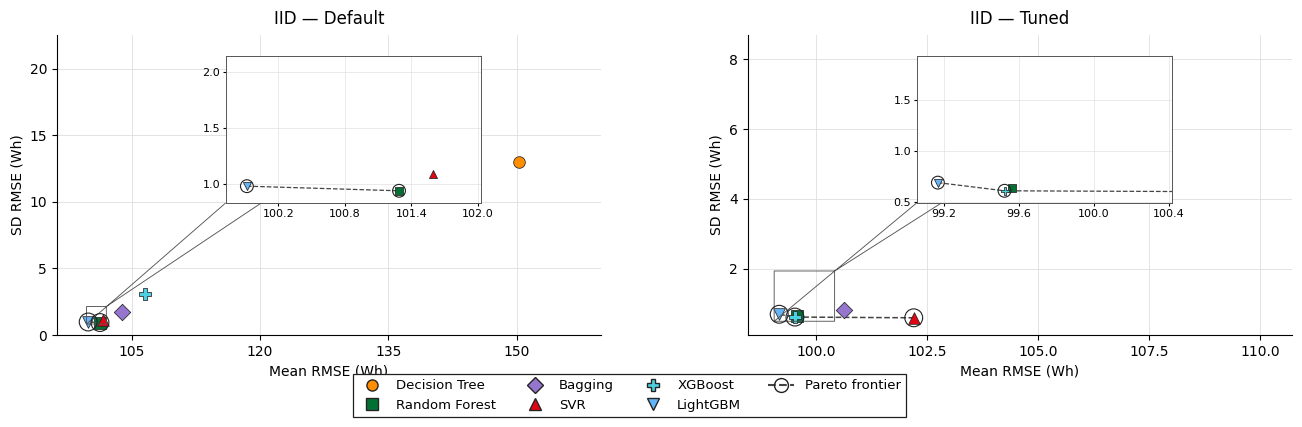

Figure 17a: PASS
Panels: 2
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17a_Pareto_Frontier_IID_RMSE.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17a_Pareto_Frontier_IID_RMSE.pdf

----------------------------------------------------------------------------
FIGURE 17b — MBB PARETO FRONTIER
----------------------------------------------------------------------------


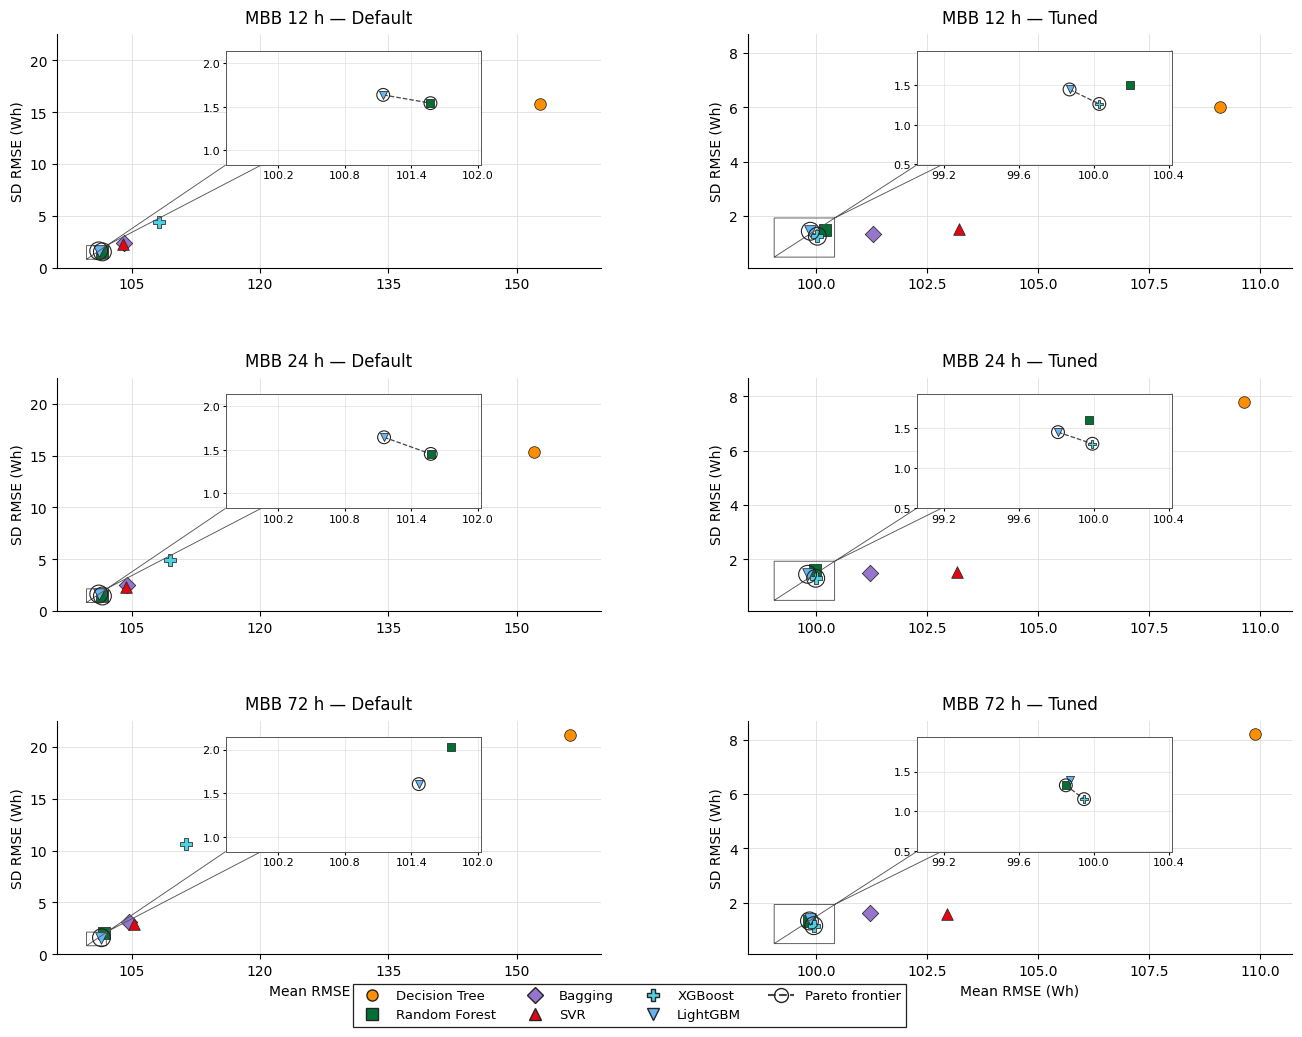

Figure 17b: PASS
Panels: 6
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17b_Pareto_Frontier_MBB_RMSE.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17b_Pareto_Frontier_MBB_RMSE.pdf

----------------------------------------------------------------------------
FIGURE 17c — SB PARETO FRONTIER
----------------------------------------------------------------------------


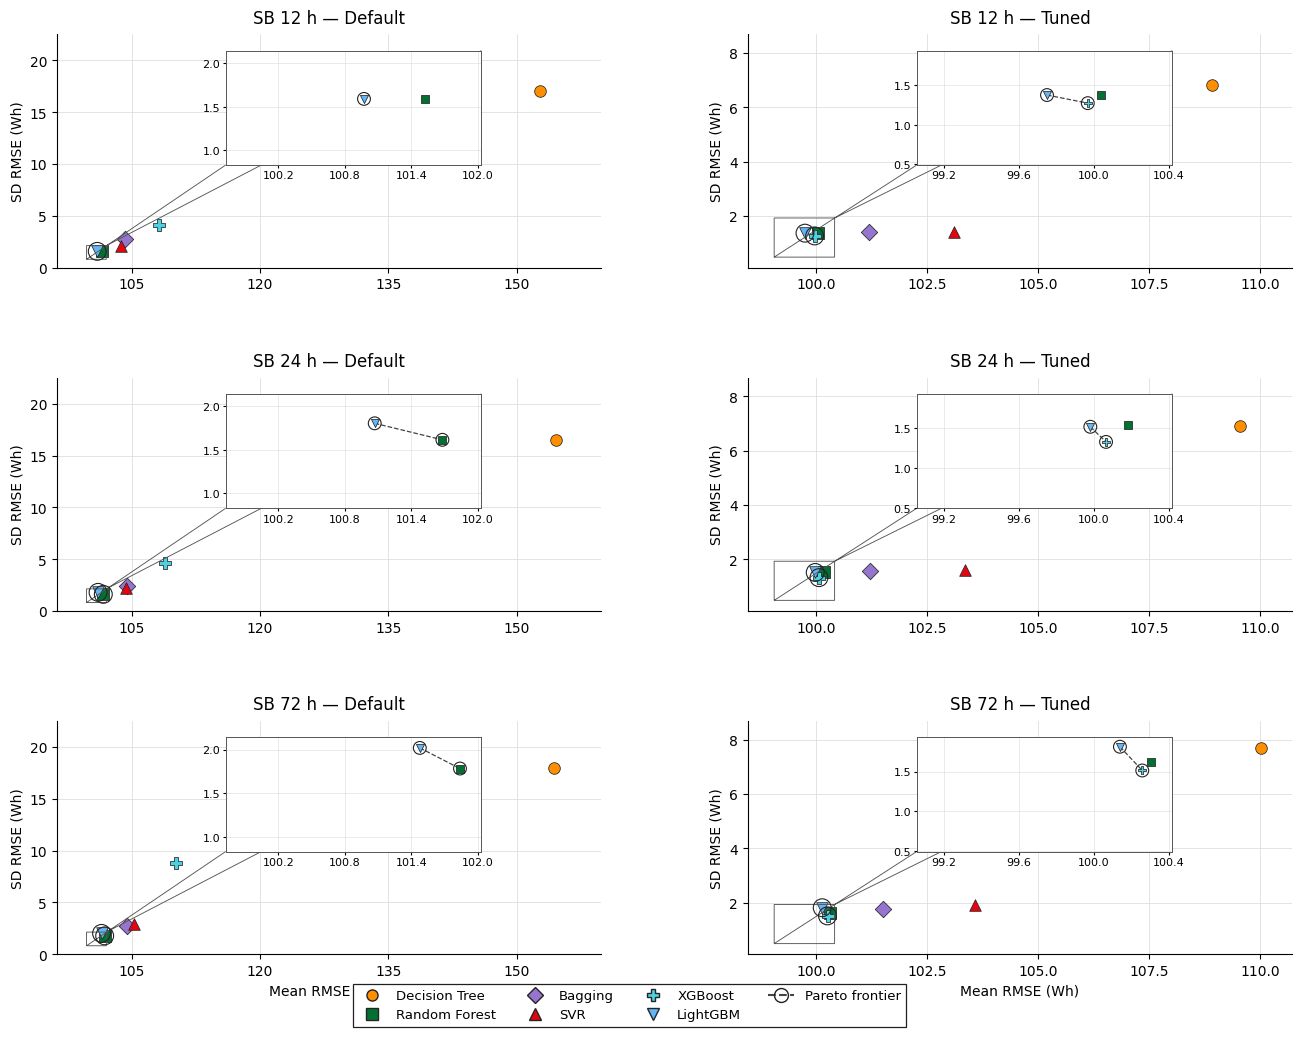

Figure 17c: PASS
Panels: 6
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17c_Pareto_Frontier_SB_RMSE.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig17c_Pareto_Frontier_SB_RMSE.pdf

CELL 08B-A — PARETO FRONTIER COMPLETED
Source integrity          : PASS
CSV content verification  : PASS

Figure 17a — IID          : PASS
Figure 17b — MBB          : PASS
Figure 17c — SB           : PASS

Total figures             : 3
Total panels              : 14
Total zoomed insets       : 14
Bootstrap conditions      : 7
Algorithms per panel      : 6

Model observations removed: NO
Pareto recalculated       : NO
Model refitting           : NO
Hyperparameter retuning    : NO
Test accessed             : NO

PART A STATUS: PASS
Final Cell 08B audit pending.


In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 08B-A
# ACCURACY–STABILITY PARETO FRONTIER VISUALIZATION
#
# Figure 17a : IID Bootstrap
# Figure 17b : Moving Block Bootstrap
# Figure 17c : Stationary Bootstrap
#
# Default and Tuned with zoomed insets
# Source: Notebook 04 — Cell 08
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import hashlib
import json

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


# =============================================================================
# 1. SOURCE AND ARTIFACT VERIFICATION
# =============================================================================

def ensure08ba(condition, message):

    if not condition:
        raise RuntimeError(message)


def sha256_08ba(path):

    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


audit_path08ba = (
    Path(AUDIT_OUTPUT_DIR)
    / "NB04_Cell08_accuracy_stability_tradeoff_audit.json"
)

audit08ba = json.loads(
    audit_path08ba.read_text(encoding="utf-8")
)

ensure08ba(
    audit08ba["status"] == "PASS"
    and audit08ba["test_accessed"] is False
    and sha256_08ba(METRICS_PATH)
    == audit08ba["source_metrics_sha256"],
    "Source audit mismatch."
)

meta08ba = audit08ba["outputs"]["pareto_membership"]

ensure08ba(
    sha256_08ba(meta08ba["path"])
    == meta08ba["sha256"],
    "Pareto CSV checksum mismatch."
)

# Preserve literal "None" strings.
# Actual empty fields remain missing values.

saved08ba = pd.read_csv(
    meta08ba["path"],
    keep_default_na=False,
    na_values=[""],
    low_memory=False
)

ensure08ba(
    len(saved08ba) == meta08ba["rows"] == 336,
    "Unexpected membership rows."
)

pd.testing.assert_frame_equal(

    df_pareto_membership08
    .reset_index(drop=True)
    .rename_axis(index=None, columns=None),

    saved08ba
    .reset_index(drop=True)
    .rename_axis(index=None, columns=None),

    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)

print("=" * 76)
print("CELL 08B-A — PARETO FRONTIER VISUALIZATION")
print("=" * 76)

print("Cell 08 source integrity : PASS")
print("Pareto artifact checksum : PASS")
print("CSV content verification : PASS")


# =============================================================================
# 2. EXPERIMENT DEFINITIONS
# =============================================================================

algos08ba = list(ALGORITHMS08)

conds08ba = list(CONDITIONS08)

settings08ba = [
    "default",
    "tuned"
]

labels08ba = CONDITION_LABELS08


colors08ba = dict(zip(

    algos08ba,

    [
        "#FF8F00",  # Decision Tree
        "#027033",  # Random Forest
        "#9575CD",  # Bagging
        "#E20613",  # SVR
        "#4DD0E1",  # XGBoost
        "#64B5F6"   # LightGBM
    ]
))


markers08ba = dict(zip(

    algos08ba,

    [
        "o",
        "s",
        "D",
        "^",
        "P",
        "v"
    ]
))


groups08ba = [

    (
        "17a",
        "IID",
        conds08ba[:1]
    ),

    (
        "17b",
        "MBB",
        conds08ba[1:4]
    ),

    (
        "17c",
        "SB",
        conds08ba[4:7]
    )
]


# =============================================================================
# 3. PREPARE EXISTING PARETO MEMBERSHIP DATA
#
# Reuse Cell 08 results.
# No Pareto dominance recalculation.
# =============================================================================

p08ba = df_pareto_membership08.loc[

    df_pareto_membership08["metric"].eq(
        "rmse_wh"
    )

    & df_pareto_membership08[
        "comparison_scope"
    ].isin(settings08ba)

].copy()


ensure08ba(

    len(p08ba) == 84

    and not p08ba.duplicated([

        "condition",
        "algorithm",
        "setting"

    ]).any(),

    "Invalid plot data."
)


ensure08ba(

    p08ba["setting"]
    .eq(p08ba["comparison_scope"])
    .all()

    and np.isfinite(

        p08ba[[
            "mean_error_wh",
            "sd_error_wh"
        ]].to_numpy()

    ).all(),

    "Invalid objective values."
)


ensure08ba(

    p08ba.groupby([
        "condition",
        "setting"
    ]).size().eq(6).all(),

    "Incomplete plot panels."
)

print("Pareto visualization data: PASS")
print("Model configurations      : 84")
print("Bootstrap conditions      : 7")
print("Algorithms                : 6")
print("Settings                  : 2")


# =============================================================================
# 4. DEFINE CONSISTENT AXIS LIMITS
#
# Main plot:
# All six algorithms remain visible.
#
# Inset:
# Default — Random Forest and LightGBM region
# Tuned   — Random Forest, XGBoost, and LightGBM region
#
# Other models falling inside the inset range
# are also displayed.
#
# Identical limits across bootstrap conditions
# within each setting.
# =============================================================================

def bounds08ba(frame, pad):

    limits = []

    for column in [

        "mean_error_wh",
        "sd_error_wh"

    ]:

        lo = frame[column].min()
        hi = frame[column].max()

        margin = max(
            float(hi - lo) * pad,
            1e-6
        )

        limits.append((

            max(0, float(lo) - margin),

            float(hi) + margin
        ))

    return limits


zoom_algos08ba = {

    "default": [
        "Random Forest",
        "LightGBM"
    ],

    "tuned": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ]
}


full_limits08ba = {

    setting: bounds08ba(

        p08ba.loc[
            p08ba["setting"].eq(setting)
        ],

        pad=0.065
    )

    for setting in settings08ba
}


zoom_limits08ba = {

    setting: bounds08ba(

        p08ba.loc[

            p08ba["setting"].eq(setting)

            & p08ba["algorithm"].isin(
                zoom_algos08ba[setting]
            )
        ],

        pad=0.10
    )

    for setting in settings08ba
}


# =============================================================================
# 5. APPROVED PUBLICATION STYLE
# =============================================================================

style08ba = {

    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",

    "axes.titleweight": "normal",
    "axes.labelweight": "normal",

    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "pdf.fonttype": 42,
    "ps.fonttype": 42
}


# =============================================================================
# 6. PARETO SCATTER PLOT FUNCTION
#
# Additional black outline indicates Pareto membership.
# Dashed line connects existing non-dominated solutions.
#
# The dashed line does not represent additional
# attainable model configurations.
# =============================================================================

def plot_points08ba(
    ax,
    sub,
    inset=False
):

    frontier = (

        sub.loc[
            sub["is_pareto_optimal"]
        ]

        .sort_values("mean_error_wh")
    )

    if len(frontier) > 1:

        ax.plot(

            frontier["mean_error_wh"],

            frontier["sd_error_wh"],

            color="#444444",
            linestyle="--",

            linewidth=0.9 if inset else 1.1,

            zorder=2
        )


    for algorithm in algos08ba:

        row = sub.loc[algorithm]

        x = row["mean_error_wh"]

        y = row["sd_error_wh"]


        ax.scatter(

            x,
            y,

            s=34 if inset else 70,

            color=colors08ba[algorithm],

            marker=markers08ba[algorithm],

            edgecolors="#242424",
            linewidths=0.55,

            zorder=4
        )


        # Additional outline for Pareto frontier members.

        if row["is_pareto_optimal"]:

            ax.scatter(

                x,
                y,

                s=85 if inset else 165,

                facecolors="none",

                edgecolors="#222222",

                linewidths=0.8,

                zorder=5
            )


    ax.grid(

        color="#DEDEDE",

        linewidth=0.45 if inset else 0.6
    )

    ax.set_axisbelow(True)


# =============================================================================
# 7. SHARED LEGEND
# =============================================================================

handles08ba = [

    Line2D(

        [0],
        [0],

        marker=markers08ba[algorithm],

        markerfacecolor=colors08ba[algorithm],

        markeredgecolor="#242424",

        linestyle="None",

        markersize=8,

        label=algorithm
    )

    for algorithm in algos08ba
]


handles08ba.append(

    Line2D(

        [0],
        [0],

        marker="o",

        markerfacecolor="none",
        markeredgecolor="#222222",

        linestyle="--",

        color="#444444",

        markersize=10,

        label="Pareto frontier"
    )
)


# =============================================================================
# 8. GENERATE FIGURES 17a, 17b, AND 17c
#
# IID : 1 row  x 2 columns
# MBB : 3 rows x 2 columns
# SB  : 3 rows x 2 columns
# =============================================================================

Path(FIGURE_DIR).mkdir(

    parents=True,

    exist_ok=True
)


FIGURE_OUTPUTS08B_A = []


with plt.rc_context(style08ba):

    for number, method, conditions in groups08ba:

        n_rows = len(conditions)

        print("\n" + "-" * 76)

        print(
            f"FIGURE {number} — {method} PARETO FRONTIER"
        )

        print("-" * 76)


        fig, axes = plt.subplots(

            nrows=n_rows,

            ncols=2,

            figsize=(
                13.8,
                3.1 * n_rows + 1.2
            ),

            squeeze=False
        )


        for i, condition in enumerate(conditions):

            for j, setting in enumerate(settings08ba):

                ax = axes[i, j]


                subset = (

                    p08ba.loc[

                        p08ba["condition"].eq(
                            condition
                        )

                        & p08ba["setting"].eq(
                            setting
                        )
                    ]

                    .set_index("algorithm")

                    .reindex(algos08ba)
                )


                ensure08ba(

                    len(subset) == 6

                    and subset[
                        "mean_error_wh"
                    ].notna().all(),

                    "Missing model in panel."
                )


                # -----------------------------------------------------
                # A. MAIN SCATTER PLOT
                # -----------------------------------------------------

                plot_points08ba(

                    ax,

                    subset
                )


                ax.set_title(

                    f"{labels08ba[condition]} — "
                    f"{setting.capitalize()}",

                    pad=8,

                    fontweight="normal"
                )


                ax.set_xlim(
                    *full_limits08ba[setting][0]
                )

                ax.set_ylim(
                    *full_limits08ba[setting][1]
                )


                ax.xaxis.set_major_locator(
                    MaxNLocator(5)
                )

                ax.yaxis.set_major_locator(
                    MaxNLocator(5)
                )


                ax.set_ylabel(
                    "SD RMSE (Wh)"
                )


                if i == n_rows - 1:

                    ax.set_xlabel(
                        "Mean RMSE (Wh)"
                    )


                ax.spines["top"].set_visible(False)

                ax.spines["right"].set_visible(False)


                # -----------------------------------------------------
                # B. ZOOMED INSET
                #
                # Inset uses identical underlying observations.
                # Only the visible axis range is restricted.
                # -----------------------------------------------------

                inset = ax.inset_axes([

                    0.31,  # horizontal position

                    0.44,  # vertical position

                    0.47,  # width

                    0.49   # height
                ])


                plot_points08ba(

                    inset,

                    subset,

                    inset=True
                )


                inset.set_xlim(
                    *zoom_limits08ba[setting][0]
                )

                inset.set_ylim(
                    *zoom_limits08ba[setting][1]
                )


                inset.xaxis.set_major_locator(
                    MaxNLocator(4)
                )

                inset.yaxis.set_major_locator(
                    MaxNLocator(3)
                )


                inset.tick_params(

                    labelsize=8,

                    length=2,

                    pad=2
                )


                for spine in inset.spines.values():

                    spine.set_linewidth(0.7)

                    spine.set_color("#555555")


                # Mark the magnified region.

                ax.indicate_inset_zoom(

                    inset,

                    edgecolor="#555555",

                    alpha=1,

                    linewidth=0.65
                )


        # -------------------------------------------------------------
        # C. ONE BOXED LEGEND BELOW THE COMPLETE FIGURE
        # -------------------------------------------------------------

        legend = fig.legend(

            handles=handles08ba,

            ncol=4,

            loc="lower center",

            bbox_to_anchor=(0.5, 0.015),

            frameon=True,

            fancybox=False,

            framealpha=1,

            facecolor="white",

            edgecolor="#202020",

            fontsize=9.5
        )

        legend.get_frame().set_linewidth(
            0.9
        )


        fig.subplots_adjust(

            left=0.085,

            right=0.98,

            top=1 - 0.35 / fig.get_figheight(),

            bottom=0.95 / fig.get_figheight(),

            wspace=0.27,

            hspace=0.47
        )


        # -------------------------------------------------------------
        # D. EXPORT PNG AND VECTOR PDF
        # -------------------------------------------------------------

        stem = (

            Path(FIGURE_DIR)

            / f"NB04_Fig{number}_Pareto_Frontier_{method}_RMSE"
        )


        png_path = stem.with_suffix(
            ".png"
        )

        pdf_path = stem.with_suffix(
            ".pdf"
        )


        fig.savefig(

            png_path,

            dpi=300,

            bbox_inches="tight",

            pad_inches=0.10,

            facecolor="white"
        )


        fig.savefig(

            pdf_path,

            bbox_inches="tight",

            pad_inches=0.10,

            facecolor="white"
        )


        plt.show()

        plt.close(fig)


        ensure08ba(

            png_path.stat().st_size > 0

            and pdf_path.stat().st_size > 0,

            "Figure export failed."
        )


        FIGURE_OUTPUTS08B_A.append({

            "figure_number": number,

            "method": method,

            "panels": n_rows * 2,

            "png": str(png_path),

            "pdf": str(pdf_path),

            "png_sha256":
                sha256_08ba(png_path),

            "pdf_sha256":
                sha256_08ba(pdf_path)
        })


        print(
            f"Figure {number}: PASS"
        )

        print(
            f"Panels: {n_rows * 2}"
        )

        print(
            "PNG:", png_path
        )

        print(
            "PDF:", pdf_path
        )


# =============================================================================
# 9. FINAL PART A VERIFICATION
# =============================================================================

ensure08ba(

    len(FIGURE_OUTPUTS08B_A) == 3

    and sum(

        item["panels"]

        for item in FIGURE_OUTPUTS08B_A

    ) == 14,

    "Incomplete figure or panel coverage."
)


print("\n" + "=" * 76)

print("CELL 08B-A — PARETO FRONTIER COMPLETED")

print("=" * 76)

print("Source integrity          : PASS")
print("CSV content verification  : PASS")

print("\nFigure 17a — IID          : PASS")
print("Figure 17b — MBB          : PASS")
print("Figure 17c — SB           : PASS")

print("\nTotal figures             : 3")
print("Total panels              : 14")
print("Total zoomed insets       : 14")
print("Bootstrap conditions      : 7")
print("Algorithms per panel      : 6")

print("\nModel observations removed: NO")
print("Pareto recalculated       : NO")
print("Model refitting           : NO")
print("Hyperparameter retuning    : NO")
print("Test accessed             : NO")

print("\nPART A STATUS: PASS")
print("Final Cell 08B audit pending.")


CELL 08B-B — PARETO MEMBERSHIP AND ROBUSTNESS
pareto_membership: PASS
pareto_robustness: PASS
Membership and robustness consistency: PASS

FIGURE 18 — PARETO MEMBERSHIP MATRIX


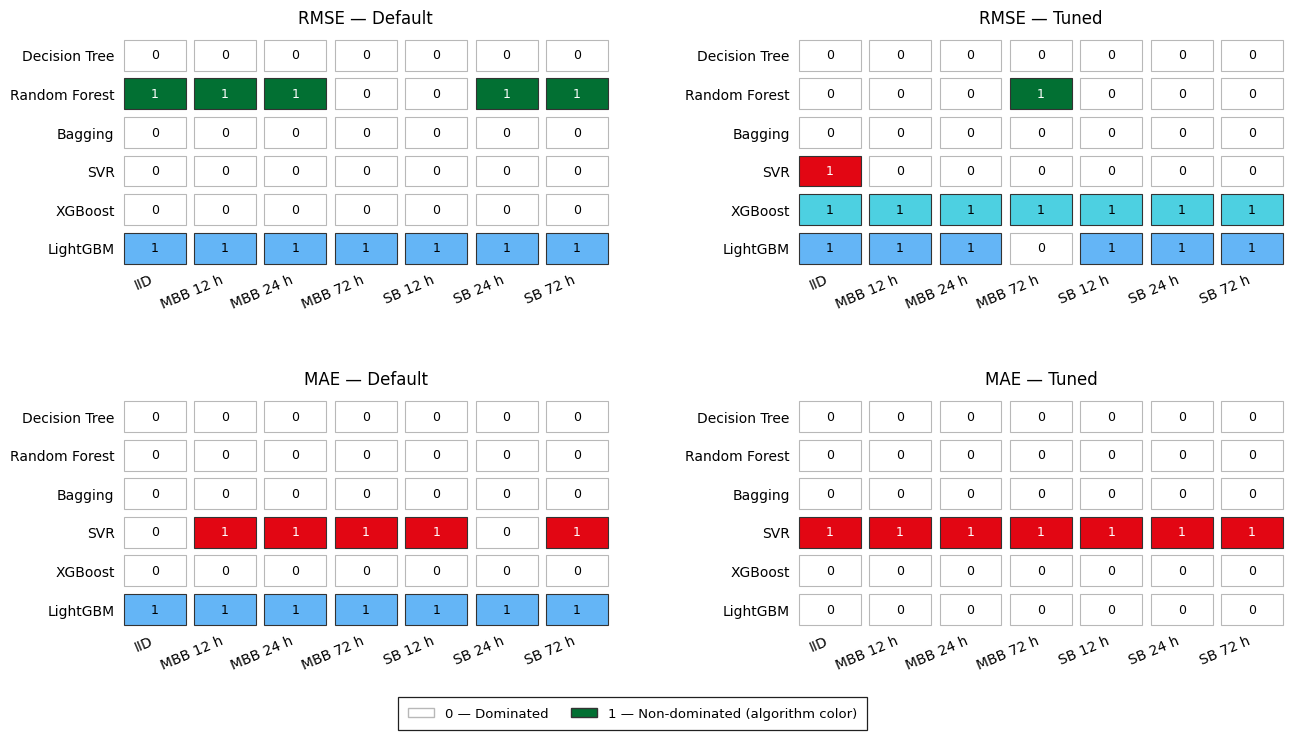

Figure 18: PASS
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig18_Pareto_Membership_Matrix.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig18_Pareto_Membership_Matrix.pdf

FIGURE 19 — CROSS-CONDITION PARETO ROBUSTNESS


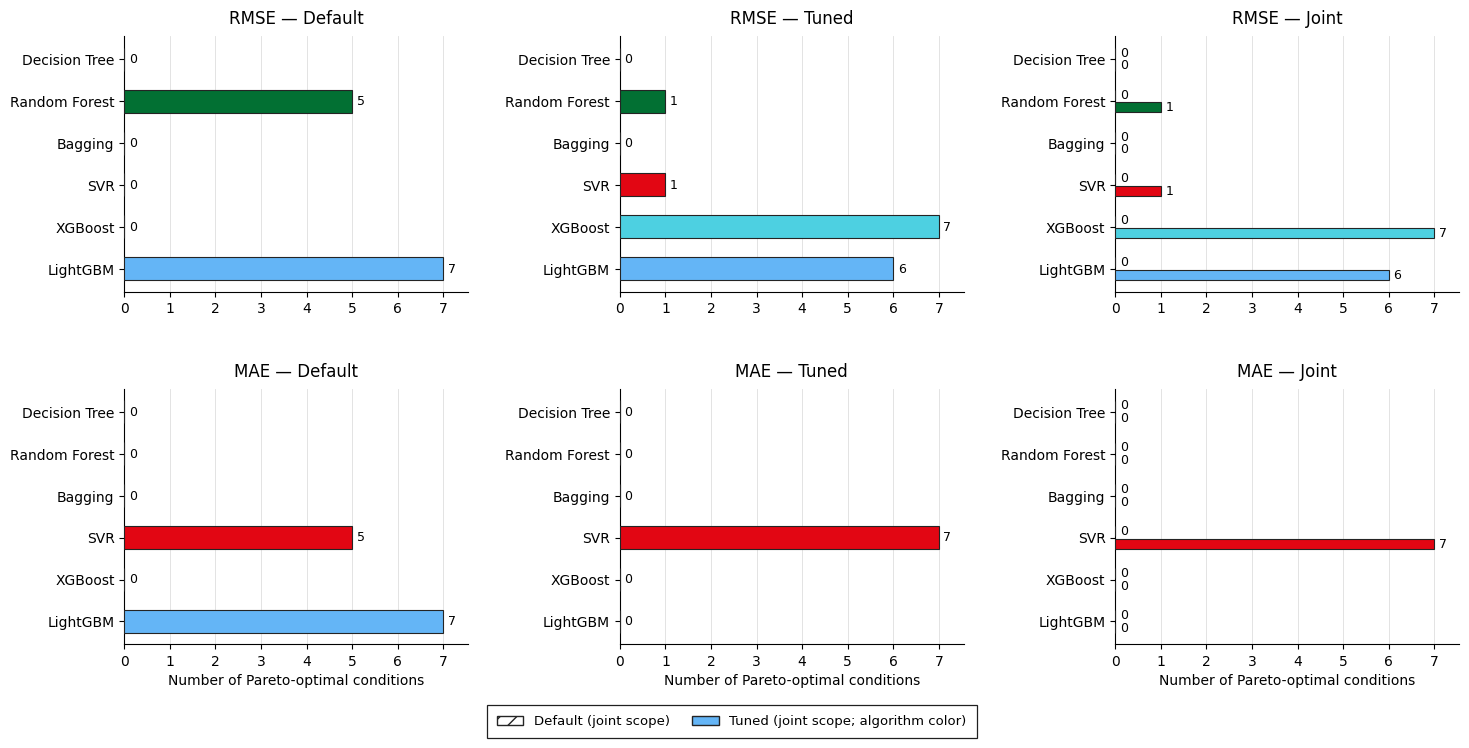

Figure 19: PASS
PNG: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig19_Cross_Condition_Pareto_Robustness.png
PDF: /content/drive/MyDrive/Stability_Driven_Energy/05_stability_analysis/figures/NB04_Fig19_Cross_Condition_Pareto_Robustness.pdf

CELL 08B-B — VISUALIZATION COMPLETED
Cell 08 source integrity          : PASS
Pareto membership artifact        : PASS
Pareto robustness artifact        : PASS
Membership and robustness linkage : PASS
CSV content verification          : PASS

Figure 18 — Membership matrix    : PASS
Figure 19 — Pareto robustness     : PASS

Figure 18 panels                 : 4
Figure 18 categorical cells       : 168
Figure 19 panels                  : 6
Figure 19 membership counts       : 48
Figure files                      : 4

Pareto dominance recalculated    : NO
Model refitting                   : NO
New bootstrap                     : NO
Hyperparameter retuning           : NO
Test accessed                     : NO

AUDIT
/c

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 08B-B
# PARETO MEMBERSHIP AND ROBUSTNESS VISUALIZATION
#
# Figure 18 : Categorical Pareto membership matrix
# Figure 19 : Cross-condition Pareto robustness
#
# Source: Notebook 04 — Cell 08
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP | NO TEST ACCESS
# =============================================================================

import os
import json
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle, Patch


# =============================================================================
# 1. SOURCE AND ARTIFACT VERIFICATION
# =============================================================================

def ensure08bb(ok, message):

    if not ok:
        raise RuntimeError(message)


def sha256_08bb(path):

    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


print("=" * 76)
print("CELL 08B-B — PARETO MEMBERSHIP AND ROBUSTNESS")
print("=" * 76)


source_audit08bb = (

    Path(AUDIT_OUTPUT_DIR)

    / "NB04_Cell08_accuracy_stability_tradeoff_audit.json"
)


audit08bb = json.loads(

    source_audit08bb.read_text(
        encoding="utf-8"
    )
)


ensure08bb(

    audit08bb["status"] == "PASS"

    and audit08bb["bootstrap_size"] == 300

    and audit08bb["original_fitting_records"] == 25200

    and audit08bb["test_accessed"] is False

    and sha256_08bb(METRICS_PATH)
    == audit08bb["source_metrics_sha256"],

    "Cell 08 source audit mismatch."
)


verified08bb = {}


for name, frame, n in [

    (
        "pareto_membership",
        df_pareto_membership08,
        336
    ),

    (
        "pareto_robustness",
        df_pareto_robustness08,
        48
    )
]:

    meta = audit08bb["outputs"][name]

    ensure08bb(

        sha256_08bb(meta["path"])
        == meta["sha256"],

        f"Checksum mismatch: {name}"
    )

    # Preserve literal "None" strings.
    # Actual empty fields remain missing values.

    saved = pd.read_csv(

        meta["path"],

        keep_default_na=False,

        na_values=[""],

        low_memory=False
    )

    ensure08bb(

        len(saved)
        == len(frame)
        == meta["rows"]
        == n,

        f"Row count mismatch: {name}"
    )

    pd.testing.assert_frame_equal(

        frame
        .reset_index(drop=True)
        .rename_axis(
            index=None,
            columns=None
        ),

        saved
        .reset_index(drop=True)
        .rename_axis(
            index=None,
            columns=None
        ),

        check_dtype=False,

        check_exact=False,

        rtol=1e-10,

        atol=1e-10
    )

    verified08bb[name] = meta["sha256"]

    print(
        f"{name}: PASS"
    )


# =============================================================================
# 2. EXPERIMENT DEFINITIONS
# =============================================================================

algos08bb = list(ALGORITHMS08)

conds08bb = list(CONDITIONS08)


settings08bb = [
    "default",
    "tuned"
]


metrics08bb = [
    "rmse_wh",
    "mae_wh"
]


scopes08bb = [
    "default",
    "tuned",
    "joint"
]


labels08bb = [

    CONDITION_LABELS08[c]

    for c in conds08bb
]


metric_labels08bb = {

    "rmse_wh": "RMSE",

    "mae_wh": "MAE"
}


colors08bb = dict(zip(

    algos08bb,

    [

        "#FF8F00",  # Decision Tree

        "#027033",  # Random Forest

        "#9575CD",  # Bagging

        "#E20613",  # SVR

        "#4DD0E1",  # XGBoost

        "#64B5F6"   # LightGBM
    ]
))


ensure08bb(

    algos08bb == [

        "Decision Tree",

        "Random Forest",

        "Bagging",

        "SVR",

        "XGBoost",

        "LightGBM"
    ]

    and len(conds08bb) == 7,

    "Experiment definitions mismatch."
)


# =============================================================================
# 3. PREPARE AND VERIFY VISUALIZATION DATA
#
# Reuse Cell 08 results.
# No Pareto dominance recalculation.
# =============================================================================

membership08bb = (
    df_pareto_membership08.copy()
)

robustness08bb = (
    df_pareto_robustness08.copy()
)


keys08bb = [

    "metric",

    "comparison_scope",

    "algorithm",

    "setting"
]


ensure08bb(

    not membership08bb.duplicated(

        keys08bb + ["condition"]

    ).any(),

    "Duplicate membership records."
)


ensure08bb(

    not robustness08bb.duplicated(
        keys08bb
    ).any(),

    "Duplicate robustness records."
)


expected08bb = {

    (
        metric,
        scope,
        algorithm,
        setting,
        condition
    )

    for metric in metrics08bb

    for scope in scopes08bb

    for algorithm in algos08bb

    for setting in settings08bb

    if scope == "joint" or setting == scope

    for condition in conds08bb
}


observed08bb = set(

    membership08bb[
        keys08bb + ["condition"]
    ]

    .itertuples(
        index=False,
        name=None
    )
)


ensure08bb(

    observed08bb == expected08bb,

    "Incomplete membership design."
)


ensure08bb(

    membership08bb["is_pareto_optimal"]

    .isin([True, False])

    .all(),

    "Invalid membership values."
)


# Verify robustness counts against individual
# Pareto membership indicators.

counts08bb = (

    membership08bb

    .groupby(keys08bb)["is_pareto_optimal"]

    .sum()

    .sort_index()
)


robust_lookup08bb = (

    robustness08bb

    .set_index(keys08bb)[
        "conditions_pareto_optimal"
    ]

    .sort_index()
)


pd.testing.assert_series_equal(

    counts08bb,

    robust_lookup08bb,

    check_names=False,

    check_dtype=False
)


ensure08bb(

    robust_lookup08bb.between(0, 7).all(),

    "Invalid robustness counts."
)


print("Membership and robustness consistency: PASS")


# =============================================================================
# 4. APPROVED PUBLICATION STYLE
# =============================================================================

style08bb = {

    "font.family": "DejaVu Sans",

    "font.size": 10,

    "font.weight": "normal",

    "axes.titleweight": "normal",

    "axes.labelweight": "normal",

    "axes.labelcolor": "black",

    "text.color": "black",

    "xtick.color": "black",

    "ytick.color": "black",

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "pdf.fonttype": 42,

    "ps.fonttype": 42
}


Path(FIGURE_DIR).mkdir(

    parents=True,

    exist_ok=True
)


FIGURE_OUTPUTS08B_B = []


part_audit08bb = (

    Path(AUDIT_OUTPUT_DIR)

    / "NB04_Cell08B_B_membership_robustness_audit.json"
)


part_audit08bb.unlink(
    missing_ok=True
)


# =============================================================================
# 5. LEGEND AND EXPORT FUNCTIONS
# =============================================================================

def boxed_legend08bb(
    fig,
    handles
):

    legend = fig.legend(

        handles=handles,

        ncol=2,

        loc="lower center",

        bbox_to_anchor=(0.5, 0.02),

        frameon=True,

        fancybox=False,

        framealpha=1,

        facecolor="white",

        edgecolor="#202020",

        borderpad=0.75,

        columnspacing=1.7,

        fontsize=9.5
    )

    legend.get_frame().set_linewidth(
        0.9
    )


def export08bb(
    fig,
    number,
    filename,
    panels
):

    stem = Path(FIGURE_DIR) / filename

    png = stem.with_suffix(".png")

    pdf = stem.with_suffix(".pdf")


    for path in [png, pdf]:

        fig.savefig(

            path,

            dpi=300,

            bbox_inches="tight",

            pad_inches=0.10,

            facecolor="white"
        )

        ensure08bb(

            path.is_file()

            and path.stat().st_size > 0,

            f"Export failed: {path}"
        )


    FIGURE_OUTPUTS08B_B.append({

        "figure_number": number,

        "panels": panels,

        "png": str(png),

        "pdf": str(pdf),

        "png_sha256": sha256_08bb(png),

        "pdf_sha256": sha256_08bb(pdf)
    })


    plt.show()

    plt.close(fig)


    print(
        f"Figure {number}: PASS"
    )

    print("PNG:", png)

    print("PDF:", pdf)


# =============================================================================
# 6. FIGURE 18 — CATEGORICAL PARETO MEMBERSHIP MATRIX
#
# Layout:
#
# RMSE — Default | RMSE — Tuned
# MAE  — Default | MAE  — Tuned
#
# Rows    : Six algorithms
# Columns : Seven bootstrap conditions
#
# 1 = Non-dominated
# 0 = Dominated
#
# Solid colors represent algorithm identity.
# No continuous color gradient.
# =============================================================================

print("\n" + "=" * 76)

print("FIGURE 18 — PARETO MEMBERSHIP MATRIX")

print("=" * 76)


with plt.rc_context(style08bb):

    fig, axes = plt.subplots(

        nrows=2,

        ncols=2,

        figsize=(13.5, 7.7)
    )


    n_cells08bb = 0


    for i, metric in enumerate(metrics08bb):

        for j, setting in enumerate(settings08bb):

            ax = axes[i, j]


            subset = membership08bb.loc[

                membership08bb["metric"]
                .eq(metric)

                & membership08bb["comparison_scope"]
                .eq(setting)
            ]


            matrix = (

                subset.pivot(

                    index="algorithm",

                    columns="condition",

                    values="is_pareto_optimal"
                )

                .reindex(

                    index=algos08bb,

                    columns=conds08bb
                )
            )


            ensure08bb(

                not matrix.isna().any().any(),

                "Incomplete Figure 18 matrix."
            )


            # ---------------------------------------------------------
            # Draw categorical membership cells
            # ---------------------------------------------------------

            for k, algorithm in enumerate(
                algos08bb
            ):

                for l, condition in enumerate(
                    conds08bb
                ):

                    is_member = bool(

                        matrix.loc[
                            algorithm,
                            condition
                        ]
                    )


                    facecolor = (

                        colors08bb[algorithm]

                        if is_member

                        else "#FFFFFF"
                    )


                    edgecolor = (

                        "#333333"

                        if is_member

                        else "#B8B8B8"
                    )


                    ax.add_patch(

                        Rectangle(

                            (l - 0.44, k - 0.40),

                            width=0.88,

                            height=0.80,

                            facecolor=facecolor,

                            edgecolor=edgecolor,

                            linewidth=0.8
                        )
                    )


                    # White text is used only for
                    # dark-colored membership cells.

                    text_color = (

                        "white"

                        if is_member

                        and algorithm in [
                            "Random Forest",
                            "SVR"
                        ]

                        else "black"
                    )


                    ax.text(

                        l,

                        k,

                        "1" if is_member else "0",

                        ha="center",

                        va="center",

                        fontsize=9,

                        color=text_color
                    )


                    n_cells08bb += 1


            # ---------------------------------------------------------
            # Axis formatting
            # ---------------------------------------------------------

            ax.set_xlim(
                -0.5,
                6.5
            )

            ax.set_ylim(
                5.5,
                -0.5
            )


            ax.set_xticks(

                range(7),

                labels08bb,

                rotation=23,

                ha="right"
            )


            ax.set_yticks(

                range(6),

                algos08bb
            )


            ax.tick_params(
                length=0
            )


            ax.set_title(

                f"{metric_labels08bb[metric]}"
                f" — {setting.capitalize()}",

                pad=9
            )


            for spine in ax.spines.values():

                spine.set_visible(False)


    ensure08bb(

        n_cells08bb == 168,

        "Incomplete Figure 18 coverage."
    )


    # -------------------------------------------------------------
    # Shared boxed legend
    # -------------------------------------------------------------

    handles18 = [

        Patch(

            facecolor="#FFFFFF",

            edgecolor="#B8B8B8",

            label="0 — Dominated"
        ),

        Patch(

            facecolor="#027033",

            edgecolor="#333333",

            label="1 — Non-dominated (algorithm color)"
        )
    ]


    boxed_legend08bb(

        fig,

        handles18
    )


    fig.subplots_adjust(

        left=0.12,

        right=0.985,

        top=0.93,

        bottom=0.16,

        wspace=0.37,

        hspace=0.56
    )


    export08bb(

        fig,

        number=18,

        filename=(
            "NB04_Fig18_Pareto_Membership_Matrix"
        ),

        panels=4
    )


# =============================================================================
# 7. FIGURE 19 — CROSS-CONDITION PARETO ROBUSTNESS
#
# Layout:
#
# RMSE — Default | RMSE — Tuned | RMSE — Joint
# MAE  — Default | MAE  — Tuned | MAE  — Joint
#
# X-axis: Number of Pareto-optimal conditions (0–7)
#
# Default scope: Six default configurations
# Tuned scope  : Six tuned configurations
# Joint scope  : All twelve configurations
#
# Joint scope:
#   Hatched white bar = Default
#   Solid colored bar = Tuned
#
# Frequencies are descriptive counts, not probabilities.
# =============================================================================

print("\n" + "=" * 76)

print("FIGURE 19 — CROSS-CONDITION PARETO ROBUSTNESS")

print("=" * 76)


with plt.rc_context(style08bb):

    fig, axes = plt.subplots(

        nrows=2,

        ncols=3,

        figsize=(15, 7.7),

        sharex=True,

        sharey=True
    )


    n_counts08bb = 0


    for i, metric in enumerate(metrics08bb):

        for j, scope in enumerate(scopes08bb):

            ax = axes[i, j]


            for k, algorithm in enumerate(
                algos08bb
            ):

                selected_settings = (

                    settings08bb

                    if scope == "joint"

                    else [scope]
                )


                for z, setting in enumerate(
                    selected_settings
                ):

                    n = int(

                        robust_lookup08bb.loc[

                            (
                                metric,

                                scope,

                                algorithm,

                                setting
                            )
                        ]
                    )


                    # Separate Default and Tuned
                    # within the Joint scope.

                    y_position = (

                        k + (z - 0.5) * 0.30

                        if scope == "joint"

                        else k
                    )


                    joint_default = (

                        scope == "joint"

                        and setting == "default"
                    )


                    ax.barh(

                        y_position,

                        n,

                        height=(
                            0.24
                            if scope == "joint"
                            else 0.55
                        ),

                        color=(

                            "#FFFFFF"

                            if joint_default

                            else colors08bb[algorithm]
                        ),

                        edgecolor="#242424",

                        linewidth=0.8,

                        hatch=(

                            "//"

                            if joint_default

                            else None
                        ),

                        zorder=3
                    )


                    # Display exact membership frequency.
                    # Zero counts remain explicitly visible.

                    ax.text(

                        n + 0.10,

                        y_position,

                        str(n),

                        va="center",

                        fontsize=9
                    )


                    n_counts08bb += 1


            # ---------------------------------------------------------
            # Axis formatting
            # ---------------------------------------------------------

            ax.set_yticks(

                range(6),

                algos08bb
            )


            ax.tick_params(

                labelleft=True,

                labelbottom=True
            )


            ax.set_ylim(
                5.55,
                -0.55
            )


            ax.set_xlim(
                0,
                7.55
            )


            ax.set_xticks(
                range(8)
            )


            ax.set_title(

                f"{metric_labels08bb[metric]}"
                f" — {scope.capitalize()}",

                pad=9
            )


            if i == 1:

                ax.set_xlabel(

                    "Number of Pareto-optimal conditions"
                )


            ax.grid(

                axis="x",

                color="#DEDEDE",

                linewidth=0.6
            )


            ax.set_axisbelow(True)


            ax.spines["top"].set_visible(False)

            ax.spines["right"].set_visible(False)


    ensure08bb(

        n_counts08bb == 48,

        "Incomplete Figure 19 coverage."
    )


    # -------------------------------------------------------------
    # Shared boxed legend
    # -------------------------------------------------------------

    handles19 = [

        Patch(

            facecolor="#FFFFFF",

            edgecolor="#242424",

            hatch="//",

            label="Default (joint scope)"
        ),

        Patch(

            facecolor="#64B5F6",

            edgecolor="#242424",

            label="Tuned (joint scope; algorithm color)"
        )
    ]


    boxed_legend08bb(

        fig,

        handles19
    )


    fig.subplots_adjust(

        left=0.095,

        right=0.985,

        top=0.94,

        bottom=0.15,

        wspace=0.44,

        hspace=0.38
    )


    export08bb(

        fig,

        number=19,

        filename=(
            "NB04_Fig19_Cross_Condition_Pareto_Robustness"
        ),

        panels=6
    )


# =============================================================================
# 8. FINAL FIGURE VERIFICATION
# =============================================================================

ensure08bb(

    [

        item["figure_number"]

        for item in FIGURE_OUTPUTS08B_B

    ] == [18, 19],

    "Incomplete figure outputs."
)


for item in FIGURE_OUTPUTS08B_B:

    for extension in ["png", "pdf"]:

        ensure08bb(

            sha256_08bb(item[extension])

            == item[f"{extension}_sha256"],

            "Figure checksum mismatch."
        )


# =============================================================================
# 9. REPRODUCIBILITY AUDIT — PART B
# =============================================================================

VISUAL_AUDIT08B_B = {

    "notebook": "04",

    "cell": "08B-B",

    "status": "PASS",

    "source_metrics_sha256":
        audit08bb["source_metrics_sha256"],

    "source_cell08_audit_sha256":
        sha256_08bb(source_audit08bb),

    "verified_artifacts":
        verified08bb,

    "bootstrap_size": 300,

    "figure_count": 2,

    "figure18_cells": n_cells08bb,

    "figure19_counts": n_counts08bb,

    "condition_count": 7,

    "figure19_frequency_is_population_probability":
        False,

    "pareto_recomputed": False,

    "model_refitting": False,

    "hyperparameter_retuning": False,

    "new_bootstrap": False,

    "test_accessed": False,

    "figures": FIGURE_OUTPUTS08B_B
}


temporary08bb = part_audit08bb.with_suffix(
    ".json.temporary"
)


temporary08bb.write_text(

    json.dumps(

        VISUAL_AUDIT08B_B,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    ),

    encoding="utf-8"
)


os.replace(

    temporary08bb,

    part_audit08bb
)


ensure08bb(

    json.loads(

        part_audit08bb.read_text(
            encoding="utf-8"
        )

    ) == VISUAL_AUDIT08B_B,

    "Audit round-trip mismatch."
)


# =============================================================================
# 10. FINAL REPORT
# =============================================================================

print("\n" + "=" * 76)

print("CELL 08B-B — VISUALIZATION COMPLETED")

print("=" * 76)

print("Cell 08 source integrity          : PASS")

print("Pareto membership artifact        : PASS")

print("Pareto robustness artifact        : PASS")

print("Membership and robustness linkage : PASS")

print("CSV content verification          : PASS")


print("\nFigure 18 — Membership matrix    : PASS")

print("Figure 19 — Pareto robustness     : PASS")


print("\nFigure 18 panels                 : 4")

print("Figure 18 categorical cells       : 168")

print("Figure 19 panels                  : 6")

print("Figure 19 membership counts       : 48")

print("Figure files                      : 4")


print("\nPareto dominance recalculated    : NO")

print("Model refitting                   : NO")

print("New bootstrap                     : NO")

print("Hyperparameter retuning           : NO")

print("Test accessed                     : NO")


print("\nAUDIT")

print(part_audit08bb)

print("\nPART B STATUS: PASS")


# 09: Final Audit and Handover

In [ ]:

# =============================================================================
# NOTEBOOK 04 — CELL 09
# FINAL PREDICTIVE STABILITY AUDIT AND HANDOVER
# FINAL REVISION — LEGACY MANIFEST AND FIGURE COMPATIBILITY
#
# Study:
# Stability-Driven Evaluation of Machine Learning Models
# for Appliance Energy Estimation
#
# Handover:
# NB05 — SHAP and Explanation Stability Analysis
# NB06 — Integrated Stability and Model Selection
# NB07 — Final Testing and Interpretation
#
# Revisions:
# 1. Compatible with B30, B100, and B300 manifest schemas.
# 2. Preserve all historical checksum verification.
# 3. Explicitly distinguish legacy and canonical figures.
# 4. Retain legacy figures without counting them twice.
# 5. Preserve literal "None" and actual missing values.
# 6. Explicit registry CSV serialization dtypes.
#
# NO REFITTING | NO RETUNING | NO NEW BOOTSTRAP
# NO SHAP COMPUTATION | NO FINAL MODEL SELECTION | NO TEST ACCESS
# =============================================================================

import os
import re
import json
import hashlib
import platform

from pathlib import Path
from itertools import product
from collections import defaultdict
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd

from IPython.display import display


# =============================================================================
# 1. REQUIRED NOTEBOOK PATHS
# =============================================================================

required09 = [
    "PROJECT_ROOT",
    "METRICS_PATH",
    "MANIFEST_PATH",
    "TABLE_DIR",
    "FIGURE_DIR",
    "AUDIT_OUTPUT_DIR"
]

missing09 = [
    name for name in required09
    if name not in globals()
]

if missing09:
    raise RuntimeError(
        "Run Notebook 04 initialization first. "
        f"Missing objects: {missing09}"
    )

PROJECT_ROOT = Path(PROJECT_ROOT)
METRICS_PATH = Path(METRICS_PATH)
MANIFEST_PATH = Path(MANIFEST_PATH)
TABLE_DIR = Path(TABLE_DIR)
FIGURE_DIR = Path(FIGURE_DIR)
AUDIT_OUTPUT_DIR = Path(AUDIT_OUTPUT_DIR)

NB03_ROOT09 = PROJECT_ROOT / "04_bootstrap"

NB04_COMPLETION_PATH09 = (
    AUDIT_OUTPUT_DIR / "NB04_completion_manifest.json"
)

ARTIFACT_REGISTRY_PATH09 = (
    AUDIT_OUTPUT_DIR / "NB04_final_artifact_registry.csv"
)

FINAL_AUDIT_PATH09 = (
    AUDIT_OUTPUT_DIR / "NB04_Cell09_final_handover_audit.json"
)

VISUAL_AUDIT_PATH08B = (
    AUDIT_OUTPUT_DIR / "NB04_Cell08B_pareto_visualization_audit.json"
)

AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Invalidate obsolete completion markers.
# Original research artifacts remain unchanged.

NB04_COMPLETION_PATH09.unlink(missing_ok=True)
FINAL_AUDIT_PATH09.unlink(missing_ok=True)


# =============================================================================
# 2. GENERAL VERIFICATION UTILITIES
# =============================================================================

def ensure09(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha256_file09(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def read_json09(path):
    path = Path(path)

    ensure09(
        path.is_file(),
        f"Required JSON missing: {path}"
    )

    with path.open(encoding="utf-8") as handle:
        result = json.load(handle)

    ensure09(
        isinstance(result, dict),
        f"Invalid JSON object: {path.name}"
    )

    return result


def write_json09(data, path):
    path = Path(path)

    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with temporary.open("w", encoding="utf-8") as handle:
            json.dump(
                data,
                handle,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        ensure09(
            read_json09(temporary) == data,
            f"JSON round-trip mismatch: {path.name}"
        )

        os.replace(temporary, path)

    except Exception:
        temporary.unlink(missing_ok=True)
        raise


def read_csv09(path, **kwargs):
    return pd.read_csv(
        path,
        keep_default_na=False,
        na_values=[""],
        low_memory=False,
        **kwargs
    )


def normalize09(frame, sort_keys=None):
    result = frame.copy()

    if sort_keys is not None:
        result = result.sort_values(
            sort_keys,
            kind="stable"
        )

    return (
        result
        .reset_index(drop=True)
        .rename_axis(index=None, columns=None)
    )


def relative_path09(path):
    return (
        Path(path)
        .resolve()
        .relative_to(PROJECT_ROOT.resolve())
        .as_posix()
    )


def section09(title):
    print("\n" + "=" * 76)
    print(title)
    print("=" * 76)


section09(
    "CELL 09 — FINAL PREDICTIVE STABILITY AUDIT"
)


# =============================================================================
# 3. FROZEN EXPERIMENT DEFINITIONS
# =============================================================================

ALGORITHMS09 = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

CONDITIONS09 = [
    "iid",
    "mbb_L0072",
    "mbb_L0144",
    "mbb_L0432",
    "stationary_L0072",
    "stationary_L0144",
    "stationary_L0432"
]

SETTINGS09 = ["default", "tuned"]

METRICS09 = ["rmse_wh", "mae_wh"]

BOOTSTRAP_SIZES09 = [30, 100, 300]

SOURCE_KEYS09 = [
    "condition",
    "replication",
    "algorithm",
    "setting"
]

AUDIT_KEYS09 = [
    "condition",
    "replication"
]

EXPECTED_TUNED_IDS09 = {
    "Decision Tree":
        "decision_tree_s1_004_645f4153",

    "Random Forest":
        "random_forest_s1_003_8dec891b",

    "Bagging":
        "bagging_s1_003_1c7ab48f",

    "SVR":
        "svr_s1_008_57265079",

    "XGBoost":
        "xgboost_s2_003_022e7d5df1",

    "LightGBM":
        "lightgbm_s2_002_5e6f3e8cfc"
}

EXPECTED_SOURCE_HASHES09 = {
    30: {
        "metrics":
            "76cdc71c806fe40719a5aa2d3bc1e3485833a8a0b324b4fa8e52c028a081bb02",

        "replication_audit":
            "76e71f670a0b4d080a4988d86262719faefc68cf8345684b5c98d2a412b50500"
    },

    100: {
        "metrics":
            "9e53710bb6d97ff0da2def6290ebb5762dd73858f54d104bab2949b2274a4699",

        "replication_audit":
            "8803c67fca7a68ad1283d1c1f8b14cadc61c842d35859afae4f8d765a54247cd"
    },

    300: {
        "metrics":
            "0ba16ca7f3815f9c9b92134371b09fa4348412483bf16a0df51bf170768c6934",

        "replication_audit":
            "7829986b9748780383a00de85dc73daa87cfcb19b4d77418b0742428276617ee"
    }
}

SOURCE_HASH09 = (
    EXPECTED_SOURCE_HASHES09[300]["metrics"]
)


# =============================================================================
# 4. ARTIFACT REGISTRY UTILITIES
# =============================================================================

artifact_records09 = {}

historical_hashes09 = defaultdict(list)


def register_artifact09(
    path,
    category,
    provenance,
    expected_rows=None,
    historical_sha256=None
):

    path = Path(path)

    ensure09(
        path.is_file()
        and path.stat().st_size > 0,
        f"Missing or empty artifact: {path}"
    )

    checksum = sha256_file09(path)

    verification = "Current checksum recorded"

    if historical_sha256 is not None:
        ensure09(
            checksum == historical_sha256,
            f"Historical checksum mismatch: {path.name}"
        )

        verification = "Historical checksum verified"

    rows = None

    if expected_rows is not None:
        rows = len(read_csv09(path))

        ensure09(
            rows == expected_rows,
            f"Row count mismatch: {path.name} "
            f"| expected={expected_rows} "
            f"| observed={rows}"
        )

    key = relative_path09(path)

    record = {
        "relative_path": key,
        "filename": path.name,
        "category": category,
        "provenance": provenance,
        "size_bytes": int(path.stat().st_size),
        "rows": rows,
        "sha256": checksum,
        "verification": verification
    }

    if key in artifact_records09:
        previous = artifact_records09[key]

        ensure09(
            previous["sha256"] == checksum,
            f"Artifact changed during audit: {path.name}"
        )

        if previous["verification"] == (
            "Historical checksum verified"
        ):
            record["verification"] = (
                "Historical checksum verified"
            )

        if rows is None:
            record["rows"] = previous["rows"]

    artifact_records09[key] = record

    return record


# =============================================================================
# 5. LEGACY-COMPATIBLE MANIFEST VALIDATION
# =============================================================================

def validate_manifest09(manifest, B):

    expected_fits = B * 84

    ensure09(
        manifest.get("status") == "PASS",
        f"B{B} completion status is not PASS."
    )

    verified_fields = ["status"]
    unavailable_fields = []

    numeric_fields = {
        "cumulative_B": B,
        "total_fits": expected_fits
    }

    for field, expected in numeric_fields.items():

        if field in manifest:
            ensure09(
                manifest[field] == expected,
                f"B{B} manifest mismatch: {field}"
            )

            verified_fields.append(field)

        else:
            unavailable_fields.append(field)

    for field in [
        "test_accessed",
        "hyperparameters_retuned",
        "bootstrap_indices_regenerated"
    ]:

        if field in manifest:
            ensure09(
                manifest[field] is False,
                f"B{B} unexpected flag: {field}"
            )

            verified_fields.append(field)

        else:
            unavailable_fields.append(field)

    outputs = manifest.get("outputs")

    if isinstance(outputs, dict):

        for field, expected_hash in [
            (
                "metrics_sha256",
                EXPECTED_SOURCE_HASHES09[B]["metrics"]
            ),
            (
                "replication_audit_sha256",
                EXPECTED_SOURCE_HASHES09[B]["replication_audit"]
            )
        ]:

            if field in outputs:
                ensure09(
                    outputs[field] == expected_hash,
                    f"B{B} output checksum mismatch: {field}"
                )

                verified_fields.append(
                    f"outputs.{field}"
                )

            else:
                unavailable_fields.append(
                    f"outputs.{field}"
                )

    else:
        unavailable_fields.append("outputs")

    # Canonical B300 metadata remains mandatory.

    if B == 300:

        required_fields = [
            "cumulative_B",
            "total_fits",
            "test_accessed",
            "hyperparameters_retuned",
            "outputs.metrics_sha256"
        ]

        ensure09(
            all(
                field in verified_fields
                for field in required_fields
            ),
            "Canonical B300 manifest metadata incomplete."
        )

    return {
        "status": "PASS",
        "available_keys": sorted(manifest.keys()),
        "verified_metadata_fields": verified_fields,
        "unavailable_metadata_fields": unavailable_fields,
        "bootstrap_size_verified_from_csv": True,
        "fitting_coverage_verified_from_csv": True,
        "source_csv_checksum_independently_verified": True
    }


# =============================================================================
# 6. VERIFY ORIGINAL NOTEBOOK 03 SOURCES
# =============================================================================

section09(
    "A. FROZEN NOTEBOOK 03 SOURCE VERIFICATION"
)

SOURCE_REGISTRY09 = {}

MANIFEST_SCHEMA_REPORT09 = {}

metrics_by_b09 = {}

audits_by_b09 = {}


for B in BOOTSTRAP_SIZES09:

    report_dir = (
        NB03_ROOT09
        / f"model_refitting_B{B}"
        / "reports"
    )

    metrics_path = (
        report_dir
        / f"bootstrap_B{B}_all_replication_metrics.csv"
    )

    replication_audit_path = (
        report_dir
        / f"bootstrap_B{B}_replication_audit.csv"
    )

    manifest_path = (
        report_dir
        / f"bootstrap_B{B}_completion_manifest.json"
    )

    if B == 300:
        ensure09(
            metrics_path.resolve() == METRICS_PATH.resolve()
            and manifest_path.resolve() == MANIFEST_PATH.resolve(),
            "Bound B300 source paths disagree."
        )

    expected_fits = B * 84
    expected_audit_groups = B * 7

    # Verify original CSV checksums.

    metrics_record = register_artifact09(
        metrics_path,
        category="Bootstrap source metrics",
        provenance=f"Notebook 03 B{B}",
        expected_rows=expected_fits,
        historical_sha256=(
            EXPECTED_SOURCE_HASHES09[B]["metrics"]
        )
    )

    audit_record = register_artifact09(
        replication_audit_path,
        category="Bootstrap replication audit",
        provenance=f"Notebook 03 B{B}",
        expected_rows=expected_audit_groups,
        historical_sha256=(
            EXPECTED_SOURCE_HASHES09[B]["replication_audit"]
        )
    )

    # Manifest schemas may differ across bootstrap stages.

    manifest = read_json09(manifest_path)

    schema_report = validate_manifest09(
        manifest,
        B
    )

    manifest_record = register_artifact09(
        manifest_path,
        category="Bootstrap completion manifest",
        provenance=f"Notebook 03 B{B}"
    )

    metrics = pd.read_csv(
        metrics_path,
        low_memory=False
    )

    replication_audit = pd.read_csv(
        replication_audit_path,
        low_memory=False
    )

    required_metric_columns = [
        *SOURCE_KEYS09,
        "candidate_id",
        "rmse_wh",
        "mae_wh",
        "r2",
        "fit_seconds",
        "index_sha256",
        "prediction_sha256",
        "checkpoint_path",
        "status"
    ]

    required_audit_columns = [
        *AUDIT_KEYS09,
        "model_fits",
        "algorithms",
        "settings",
        "index_fingerprints"
    ]

    ensure09(
        set(required_metric_columns).issubset(metrics.columns),
        f"B{B} metrics schema incomplete."
    )

    ensure09(
        set(required_audit_columns).issubset(
            replication_audit.columns
        ),
        f"B{B} replication audit schema incomplete."
    )

    # Verify complete factorial design.

    expected_keys = set(product(
        CONDITIONS09,
        range(1, B + 1),
        ALGORITHMS09,
        SETTINGS09
    ))

    observed_keys = set(
        metrics[SOURCE_KEYS09].itertuples(
            index=False,
            name=None
        )
    )

    ensure09(
        len(metrics) == expected_fits
        and not metrics.duplicated(SOURCE_KEYS09).any()
        and observed_keys == expected_keys
        and metrics["status"].eq("PASS").all(),
        f"B{B} fitting coverage mismatch."
    )

    grouped = metrics.groupby([
        "condition",
        "algorithm",
        "setting"
    ])

    ensure09(
        grouped.ngroups == 84
        and grouped.size().eq(B).all()
        and grouped["replication"].nunique().eq(B).all(),
        f"B{B} replication coverage mismatch."
    )

    numeric_columns = [
        "rmse_wh",
        "mae_wh",
        "r2",
        "fit_seconds"
    ]

    ensure09(
        np.isfinite(
            metrics[numeric_columns].to_numpy(dtype=float)
        ).all(),
        f"B{B} contains non-finite performance metrics."
    )

    ensure09(
        metrics[[
            "rmse_wh",
            "mae_wh",
            "fit_seconds"
        ]].ge(0).all().all(),
        f"B{B} contains invalid negative values."
    )

    for column in [
        "index_sha256",
        "prediction_sha256"
    ]:

        ensure09(
            metrics[column]
            .astype(str)
            .str.fullmatch(r"[a-fA-F0-9]{64}")
            .all(),
            f"B{B} invalid fingerprint: {column}"
        )

    # Verify frozen candidate IDs.

    for algorithm in ALGORITHMS09:
        for setting in SETTINGS09:

            expected_id = (
                "default"
                if setting == "default"
                else EXPECTED_TUNED_IDS09[algorithm]
            )

            subset = metrics.loc[
                metrics["algorithm"].eq(algorithm)
                & metrics["setting"].eq(setting)
            ]

            ensure09(
                len(subset) == B * 7
                and subset["candidate_id"].eq(expected_id).all(),
                f"B{B} candidate mismatch: "
                f"{algorithm} | {setting}"
            )

    # Verify shared bootstrap index fingerprints.

    shared = metrics.groupby(AUDIT_KEYS09)

    ensure09(
        shared.ngroups == expected_audit_groups
        and shared.size().eq(12).all()
        and shared["algorithm"].nunique().eq(6).all()
        and shared["setting"].nunique().eq(2).all()
        and shared["index_sha256"].nunique().eq(1).all(),
        f"B{B} shared bootstrap index mismatch."
    )

    expected_audit_keys = set(product(
        CONDITIONS09,
        range(1, B + 1)
    ))

    observed_audit_keys = set(
        replication_audit[AUDIT_KEYS09].itertuples(
            index=False,
            name=None
        )
    )

    ensure09(
        len(replication_audit) == expected_audit_groups
        and not replication_audit.duplicated(
            AUDIT_KEYS09
        ).any()
        and observed_audit_keys == expected_audit_keys,
        f"B{B} replication audit coverage mismatch."
    )

    ensure09(
        replication_audit["model_fits"].eq(12).all()
        and replication_audit["algorithms"].eq(6).all()
        and replication_audit["settings"].eq(2).all()
        and replication_audit["index_fingerprints"].eq(1).all(),
        f"B{B} replication audit content mismatch."
    )

    metrics_by_b09[B] = metrics
    audits_by_b09[B] = replication_audit

    MANIFEST_SCHEMA_REPORT09[f"B{B}"] = schema_report

    SOURCE_REGISTRY09[f"B{B}"] = {
        "B": B,
        "fitting_records": expected_fits,
        "replication_groups": expected_audit_groups,
        "metrics": metrics_record,
        "replication_audit": audit_record,
        "completion_manifest": manifest_record,
        "manifest_schema_verification": schema_report
    }

    print(f"\nB{B} source verification: PASS")
    print("Fitting records       :", expected_fits)
    print("Replication groups    :", expected_audit_groups)
    print("Metrics checksum      : PASS")
    print("Audit checksum        : PASS")
    print("Candidate IDs         : PASS")
    print("Shared index hashes   : PASS")

    print(
        "Verified manifest fields:",
        schema_report["verified_metadata_fields"]
    )

    print(
        "Unavailable legacy fields:",
        schema_report["unavailable_metadata_fields"]
    )


# =============================================================================
# 7. VERIFY EXACT NESTED BOOTSTRAP DESIGN
# =============================================================================

section09(
    "B. NESTED BOOTSTRAP INTEGRITY"
)

nested_records09 = []

for smaller, larger in [
    (30, 100),
    (30, 300),
    (100, 300)
]:

    left = normalize09(
        metrics_by_b09[smaller],
        SOURCE_KEYS09
    )

    right = normalize09(
        metrics_by_b09[larger].loc[
            metrics_by_b09[larger]["replication"].le(smaller)
        ],
        SOURCE_KEYS09
    )

    pd.testing.assert_frame_equal(
        left,
        right,
        check_dtype=False,
        check_exact=True
    )

    left_audit = normalize09(
        audits_by_b09[smaller],
        AUDIT_KEYS09
    )

    right_audit = normalize09(
        audits_by_b09[larger].loc[
            audits_by_b09[larger]["replication"].le(smaller)
        ],
        AUDIT_KEYS09
    )

    pd.testing.assert_frame_equal(
        left_audit,
        right_audit,
        check_dtype=False,
        check_exact=True
    )

    nested_records09.append({
        "smaller_B": smaller,
        "larger_B": larger,
        "metric_rows_verified": len(left),
        "audit_rows_verified": len(left_audit),
        "all_metric_columns_equal": True,
        "all_audit_columns_equal": True,
        "status": "PASS"
    })

    print(
        f"B{smaller} subset of B{larger}"
        f" | {len(left)} records | PASS"
    )

df_nested_final09 = pd.DataFrame(nested_records09)

display(df_nested_final09)


# =============================================================================
# 8. FREEZE ALL TWELVE MODEL CONFIGURATIONS
# =============================================================================

section09(
    "C. FROZEN MODEL CONFIGURATIONS"
)

df_b300_final09 = metrics_by_b09[300]

configuration_records09 = []

for algorithm in ALGORITHMS09:
    for setting in SETTINGS09:

        expected_id = (
            "default"
            if setting == "default"
            else EXPECTED_TUNED_IDS09[algorithm]
        )

        subset = df_b300_final09.loc[
            df_b300_final09["algorithm"].eq(algorithm)
            & df_b300_final09["setting"].eq(setting)
        ]

        ensure09(
            len(subset) == 2100
            and subset["candidate_id"].eq(expected_id).all(),
            f"Frozen configuration mismatch: "
            f"{algorithm}, {setting}"
        )

        configuration_records09.append({
            "algorithm": algorithm,
            "setting": setting,
            "candidate_id": expected_id,
            "conditions": 7,
            "replications_per_condition": 300,
            "fitting_records": len(subset)
        })

df_frozen_configurations09 = pd.DataFrame(
    configuration_records09
)

ensure09(
    len(df_frozen_configurations09) == 12
    and df_frozen_configurations09["fitting_records"].sum() == 25200,
    "Incomplete frozen model configuration design."
)

display(df_frozen_configurations09)

print("All six algorithms preserved   : PASS")
print("All twelve configurations      : PASS")


# =============================================================================
# 9. VERIFY PREVIOUS NOTEBOOK 04 AUDITS
# =============================================================================

section09(
    "D. PREVIOUS NOTEBOOK 04 AUDITS"
)

REQUIRED_AUDITS09 = {
    "01":
        "NB04_Cell01_descriptive_performance_audit.json",

    "03":
        "NB04_Cell03_bootstrap_sensitivity_audit.json",

    "05":
        "NB04_Cell05_paired_tuning_analysis_audit.json",

    "06":
        "NB04_Cell06_model_ranking_stability_audit.json",

    "07":
        "NB04_Cell07_bootstrap_convergence_audit.json",

    "07B":
        "NB04_Cell07B_convergence_visualization_audit.json",

    "08":
        "NB04_Cell08_accuracy_stability_tradeoff_audit.json",

    "08B-B":
        "NB04_Cell08B_B_membership_robustness_audit.json"
}

PREVIOUS_AUDITS09 = {}

audit_records09 = []


def verify_previous_audit09(cell, path):

    audit = read_json09(path)

    ensure09(
        audit.get("status") == "PASS",
        f"Previous audit did not pass: Cell {cell}"
    )

    checked_fields = ["status"]

    if "source_metrics_sha256" in audit:

        ensure09(
            audit["source_metrics_sha256"] == SOURCE_HASH09,
            f"Source checksum mismatch: Cell {cell}"
        )

        checked_fields.append("source_metrics_sha256")

    for field in [
        "test_accessed",
        "final_model_selected",
        "model_refitting",
        "new_bootstrap",
        "hyperparameter_retuning"
    ]:

        if field in audit:
            ensure09(
                audit[field] is False,
                f"Unexpected {field}: Cell {cell}"
            )

            checked_fields.append(field)

    record = register_artifact09(
        path,
        category="Notebook 04 cell audit",
        provenance=f"Cell {cell}"
    )

    audit_records09.append({
        "cell": cell,
        "status": "PASS",
        "relative_path": record["relative_path"],
        "sha256": record["sha256"],
        "verified_metadata_fields": checked_fields
    })

    return audit


for cell, filename in REQUIRED_AUDITS09.items():

    path = AUDIT_OUTPUT_DIR / filename

    PREVIOUS_AUDITS09[cell] = verify_previous_audit09(
        cell,
        path
    )

    print(
        f"Cell {cell:<5} | PASS | {filename}"
    )


# Earlier visualization audits were confirmed
# available during the previous Cell 09 execution.

OPTIONAL_VISUAL_CELLS09 = [
    "02",
    "04",
    "05B",
    "06B"
]

optional_visual_status09 = {}

for cell in OPTIONAL_VISUAL_CELLS09:

    pattern = re.compile(
        rf"^NB04_Cell{cell}(?:_|-).*\.json$",
        re.IGNORECASE
    )

    candidates = sorted(
        path
        for path in AUDIT_OUTPUT_DIR.glob("*.json")
        if pattern.match(path.name)
    )

    # These four historical audits were verified in
    # the preceding execution and must remain available.

    ensure09(
        len(candidates) > 0,
        f"Previously verified visualization audit "
        f"is now missing: Cell {cell}"
    )

    for path in candidates:

        key = f"{cell}:{path.stem}"

        PREVIOUS_AUDITS09[key] = verify_previous_audit09(
            cell,
            path
        )

    optional_visual_status09[cell] = "PASS"

    print(
        f"Cell {cell:<5} | Historical audit: PASS"
    )


# =============================================================================
# 10. VERIFY CROSS-AUDIT LINKAGE
# =============================================================================

audit08_path09 = (
    AUDIT_OUTPUT_DIR / REQUIRED_AUDITS09["08"]
)

audit08b_path09 = (
    AUDIT_OUTPUT_DIR / REQUIRED_AUDITS09["08B-B"]
)

ensure09(
    PREVIOUS_AUDITS09["08B-B"].get(
        "source_cell08_audit_sha256"
    ) == sha256_file09(audit08_path09),
    "Cell 08B-B references a different Cell 08 audit."
)

expected_pareto_audit09 = {
    "objective_records": 168,
    "pareto_membership_records": 336,
    "pairwise_dominance_records": 1344,
    "frontier_summary_records": 42,
    "non_dominated_records": 68,
    "robustness_records": 48,
    "paired_tuning_records": 84
}

for field, expected in expected_pareto_audit09.items():

    ensure09(
        PREVIOUS_AUDITS09["08"].get(field) == expected,
        f"Cell 08 audit mismatch: {field}"
    )

ensure09(
    PREVIOUS_AUDITS09["08B-B"].get("figure_count") == 2
    and PREVIOUS_AUDITS09["08B-B"].get("figure18_cells") == 168
    and PREVIOUS_AUDITS09["08B-B"].get("figure19_counts") == 48,
    "Cell 08B-B visualization coverage mismatch."
)

previous_hashes08 = PREVIOUS_AUDITS09["08"].get(
    "previous_audit_hashes",
    {}
)

previous_audit_mapping09 = {
    "cell05": "05",
    "cell06": "06",
    "cell07": "07",
    "cell07b": "07B"
}

if isinstance(previous_hashes08, dict):

    for name, cell in previous_audit_mapping09.items():

        if name in previous_hashes08:

            path = AUDIT_OUTPUT_DIR / REQUIRED_AUDITS09[cell]

            ensure09(
                sha256_file09(path) == previous_hashes08[name],
                f"Cell 08 upstream audit mismatch: {cell}"
            )

print("Cross-audit linkage: PASS")


# =============================================================================
# 11. DISCOVER HISTORICAL ARTIFACT CHECKSUMS
# =============================================================================

def collect_historical_hashes09(obj, provenance):

    if isinstance(obj, dict):

        candidates = []

        for path_field in ["path", "relative_path"]:

            if (
                isinstance(obj.get(path_field), str)
                and isinstance(obj.get("sha256"), str)
            ):

                candidates.append((
                    obj[path_field],
                    obj["sha256"]
                ))

        for extension in ["png", "pdf", "csv"]:

            path = obj.get(
                extension,
                obj.get(f"{extension}_path")
            )

            checksum = obj.get(
                f"{extension}_sha256"
            )

            if (
                isinstance(path, str)
                and isinstance(checksum, str)
            ):

                candidates.append((path, checksum))

        for path, checksum in candidates:

            path = Path(path)

            if not path.name.startswith("NB04_"):
                continue

            if path.suffix.lower() not in [
                ".csv",
                ".png",
                ".pdf"
            ]:
                continue

            ensure09(
                re.fullmatch(
                    r"[a-fA-F0-9]{64}",
                    checksum
                ) is not None,
                f"Invalid recorded SHA256: {path.name}"
            )

            historical_hashes09[path.name].append({
                "sha256": checksum.lower(),
                "provenance": provenance
            })

        for value in obj.values():

            collect_historical_hashes09(
                value,
                provenance
            )

    elif isinstance(obj, (list, tuple)):

        for value in obj:

            collect_historical_hashes09(
                value,
                provenance
            )


for cell, audit in PREVIOUS_AUDITS09.items():

    collect_historical_hashes09(
        audit,
        f"Cell {cell} audit"
    )


# Use original Figure 17 checksums when retained
# in the current runtime.

if "FIGURE_OUTPUTS08B_A" in globals():

    ensure09(
        len(FIGURE_OUTPUTS08B_A) == 3,
        "Incomplete Figure 17 metadata."
    )

    collect_historical_hashes09(
        FIGURE_OUTPUTS08B_A,
        "Cell 08B-A original figure records"
    )


def historical_checksum09(filename):

    records = historical_hashes09.get(
        filename,
        []
    )

    if not records:
        return None

    unique_hashes = {
        record["sha256"]
        for record in records
    }

    ensure09(
        len(unique_hashes) == 1,
        f"Conflicting historical hashes: {filename}"
    )

    return next(iter(unique_hashes))


print(
    "Artifacts with historical checksums:",
    len(historical_hashes09)
)


# =============================================================================
# 12. EXPECTED CORE TABLE REGISTRY
#
# All filenames and row counts below were confirmed
# during the previous Cell 09 execution.
# =============================================================================

EXPECTED_TABLES09 = {

    # Cell 01

    "NB04_B300_descriptive_performance_by_condition.csv":
        ("01", 84),

    # Cell 03

    "NB04_B300_bootstrap_sensitivity_all_contrasts.csv":
        ("03", 360),

    "NB04_B300_bootstrap_sensitivity_range.csv":
        ("03", 24),

    "NB04_B300_sensitivity_block_vs_iid.csv":
        ("03", 144),

    "NB04_B300_sensitivity_sb_vs_mbb.csv":
        ("03", 72),

    "NB04_B300_sensitivity_within_method_length.csv":
        ("03", 144),

    # Cell 05

    "NB04_B300_paired_tuning_replications.csv":
        ("05", 12600),

    "NB04_B300_paired_tuning_summary.csv":
        ("05", 84),

    "NB04_B300_tuning_robustness_across_conditions.csv":
        ("05", 12),

    "NB04_B300_tuning_joint_outcomes.csv":
        ("05", 4),

    # Cell 06

    "NB04_B300_replication_model_ranks.csv":
        ("06", 50400),

    "NB04_B300_model_rank_stability_summary.csv":
        ("06", 168),

    "NB04_B300_ranking_concordance.csv":
        ("06", 28),

    "NB04_B300_pairwise_model_superiority.csv":
        ("06", 420),

    "NB04_B300_cross_condition_rank_agreement.csv":
        ("06", 84),

    "NB04_B300_default_tuned_rank_concordance.csv":
        ("06", 14),

    # Cell 07

    "NB04_B30_B100_B300_nested_bootstrap_audit.csv":
        ("07", 3),

    "NB04_bootstrap_convergence_performance_summary.csv":
        ("07", 504),

    "NB04_bootstrap_convergence_performance_comparison.csv":
        ("07", 504),

    "NB04_bootstrap_convergence_performance_aggregate.csv":
        ("07", 30),

    "NB04_bootstrap_convergence_rank_summary.csv":
        ("07", 504),

    "NB04_bootstrap_convergence_kendall_w.csv":
        ("07", 84),

    "NB04_bootstrap_convergence_rank_comparison.csv":
        ("07", 84),

    "NB04_bootstrap_convergence_rank_aggregate.csv":
        ("07", 6),

    "NB04_B100_B300_rmse_sd_discrepancies.csv":
        ("07", 84),

    # Cell 07B

    "NB04_convergence_trajectory_figure_data.csv":
        ("07B", 84),

    "NB04_convergence_boxplot_figure_data.csv":
        ("07B", 336),

    "NB04_convergence_summary_by_bootstrap_condition.csv":
        ("07B", 28),

    # Cell 08

    "NB04_B300_accuracy_stability_objectives.csv":
        ("08", 168),

    "NB04_B300_pareto_membership_all_scopes.csv":
        ("08", 336),

    "NB04_B300_pareto_pairwise_dominance.csv":
        ("08", 1344),

    "NB04_B300_pareto_frontier_summary.csv":
        ("08", 42),

    "NB04_B300_non_dominated_configurations.csv":
        ("08", 68),

    "NB04_B300_pareto_robustness_across_conditions.csv":
        ("08", 48),

    "NB04_B300_pareto_default_tuned_comparison.csv":
        ("08", 84),

    "NB04_B300_pareto_tuning_transitions.csv":
        ("08", 4),

    "NB04_B300_pareto_relation_summary.csv":
        ("08", 18)
}

ensure09(
    len(EXPECTED_TABLES09) == 37,
    "Core table specification incomplete."
)


# =============================================================================
# 13. VERIFY CORE AND SUPPLEMENTARY TABLES
# =============================================================================

section09(
    "E. CORE ANALYTICAL TABLE VERIFICATION"
)

CORE_TABLE_RECORDS09 = {}

for filename, (
    cell,
    expected_rows
) in EXPECTED_TABLES09.items():

    record = register_artifact09(
        TABLE_DIR / filename,
        category="Core analytical table",
        provenance=f"Cell {cell}",
        expected_rows=expected_rows,
        historical_sha256=historical_checksum09(filename)
    )

    CORE_TABLE_RECORDS09[filename] = record

    print(
        f"Cell {cell:<4}"
        f" | rows={expected_rows:>5}"
        f" | PASS | {filename}"
    )


supplementary_tables09 = []

for path in sorted(TABLE_DIR.glob("NB04_*.csv")):

    if path.name in EXPECTED_TABLES09:
        continue

    record = register_artifact09(
        path,
        category="Supplementary table",
        provenance="Notebook 04 supplementary output",
        expected_rows=len(read_csv09(path)),
        historical_sha256=historical_checksum09(path.name)
    )

    supplementary_tables09.append(record)

ensure09(
    len(CORE_TABLE_RECORDS09) == 37,
    "Incomplete core table verification."
)

print("\nCore analytical tables: 37/37")

print(
    "Additional supplementary tables:",
    len(supplementary_tables09)
)


# =============================================================================
# 14. VERIFY FINAL PARETO EVIDENCE
# =============================================================================

section09(
    "F. FINAL PARETO EVIDENCE"
)

pareto_final09 = read_csv09(
    TABLE_DIR
    / "NB04_B300_pareto_membership_all_scopes.csv"
)

pareto_keys09 = [
    "condition",
    "algorithm",
    "setting",
    "metric",
    "comparison_scope"
]

ensure09(
    len(pareto_final09) == 336
    and not pareto_final09.duplicated(pareto_keys09).any()
    and pareto_final09["is_pareto_optimal"].isin(
        [True, False]
    ).all(),
    "Invalid persisted Pareto membership data."
)

ensure09(
    int(pareto_final09["is_pareto_optimal"].sum()) == 68
    and pareto_final09["n_dominated_by"].eq(0)
    .eq(pareto_final09["is_pareto_optimal"]).all(),
    "Pareto membership identity mismatch."
)

ensure09(
    pareto_final09.loc[
        pareto_final09["is_pareto_optimal"],
        "dominated_by_configurations"
    ].eq("None").all(),
    "Pareto CSV literal None preservation failed."
)

df_final_pareto09 = (
    pareto_final09.loc[
        pareto_final09["comparison_scope"].eq("tuned")
    ]
    .groupby([
        "algorithm",
        "metric"
    ])["is_pareto_optimal"]
    .sum()
    .unstack("metric")
    .reindex(ALGORITHMS09)
    .rename(columns={
        "rmse_wh": "RMSE",
        "mae_wh": "MAE"
    })
    .reindex(columns=["RMSE", "MAE"])
    .astype(int)
)

ensure09(
    df_final_pareto09["RMSE"].tolist()
    == [0, 1, 0, 1, 7, 6]
    and df_final_pareto09["MAE"].tolist()
    == [0, 0, 0, 7, 0, 0],
    "Persisted Pareto evidence differs from Cell 08."
)

display(df_final_pareto09)

joint_default09 = pareto_final09.loc[
    pareto_final09["comparison_scope"].eq("joint")
    & pareto_final09["setting"].eq("default")
]

ensure09(
    len(joint_default09) == 84
    and not joint_default09["is_pareto_optimal"].any(),
    "Joint-scope default membership mismatch."
)

robustness_final09 = read_csv09(
    TABLE_DIR
    / "NB04_B300_pareto_robustness_across_conditions.csv"
)

robustness_keys09 = [
    "comparison_scope",
    "metric",
    "algorithm",
    "setting"
]

expected_robustness09 = (
    pareto_final09
    .groupby(robustness_keys09)["is_pareto_optimal"]
    .sum()
    .sort_index()
)

observed_robustness09 = (
    robustness_final09
    .set_index(robustness_keys09)[
        "conditions_pareto_optimal"
    ]
    .sort_index()
)

pd.testing.assert_series_equal(
    expected_robustness09,
    observed_robustness09,
    check_dtype=False,
    check_names=False
)

print("Pareto membership evidence : PASS")
print("Pareto robustness linkage  : PASS")
print("Literal None preservation  : PASS")
print("Final model selected       : NO")


# =============================================================================
# 15. CANONICAL AND LEGACY FIGURE DEFINITIONS
#
# IMPORTANT FIX:
#
# Earlier exploratory plots and revised final plots
# share the same figure numbers.
#
# Legacy:
#   NB04_Fig01_B300_RMSE_Tuned
#   NB04_Fig02_B300_RMSE_Default
#
# Canonical:
#   Figure 01 — IID
#   Figure 02 — MBB
#   Figure 03 — Stationary
#
# Legacy files are retained and verified separately.
#
# No file deletion, renaming, or figure regeneration.
# =============================================================================

section09(
    "G. CANONICAL AND LEGACY FIGURE VERIFICATION"
)

EXPECTED_FIGURES09 = [
    *[f"{n:02d}" for n in range(1, 17)],
    "17a",
    "17b",
    "17c",
    "18",
    "19"
]

LEGACY_FIGURE_STEMS09 = {
    "NB04_Fig01_B300_RMSE_Tuned": {
        "original_figure_number": "01",
        "reason": (
            "Earlier tuned-only RMSE visualization; "
            "superseded by revised IID comparison."
        )
    },

    "NB04_Fig02_B300_RMSE_Default": {
        "original_figure_number": "02",
        "reason": (
            "Earlier default-only RMSE visualization; "
            "superseded by revised MBB comparison."
        )
    }
}


# Explicit semantic prefixes for the revised figures.
# The complete filenames are discovered from disk.
#
# This avoids choosing a figure solely by modification
# date, alphabetical order, or file size.

CANONICAL_PREFIXES09 = {
    "01": "NB04_Fig01_IID",
    "02": "NB04_Fig02_MBB"
}


def extract_figure_number09(filename):

    match = re.match(
        r"^NB04_Fig(?:ure)?[_-]?"
        r"(\d{1,2})([abc]?)(?=[_.-])",
        filename,
        flags=re.IGNORECASE
    )

    if match is None:
        return None

    return (
        f"{int(match.group(1)):02d}"
        + match.group(2).lower()
    )


def is_legacy_figure09(path):

    return (
        Path(path).stem
        in LEGACY_FIGURE_STEMS09
    )


def validate_figure_signature09(path):

    path = Path(path)

    ensure09(
        path.is_file()
        and path.stat().st_size > 0,
        f"Missing or empty figure: {path}"
    )

    extension = path.suffix.lower()

    with path.open("rb") as handle:

        if extension == ".png":

            ensure09(
                handle.read(8) == b"\x89PNG\r\n\x1a\n",
                f"Invalid PNG signature: {path.name}"
            )

        elif extension == ".pdf":

            ensure09(
                handle.read(5) == b"%PDF-",
                f"Invalid PDF signature: {path.name}"
            )

        else:

            raise RuntimeError(
                f"Unsupported figure format: {path.name}"
            )


# =============================================================================
# 16. FIGURE RESOLUTION UNIT TEST
#
# Verify that the exact duplicate-number situation
# reported in the previous execution is handled.
# =============================================================================

test_figures09 = [

    Path("NB04_Fig01_B300_RMSE_Tuned.png"),

    Path("NB04_Fig01_IID_RMSE_Default_vs_Tuned.png"),

    Path("NB04_Fig02_B300_RMSE_Default.png"),

    Path("NB04_Fig02_MBB_RMSE_Default_vs_Tuned.png")
]

test_legacy09 = [
    path for path in test_figures09
    if is_legacy_figure09(path)
]

test_canonical09 = [
    path for path in test_figures09
    if not is_legacy_figure09(path)
]

ensure09(
    len(test_legacy09) == 2
    and len(test_canonical09) == 2,
    "Legacy figure classification unit test failed."
)

ensure09(
    {
        extract_figure_number09(path.name)
        for path in test_canonical09
    } == {"01", "02"},
    "Canonical figure resolution unit test failed."
)

print("Legacy figure classification unit test: PASS")
print("Canonical figure resolution unit test: PASS")


# =============================================================================
# 17. DISCOVER CANONICAL AND LEGACY FIGURE FILES
# =============================================================================

figure_candidates09 = defaultdict(
    lambda: defaultdict(list)
)

legacy_candidates09 = defaultdict(
    lambda: defaultdict(list)
)

unclassified_figures09 = []

for path in sorted(FIGURE_DIR.iterdir()):

    if not path.is_file():
        continue

    extension = path.suffix.lower()

    if extension not in [".png", ".pdf"]:
        continue

    # Classify known legacy files BEFORE extracting
    # canonical figure numbers.

    if is_legacy_figure09(path):

        legacy_candidates09[path.stem][extension].append(
            path
        )

        continue

    number = extract_figure_number09(path.name)

    if number in EXPECTED_FIGURES09:

        figure_candidates09[number][extension].append(
            path
        )

    elif path.name.startswith("NB04_"):

        unclassified_figures09.append(path)


# =============================================================================
# 18. RESOLVE THE FINAL CANONICAL FIGURE SET
#
# Duplicate numbers from known legacy plots are allowed.
# Other unexpected ambiguities remain hard audit failures.
# =============================================================================

figure_issues09 = []

canonical_selection09 = []

for number in EXPECTED_FIGURES09:

    formats = figure_candidates09[number]

    for extension in [".png", ".pdf"]:

        candidates = formats[extension]

        if len(candidates) != 1:

            figure_issues09.append({
                "figure": number,
                "format": extension,
                "issue": (
                    "Missing canonical figure"
                    if len(candidates) == 0
                    else "Unexpected canonical ambiguity"
                ),
                "n_candidates": len(candidates),
                "files": [
                    path.name
                    for path in candidates
                ]
            })

            continue

        path = candidates[0]

        # Additional semantic check for Figure 01 and 02.

        expected_prefix = CANONICAL_PREFIXES09.get(
            number
        )

        if expected_prefix is not None:

            if not path.stem.lower().startswith(
                expected_prefix.lower()
            ):

                figure_issues09.append({
                    "figure": number,
                    "format": extension,
                    "issue": "Canonical semantic prefix mismatch",
                    "n_candidates": 1,
                    "files": [path.name],
                    "expected_prefix": expected_prefix
                })

        canonical_selection09.append({
            "figure_number": number,
            "format": extension,
            "filename": path.name,
            "selection": "Canonical figure"
        })


if figure_issues09:

    display(
        pd.DataFrame(figure_issues09)
    )

    raise RuntimeError(
        "Missing or unexpected canonical figure ambiguity. "
        "Known legacy files have already been excluded."
    )


df_canonical_figure_selection09 = pd.DataFrame(
    canonical_selection09
)

ensure09(
    len(df_canonical_figure_selection09) == 42,
    "Incomplete canonical figure file coverage."
)

print("\nCanonical figure selection:")

display(df_canonical_figure_selection09)

FIGURE_RECORDS09 = []

for number in EXPECTED_FIGURES09:

    png = figure_candidates09[number][".png"][0]

    pdf = figure_candidates09[number][".pdf"][0]

    ensure09(
        png.stem == pdf.stem,
        f"Figure {number}: PNG/PDF filenames disagree."
    )

    validate_figure_signature09(png)
    validate_figure_signature09(pdf)

    png_record = register_artifact09(
        png,
        category="Figure PNG",
        provenance=f"Canonical Figure {number}",
        historical_sha256=historical_checksum09(png.name)
    )

    pdf_record = register_artifact09(
        pdf,
        category="Figure PDF",
        provenance=f"Canonical Figure {number}",
        historical_sha256=historical_checksum09(pdf.name)
    )

    FIGURE_RECORDS09.append({
        "figure_number": number,
        "figure_role": "Canonical",
        "png": png_record,
        "pdf": pdf_record
    })

    print(
        f"Figure {number:<3}"
        " | PNG: PASS"
        " | PDF: PASS"
        f" | {png.stem}"
    )

ensure09(
    len(FIGURE_RECORDS09) == 21,
    "Incomplete canonical figure coverage."
)

print("\nCanonical figures verified      : 21/21")
print("Canonical figure files verified : 42/42")


# =============================================================================
# 19. VERIFY LEGACY FIGURES SEPARATELY
#
# These figures do not contribute to the 21 canonical
# figures, but remain part of the reproducibility record.
# =============================================================================

section09(
    "H. LEGACY FIGURE PRESERVATION"
)

LEGACY_FIGURE_RECORDS09 = []

for stem, definition in LEGACY_FIGURE_STEMS09.items():

    formats = legacy_candidates09.get(
        stem,
        {}
    )

    if not formats:

        print(
            f"{stem} | Not present"
        )

        # Historically referenced files are checked
        # again in the historical artifact verification.

        continue

    records = {}

    for extension in [".png", ".pdf"]:

        candidates = formats.get(
            extension,
            []
        )

        ensure09(
            len(candidates) == 1,
            f"Legacy figure format missing or ambiguous: "
            f"{stem}{extension}"
        )

        path = candidates[0]

        validate_figure_signature09(path)

        records[extension.lstrip(".")] = (
            register_artifact09(
                path,
                category=(
                    f"Legacy figure {extension.lstrip('.').upper()}"
                ),
                provenance=definition["reason"],
                historical_sha256=(
                    historical_checksum09(path.name)
                )
            )
        )

    LEGACY_FIGURE_RECORDS09.append({
        "original_figure_number":
            definition["original_figure_number"],

        "figure_stem": stem,

        "figure_role": "Legacy supplementary",

        "counted_as_canonical": False,

        "reason": definition["reason"],

        "png": records["png"],

        "pdf": records["pdf"],

        "files_deleted": False
    })

    print(
        f"{stem} | PNG: PASS | PDF: PASS"
    )


legacy_file_count09 = sum(
    len([
        extension
        for extension in ["png", "pdf"]
        if extension in record
    ])
    for record in LEGACY_FIGURE_RECORDS09
)

print(
    "\nLegacy figure pairs preserved:",
    len(LEGACY_FIGURE_RECORDS09)
)

print(
    "Legacy figure files preserved:",
    legacy_file_count09
)

print("Legacy files counted as canonical: NO")
print("Legacy figure files deleted       : NO")
print("Figure regeneration               : NO")


# =============================================================================
# 20. VERIFY OTHER HISTORICALLY REFERENCED ARTIFACTS
#
# All historical checksums remain subject to verification,
# including legacy and supplementary figure artifacts.
# =============================================================================

section09(
    "I. HISTORICAL ARTIFACT REVALIDATION"
)

for filename in historical_hashes09:

    suffix = Path(filename).suffix.lower()

    if suffix == ".csv":

        path = TABLE_DIR / filename

        category = "Historical supplementary table"

    else:

        path = FIGURE_DIR / filename

        category = f"Historical figure {suffix}"

    expected_hash = historical_checksum09(filename)

    key = relative_path09(path)

    if key in artifact_records09:

        ensure09(
            artifact_records09[key]["sha256"] == expected_hash,
            f"Historical artifact mismatch: {filename}"
        )

        continue

    ensure09(
        path.is_file(),
        f"Historically referenced artifact missing: {filename}"
    )

    if suffix in [".png", ".pdf"]:

        validate_figure_signature09(path)

    register_artifact09(
        path,
        category=category,
        provenance="Previous cell audit",
        expected_rows=(
            len(read_csv09(path))
            if suffix == ".csv"
            else None
        ),
        historical_sha256=expected_hash
    )


# Register additional unclassified NB04 figure files
# as supplementary artifacts, not canonical figures.

additional_figures09 = []

for path in unclassified_figures09:

    key = relative_path09(path)

    if key in artifact_records09:
        continue

    validate_figure_signature09(path)

    record = register_artifact09(
        path,
        category="Additional supplementary figure",
        provenance=(
            "Existing NB04 figure outside the canonical figure set"
        ),
        historical_sha256=historical_checksum09(path.name)
    )

    additional_figures09.append(record)


print("Historical artifact references: PASS")

print(
    "Historical artifact names verified:",
    len(historical_hashes09)
)

print(
    "Additional unclassified figure files:",
    len(additional_figures09)
)


# =============================================================================
# 21. COMPLETE COMBINED CELL 08B VISUALIZATION AUDIT
# =============================================================================

pareto_figures09 = [
    record
    for record in FIGURE_RECORDS09
    if record["figure_number"] in [
        "17a",
        "17b",
        "17c",
        "18",
        "19"
    ]
]

ensure09(
    len(pareto_figures09) == 5,
    "Incomplete combined Pareto figures."
)

pareto_figure_hash_modes09 = {
    record["figure_number"]: {
        extension: record[extension]["verification"]
        for extension in ["png", "pdf"]
    }
    for record in pareto_figures09
}

VISUAL_AUDIT08B = {
    "notebook": "04",
    "cell": "08B",
    "status": "PASS",

    "source_metrics_sha256":
        SOURCE_HASH09,

    "source_cell08_audit_sha256":
        sha256_file09(audit08_path09),

    "source_part_b_audit_sha256":
        sha256_file09(audit08b_path09),

    "figure_count": 5,
    "required_figure_files": 10,
    "total_main_panels": 24,
    "pareto_scatter_panels": 14,
    "zoomed_insets": 14,
    "membership_matrix_cells": 168,
    "robustness_counts": 48,

    "panel_counts_basis": (
        "Approved figure design and historical visualization records; "
        "not independently extracted from rendered image files."
    ),

    "figures": pareto_figures09,

    "figure_checksum_verification_modes":
        pareto_figure_hash_modes09,

    "conditions_preserved": 7,

    "figures_regenerated": False,
    "pareto_recomputed": False,
    "model_refitting": False,
    "hyperparameter_retuning": False,
    "new_bootstrap": False,
    "final_model_selected": False,
    "test_accessed": False
}

write_json09(
    VISUAL_AUDIT08B,
    VISUAL_AUDIT_PATH08B
)

register_artifact09(
    VISUAL_AUDIT_PATH08B,
    category="Notebook 04 combined visualization audit",
    provenance="Cell 08B"
)

print("\nCombined Cell 08B audit: PASS")


# =============================================================================
# 22. RECORD CURRENT ANALYSIS ENVIRONMENT
# =============================================================================

packages09 = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "xgboost",
    "lightgbm"
]

environment09 = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {}
}

for package in packages09:

    try:
        environment09["packages"][package] = version(package)

    except PackageNotFoundError:
        environment09["packages"][package] = None


# =============================================================================
# 23. EXPORT FINAL PORTABLE ARTIFACT REGISTRY
#
# Explicit dtypes for all columns prevent differences
# caused by pandas CSV dtype inference.
#
# Nullable integer rows preserve missing values for
# non-tabular artifacts.
# =============================================================================

section09(
    "J. FINAL ARTIFACT REGISTRY"
)

df_final_artifact_registry09 = (
    pd.DataFrame(
        list(artifact_records09.values())
    )
    .sort_values([
        "category",
        "relative_path"
    ])
    .reset_index(drop=True)
)

registry_dtypes09 = {
    column: "string"
    for column in df_final_artifact_registry09.columns
    if column not in ["rows", "size_bytes"]
}

registry_dtypes09.update({
    "rows": "Int64",
    "size_bytes": "int64"
})

df_final_artifact_registry09 = (
    df_final_artifact_registry09.astype(
        registry_dtypes09
    )
)

ensure09(
    df_final_artifact_registry09["relative_path"].is_unique,
    "Duplicate final artifact registry paths."
)

ensure09(
    df_final_artifact_registry09["sha256"]
    .str.fullmatch(r"[a-f0-9]{64}")
    .fillna(False)
    .all(),
    "Invalid registry checksum."
)

temporary_registry09 = (
    ARTIFACT_REGISTRY_PATH09.with_name(
        ARTIFACT_REGISTRY_PATH09.name + ".temporary"
    )
)

try:

    df_final_artifact_registry09.to_csv(
        temporary_registry09,
        index=False
    )

    saved_registry09 = read_csv09(
        temporary_registry09,
        dtype=registry_dtypes09
    )

    pd.testing.assert_frame_equal(
        normalize09(df_final_artifact_registry09),
        normalize09(saved_registry09),
        check_dtype=True,
        check_exact=True
    )

    os.replace(
        temporary_registry09,
        ARTIFACT_REGISTRY_PATH09
    )

except Exception:

    temporary_registry09.unlink(missing_ok=True)

    raise


# Final CSV round-trip verification.

saved_registry09 = read_csv09(
    ARTIFACT_REGISTRY_PATH09,
    dtype=registry_dtypes09
)

pd.testing.assert_frame_equal(
    normalize09(df_final_artifact_registry09),
    normalize09(saved_registry09),
    check_dtype=True,
    check_exact=True
)

registry_summary09 = (
    df_final_artifact_registry09
    .groupby("category")
    .agg(
        artifacts=("filename", "size"),
        total_size_bytes=("size_bytes", "sum")
    )
    .reset_index()
)

registry_summary09["total_size_mb"] = (
    registry_summary09["total_size_bytes"]
    / (1024 ** 2)
)

display(
    registry_summary09[[
        "category",
        "artifacts",
        "total_size_mb"
    ]].round(4)
)

verification_counts09 = {
    str(key): int(value)
    for key, value in (
        df_final_artifact_registry09["verification"]
        .value_counts()
        .items()
    )
}

display(
    df_final_artifact_registry09
    .groupby("verification")
    .size()
    .rename("n_artifacts")
    .reset_index()
)

print("Registry CSV round-trip verification: PASS")


# =============================================================================
# 24. FINAL CHECKSUM REVALIDATION
# =============================================================================

section09(
    "K. FINAL CHECKSUM REVALIDATION"
)

for record in artifact_records09.values():

    path = (
        PROJECT_ROOT
        / record["relative_path"]
    )

    ensure09(
        path.is_file()
        and sha256_file09(path) == record["sha256"],
        f"Artifact changed during final audit: {path.name}"
    )

print(
    f"Registered artifacts verified: "
    f"{len(artifact_records09)}/{len(artifact_records09)}"
)


# =============================================================================
# 25. FINAL NOTEBOOK 04 AUDIT
# =============================================================================

FINAL_AUDIT09 = {
    "notebook": "04",
    "cell": "09",
    "status": "PASS",

    "analysis": "Predictive Stability Analysis",

    "source_metrics_sha256":
        SOURCE_HASH09,

    "bootstrap_sizes":
        BOOTSTRAP_SIZES09,

    "manifest_schema_policy": (
        "Validate available legacy manifest fields; "
        "independently verify source CSV checksums, "
        "bootstrap sizes, fitting coverage, and nesting."
    ),

    "manifest_schema_reports":
        MANIFEST_SCHEMA_REPORT09,

    "source_csv_checksums_verified": 6,

    "nested_bootstrap_verified": True,

    "unique_original_fitting_records": 25200,

    "bootstrap_index_groups": 2100,

    "shared_index_fingerprints_verified": True,

    "original_index_arrays_loaded": False,

    "algorithm_count": 6,
    "setting_count": 2,
    "condition_count": 7,
    "configuration_count": 12,

    "core_tables_expected": 37,

    "core_tables_verified":
        len(CORE_TABLE_RECORDS09),

    "supplementary_tables":
        len(supplementary_tables09),

    "figure_count":
        len(FIGURE_RECORDS09),

    "required_figure_files": 42,

    "pareto_figure_count": 5,

    "figure_selection_policy": (
        "Explicitly classify known legacy figure stems "
        "before canonical figure-number resolution. "
        "Verify revised Figure 01 and 02 semantic prefixes. "
        "Reject unexpected remaining ambiguity."
    ),

    "legacy_figure_resolution_unit_test": True,

    "canonical_figure_resolution_unit_test": True,

    "legacy_figure_pairs":
        len(LEGACY_FIGURE_RECORDS09),

    "legacy_figure_files":
        legacy_file_count09,

    "legacy_figures_counted_as_canonical": False,

    "legacy_figures_deleted": False,

    "legacy_figures":
        LEGACY_FIGURE_RECORDS09,

    "additional_supplementary_figures":
        additional_figures09,

    "artifact_count":
        len(artifact_records09),

    "artifact_verification_counts":
        verification_counts09,

    "historical_checksum_policy": (
        "Verify recorded historical checksums when "
        "available; otherwise establish a current "
        "checksum baseline for handover."
    ),

    "historical_artifact_names_verified":
        len(historical_hashes09),

    "required_cell_audits_verified":
        list(REQUIRED_AUDITS09.keys()),

    "optional_visual_audit_status":
        optional_visual_status09,

    "artifact_registry": {
        "relative_path":
            relative_path09(ARTIFACT_REGISTRY_PATH09),

        "rows":
            len(df_final_artifact_registry09),

        "sha256":
            sha256_file09(ARTIFACT_REGISTRY_PATH09)
    },

    "registry_csv_roundtrip_verified": True,

    "source_data_modified": False,
    "outliers_removed": False,
    "model_refitting": False,
    "hyperparameter_retuning": False,
    "new_bootstrap": False,
    "pareto_recomputed": False,
    "figures_regenerated": False,
    "shap_computed": False,
    "shap_models_selected": False,
    "final_model_selected": False,
    "test_accessed": False
}

write_json09(
    FINAL_AUDIT09,
    FINAL_AUDIT_PATH09
)


# =============================================================================
# 26. NOTEBOOK 04 COMPLETION MANIFEST
#
# All six algorithms and twelve model configurations
# remain eligible for Notebook 05.
# =============================================================================

NB04_COMPLETION_MANIFEST09 = {

    "schema_version": "1.2",

    "notebook": "04",

    "notebook_name": "Predictive Stability Analysis",

    "status": "PASS",

    "completion_scope": (
        "Predictive performance, bootstrap sensitivity, "
        "paired tuning, ranking stability, replication "
        "convergence and accuracy-stability trade-off"
    ),

    "study": (
        "Stability-Driven Evaluation of Machine Learning "
        "Models for Appliance Energy Estimation"
    ),

    "task_type":
        "Same-time appliance energy estimation",

    "source_metrics_sha256":
        SOURCE_HASH09,

    "bootstrap_sources":
        SOURCE_REGISTRY09,

    "bootstrap_sizes":
        BOOTSTRAP_SIZES09,

    "cumulative_bootstrap_design": True,

    "nested_bootstrap_integrity": True,

    "algorithms":
        ALGORITHMS09,

    "settings":
        SETTINGS09,

    "conditions":
        CONDITIONS09,

    "primary_metric":
        "rmse_wh",

    "supporting_metrics": [
        "mae_wh",
        "r2"
    ],

    "error_unit": "Wh",

    "frozen_configurations":
        configuration_records09,

    "original_fitting_records": 25200,

    "original_replication_groups": 2100,

    "original_index_arrays_authenticated": False,

    "pareto_summary": {

        "primary_metric": "rmse_wh",

        "supporting_metric": "mae_wh",

        "tuned_membership_rmse": {
            str(algorithm): int(value)
            for algorithm, value
            in df_final_pareto09["RMSE"].items()
        },

        "tuned_membership_mae": {
            str(algorithm): int(value)
            for algorithm, value
            in df_final_pareto09["MAE"].items()
        },

        "n_conditions": 7,

        "frequency_is_population_probability": False,

        "default_configurations_on_joint_frontier": 0
    },

    "previous_analysis_audits":
        audit_records09,

    "combined_pareto_visualization_audit": {

        "relative_path":
            relative_path09(VISUAL_AUDIT_PATH08B),

        "sha256":
            sha256_file09(VISUAL_AUDIT_PATH08B)
    },

    "core_tables":
        CORE_TABLE_RECORDS09,

    "supplementary_tables":
        supplementary_tables09,

    # Only canonical figures are listed here.

    "figures":
        FIGURE_RECORDS09,

    "canonical_figure_count":
        len(FIGURE_RECORDS09),

    "canonical_figure_files": 42,

    # Legacy figures are maintained separately.

    "legacy_figures":
        LEGACY_FIGURE_RECORDS09,

    "legacy_figure_count":
        len(LEGACY_FIGURE_RECORDS09),

    "legacy_figure_files":
        legacy_file_count09,

    "legacy_figures_counted_as_canonical": False,

    "additional_supplementary_figures":
        additional_figures09,

    "artifact_registry":
        FINAL_AUDIT09["artifact_registry"],

    "final_audit": {

        "relative_path":
            relative_path09(FINAL_AUDIT_PATH09),

        "sha256":
            sha256_file09(FINAL_AUDIT_PATH09)
    },

    "environment":
        environment09,

    "handover": {

        "next_notebook": "05",

        "next_notebook_name":
            "SHAP and Explanation Stability Analysis",

        "eligible_algorithms":
            ALGORITHMS09,

        "eligible_settings":
            SETTINGS09,

        "intended_algorithm_count": 6,

        "intended_configuration_count": 12,

        "baseline_shap_planned": True,

        "bootstrap_shap_planned": True,

        "original_bootstrap_indices_required": True,

        "original_model_parameters_required": True,

        "original_model_seeds_required": True,

        "prediction_equivalence_check_required": True,

        "explainer_validation_required": True,

        "computational_benchmark_required": True,

        "shap_protocol_locked": False,

        "shap_explainer_locked": False,

        "shap_sample_size_locked": False,

        "shap_bootstrap_B_locked": False,

        "shap_bootstrap_B300_required": False,

        "model_reconstruction_ready": False
    },

    "integrated_evaluation_notebook": "06",

    "final_testing_notebook": "07",

    "final_test_partition_locked": True,

    "shap_computed": False,

    "final_model_selected": False,

    "test_accessed": False
}


# Strict JSON-compatible normalization.

NB04_COMPLETION_MANIFEST09 = json.loads(
    json.dumps(
        NB04_COMPLETION_MANIFEST09,
        ensure_ascii=False,
        allow_nan=False
    )
)


# =============================================================================
# 27. FINAL COMPLETION MANIFEST VERIFICATION
#
# Publish the PASS manifest only after its dependencies
# and complete coverage are verified.
# =============================================================================

ensure09(
    NB04_COMPLETION_MANIFEST09["status"] == "PASS"
    and NB04_COMPLETION_MANIFEST09["source_metrics_sha256"]
    == SOURCE_HASH09
    and NB04_COMPLETION_MANIFEST09["final_model_selected"] is False
    and NB04_COMPLETION_MANIFEST09["test_accessed"] is False
    and NB04_COMPLETION_MANIFEST09["canonical_figure_count"] == 21
    and NB04_COMPLETION_MANIFEST09[
        "legacy_figures_counted_as_canonical"
    ] is False
    and NB04_COMPLETION_MANIFEST09["handover"][
        "intended_configuration_count"
    ] == 12,
    "Notebook 04 completion verification failed."
)

ensure09(
    sha256_file09(ARTIFACT_REGISTRY_PATH09)
    == NB04_COMPLETION_MANIFEST09[
        "artifact_registry"
    ]["sha256"]
    and sha256_file09(FINAL_AUDIT_PATH09)
    == NB04_COMPLETION_MANIFEST09[
        "final_audit"
    ]["sha256"],
    "Final handover artifact checksum mismatch."
)

write_json09(
    NB04_COMPLETION_MANIFEST09,
    NB04_COMPLETION_PATH09
)

saved_completion09 = read_json09(
    NB04_COMPLETION_PATH09
)

ensure09(
    saved_completion09 == NB04_COMPLETION_MANIFEST09,
    "Final completion manifest round-trip mismatch."
)


# =============================================================================
# 28. FINAL COMPLETION REPORT
# =============================================================================

section09(
    "NOTEBOOK 04 — PREDICTIVE STABILITY ANALYSIS\n"
    "FINAL COMPLETION REPORT"
)

print("\nA. SOURCE INTEGRITY")

print("B30 source integrity                : PASS")
print("B100 source integrity               : PASS")
print("B300 source integrity               : PASS")
print("Legacy manifest compatibility       : PASS")
print("Original source CSV checksums       : 6/6")
print("Nested bootstrap design             : PASS")
print("Shared bootstrap index fingerprints : PASS")
print("Frozen model configurations         : PASS")

print("\nB. EXPERIMENTAL COVERAGE")

print("Algorithms                          : 6")
print("Model settings                      : 2")
print("Algorithm-setting configurations    : 12")
print("Bootstrap conditions                : 7")
print("Bootstrap sizes                     : 30, 100, 300")
print("Unique original fitting records     : 25200")
print("Original bootstrap index groups     : 2100")

print("\nC. COMPLETED ANALYTICAL COMPONENTS")

print("Descriptive predictive performance  : COMPLETE")
print("Bootstrap sensitivity analysis      : COMPLETE")
print("Paired hyperparameter tuning        : COMPLETE")
print("Model ranking stability             : COMPLETE")
print("Bootstrap replication convergence   : COMPLETE")
print("Accuracy-stability Pareto analysis  : COMPLETE")
print("Predictive stability visualization  : COMPLETE")

print("\nD. OUTPUT ARTIFACTS")

print("Core analytical tables              : 37/37")

print(
    "Additional supplementary tables    :",
    len(supplementary_tables09)
)

print("Canonical figures                   : 21/21")
print("Canonical PNG and PDF files          : 42/42")

print(
    "Legacy figure pairs preserved       :",
    len(LEGACY_FIGURE_RECORDS09)
)

print(
    "Legacy figure files preserved       :",
    legacy_file_count09
)

print("Legacy figure double counting        : NO")
print("Legacy figure deletion               : NO")
print("Canonical figure ambiguity           : RESOLVED")
print("Combined Pareto visualization audit  : PASS")
print("CSV content verification             : PASS")
print("JSON round-trip verification         : PASS")

print(
    "Total registered artifacts          :",
    len(artifact_records09)
)

print("\nCHECKSUM VERIFICATION TYPES")

for label, count in verification_counts09.items():
    print(f"{label:<38}: {count}")

print("\nE. EXPERIMENTAL RESTRICTIONS")

print("Source data modified                 : NO")
print("Outliers removed                     : NO")
print("Original index arrays loaded         : NO")
print("Model refitting                      : NO")
print("New bootstrap                        : NO")
print("Hyperparameter retuning              : NO")
print("SHAP computation                     : NO")
print("Final model selected                 : NO")
print("Final test accessed                  : NO")

print("\nF. NOTEBOOK 05 HANDOVER")

print("Next notebook                        : 05")
print("Analysis                             : SHAP Stability")
print("Algorithms retained                  : 6/6")
print("Model configurations retained        : 12/12")
print("SHAP experimental protocol locked    : NO")
print("SHAP explainer selected              : NO")
print("SHAP bootstrap size locked           : NO")
print("Model reconstruction ready           : NO")
print("Final test partition                 : LOCKED")

print("\nG. SAVED HANDOVER ARTIFACTS")

print("\nArtifact registry:")
print(ARTIFACT_REGISTRY_PATH09)

print("\nCombined visualization audit:")
print(VISUAL_AUDIT_PATH08B)

print("\nFinal Notebook 04 audit:")
print(FINAL_AUDIT_PATH09)

print("\nNotebook 04 completion manifest:")
print(NB04_COMPLETION_PATH09)

print("\nCompletion manifest SHA256:")
print(sha256_file09(NB04_COMPLETION_PATH09))

print("\n" + "=" * 76)
print("NOTEBOOK 04 FINAL STATUS: PASS")
print("HANDOVER TO NOTEBOOK 05: READY")
print("=" * 76)



CELL 09 — FINAL PREDICTIVE STABILITY AUDIT

A. FROZEN NOTEBOOK 03 SOURCE VERIFICATION

B30 source verification: PASS
Fitting records       : 2520
Replication groups    : 210
Metrics checksum      : PASS
Audit checksum        : PASS
Candidate IDs         : PASS
Shared index hashes   : PASS
Verified manifest fields: ['status', 'test_accessed', 'bootstrap_indices_regenerated', 'outputs.metrics_sha256', 'outputs.replication_audit_sha256']
Unavailable legacy fields: ['cumulative_B', 'total_fits', 'hyperparameters_retuned']

B100 source verification: PASS
Fitting records       : 8400
Replication groups    : 700
Metrics checksum      : PASS
Audit checksum        : PASS
Candidate IDs         : PASS
Shared index hashes   : PASS
Verified manifest fields: ['status', 'cumulative_B', 'total_fits', 'test_accessed', 'hyperparameters_retuned', 'outputs.metrics_sha256']
Unavailable legacy fields: ['bootstrap_indices_regenerated', 'outputs.replication_audit_sha256']

B300 source verification: PASS
Fitt

,smaller_B,larger_B,metric_rows_verified,audit_rows_verified,all_metric_columns_equal,all_audit_columns_equal,status
0,30,100,2520,210,True,True,PASS
1,30,300,2520,210,True,True,PASS
2,100,300,8400,700,True,True,PASS



C. FROZEN MODEL CONFIGURATIONS


#

#